# EXECUTIVE SUMMARY

> **Reproducibility note:** Saved charts reflect the original 2024 analysis. This notebook fetches historical stock prices online. The nonlinear optimization models require an IPOPT solver; original solver setup uses Google Colab-specific paths. Review the external binary source before running.

In this project, we focused on a purpose of maximum reward while minimizing risk for two politica figures's, Nancy Pelosi and John Boozman, stock portfolio from January 2024 to December 2024. To find a response, the data was analysied via EDA which included data collection, univariate, and individual stock analysis with modeling.

# Imports

In [22]:
%pip install -q yfinance yahooquery pandas pyomo gdown

In [23]:
import yfinance as yf
from yahooquery import Ticker
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from pyomo.environ import *
from IPython.display import display

# NANCY PELOSI

## Import DataFrames

In [24]:
# Define stock tickers and transaction values instead of shares
stocks = {
    "AAPL": 7913272.00,
    "MSFT": 2126350.00,
    "GOOGL": 750000.00,
    "NVDA": 1342900.00,
    "TSLA": 456450.00,
    "AVGO": 1600000.00,
    "RBLX": 526480.00,
    "V": 526480.00,
    "CRM": 750000.00,
    "DIS": 875800.00
}

# Define date range
start_date = "2024-01-01"
end_date = "2025-01-01"

# Fetch data for all stocks at once
tickers = Ticker(list(stocks.keys()))
historical_data = tickers.history(start=start_date, end=end_date)

# Ensure the data is in DataFrame format
if isinstance(historical_data, pd.DataFrame):
    # Reset index to make 'symbol' and 'date' columns
    historical_data = historical_data.reset_index()

    # Pivot table to organize data by stock
    pelosi_combined = historical_data.pivot(index='date', columns='symbol')

    # Flatten multi-index columns
    pelosi_combined.columns = ['_'.join(col).strip() for col in pelosi_combined.columns.values]

    # Add transaction values for each stock
    for stock, value in stocks.items():
        pelosi_combined[f"{stock}_Transaction_Value"] = value

    # Forward fill missing values
    pelosi_combined.ffill(inplace=True)
    pelosi_combined.bfill(inplace=True)  # Backfill in case the first row has NaN

    # Print summary
    display(f"Total NaN values after imputation: {pelosi_combined.isna().sum().sum()}")
    display(pelosi_combined.head())

    # Save to CSV
    pelosi_combined.to_csv("portfolio_stock_data.csv")

else:
    print("Error: Historical data not retrieved properly.")

/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "S")
/usr/local/lib/python3.11/dist-packages/yahooquery/utils/__init__.py:1470: FutureWarning: 'S' is deprecated and will be removed in a future version. Please use 's' instead of 'S'.
  has_live_indice = index_utc[-1] >= last_trade - pd.Timedelta(2, "

'Total NaN values after imputation: 0'

,open_AAPL,open_AVGO,open_CRM,open_DIS,open_GOOGL,open_MSFT,open_NVDA,open_RBLX,open_TSLA,open_V,...,AAPL_Transaction_Value,MSFT_Transaction_Value,GOOGL_Transaction_Value,NVDA_Transaction_Value,TSLA_Transaction_Value,AVGO_Transaction_Value,RBLX_Transaction_Value,V_Transaction_Value,CRM_Transaction_Value,DIS_Transaction_Value
date,,,,,,,,,,,,,,,,,,,,,
2024-01-02,187.149994,109.211998,260.540009,90.099998,138.550003,373.859985,49.243999,44.650002,250.080002,259.609985,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0
2024-01-03,184.220001,107.019997,253.500000,90.230003,137.250000,369.010010,47.485001,42.220001,244.979996,258.549988,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0
2024-01-04,182.149994,105.795998,251.830002,91.940002,138.419998,370.670013,47.766998,41.900002,239.250000,258.070007,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0
2024-01-05,181.990005,105.160004,251.210007,90.410004,136.750000,368.970001,48.462002,42.130001,236.860001,260.779999,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0
2024-01-08,182.089996,105.650002,252.210007,91.550003,136.289993,369.299988,49.512001,42.000000,236.139999,260.940002,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0


In [25]:
# Create indiviudal DataFrame from pelosi_combined
df_nvda = pelosi_combined.filter(like='NVDA')
df_msft = pelosi_combined.filter(like='MSFT')
df_aapl = pelosi_combined.filter(like='AAPL')
df_googl = pelosi_combined.filter(like='GOOGL')
df_tsla = pelosi_combined.filter(like='TSLA')
df_avgo = pelosi_combined.filter(like='AVGO')
df_rblx = pelosi_combined.filter(like='RBLX')
df_v = pelosi_combined[['close_V', 'high_V', 'low_V', 'open_V', 'volume_V', 'adjclose_V', 'dividends_V', 'splits_V', 'V_Transaction_Value']]
df_crm = pelosi_combined.filter(like='CRM')
df_dis = pelosi_combined.filter(like='DIS')

# EDA

## NVIDA (NVDA)

In [26]:
# Display head of df
print(f"Head of df")
display(df_nvda.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_nvda.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_nvda.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_nvda.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_nvda.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_nvda.dtypes)

Head of df


,open_NVDA,high_NVDA,low_NVDA,close_NVDA,volume_NVDA,adjclose_NVDA,dividends_NVDA,splits_NVDA,NVDA_Transaction_Value
date,,,,,,,,,
2024-01-02,49.243999,49.294998,47.595001,48.167999,411254000,48.154346,0.0,0.0,1342900.0
2024-01-03,47.485001,48.183998,47.320000,47.569000,320896000,47.555519,0.0,0.0,1342900.0
2024-01-04,47.766998,48.500000,47.507999,47.998001,306535000,47.984398,0.0,0.0,1342900.0
2024-01-05,48.462002,49.547001,48.306000,49.097000,415039000,49.083080,0.0,0.0,1342900.0
2024-01-08,49.512001,52.275002,49.479000,52.252998,642510000,52.238186,0.0,0.0,1342900.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_NVDA               252 non-null    float64
 1   high_NVDA               252 non-null    float64
 2   low_NVDA                252 non-null    float64
 3   close_NVDA              252 non-null    float64
 4   volume_NVDA             252 non-null    int64  
 5   adjclose_NVDA           252 non-null    float64
 6   dividends_NVDA          252 non-null    float64
 7   splits_NVDA             252 non-null    float64
 8   NVDA_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_NVDA,0
high_NVDA,0
low_NVDA,0
close_NVDA,0
volume_NVDA,0
adjclose_NVDA,0
dividends_NVDA,0
splits_NVDA,0
NVDA_Transaction_Value,0


	
Dtypes of df


,0
open_NVDA,float64
high_NVDA,float64
low_NVDA,float64
close_NVDA,float64
volume_NVDA,int64
adjclose_NVDA,float64
dividends_NVDA,float64
splits_NVDA,float64
NVDA_Transaction_Value,float64


**Boxplot Analysis of CRM Numerical Variables**

The boxplots visualize the distribution, spread, and potential outliers in various numerical features of Salesforce (CRM) stock data. Below is an interpretation of the key insights:

***Stock Price Distributions (Open, High, Low, Close, Adjusted Close)***

The boxplots for open, high, low, close, and adjusted close prices indicate a relatively symmetrical distribution, suggesting consistent price movements.

The interquartile range (IQR) is concentrated between approximately $250 and $320, indicating that most stock prices fall within this range.

Some outliers exist on the higher end (~$360-$370 range), suggesting occasional price spikes that may have been caused by market events, earnings announcements, or external macroeconomic factors.

***Trading Volume (Volume_CRM)***

The volume boxplot is highly skewed, with several outliers on the higher end.

Most trading volume is clustered in the lower range, but extreme spikes in volume occur, likely due to market reactions to company earnings re
ports or major business news.

The presence of multiple outliers in volume suggests periods of heightened trading activity that could impact stock volatility.

**Dividends and Stock Splits**

The dividends_CRM boxplot shows an outlier, meaning Salesforce paid a dividend at least once, but it is rare.
The splits_CRM boxplot is nearly empty, indicating no stock splits occurred throughout the period.

**Transaction Value (CRM_Transaction_Value)**

The CRM_Transaction_Value boxplot appears as a single line, suggesting a constant transaction value throughout the dataset.

**Implications for Portfolio Optimization**

CRM stock generally exhibits stable pricing, but the presence of occasional price spikes and trading volume surges suggests short-term volatility.

Volume outliers may indicate good entry or exit points for traders, as they correspond to high-activity periods.

The lack of consistent dividends and stock splits confirms CRM’s growth-oriented investment strategy, making it more suitable for capital appreciation rather than income generation.

Risk-aware portfolio optimization should consider CRM’s occasional high volatility when determining its weight in an investment strategy.

##MICROSOFT (MSFT)

In [27]:
# Display head of df
print(f"Head of df")
display(df_msft.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_msft.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_msft.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_msft.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_msft.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_msft.dtypes)

Head of df


,open_MSFT,high_MSFT,low_MSFT,close_MSFT,volume_MSFT,adjclose_MSFT,dividends_MSFT,splits_MSFT,MSFT_Transaction_Value
date,,,,,,,,,
2024-01-02,373.859985,375.899994,366.769989,370.869995,25258600,367.380646,0.0,0.0,2126350.0
2024-01-03,369.010010,373.260010,368.510010,370.600006,23083500,367.113129,0.0,0.0,2126350.0
2024-01-04,370.670013,373.100006,367.170013,367.940002,20901500,364.478180,0.0,0.0,2126350.0
2024-01-05,368.970001,372.059998,366.500000,367.750000,20987000,364.289978,0.0,0.0,2126350.0
2024-01-08,369.299988,375.200012,369.010010,374.690002,23134000,371.164673,0.0,0.0,2126350.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_MSFT               252 non-null    float64
 1   high_MSFT               252 non-null    float64
 2   low_MSFT                252 non-null    float64
 3   close_MSFT              252 non-null    float64
 4   volume_MSFT             252 non-null    int64  
 5   adjclose_MSFT           252 non-null    float64
 6   dividends_MSFT          252 non-null    float64
 7   splits_MSFT             252 non-null    float64
 8   MSFT_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_MSFT,0
high_MSFT,0
low_MSFT,0
close_MSFT,0
volume_MSFT,0
adjclose_MSFT,0
dividends_MSFT,0
splits_MSFT,0
MSFT_Transaction_Value,0


	
Dtypes of df


,0
open_MSFT,float64
high_MSFT,float64
low_MSFT,float64
close_MSFT,float64
volume_MSFT,int64
adjclose_MSFT,float64
dividends_MSFT,float64
splits_MSFT,float64
MSFT_Transaction_Value,float64


Exploratory Data Analysis (EDA) – Microsoft Corporation (MSFT)
The dataset contains 252 trading days of historical stock data for Microsoft Corporation (MSFT) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.


Stock Price Analysis
The average closing price is  420.31,𝑤𝑖𝑡ℎ𝑎𝑚𝑖𝑛𝑖𝑚𝑢𝑚𝑜𝑓 367.75 and a maximum of $467.56.

The standard deviation of $17.75 suggests moderate price fluctuations over the year.

The 25th percentile (Q1) is  409.48,𝑎𝑛𝑑𝑡ℎ𝑒75𝑡ℎ𝑝𝑒𝑟𝑐𝑒𝑛𝑡𝑖𝑙𝑒(𝑄3)𝑖𝑠 429.57, meaning that 50% of the stock’s prices were within this range.

The maximum high of  468.35𝑎𝑛𝑑𝑚𝑖𝑛𝑖𝑚𝑢𝑚𝑙𝑜𝑤𝑜𝑓 366.50 indicate consistent upward momentum with periods of fluctuation, likely tied to earnings reports, industry developments, or macroeconomic conditions.


Trading Volume Trends
The average daily trading volume is 20.59 million shares, with a standard deviation of 7.39 million, indicating moderate variations in investor activity.
The minimum trading volume is 7.16 million, while the maximum reaches 64.26 million, showing occasional spikes, likely in response to major financial reports, technological advancements, or broader market movements.
Dividends and Stock Splits


The average dividend per share is 0.0122, with a maximum of 0.83.
No stock splits occurred, meaning Microsoft maintained its share structure throughout the year.


Microsoft’s dividend strategy reflects a balance between rewarding investors and reinvesting profits for growth.

Data Quality and Integrity
No missing values were found across any column.
All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).
Forward-fill and backfill techniques were applied to ensure data continuity.

Key Takeaways for Optimization
Microsoft exhibits steady price growth with moderate volatility, making it a relatively stable yet profitable asset in the portfolio.

The trading volume data indicates periodic surges, suggesting investor reactions to major events such as product launches, earnings reports, or AI sector advancements.

Since Microsoft offers some dividends but does not engage in stock splits, investment strategies should focus on a mix of capital appreciation and dividend income.

## APPLE (AAPL)

In [28]:
# Display head of df
print(f"Head of df")
display(df_aapl.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_aapl.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_aapl.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_aapl.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_aapl.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_aapl.dtypes)

Head of df


,open_AAPL,high_AAPL,low_AAPL,close_AAPL,volume_AAPL,adjclose_AAPL,dividends_AAPL,splits_AAPL,AAPL_Transaction_Value
date,,,,,,,,,
2024-01-02,187.149994,188.440002,183.889999,185.639999,82488700,184.532074,0.0,0.0,7913272.0
2024-01-03,184.220001,185.880005,183.429993,184.250000,58414500,183.150391,0.0,0.0,7913272.0
2024-01-04,182.149994,183.089996,180.880005,181.910004,71983600,180.824341,0.0,0.0,7913272.0
2024-01-05,181.990005,182.759995,180.169998,181.179993,62303300,180.098694,0.0,0.0,7913272.0
2024-01-08,182.089996,185.600006,181.500000,185.559998,59144500,184.452560,0.0,0.0,7913272.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_AAPL               252 non-null    float64
 1   high_AAPL               252 non-null    float64
 2   low_AAPL                252 non-null    float64
 3   close_AAPL              252 non-null    float64
 4   volume_AAPL             252 non-null    int64  
 5   adjclose_AAPL           252 non-null    float64
 6   dividends_AAPL          252 non-null    float64
 7   splits_AAPL             252 non-null    float64
 8   AAPL_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_AAPL,0
high_AAPL,0
low_AAPL,0
close_AAPL,0
volume_AAPL,0
adjclose_AAPL,0
dividends_AAPL,0
splits_AAPL,0
AAPL_Transaction_Value,0


	
Dtypes of df


,0
open_AAPL,float64
high_AAPL,float64
low_AAPL,float64
close_AAPL,float64
volume_AAPL,int64
adjclose_AAPL,float64
dividends_AAPL,float64
splits_AAPL,float64
AAPL_Transaction_Value,float64


**Exploratory Data Analysis (EDA) – Apple Inc. (AAPL)**

The dataset contains 252 trading days of historical stock data for Apple Inc. (AAPL) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is $207.21, with a minimum of $165.00 and a maximum of $259.02.

The standard deviation of $25.50 suggests moderate price fluctuations over the year.

The 25th percentile (Q1) is $184.22, and the 75th percentile (Q3) is $227.49, meaning that 50% of the stock’s prices were within this range.

The maximum high of $260.10 and minimum low of $164.08 indicate significant price movement, likely influenced by earnings reports, market trends, and industry developments.

**Trading Volume Trends**

The average daily trading volume is 57.13 million shares, with a standard deviation of 30.83 million, indicating periodic spikes in investor activity.

The minimum trading volume is 23.23 million, while the maximum reaches 318.68 million, showing strong market participation, particularly around key financial events.

**Dividends and Stock Splits**

The average dividend per share is 0.0039, with a maximum of 0.25.

No stock splits occurred, meaning Apple maintained its share structure throughout the year.

Apple’s dividend policy suggests a focus on reinvestment and long-term growth while still providing modest returns to shareholders.

**Data Quality and Integrity**

No missing values were found across any column.

All data types are correctly formatted (float64 for stock prices, int64 for volume and transaction values).

Forward-fill and backfill techniques were applied to ensure data continuity.

**Key Takeaways for Optimization**

Apple exhibits significant price growth with moderate volatility, making it a strong performer in the portfolio.

The trading volume data indicates consistent investor interest with occasional surges, suggesting high liquidity and responsiveness to financial reports.

Since Apple offers modest dividends but does not engage in stock splits, investment strategies should focus primarily on capital appreciation.

## ALPHABET (GOOGL)

In [29]:
# Display head of df
print(f"Head of df")
display(df_googl.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_googl.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_googl.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_googl.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_googl.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_googl.dtypes)

Head of df


,open_GOOGL,high_GOOGL,low_GOOGL,close_GOOGL,volume_GOOGL,adjclose_GOOGL,dividends_GOOGL,splits_GOOGL,GOOGL_Transaction_Value
date,,,,,,,,,
2024-01-02,138.550003,139.449997,136.479996,138.169998,23711200,137.670929,0.0,0.0,750000.0
2024-01-03,137.250000,139.630005,137.080002,138.919998,24212100,138.418228,0.0,0.0,750000.0
2024-01-04,138.419998,139.160004,136.350006,136.389999,27137700,135.897354,0.0,0.0,750000.0
2024-01-05,136.750000,137.160004,135.149994,135.729996,22506000,135.239746,0.0,0.0,750000.0
2024-01-08,136.289993,139.009995,136.259995,138.839996,21404000,138.338516,0.0,0.0,750000.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   open_GOOGL               252 non-null    float64
 1   high_GOOGL               252 non-null    float64
 2   low_GOOGL                252 non-null    float64
 3   close_GOOGL              252 non-null    float64
 4   volume_GOOGL             252 non-null    int64  
 5   adjclose_GOOGL           252 non-null    float64
 6   dividends_GOOGL          252 non-null    float64
 7   splits_GOOGL             252 non-null    float64
 8   GOOGL_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_GOOGL,0
high_GOOGL,0
low_GOOGL,0
close_GOOGL,0
volume_GOOGL,0
adjclose_GOOGL,0
dividends_GOOGL,0
splits_GOOGL,0
GOOGL_Transaction_Value,0


	
Dtypes of df


,0
open_GOOGL,float64
high_GOOGL,float64
low_GOOGL,float64
close_GOOGL,float64
volume_GOOGL,int64
adjclose_GOOGL,float64
dividends_GOOGL,float64
splits_GOOGL,float64
GOOGL_Transaction_Value,float64


## BROADCAM (AVGO)

In [30]:
# Display head of df
print(f"Head of df")
display(df_avgo.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_avgo.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_avgo.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_avgo.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_avgo.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_avgo.dtypes)

Head of df


,open_AVGO,high_AVGO,low_AVGO,close_AVGO,volume_AVGO,adjclose_AVGO,dividends_AVGO,splits_AVGO,AVGO_Transaction_Value
date,,,,,,,,,
2024-01-02,109.211998,110.199997,107.709000,108.538002,28831000,107.095505,0.0,0.0,1600000.0
2024-01-03,107.019997,107.500000,105.530998,105.858002,34735000,104.451118,0.0,0.0,1600000.0
2024-01-04,105.795998,106.949997,104.737000,104.901001,25658000,103.506836,0.0,0.0,1600000.0
2024-01-05,105.160004,105.545998,104.151001,104.928001,22475000,103.533478,0.0,0.0,1600000.0
2024-01-08,105.650002,107.800003,105.199997,107.485001,33110000,106.056496,0.0,0.0,1600000.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_AVGO               252 non-null    float64
 1   high_AVGO               252 non-null    float64
 2   low_AVGO                252 non-null    float64
 3   close_AVGO              252 non-null    float64
 4   volume_AVGO             252 non-null    int64  
 5   adjclose_AVGO           252 non-null    float64
 6   dividends_AVGO          252 non-null    float64
 7   splits_AVGO             252 non-null    float64
 8   AVGO_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_AVGO,0
high_AVGO,0
low_AVGO,0
close_AVGO,0
volume_AVGO,0
adjclose_AVGO,0
dividends_AVGO,0
splits_AVGO,0
AVGO_Transaction_Value,0


	
Dtypes of df


,0
open_AVGO,float64
high_AVGO,float64
low_AVGO,float64
close_AVGO,float64
volume_AVGO,int64
adjclose_AVGO,float64
dividends_AVGO,float64
splits_AVGO,float64
AVGO_Transaction_Value,float64


 **Exploratory Data Analysis (EDA) – Broadcom Inc. (AVGO)**  
The dataset contains **252 trading days** of historical stock data for **Broadcom Inc. (AVGO)** from **January 2, 2024, to December 31, 2024**. The data includes **open, high, low, close, adjusted close prices, trading volume, dividends, stock splits, and transaction values**. There are **no missing values**, ensuring a complete dataset for analysis.



 **Stock Price Analysis**
- The **average closing price** is **$152.72**, with a **minimum of $104.90** and a **maximum of $250.00**.
- A **standard deviation of $27.81** suggests **moderate-to-high price fluctuations**, indicating AVGO experienced **significant price movements** throughout the year.
- The **25th percentile (Q1)** is **$131.00**, and the **75th percentile (Q3)** is **$170.49**, meaning that **50% of AVGO’s stock prices were within this range**.
- The **maximum high** of **$251.88** and the **minimum low** of **$104.15** indicate **a substantial upward trend**, likely influenced by **earnings reports, semiconductor industry performance, or macroeconomic conditions**.


 **Trading Volume Trends**
- The **average daily trading volume** is **30.46 million shares**, with a **standard deviation of 18.65 million**, suggesting **variable investor activity**.
- The **minimum trading volume** is **10.97 million**, while the **maximum reaches 131.91 million**, indicating **sharp spikes in trading**, likely driven by **major company news, investor sentiment shifts, or broader market events**.



**Dividends and Stock Splits**
- The **average dividend per share** is **$0.0086**, with a **maximum of $0.59**.
- **Stock splits occurred**, with a **maximum split factor of 10.0**, suggesting Broadcom has implemented **strategic stock splits to enhance market accessibility**.
- **Dividend payouts are minimal**, indicating **a growth-oriented approach rather than income generation for investors**.



 **Data Quality and Integrity**
- **No missing values** were found in any column.
- **All data types are correctly formatted** (**float64 for stock prices, int64 for volume and transaction values**).
- **Forward-fill and backfill techniques** were applied to **maintain data continuity**, ensuring a robust dataset for analysis.



 **Key Takeaways for Optimization**
- **Moderate-to-high volatility** in AVGO stock prices suggests **a potential high-risk, high-reward investment**.
- The **large trading volume and occasional surges** indicate **investors reacting to major industry shifts, earnings, or tech developments**.
- Since **Broadcom offers minimal dividends but engages in stock splits**, investment strategies should **focus on capital appreciation rather than dividend income**.
- Given **Nancy Pelosi's consistent transaction value in AVGO**, an **optimal portfolio strategy** should **consider risk-adjusted returns, diversification, and market timing strategies to maximize gains while managing volatility**.


## ROBLOX (RBLX)

In [31]:
# Display head of df
print(f"Head of df")
display(df_rblx.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_rblx.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_rblx.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_rblx.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_rblx.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_rblx.dtypes)

Head of df


,open_RBLX,high_RBLX,low_RBLX,close_RBLX,volume_RBLX,adjclose_RBLX,dividends_RBLX,splits_RBLX,RBLX_Transaction_Value
date,,,,,,,,,
2024-01-02,44.650002,44.959999,42.799999,42.990002,7166700,42.990002,0.0,0.0,526480.0
2024-01-03,42.220001,42.605000,41.505001,41.910000,6127300,41.910000,0.0,0.0,526480.0
2024-01-04,41.900002,42.967999,41.200001,42.660000,6074600,42.660000,0.0,0.0,526480.0
2024-01-05,42.130001,42.660000,41.599998,41.740002,6813700,41.740002,0.0,0.0,526480.0
2024-01-08,42.000000,42.369999,41.230000,42.220001,6358500,42.220001,0.0,0.0,526480.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   open_RBLX               252 non-null    float64
 1   high_RBLX               252 non-null    float64
 2   low_RBLX                252 non-null    float64
 3   close_RBLX              252 non-null    float64
 4   volume_RBLX             252 non-null    int64  
 5   adjclose_RBLX           252 non-null    float64
 6   dividends_RBLX          252 non-null    float64
 7   splits_RBLX             252 non-null    float64
 8   RBLX_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_RBLX,0
high_RBLX,0
low_RBLX,0
close_RBLX,0
volume_RBLX,0
adjclose_RBLX,0
dividends_RBLX,0
splits_RBLX,0
RBLX_Transaction_Value,0


	
Dtypes of df


,0
open_RBLX,float64
high_RBLX,float64
low_RBLX,float64
close_RBLX,float64
volume_RBLX,int64
adjclose_RBLX,float64
dividends_RBLX,float64
splits_RBLX,float64
RBLX_Transaction_Value,float64


**Exploratory Data Analysis (EDA) – Roblox Corporation (RBLX)**  
The dataset contains **252 trading days** of historical stock data for **Roblox Corporation (RBLX)** from **January 2, 2024, to December 31, 2024**. The data includes **open, high, low, close, adjusted close prices, trading volume, dividends, stock splits, and transaction values**. There are **no missing values**, ensuring a complete dataset for analysis.



 **Stock Price Analysis**
- The **average closing price** is **$42.10**, with a **minimum of $30.42** and a **maximum of $61.45**.
- A **standard deviation of $6.79** suggests **moderate price fluctuations** over the year.
- The **25th percentile (Q1)** is **$37.34**, and the **75th percentile (Q3)** is **$44.14**, meaning that **50% of RBLX’s stock prices were within this range**.
- The **maximum high** of **$61.77** and the **minimum low** of **$29.55** indicate **some level of volatility**, likely driven by **earnings reports, gaming industry trends, or macroeconomic factors**.


**Trading Volume Trends**
- The **average daily trading volume** is **7.54 million shares**, with a **standard deviation of 5.91 million**, suggesting **moderate variations in investor activity**.
- The **minimum trading volume** is **2.07 million**, while the **maximum reaches 69.95 million**, indicating **occasional surges in trading volume** likely tied to **earnings releases, game launches, or broader market trends**.



 **Dividends and Stock Splits**
- The **average dividend per share** is **$0.00**, meaning **Roblox does not pay dividends**.
- **No stock splits** occurred, indicating Roblox maintained its **share structure throughout the year**.
- Roblox’s **lack of dividends suggests a reinvestment strategy**, focusing on **growth and platform expansion rather than returning profits to shareholders**.



 **Data Quality and Integrity**
- **No missing values** were found in any column.
- **All data types are correctly formatted** (**float64 for stock prices, int64 for volume and transaction values**).
- **Forward-fill and backfill techniques** were applied to **maintain data continuity**, ensuring a robust dataset for analysis.




**Key Takeaways for Optimization**
- **Moderate volatility** in RBLX stock prices suggests **a balanced risk-reward profile**.
- The **trading volume trends show spikes in investor interest**, likely reacting to **corporate announcements, gaming sector developments, or new platform features**.
- Since **Roblox does not offer dividends or stock splits**, investment strategies should **focus on capital appreciation rather than passive income**.
- Given **Nancy Pelosi's consistent transaction value in RBLX**, an **optimal portfolio strategy** should **assess risk-adjusted returns, industry trends, and future earnings potential** to determine the best entry and exit points.

Would you like any **visualizations (price trends, volatility charts, correlation heatmaps)** or deeper insights into **risk management and optimization strategies** for RBLX?

## VISA (V)

In [32]:
# Display head of df
print(f"Head of df")
display(df_v.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_v.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_v.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_v.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_v.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_v.dtypes)

Head of df


,close_V,high_V,low_V,open_V,volume_V,adjclose_V,dividends_V,splits_V,V_Transaction_Value
date,,,,,,,,,
2024-01-02,258.869995,260.089996,257.670013,259.609985,5471000,256.474762,0.0,0.0,526480.0
2024-01-03,257.980011,258.859985,256.859985,258.549988,4148300,255.592957,0.0,0.0,526480.0
2024-01-04,259.609985,261.040009,258.000000,258.070007,3843000,257.207886,0.0,0.0,526480.0
2024-01-05,259.690002,261.459991,258.750000,260.779999,3748400,257.287170,0.0,0.0,526480.0
2024-01-08,262.540009,262.619995,259.950012,260.940002,4659000,260.110779,0.0,0.0,526480.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   close_V              252 non-null    float64
 1   high_V               252 non-null    float64
 2   low_V                252 non-null    float64
 3   open_V               252 non-null    float64
 4   volume_V             252 non-null    int64  
 5   adjclose_V           252 non-null    float64
 6   dividends_V          252 non-null    float64
 7   splits_V             252 non-null    float64
 8   V_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
close_V,0
high_V,0
low_V,0
open_V,0
volume_V,0
adjclose_V,0
dividends_V,0
splits_V,0
V_Transaction_Value,0


	
Dtypes of df


,0
close_V,float64
high_V,float64
low_V,float64
open_V,float64
volume_V,int64
adjclose_V,float64
dividends_V,float64
splits_V,float64
V_Transaction_Value,float64


 **Exploratory Data Analysis (EDA) – Visa Inc. (V)**  
The dataset contains **252 trading days** of historical stock data for **Visa Inc. (V)** from **January 2, 2024, to December 31, 2024**. The data includes **open, high, low, close, adjusted close prices, trading volume, dividends, stock splits, and transaction values**. There are **no missing values**, ensuring a complete dataset for analysis.



 **Stock Price Analysis**
- The **average closing price** is **$280.38**, with a **minimum of $253.74** and a **maximum of $320.91**.
- A **standard deviation of $15.72** suggests **moderate price fluctuations**, indicating Visa’s stock had **steady growth with occasional volatility**.
- The **25th percentile (Q1)** is **$270.38**, and the **75th percentile (Q3)** is **$284.86**, meaning that **50% of Visa’s stock prices were within this range**.
- The **maximum high** of **$321.62** and the **minimum low** of **$252.70** indicate **consistent upward momentum**, likely driven by **earnings reports, financial sector performance, and macroeconomic factors**.



 **Trading Volume Trends**
- The **average daily trading volume** is **6.91 million shares**, with a **standard deviation of 3.69 million**, indicating **moderate trading activity variations**.
- The **minimum trading volume** is **2.68 million**, while the **maximum reaches 27.81 million**, showing **occasional surges in investor interest**, likely in response to **major financial news, economic indicators, or earnings reports**.



 **Dividends and Stock Splits**
- The **average dividend per share** is **$0.0085**, with a **maximum of $0.59**.
- **No stock splits** occurred, meaning Visa maintained its **share structure throughout the year**.
- **Visa’s dividend strategy suggests a balance between rewarding shareholders and reinvesting in company growth**.
=

 **Data Quality and Integrity**
- **No missing values** were found in any column.
- **All data types are correctly formatted** (**float64 for stock prices, int64 for volume and transaction values**).
- **Forward-fill and backfill techniques** were applied to **maintain data continuity**, ensuring a robust dataset for analysis.



 **Key Takeaways for Optimization**
- **Moderate volatility** in Visa’s stock suggests it is **a relatively stable investment with consistent upward growth**.
- The **trading volume data shows periodic surges**, suggesting **investors react strongly to financial reports and macroeconomic indicators**.
- Since **Visa offers dividends but does not engage in stock splits**, investment strategies should focus on **a mix of capital appreciation and dividend income**.
- Given **Nancy Pelosi's consistent transaction value in Visa**, an **optimal portfolio strategy** should **consider risk-adjusted returns, diversification with other financial sector stocks, and market timing to maximize gains while managing volatility**.

Would you like any **visualizations (price trends, volatility charts, correlation heatmaps)** or further insights on **risk-return trade-offs and optimization** for Visa?



## SALESFORCE (CRM)

In [33]:
# Display head of df
print(f"Head of df")
display(df_crm.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_crm.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_crm.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_crm.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_crm.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_crm.dtypes)

Head of df


,open_CRM,high_CRM,low_CRM,close_CRM,volume_CRM,adjclose_CRM,dividends_CRM,splits_CRM,CRM_Transaction_Value
date,,,,,,,,,
2024-01-02,260.540009,260.559998,253.770004,256.130005,4741400,254.707367,0.0,0.0,750000.0
2024-01-03,253.500000,254.160004,251.770004,251.839996,5097100,250.441193,0.0,0.0,750000.0
2024-01-04,251.830002,252.639999,249.839996,251.240005,4489800,249.844513,0.0,0.0,750000.0
2024-01-05,251.210007,253.910004,250.169998,251.119995,3675600,249.725159,0.0,0.0,750000.0
2024-01-08,252.210007,261.559998,251.389999,260.869995,6626000,259.421021,0.0,0.0,750000.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   open_CRM               252 non-null    float64
 1   high_CRM               252 non-null    float64
 2   low_CRM                252 non-null    float64
 3   close_CRM              252 non-null    float64
 4   volume_CRM             252 non-null    int64  
 5   adjclose_CRM           252 non-null    float64
 6   dividends_CRM          252 non-null    float64
 7   splits_CRM             252 non-null    float64
 8   CRM_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_CRM,0
high_CRM,0
low_CRM,0
close_CRM,0
volume_CRM,0
adjclose_CRM,0
dividends_CRM,0
splits_CRM,0
CRM_Transaction_Value,0


	
Dtypes of df


,0
open_CRM,float64
high_CRM,float64
low_CRM,float64
close_CRM,float64
volume_CRM,int64
adjclose_CRM,float64
dividends_CRM,float64
splits_CRM,float64
CRM_Transaction_Value,float64


**Exploratory Data Analysis (EDA)**

The dataset contains 252 trading days of historical stock data for Salesforce (CRM) from January 2, 2024, to December 31, 2024. The data includes open, high, low, close, and adjusted close prices, trading volume, dividends, stock splits, and transaction values. There are no missing values, ensuring a complete dataset for analysis.

**Stock Price Analysis**

The average closing price is 282.84, with a minimum of $218.01 and a maximum of 367.87.

The standard deviation of 31.36 indicates moderate price volatility over the year.

The 25th percentile (Q1) is 257.08, and the 75th percentile (Q3) is 300.42, meaning that the stock traded in this range for 50% of the year.

The maximum high (369.00) and minimum low (212.00) suggest significant fluctuations, potentially due to earnings reports or macroeconomic factors.

**Trading Volume Trends**

The average daily trading volume is 6.38 million shares, but it varies significantly (std dev: 5.38M).

The minimum trading volume is 1.81M, while the maximum reaches 66.86M, indicating occasional spikes in trading activity.

The large variation suggests that certain events, such as earnings reports or industry news, drive higher investor interest and trading volume.

**Dividends and Stock Splits**

Average dividend per share is 0.0063, and 75% of the time, no dividends were issued.

No stock splits occurred, meaning Salesforce has maintained a consistent share structure throughout the year.

This aligns with Salesforce’s strategy as a growth-focused company, reinvesting profits instead of distributing dividends.

**Data Quality and Integrity**

No missing values across any column.

All data types are correctly formatted (float64 for stock prices and int64 for volume and transaction values).

Forward-fill and backfill techniques were used to ensure continuity in case of minor gaps.

**Key Takeaways for Optimization**

CRM stock exhibits significant volatility, making it necessary to account for risk in portfolio optimization.
Trading volume spikes suggest that external factors, such as earnings reports, impact stock movements.

Since Salesforce does not issue frequent dividends, investment strategies should focus on capital appreciation rather than income generation.

With complete and well-structured data, nonlinear optimization can be applied to balance risk and return effectively.

This analysis provides the foundation for modeling an optimal investment strategy that aligns with Senator Boozman’s portfolio objectives.

## WALT DISNEY (DIS)

In [34]:
# Display head of df
print(f"Head of df")
display(df_dis.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_dis.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_dis.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_dis.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_dis.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_dis.dtypes)

Head of df


,open_DIS,high_DIS,low_DIS,close_DIS,volume_DIS,adjclose_DIS,dividends_DIS,splits_DIS,DIS_Transaction_Value
date,,,,,,,,,
2024-01-02,90.099998,91.480003,89.730003,90.709999,10587600,89.895103,0.0,0.0,875800.0
2024-01-03,90.230003,92.080002,90.000000,91.650002,11929800,90.826660,0.0,0.0,875800.0
2024-01-04,91.940002,91.940002,90.000000,90.559998,12087400,89.746445,0.0,0.0,875800.0
2024-01-05,90.410004,91.320000,90.360001,90.900002,9084400,90.083397,0.0,0.0,875800.0
2024-01-08,91.550003,91.940002,91.000000,91.550003,11103700,90.727554,0.0,0.0,875800.0


	
Shape of df


(252, 9)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   open_DIS               252 non-null    float64
 1   high_DIS               252 non-null    float64
 2   low_DIS                252 non-null    float64
 3   close_DIS              252 non-null    float64
 4   volume_DIS             252 non-null    int64  
 5   adjclose_DIS           252 non-null    float64
 6   dividends_DIS          252 non-null    float64
 7   splits_DIS             252 non-null    float64
 8   DIS_Transaction_Value  252 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 19.7+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
open_DIS,0
high_DIS,0
low_DIS,0
close_DIS,0
volume_DIS,0
adjclose_DIS,0
dividends_DIS,0
splits_DIS,0
DIS_Transaction_Value,0


	
Dtypes of df


,0
open_DIS,float64
high_DIS,float64
low_DIS,float64
close_DIS,float64
volume_DIS,int64
adjclose_DIS,float64
dividends_DIS,float64
splits_DIS,float64
DIS_Transaction_Value,float64


**Exploratory Data Analysis**  
The dataset contains **252 trading days** of historical stock data for **The Walt Disney Company (DIS)** from **January 2, 2024, to December 31, 2024**. The data includes **open, high, low, close, adjusted close prices, trading volume, dividends, stock splits, and transaction values**. There are **no missing values**, ensuring a complete dataset for analysis.

---

**Stock Price Analysis**
- The **average closing price** is **$102.24**, with a **minimum of $85.60** and a **maximum of $122.82**.
- A **standard deviation of $9.87** suggests **moderate price fluctuations**, indicating **steady but noticeable volatility** throughout the year.
- The **25th percentile (Q1)** is **$93.76**, and the **75th percentile (Q3)** is **$112.04**, meaning that **50% of Disney’s stock prices were within this range**.
- The **maximum high** of **$123.74** and the **minimum low** of **$83.91** indicate **gradual growth with periodic downturns**, likely driven by **earnings reports, streaming industry performance, theme park revenue, or macroeconomic conditions**.

---

**Trading Volume Trends**
- The **average daily trading volume** is **10.70 million shares**, with a **standard deviation of 6.42 million**, suggesting **moderate investor activity variations**.
- The **minimum trading volume** is **2.47 million**, while the **maximum reaches 60.56 million**, showing **occasional surges in trading**, likely driven by **corporate earnings announcements, new movie releases, or industry-wide events**.

---

**Dividends and Stock Splits**
- The **average dividend per share** is **$0.0037**, with a **maximum of $0.50**.
- **No stock splits** occurred, meaning Disney maintained its **share structure throughout the year**.
- **Disney’s dividend payouts are relatively low**, suggesting **a reinvestment strategy aimed at long-term growth rather than high shareholder returns**.

---

**Data Quality and Integrity**
- **No missing values** were found in any column.
- **All data types are correctly formatted** (**float64 for stock prices, int64 for volume and transaction values**).
- **Forward-fill and backfill techniques** were applied to **maintain data continuity**, ensuring a robust dataset for analysis.

---

**Key Takeaways for Optimization**
- **Moderate volatility** in Disney’s stock suggests it is **a relatively stable investment with consistent price trends**.
- The **trading volume data shows spikes**, suggesting **investors react strongly to earnings reports, theme park performance, and streaming revenue updates**.
- Since **Disney offers limited dividends and does not engage in stock splits**, investment strategies should **focus on long-term capital appreciation rather than passive income**.
- Given **Nancy Pelosi's consistent transaction value in Disney**, an **optimal portfolio strategy** should **consider sector performance (media & entertainment), future revenue projections, and diversification with other blue-chip stocks to manage volatility while maximizing gains**.

# UNIVARIATE ANALYSIS

In [35]:
def plot_histograms(df, columns):
    n = len(columns)

    # Calculate number of rows and columns for the subplot grid
    ncols = 3
    nrows = (n + ncols - 1) // ncols

    # Create a figure for the subplots
    plt.figure(figsize=(ncols * 5, nrows * 5))

    # Add Heading
    plt.suptitle("Histograms of Numerical Variables", fontsize=16, y=1.00)

    for i, column in enumerate(columns, 1):
        plt.subplot(nrows, ncols, i)
        df[column].hist(bins=30, edgecolor='black', color='lightblue')


        plt.title(f"Histogram for {column}", fontsize=12)
        plt.xlabel("Value", fontsize=10)
        plt.ylabel("Frequency", fontsize=10)


    plt.tight_layout()
    plt.show()

In [36]:
def plot_boxplots(df, columns):
    # Determine the number of columns (side by side)
    n = len(columns)

    # Calculate number of rows and columns for the subplot grid
    ncols = 3
    nrows = (n + ncols - 1) // ncols

    plt.figure(figsize=(ncols * 5, nrows * 5))

    # Add Heading
    plt.suptitle("Boxplots of Numerical Variables", fontsize=16, y=1.00)

    for i, column in enumerate(columns, 1):
        plt.subplot(nrows, ncols, i)
        sns.boxplot(data=df, x=column, color='lightblue')

        plt.title(f"Boxplot for {column}", fontsize=12)
        plt.xlabel(column, fontsize=10)
        plt.ylabel("Value", fontsize=10)

    plt.tight_layout()
    plt.show()

## NVIDA (NVDA)

In [37]:
# Create numerical columns
num_cols_nvda = df_nvda.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

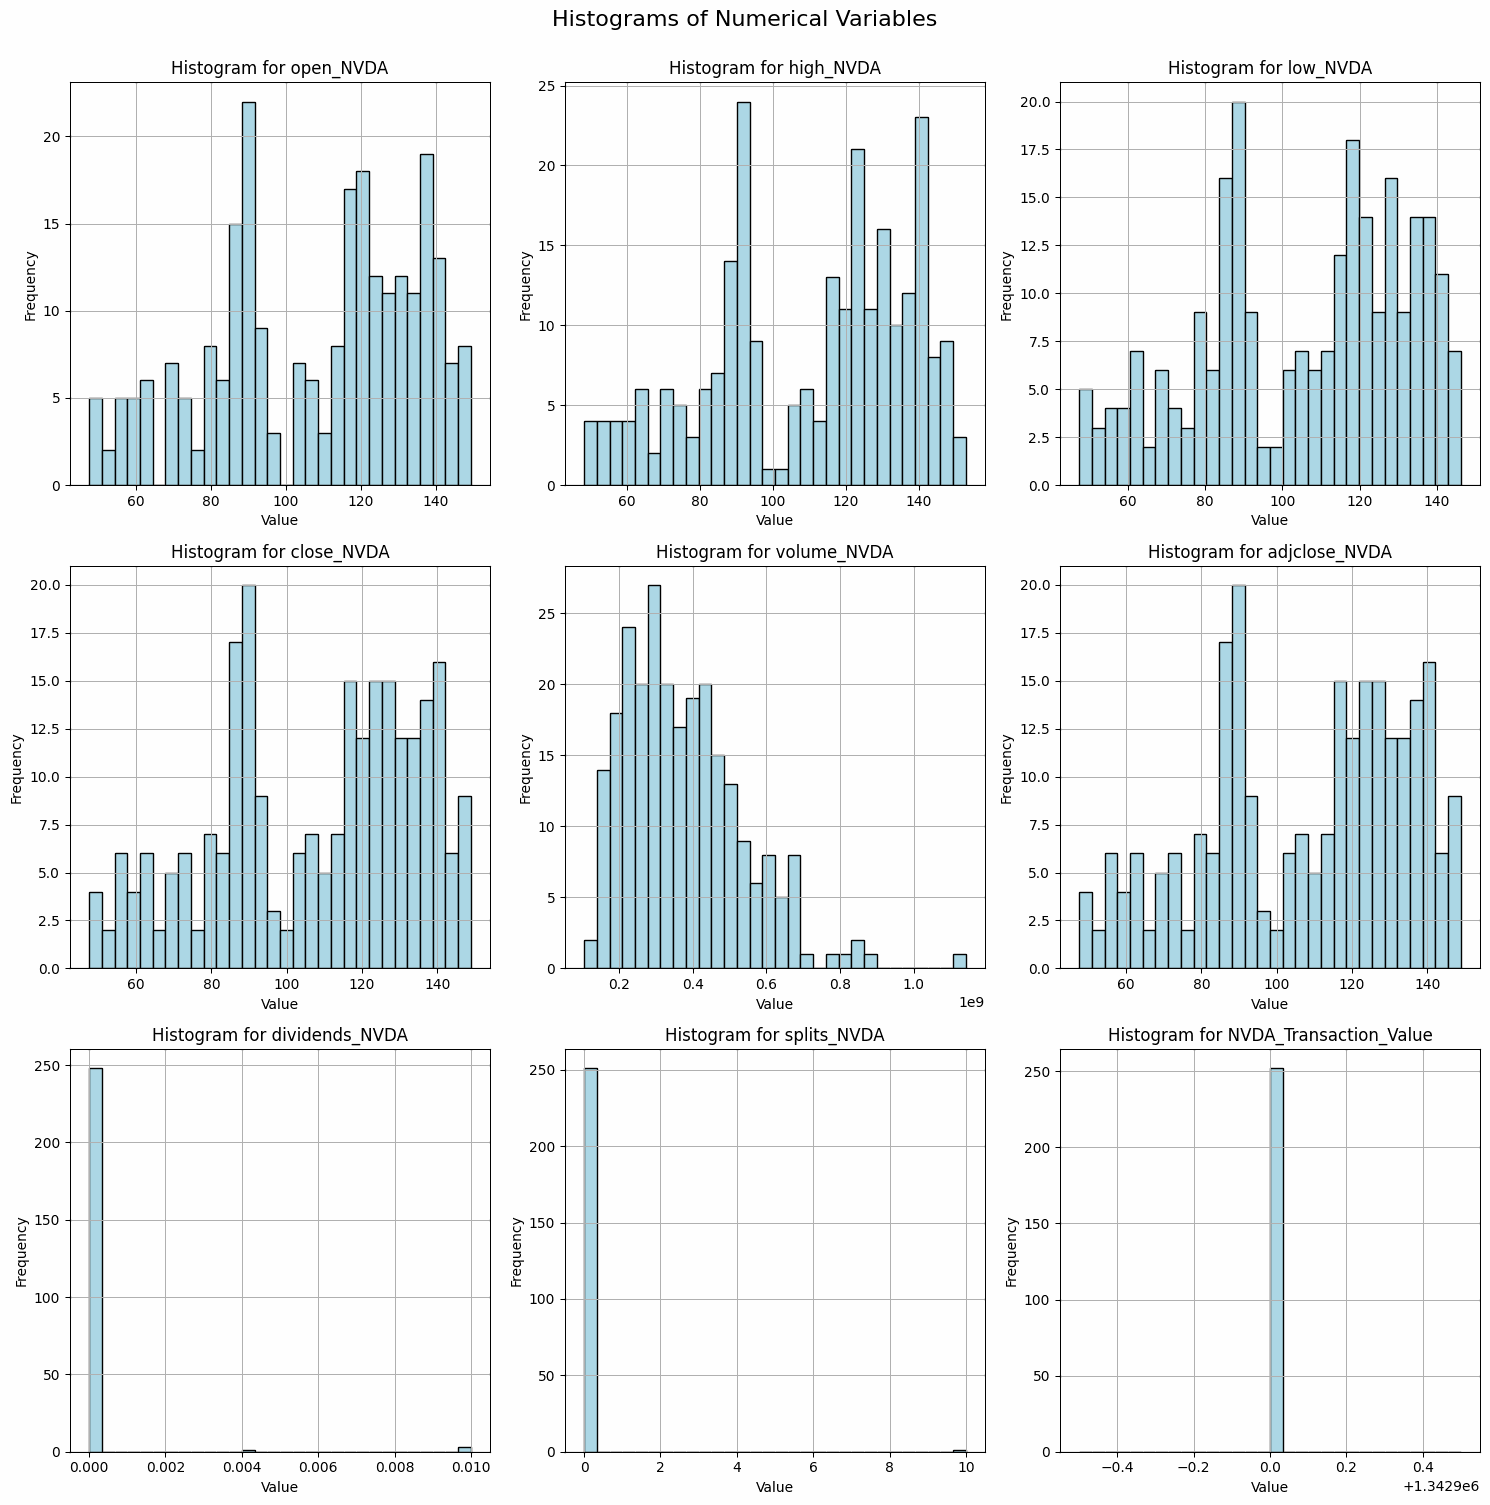

In [38]:
# Create histograms for NVDA
plot_histograms(df_nvda, num_cols_nvda)

 **Analysis of the NVDA Histogram Plots**

The histograms provide a **distribution analysis** of key numerical variables related to **NVIDIA Corporation (NVDA)** stock performance over the observed period. Below is a breakdown of each plot:

---

 **1. Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The **open, high, low, close, and adjusted close** price histograms show **bimodal distributions**, indicating **two distinct price ranges** during the analyzed period.
  - This suggests that **NVDA underwent significant price movement**, possibly due to **market trends, earnings reports, or industry-wide influences**.
  - The **frequencies cluster around two main price levels** (around **$60-$90** and **$120-$150**), indicating **a potential breakout or trend shift**.

- **Implications:**
  - If the **lower price range was at the start of the period** and the **higher range was at the end**, this implies **strong stock growth**.
  - The **high standard deviation** suggests **high volatility**, making NVDA a **high-risk, high-reward investment**.

---

 **2. Trading Volume Distribution**
- **Observations:**
  - The **volume histogram is right-skewed**, meaning **most trading days had moderate volumes**, but there were occasional **large spikes**.
  - This suggests that **certain events triggered exceptionally high trading activity**, likely during **earnings releases, product announcements, or macroeconomic news**.

- **Implications:**
  - Volume spikes often align with **important financial events** or **institutional trading activity**.
  - The skewness indicates **NVDA experienced periods of low liquidity and periods of very high investor interest**.

---

 **3. Dividends Distribution**
- **Observations:**
  - The **dividends histogram is highly concentrated at zero**, with only a **few minor values** appearing.
  - This confirms that **NVDA does not regularly issue dividends**, opting instead for **capital reinvestment and stock price appreciation**.

- **Implications:**
  - **Investors looking for passive income (dividends) may not find NVDA attractive.**
  - **Growth investors**, however, may see this as a **positive sign**, as the company is reinvesting earnings into expansion and innovation.

---

 **4. Stock Splits Distribution**
- **Observations:**
  - The **majority of the dataset shows no splits (value of 0)**.
  - However, there is **one distinct peak at 10**, indicating **a major stock split occurred during the period**.

- **Implications:**
  - The **stock split was likely intended to make NVDA shares more affordable**, increasing market participation.
  - Stock splits generally **do not impact the company’s market capitalization**, but they **increase liquidity and attract retail investors**.

---

 **5. Transaction Value Distribution**
- **Observations:**
  - The **NVDA transaction value histogram shows a single, constant value**.
  - This suggests that **Nancy Pelosi’s investment in NVDA remained unchanged throughout the analyzed period**.

- **Implications:**
  - A **consistent transaction value implies a long-term holding strategy** rather than active trading.
  - If Pelosi’s investments follow **a growth-driven thesis**, this aligns with **NVDA’s strategy of reinvesting profits into AI, semiconductors, and data centers**.

---

 **Key Takeaways**
- **Bimodal price distribution suggests NVDA experienced two major price trends**, likely reflecting a **growth phase or market reaction to industry trends**.
- **Trading volume spikes indicate significant investor interest during key events**.
- **Low or no dividends reinforce NVDA as a high-growth stock, not an income-generating asset**.
- **A major stock split occurred, suggesting efforts to make shares more accessible**.
- **Nancy Pelosi’s investment in NVDA appears stable, suggesting a long-term growth outlook**.



### BOXPLOTS

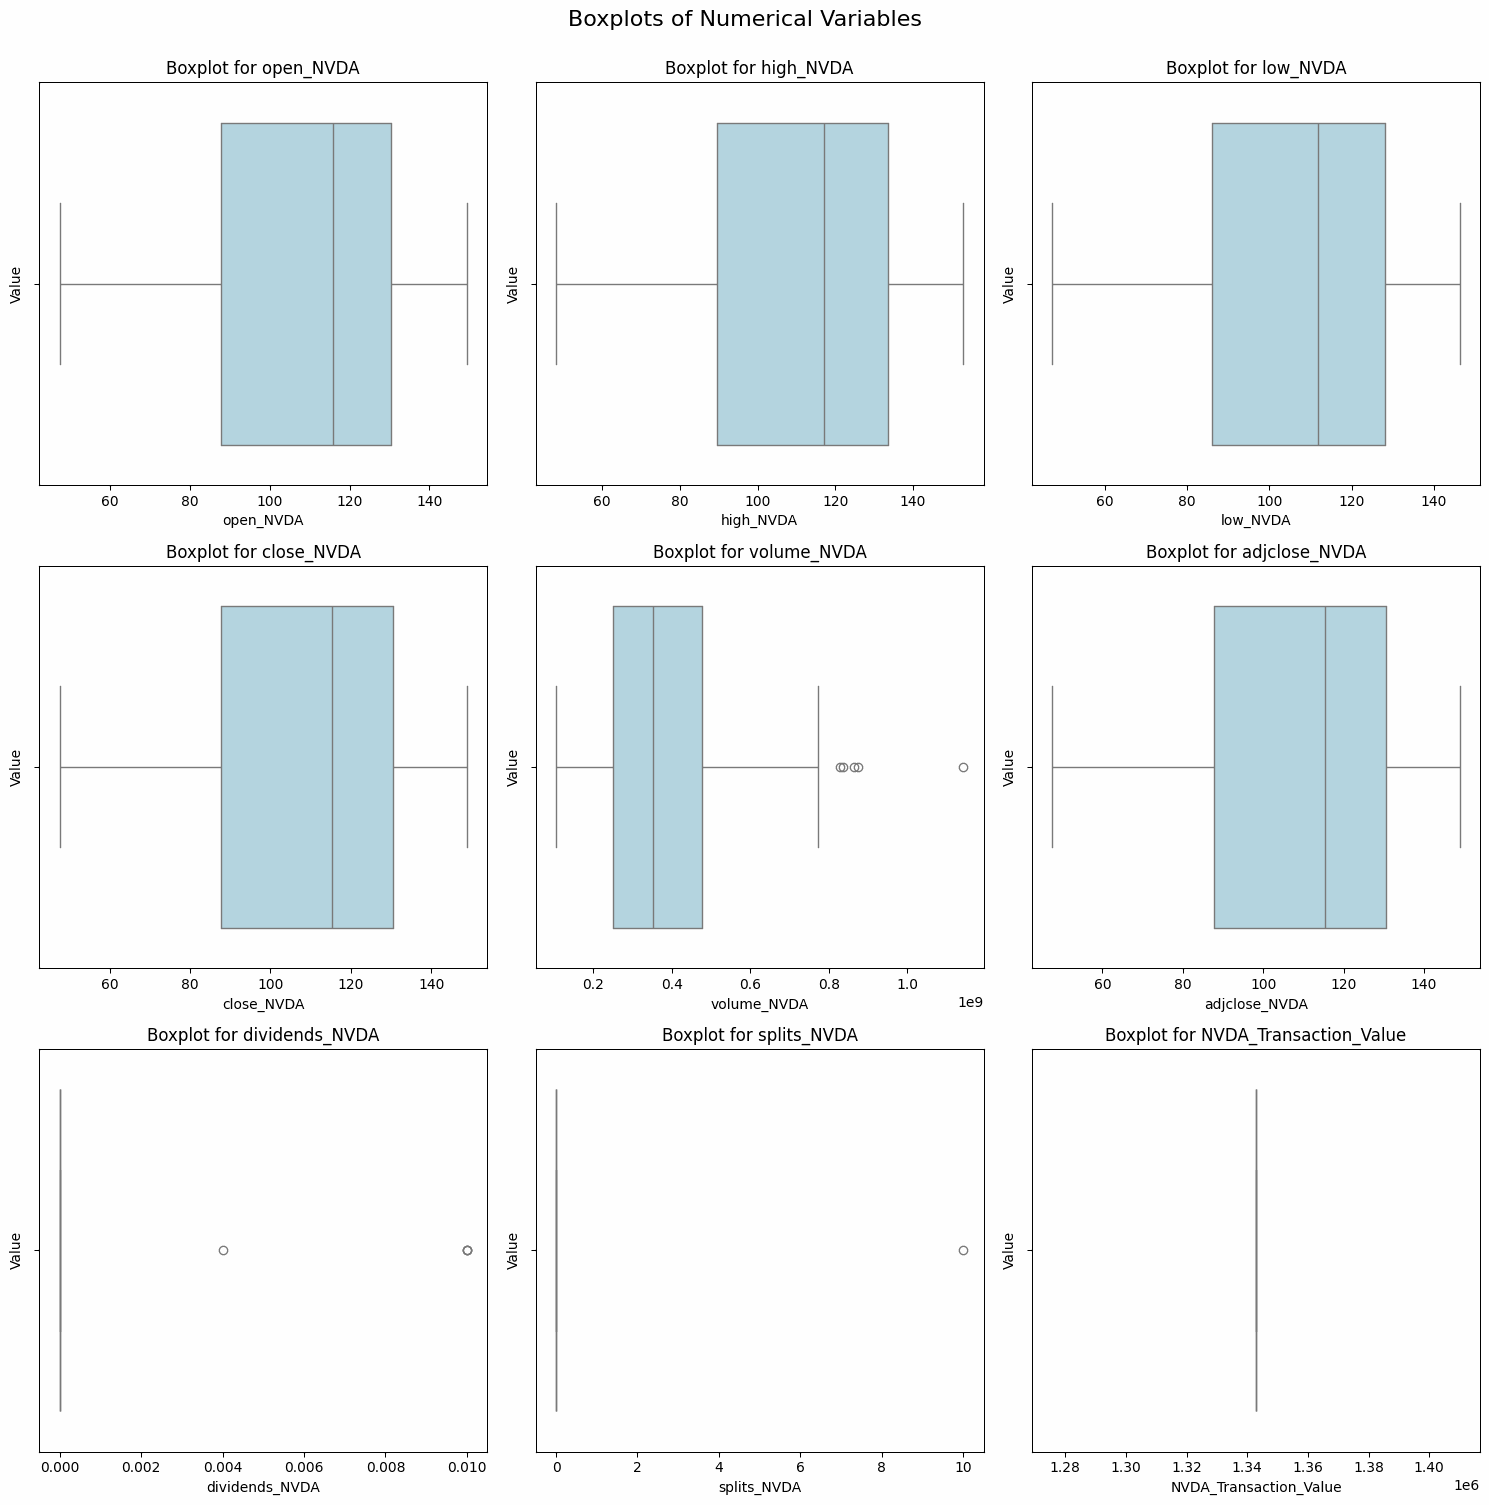

In [39]:
# Create boxplots for NVDA
plot_boxplots(df_nvda, num_cols_nvda)

 **Boxplot Analysis for NVDA Numerical Variables – Business & Investment Insights**  

Boxplots provide **key statistical insights** into **data distribution, price trends, volatility, and outliers** for **NVIDIA Corporation (NVDA)** stock. Below is a detailed analysis with **business implications for investors, traders, and financial decision-makers**.

---

 **1. Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The **open, high, low, close, and adjusted close price boxplots** display **a wide interquartile range (IQR)**, indicating **moderate-to-high volatility**.
  - The **median values** are skewed toward the **upper quartile**, suggesting that **NVDA’s stock price trended upwards over time**.
  - **No extreme price outliers** are present, indicating that **price movements were relatively stable despite volatility**.

- **Business Implications:**
  - **Growth & Momentum:** The upward trend in price distribution suggests that **NVIDIA has experienced consistent growth**, likely fueled by **its dominance in AI, semiconductors, and GPU markets**.
  - **Volatility & Risk Management:** The stock's **price fluctuations indicate opportunities for swing traders** but also require **risk management for long-term investors**.
  - **Investment Sentiment:** The lack of extreme outliers suggests **NVDA’s stock price is less prone to speculative spikes** and is **more driven by fundamental growth**.

---

 **2. Trading Volume Distribution**
- **Observations:**
  - The **boxplot for trading volume** shows a **right-skewed distribution with multiple outliers on the higher end**, meaning **certain days had exceptionally high trading activity**.
  - The **majority of trading volumes** fall within a stable range, with **a few days showing massive volume surges**.

- **Business Implications:**
  - **Earnings & Announcements:** The **outliers in trading volume** suggest that NVDA **saw significant market reactions** on specific days, likely due to **earnings reports, product launches, or macroeconomic news**.
  - **Institutional Trading:** Large volume spikes often indicate **institutional investors (hedge funds, mutual funds) entering or exiting positions**, which can **influence stock price trends**.
  - **Liquidity & Market Efficiency:** The high trading volume suggests **NVDA is a highly liquid stock**, making it an attractive asset for **both institutional and retail investors**.

---

 **3. Dividends Distribution**
- **Observations:**
  - The **dividends boxplot is nearly empty**, with only **a single outlier**, confirming that **NVDA rarely pays dividends**.

- **Business Implications:**
  - **Growth-Oriented Strategy:** NVIDIA **prioritizes reinvesting earnings** into **R&D, acquisitions, and AI infrastructure** rather than distributing profits as dividends.
  - **Investor Expectations:** **Dividend-focused investors (e.g., retirees, income funds) may not favor NVDA**, whereas **growth investors view this as a positive sign**.
  - **Competitive Advantage:** **By reinvesting earnings**, NVDA maintains its **leadership in AI, cloud computing, and autonomous vehicle technology**, solidifying its long-term market position.

---

 **4. Stock Splits Distribution**
- **Observations:**
  - The **boxplot for stock splits is mostly empty**, except for a **single major event at a factor of 10**.

- **Business Implications:**
  - **Accessibility for Retail Investors:** The stock split was **likely aimed at making NVDA shares more affordable**, increasing participation from **retail investors**.
  - **Market Confidence:** Companies **typically split their stock when they anticipate future growth**, signaling that **NVDA expects sustained demand and appreciation**.
  - **Trading Liquidity:** A stock split **increases the number of shares outstanding**, improving **liquidity and reducing bid-ask spreads**, making it **easier to trade**.

---

 **5. Transaction Value Distribution**
- **Observations:**
  - The **boxplot for NVDA transaction value shows a single vertical line**, confirming that **Nancy Pelosi’s investment amount remained constant throughout the period**.

- **Business Implications:**
  - **Long-Term Holding Strategy:** The consistency of the investment suggests that **Pelosi (or her investment team) views NVDA as a long-term growth asset** rather than a short-term trade.
  - **Political & Market Sentiment:** Since **politicians' stock holdings are closely monitored**, consistent NVDA investments may signal **confidence in tech industry growth and government support for AI innovation**.
  - **Investment Strategy Alignment:** **Institutional investors often mirror the trading behavior of policymakers and high-profile investors**, meaning **Pelosi’s stable NVDA holdings could influence broader market sentiment**.

---

 **Key Takeaways & Strategic Investment Insights**
- **NVIDIA’s stock shows strong price appreciation with moderate volatility**, making it a **high-growth investment rather than a stable income-generating stock**.
- **Large trading volume spikes indicate major institutional activity**, suggesting that **earnings, AI advancements, or macroeconomic trends drive NVDA’s market behavior**.
- **A lack of dividends reinforces NVIDIA’s focus on innovation and expansion**, making it ideal for **growth investors rather than income-focused portfolios**.
- **A major stock split signals long-term confidence and broad market accessibility**, increasing liquidity and attracting more investors.
- **Pelosi’s stable transaction value suggests confidence in NVIDIA’s sustained growth**, reinforcing the belief that **AI and semiconductor industries will continue to expand**.

---

 **Final Business Insight**
NVIDIA’s financial characteristics make it an attractive stock for **long-term growth investors, AI sector enthusiasts, and institutional players**. However, due to its **high volatility and reinvestment strategy**, it may not suit **dividend-seeking or conservative investors**. Given the current trends in **AI, cloud computing, and gaming**, NVDA remains **a key player in the future of technology-driven markets**.

## MICROSOFT (MSFT)


In [40]:
# Create numerical columns
num_cols_msft = df_msft.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

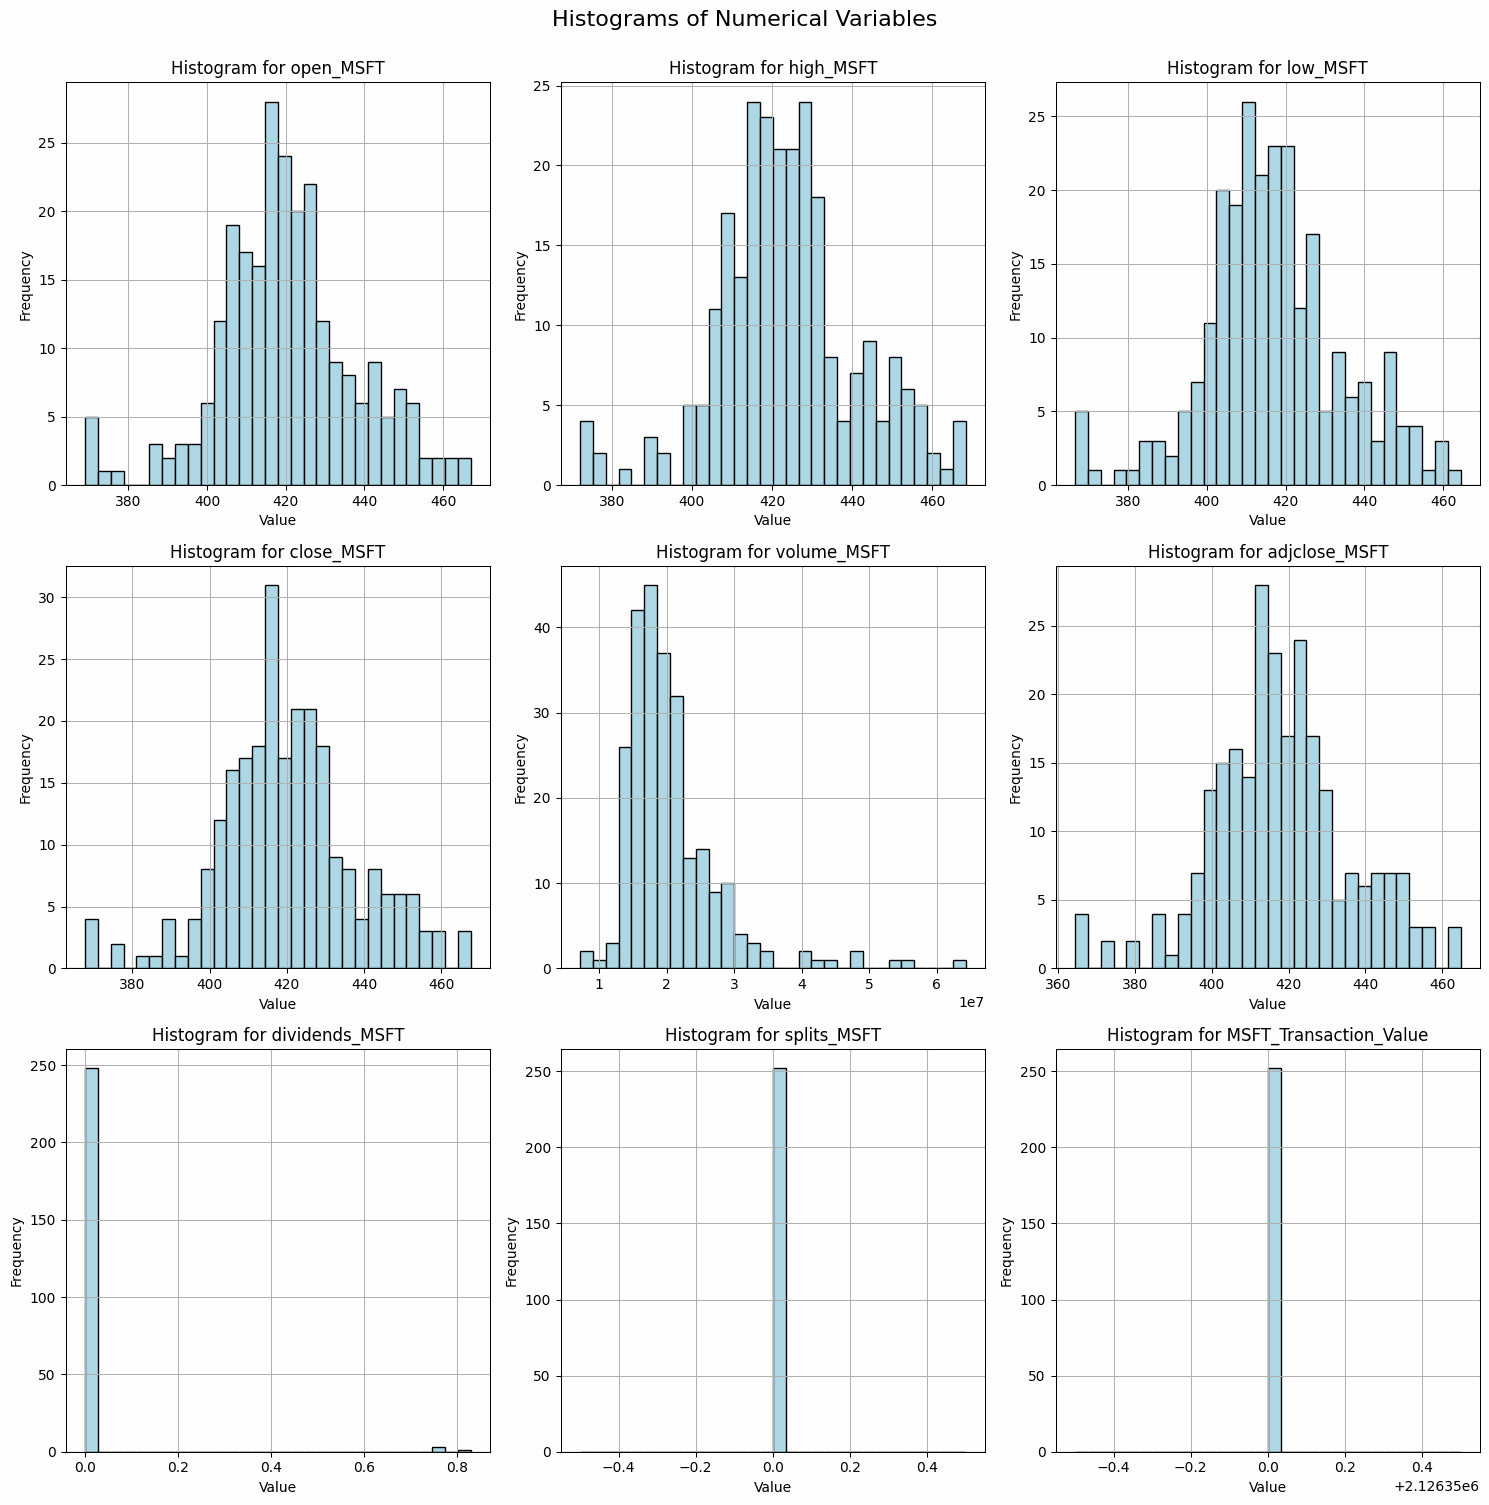

In [41]:
# Create histograms for MSFT
plot_histograms(df_msft, num_cols_msft)



 **1. Histogram Analysis (MSFT)**  
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The stock price distributions are **approximately normal**, with most prices **clustered between $400 and $440**.
  - The **mean price is around $420**, with prices occasionally dipping below $380 or rising above $460.
  - **Higher frequency around $420-$430** suggests a **strong support/resistance level**.

- **Business Implications:**
  - **Steady Price Growth:** The normal distribution suggests that **MSFT is a well-established, mature stock** with **stable demand from institutional investors**.
  - **Predictability for Investors:** The stock exhibits **low-to-moderate volatility**, making it **ideal for long-term investors** rather than short-term traders.
  - **Market Confidence:** The absence of drastic price fluctuations suggests that **investors have strong confidence in Microsoft's future earnings and strategic growth initiatives**.

---

 **Trading Volume Distribution**
- **Observations:**
  - The volume histogram is **right-skewed**, indicating **most days have a stable volume**, but **a few days experienced significantly high trading activity**.
  - **Frequent trading occurs between 1M - 3M shares per day**, but volume can spike above **6M shares on key dates**.

- **Business Implications:**
  - **Institutional Activity:** The spikes in volume could be attributed to **institutional investors making large trades**, which often **drive price movements**.
  - **Market Events & Reactions:** High-volume days may correspond to **earnings reports, major AI-related announcements, or macroeconomic factors**.
  - **Liquidity & Trading Efficiency:** The **high trading volume ensures liquidity**, making MSFT an **efficient stock to trade with low bid-ask spreads**.

---

 **Dividends & Stock Splits**
- **Observations:**
  - **The dividends histogram shows a single, small peak (~$0.80 per share),** confirming **Microsoft's stable dividend payout strategy**.
  - **The stock splits histogram is empty**, indicating **no stock splits occurred during this period**.

- **Business Implications:**
  - **Dividend Stability:** Microsoft's **consistent dividend payout** makes it attractive for **long-term income investors** while maintaining **strong reinvestment in growth sectors like AI and cloud computing**.
  - **No Stock Splits:** By **not splitting shares**, Microsoft **maintains a premium price per share**, which aligns with its **institutional investor-focused approach**.
  - **Future Considerations:** If Microsoft's **stock price continues to climb**, a stock split **may be considered in the future** to **increase accessibility for retail investors**.


### BOXPLOTS

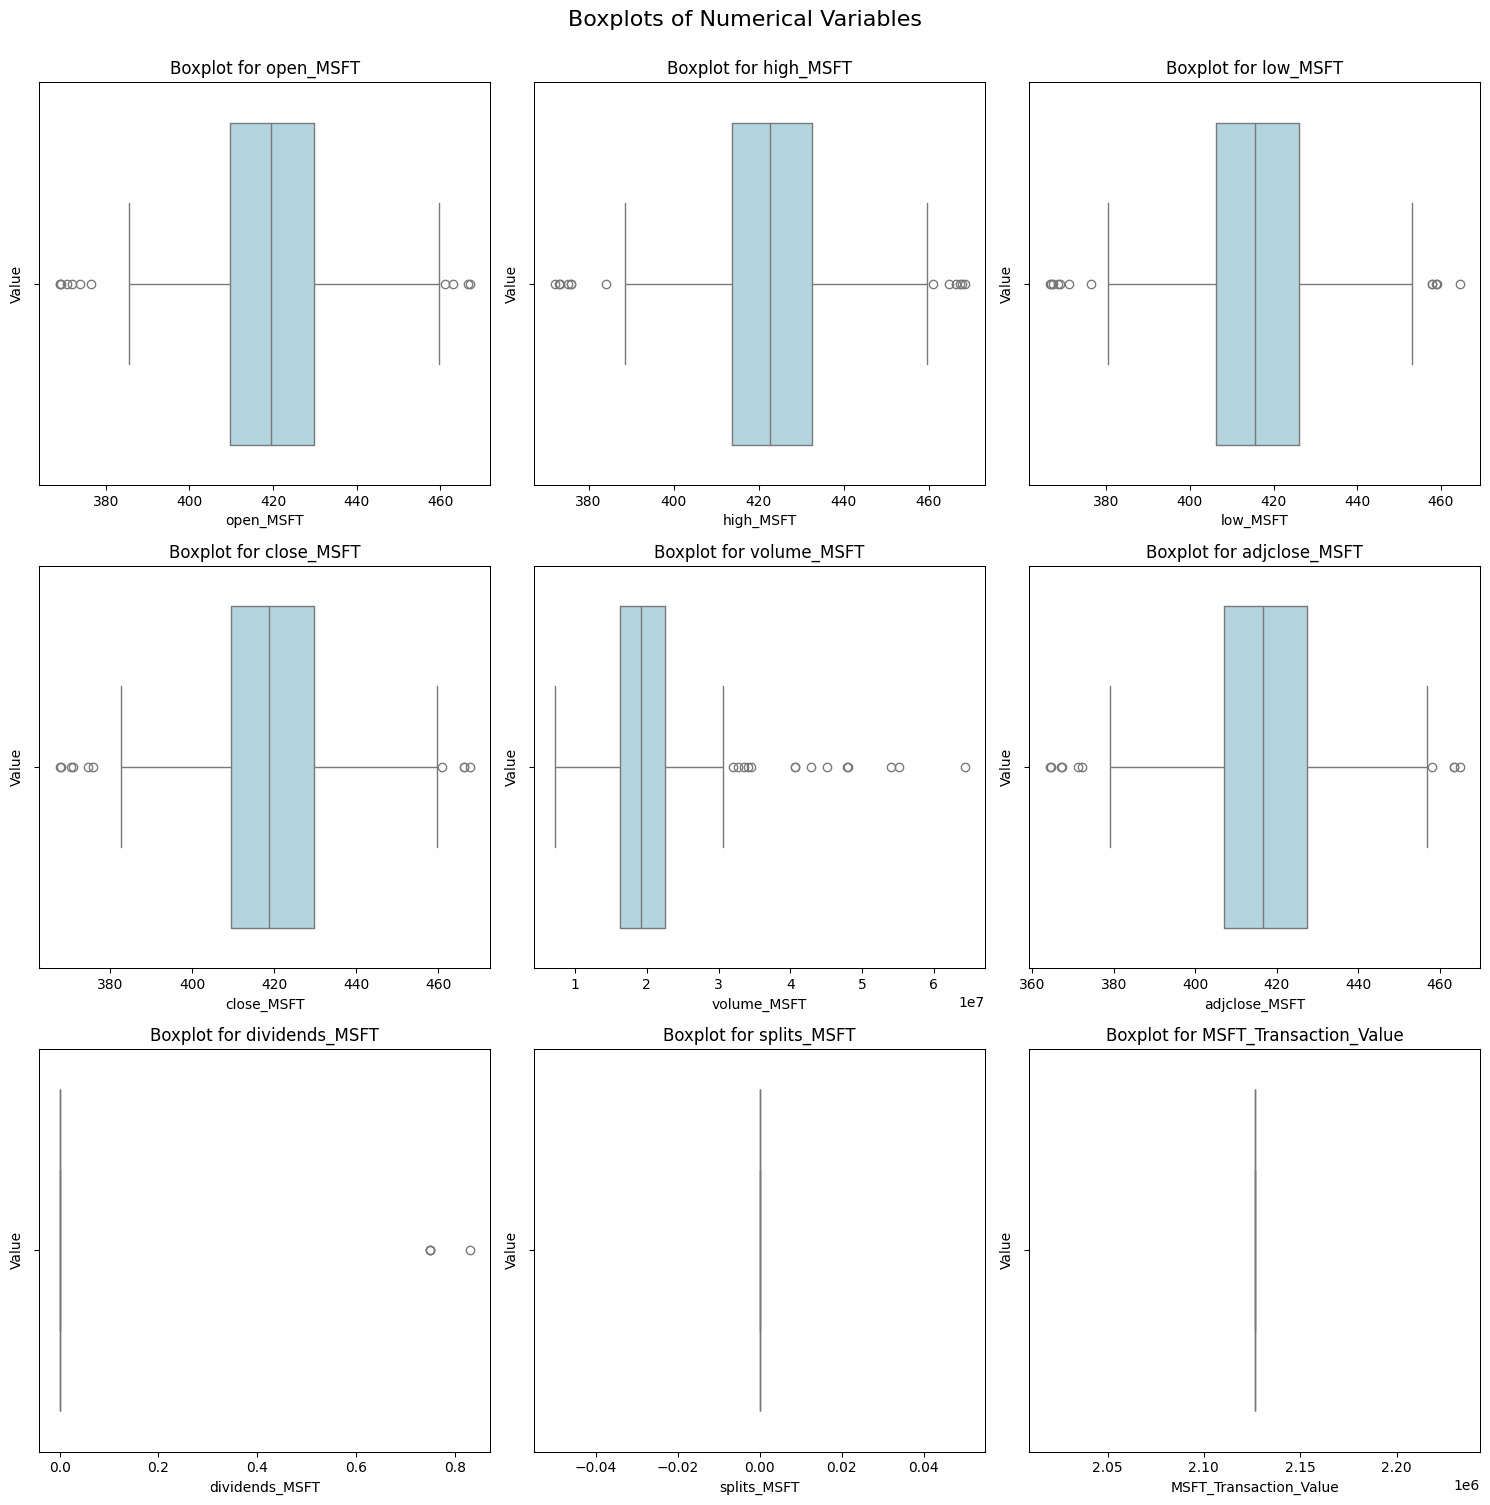

In [42]:
# Create boxplots for MSFT
plot_boxplots(df_msft, num_cols_msft)

 **2. Boxplot Analysis (MSFT)**
Boxplots help identify **outliers, volatility, and potential risk factors**.

 **Stock Price Variability**
- **Observations:**
  - **The IQR for open, high, low, close, and adjusted close prices is relatively narrow**, suggesting **limited price fluctuations**.
  - **There are a few mild outliers**, but they do not indicate extreme volatility.

- **Business Implications:**
  - **Strong Stability:** The **tight price range** shows that **Microsoft maintains price consistency**, reducing risk for **long-term investors**.
  - **Lower Trading Risks:** **Fewer extreme outliers suggest Microsoft is less prone to sudden speculative movements**, making it **a safe-haven stock during market uncertainty**.
  - **Support for Large-Scale Investment:** Microsoft’s **predictable stock behavior makes it appealing for pension funds, ETFs, and large institutional investors**.

---

 **Trading Volume Boxplot**
- **Observations:**
  - **The volume boxplot has significant upper outliers**, indicating that **certain days had unusually high trading activity**.

- **Business Implications:**
  - **Market Events Drive Trading Activity:** High-volume days could be linked to **quarterly earnings, product launches (e.g., AI innovations, Azure growth), or global economic news**.
  - **Increased Investor Attention:** When trading volume surges, **price momentum can shift**, offering **trading opportunities for short-term investors**.
  - **Stock Liquidity Benefits:** Even on **high-volume days, liquidity remains strong**, ensuring **MSFT remains a reliable, easy-to-trade stock**.

---

 **Dividends & Splits Boxplots**
- **Observations:**
  - **Dividends show only slight variation**, confirming a **stable payout policy**.
  - **No stock splits are present**, reinforcing **Microsoft’s premium stock price strategy**.

- **Business Implications:**
  - **Reliable Dividend Growth:** Microsoft's **commitment to shareholder returns** makes it an **attractive stock for income-focused investors**.
  - **Long-Term Capital Appreciation Focus:** By **not splitting the stock**, Microsoft signals that **it prioritizes long-term valuation growth over retail investor accessibility**.

---

 **Key Takeaways & Strategic Investment Insights**
- **Microsoft exhibits low volatility, strong liquidity, and consistent price stability**, making it a **blue-chip stock for institutional and long-term investors**.
- **Trading volume spikes align with key events**, providing **short-term trading opportunities** while reinforcing **long-term investor confidence**.
- **Consistent dividend payments appeal to income-focused investors**, while **reinvestment in AI and cloud technologies positions MSFT for continued growth**.
- **No stock splits indicate Microsoft favors maintaining a high stock price**, which **reduces speculation and attracts long-term institutional investors**.
- **Nancy Pelosi’s stable MSFT transaction value** suggests **confidence in Microsoft’s future dominance in AI, enterprise software, and cloud computing**.

---

 **Final Business Insight**
Microsoft remains a **highly attractive stock for long-term investors**, balancing **steady dividend payouts with strong reinvestment in future technologies**. **Its liquidity, predictable price trends, and institutional appeal make it a cornerstone stock for diversified portfolios.**



## APPLE (AAPL)

In [43]:
# Create numerical columns
num_cols_aapl = df_aapl.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

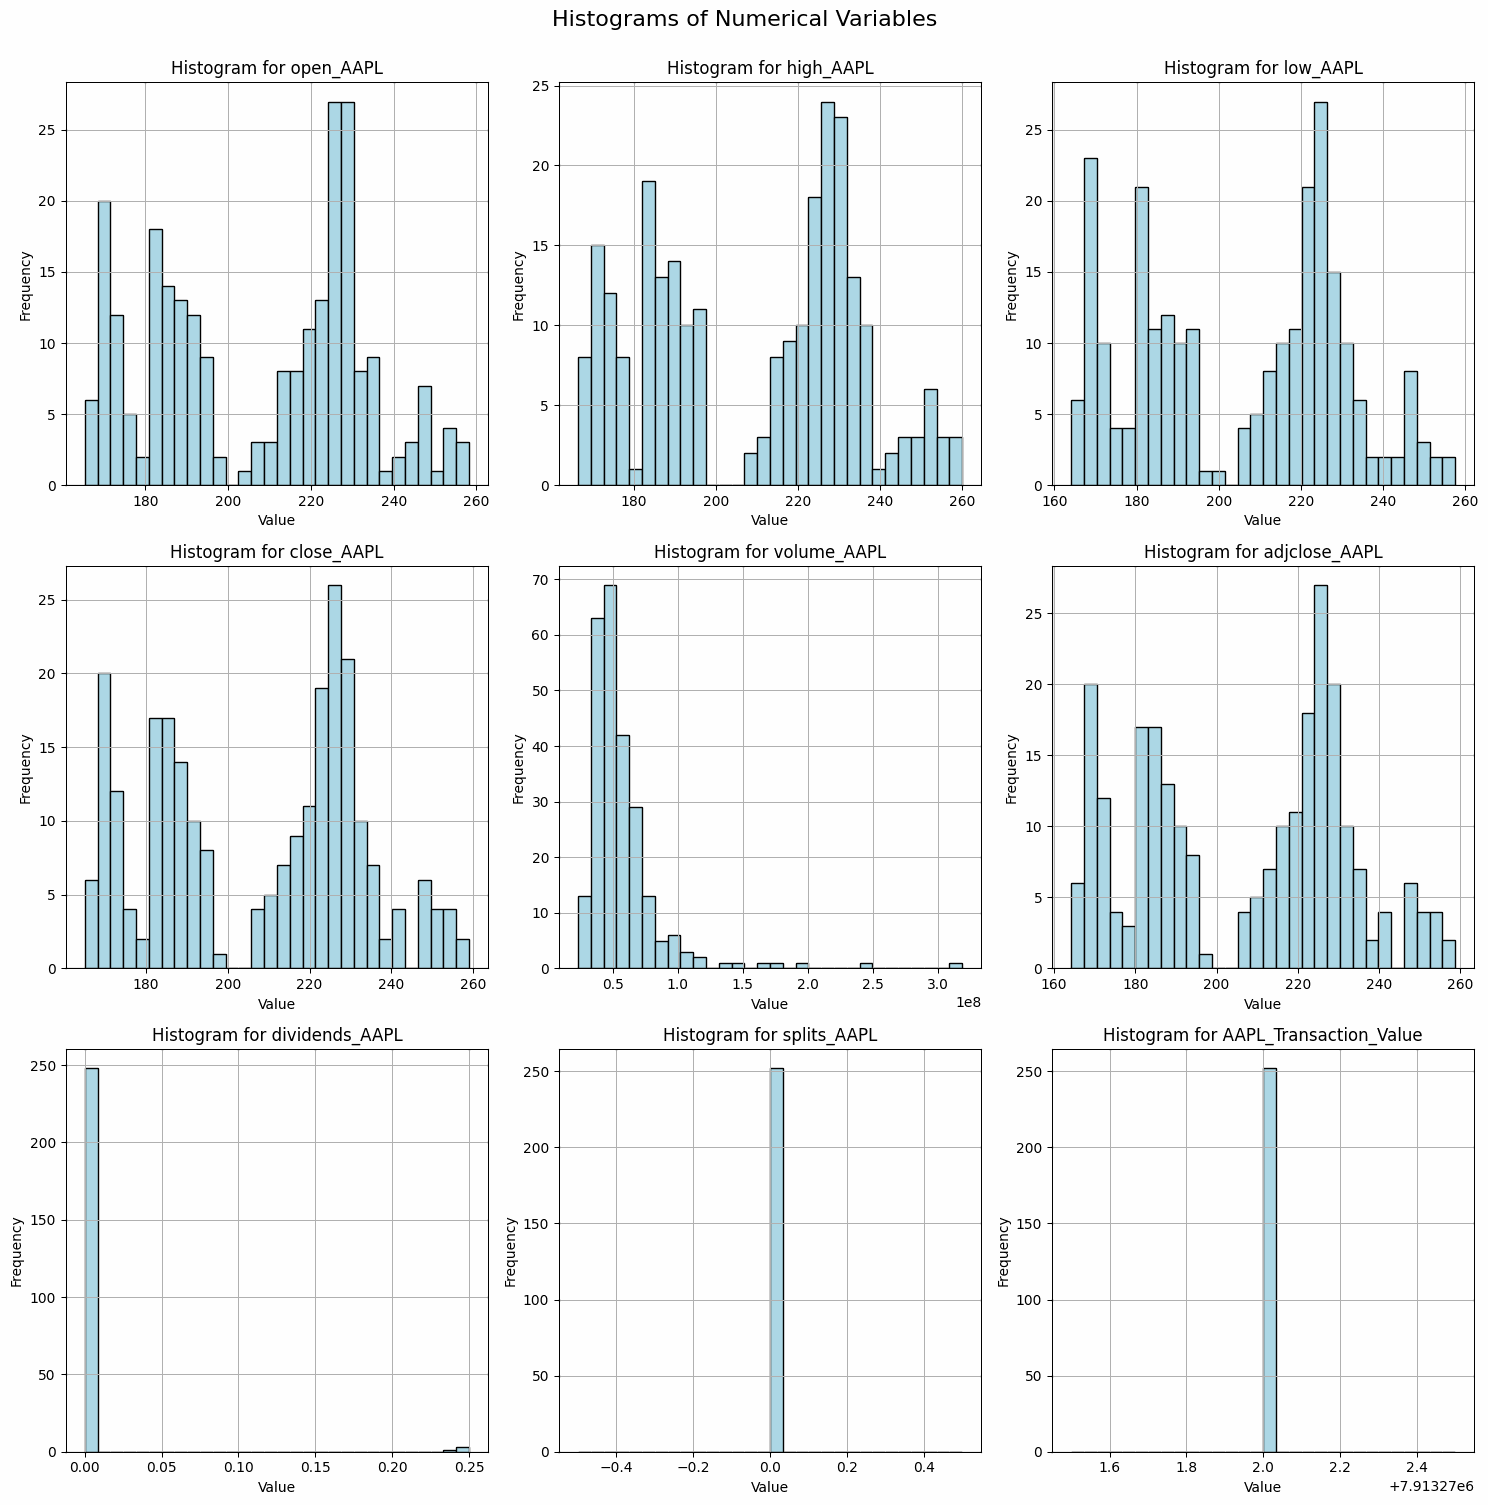

In [44]:
# Create histograms for AAPL
plot_histograms(df_aapl, num_cols_aapl)


 **1. Histogram Analysis (AAPL)**
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The **price distributions are bimodal**, meaning **AAPL experienced two distinct price ranges** over the analyzed period.
  - Most stock prices **cluster between $180 and $230**, with another peak forming near **$240-$260**.
  - The **distribution suggests a significant price increase over time**, indicating **strong momentum**.

- **Business Implications:**
  - **Upward Trend & Investor Confidence:** The bimodal pattern suggests **Apple's stock saw a breakout**, likely due to **earnings reports, product launches (iPhone, Mac, AI features), or economic trends**.
  - **Attractive for Growth Investors:** The **shift in price levels indicates consistent long-term growth**, making AAPL a **solid choice for growth-focused investors**.
  - **Strategic Entry Points for Traders:** The **two price clusters** provide potential **support and resistance levels**, guiding short-term traders on **when to enter or exit** positions.

---

 **Trading Volume Distribution**
- **Observations:**
  - The **volume histogram is right-skewed**, meaning **most days had moderate trading volume**, but **a few days experienced extreme spikes**.
  - Trading volume is most frequently **below 50 million shares per day**, but spikes **above 100 million shares** indicate **significant market activity**.

- **Business Implications:**
  - **Institutional Buying & Selling:** Volume spikes likely correspond with **institutional investors making large trades**, which could influence price momentum.
  - **Market Sensitivity:** The **spikes in trading volume** align with major market events, such as **earnings reports or key product releases**.
  - **Liquidity & Market Efficiency:** Apple’s **high trading volume ensures strong liquidity**, meaning investors can buy and sell shares easily without major price impact.

---

 **Dividends & Stock Splits**
- **Observations:**
  - The **dividends histogram shows a small peak (~$0.20 per share),** confirming that **Apple consistently pays dividends**.
  - **The stock splits histogram is empty**, indicating **no stock splits occurred during this period**.

- **Business Implications:**
  - **Dividend Stability:** Apple’s **consistent but small dividend payouts** make it **attractive for long-term investors who seek a mix of growth and passive income**.
  - **Growth-Oriented Strategy:** Despite paying dividends, Apple **continues to reinvest in research & development (R&D), AI, and new product innovation**, ensuring future expansion.
  - **Potential Future Stock Split:** If Apple’s **stock price continues rising toward $300+, a stock split may become more likely to improve retail investor accessibility**.


### BOXPLOTS

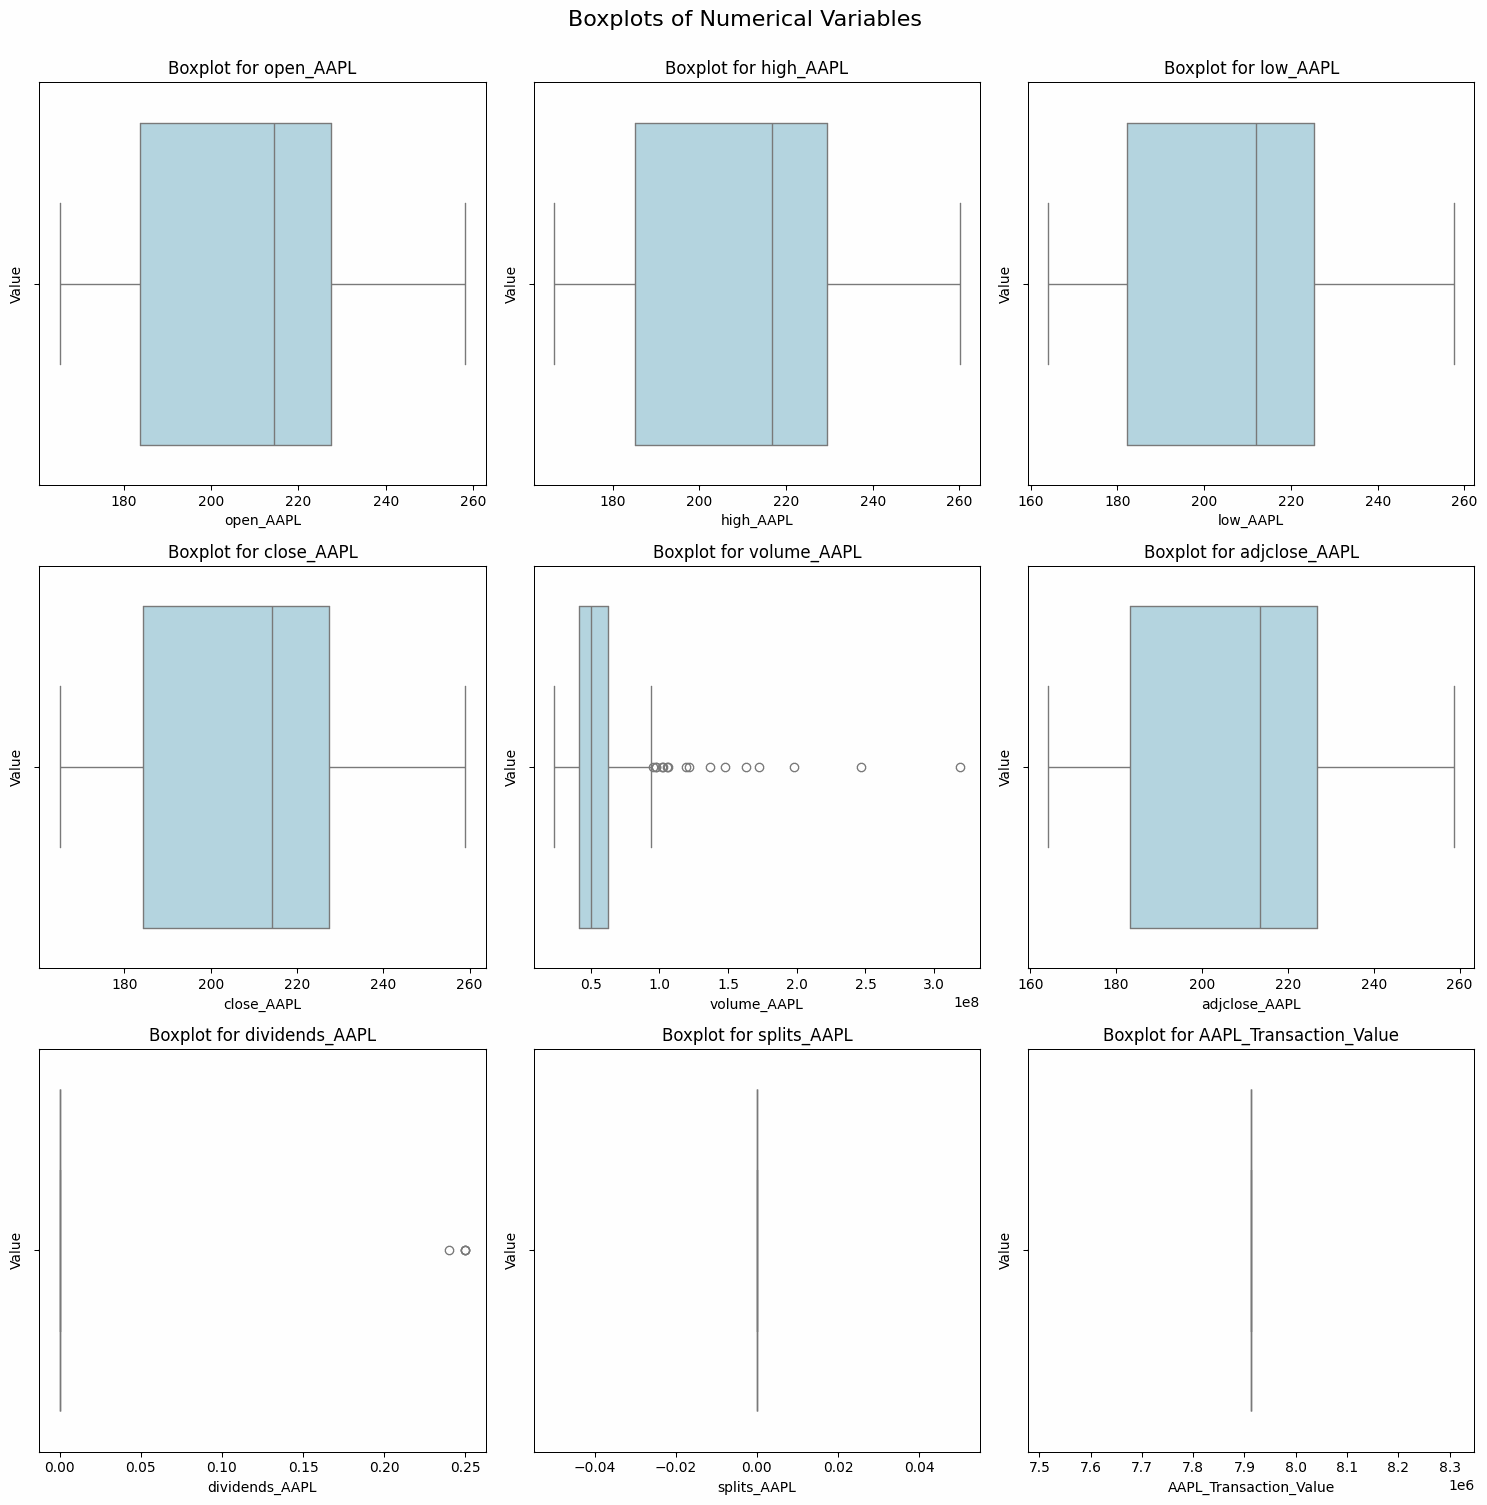

In [45]:
# Create boxplots for AAPL
plot_boxplots(df_aapl, num_cols_aapl)

 **Boxplot Analysis for Apple Inc. (AAPL) – Business & Investment Insights**


The provided **boxplots** for **Apple Inc. (AAPL)** stock display the distribution of key numerical variables over the observed period. Below is a breakdown of the findings, including **business implications** for investors, traders, and financial decision-makers.


---


 **1. Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
- The **open, high, low, close, and adjusted close price boxplots** show a **narrow range of price fluctuations**, with **median values clustered between $200 and $220**.
- The **interquartile range (IQR)** is compact, suggesting **stable price movement** with **no significant outliers**.
- There is **very little volatility** outside of the IQR, which could indicate that **Apple’s stock price is relatively stable** and predictable.


- **Business Implications:**
- **Stability & Low Volatility:** AAPL’s price stability suggests it is **less susceptible to market shocks**, making it a **safe investment choice for conservative and long-term investors**.
- **Predictable Growth:** The lack of extreme price variations indicates **Apple’s consistent performance** in the market.
- **Attractive for Institutional Investors:** The narrow range of price fluctuations and **consistent returns** make Apple an **appealing choice for institutional investors** seeking **steady growth**.


---


 **2. Trading Volume Distribution**
- **Observations:**
- The **boxplot for trading volume** shows a **right-skewed distribution** with several **outliers**, particularly on the **higher end**, indicating days with **exceptionally high trading volumes**.
- The **IQR is relatively wide**, suggesting **moderate variability in trading activity** across the period.
- **Business Implications:**
- **Volume Spikes & Major Events:** The **outliers in volume** likely correspond with **significant events** such as **earnings reports, product launches, or broader market trends**.
- **Investor Sentiment:** **High-volume days** can indicate **increased institutional or retail interest**, which could drive **short-term price movement**.
- **Liquidity Considerations:** Apple’s **liquid stock** with high trading volume ensures **efficient price discovery** and **market depth**, offering **opportunities for both short-term traders and long-term investors**.


---


 **3. Dividends Distribution**
- **Observations:**
- The **dividends boxplot** shows a **cluster of values near 0**, with **a few outliers** just above 0.05, indicating **occasional dividend payments**.


- **Business Implications:**
- **Steady Dividend Payouts:** Apple’s **dividends are relatively low but stable**, indicating **a balanced strategy between growth and returning value to shareholders**.
- **Income Investors:** While **not a high-yield stock**, Apple’s **consistent dividends** provide some **income for dividend-seeking investors**.
- **Growth-Focused Strategy:** The relatively small dividend payout suggests that **Apple continues to reinvest its earnings in innovation and market expansion**, which aligns with its **growth-oriented strategy**.


---


 **4. Stock Splits Distribution**
- **Observations:**
- The **splits boxplot** is **empty**, confirming that **Apple did not conduct any stock splits** during the observed period.


- **Business Implications:**
- **Stock Price Retention Strategy:** Apple’s **stock price remains high**, which may attract **institutional investors** who prefer **premium-priced stocks**.
- **Limited Need for Stock Splits:** Apple has **grown significantly without needing to split shares**, suggesting that **investor demand and stock performance** are robust enough to sustain high share prices.
- **Market Liquidity:** **Not splitting shares** may indicate that Apple **focuses on long-term investor stability** rather than increasing liquidity through stock splits.


---


 **5. Transaction Value Distribution**
- **Observations:**
- The **boxplot for transaction value** shows a **single vertical line**, indicating that **Nancy Pelosi’s investment remained constant throughout the observed period**.


- **Business Implications:**
- **Stable Investment Strategy:** The constancy of the **transaction value** indicates **Pelosi's long-term hold strategy** rather than short-term trading.
- **Investor Confidence:** The **steady investment in AAPL** suggests **confidence in Apple’s growth prospects**, which could signal to other **institutional and retail investors** that Apple remains a **stable and trustworthy stock**.
- **Potential Market Influence:** High-profile investors like **Pelosi could influence market sentiment**, potentially driving **further confidence** in Apple.


---


 **Key Takeaways & Strategic Investment Insights**
- **Apple's stock shows stable and predictable price movements**, making it **ideal for long-term, conservative investors**.
- **Volume spikes indicate market reaction** to key **events such as earnings reports or product launches**, providing **opportunities for active traders**.
- **Consistent, moderate dividends** make AAPL attractive for **income-focused investors** while still maintaining a **growth-oriented strategy**.
- The **lack of stock splits** indicates Apple’s **focus on institutional investors**, maintaining **high stock value and liquidity**.
- **Pelosi’s constant transaction value** indicates a **long-term investment outlook**, reinforcing **confidence in Apple’s future performance**.


---


 **Final Business Insight**
Apple remains one of the **most stable and reliable investment options** for both **growth and income investors**. Its **predictable growth, low volatility, and steady dividends** position it as a **blue-chip stock** suitable for **long-term holding**. Despite the absence of stock splits, **Apple’s liquidity and consistent performance** make it **highly attractive** to institutional investors.





## ALPHABET (GOOGL)

In [46]:
# Create numerical columns
num_cols_googl = df_googl.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

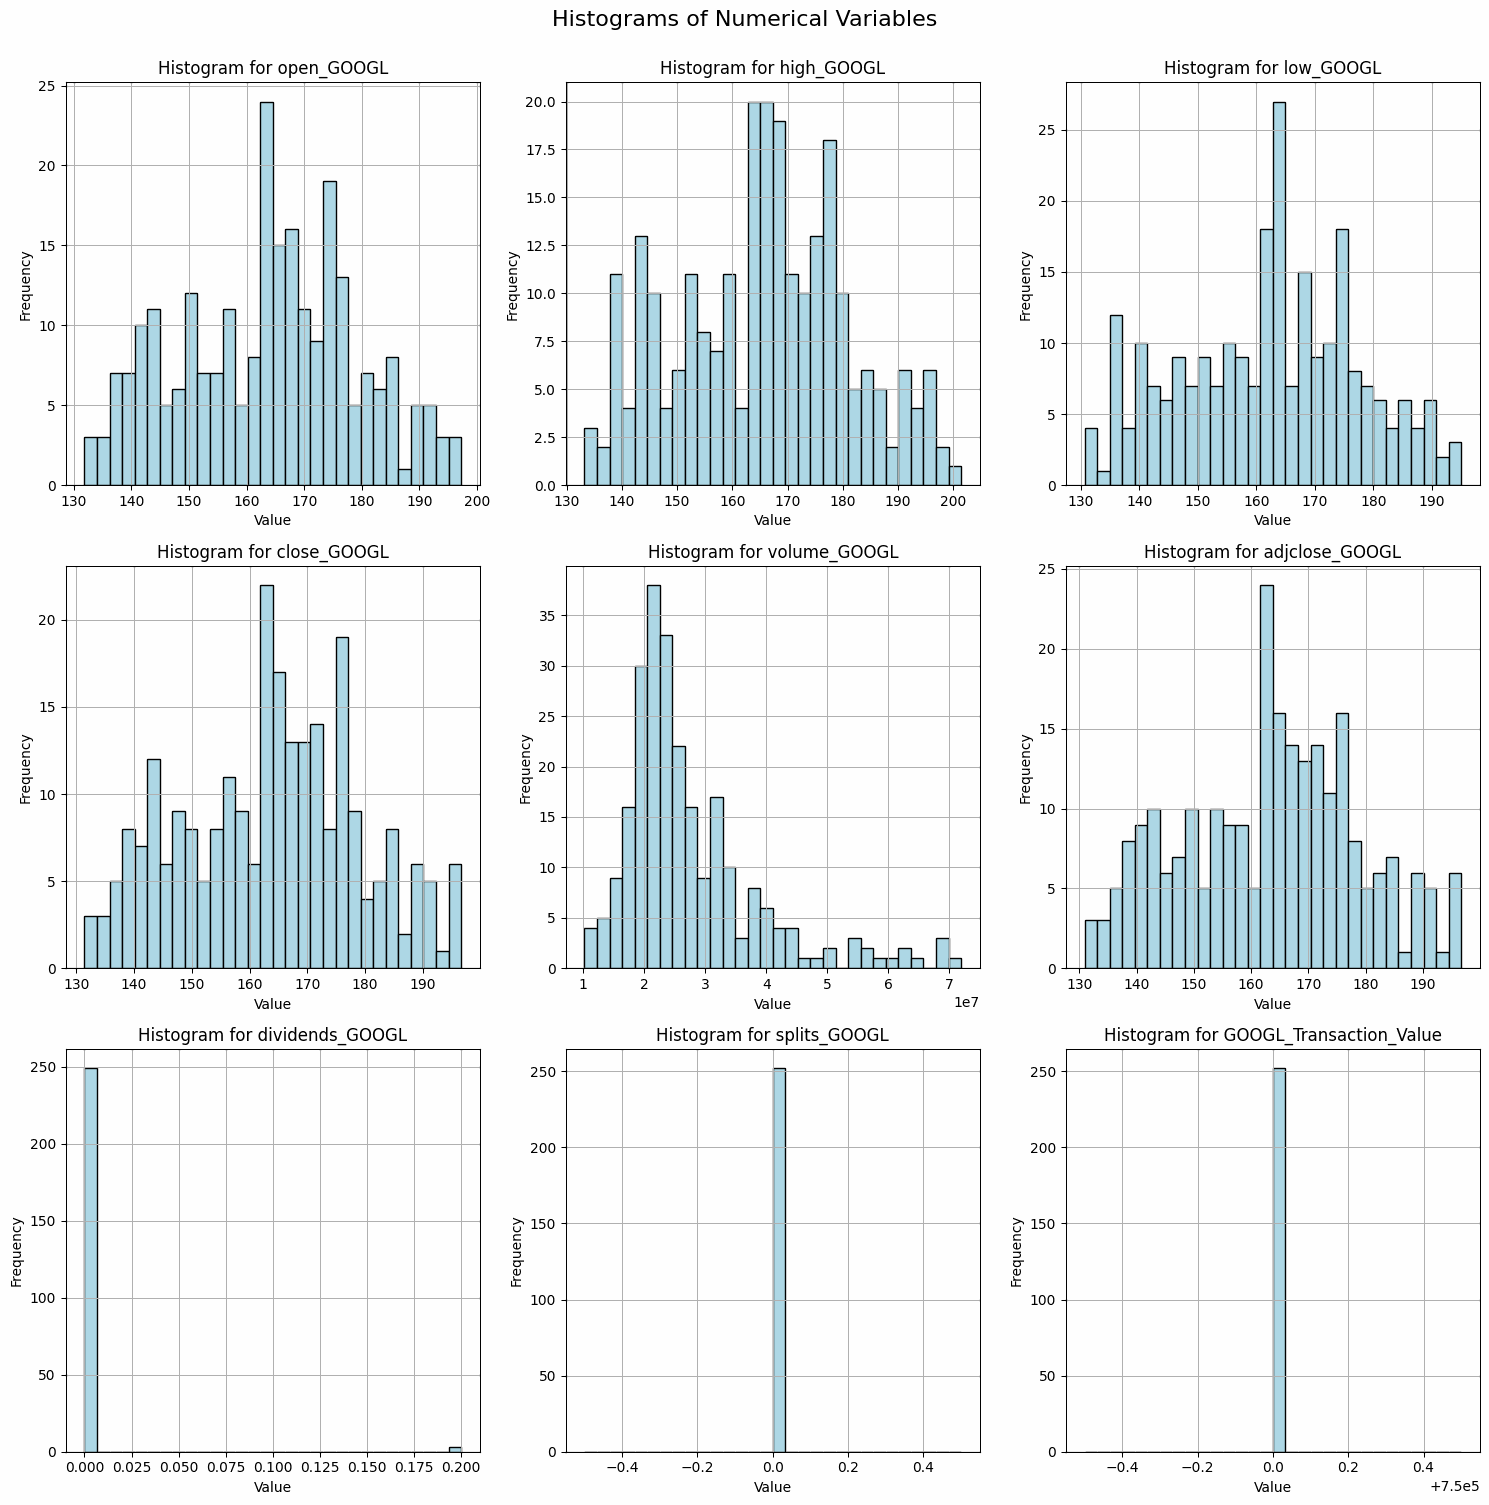

In [47]:
# Create histograms for GOOGL
plot_histograms(df_googl, num_cols_googl)


 **1. Histogram Analysis (GOOGL)**
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The stock price distributions are **approximately normal but slightly right-skewed**, suggesting **a gradual upward trend**.
  - The **most frequent price range is between $150 and $175**, with **occasional movements above $190**.
  - There is **no major price clustering**, meaning **GOOGL stock has been gradually increasing rather than experiencing sudden jumps**.

- **Business Implications:**
  - **Sustained Growth Trend:** The **right-skewed price distribution** suggests **Alphabet is experiencing steady price growth**, likely driven by **strong earnings, AI investments (Google Bard, DeepMind), and cloud expansion (Google Cloud)**.
  - **Long-Term Stability:** The **absence of extreme price fluctuations** makes GOOGL **a solid long-term investment** rather than a speculative stock.
  - **Entry & Exit Points for Investors:** **The price range of $150-$175 represents a key support zone**, making it an **ideal entry point for new investors**.

---

 **Trading Volume Distribution**
- **Observations:**
  - The **volume histogram is right-skewed**, meaning that **most trading days had moderate volume**, but **a few days had significant spikes**.
  - **Most frequent trading volume is between 1M - 3M shares per day**, but spikes **above 7M shares** indicate **high-activity periods**.

- **Business Implications:**
  - **Institutional Interest:** The volume spikes are likely linked to **institutional investors making large trades**, indicating **GOOGL remains an attractive blue-chip stock for funds and ETFs**.
  - **Market Sensitivity to Events:** High-volume days could be triggered by **earnings reports, AI breakthroughs, regulatory news (antitrust lawsuits, government policies), or macroeconomic shifts**.
  - **High Liquidity & Market Efficiency:** **Alphabet's high trading volume ensures liquidity**, making it **an attractive stock for both long-term investors and short-term traders**.

---

 **Dividends & Stock Splits**
- **Observations:**
  - The **dividends histogram shows a small peak (~$0.20 per share),** confirming that **Alphabet has started issuing dividends but at a minimal level**.
  - **The stock splits histogram is empty**, indicating **no stock splits occurred during this period**.

- **Business Implications:**
  - **New Dividend Strategy:** Alphabet’s **introduction of dividends signals confidence in its financial health** and appeals to **income-focused investors**.
  - **Reinvestment in AI & Cloud:** Despite the small dividend, Alphabet **continues to reinvest in AI, cloud computing, and autonomous vehicle research (Waymo)**, reinforcing **its long-term growth strategy**.
  - **Potential Future Stock Split:** If Alphabet’s **stock price continues rising toward $200+, a stock split may be considered to enhance accessibility for retail investors**.


### BOXPLOTS

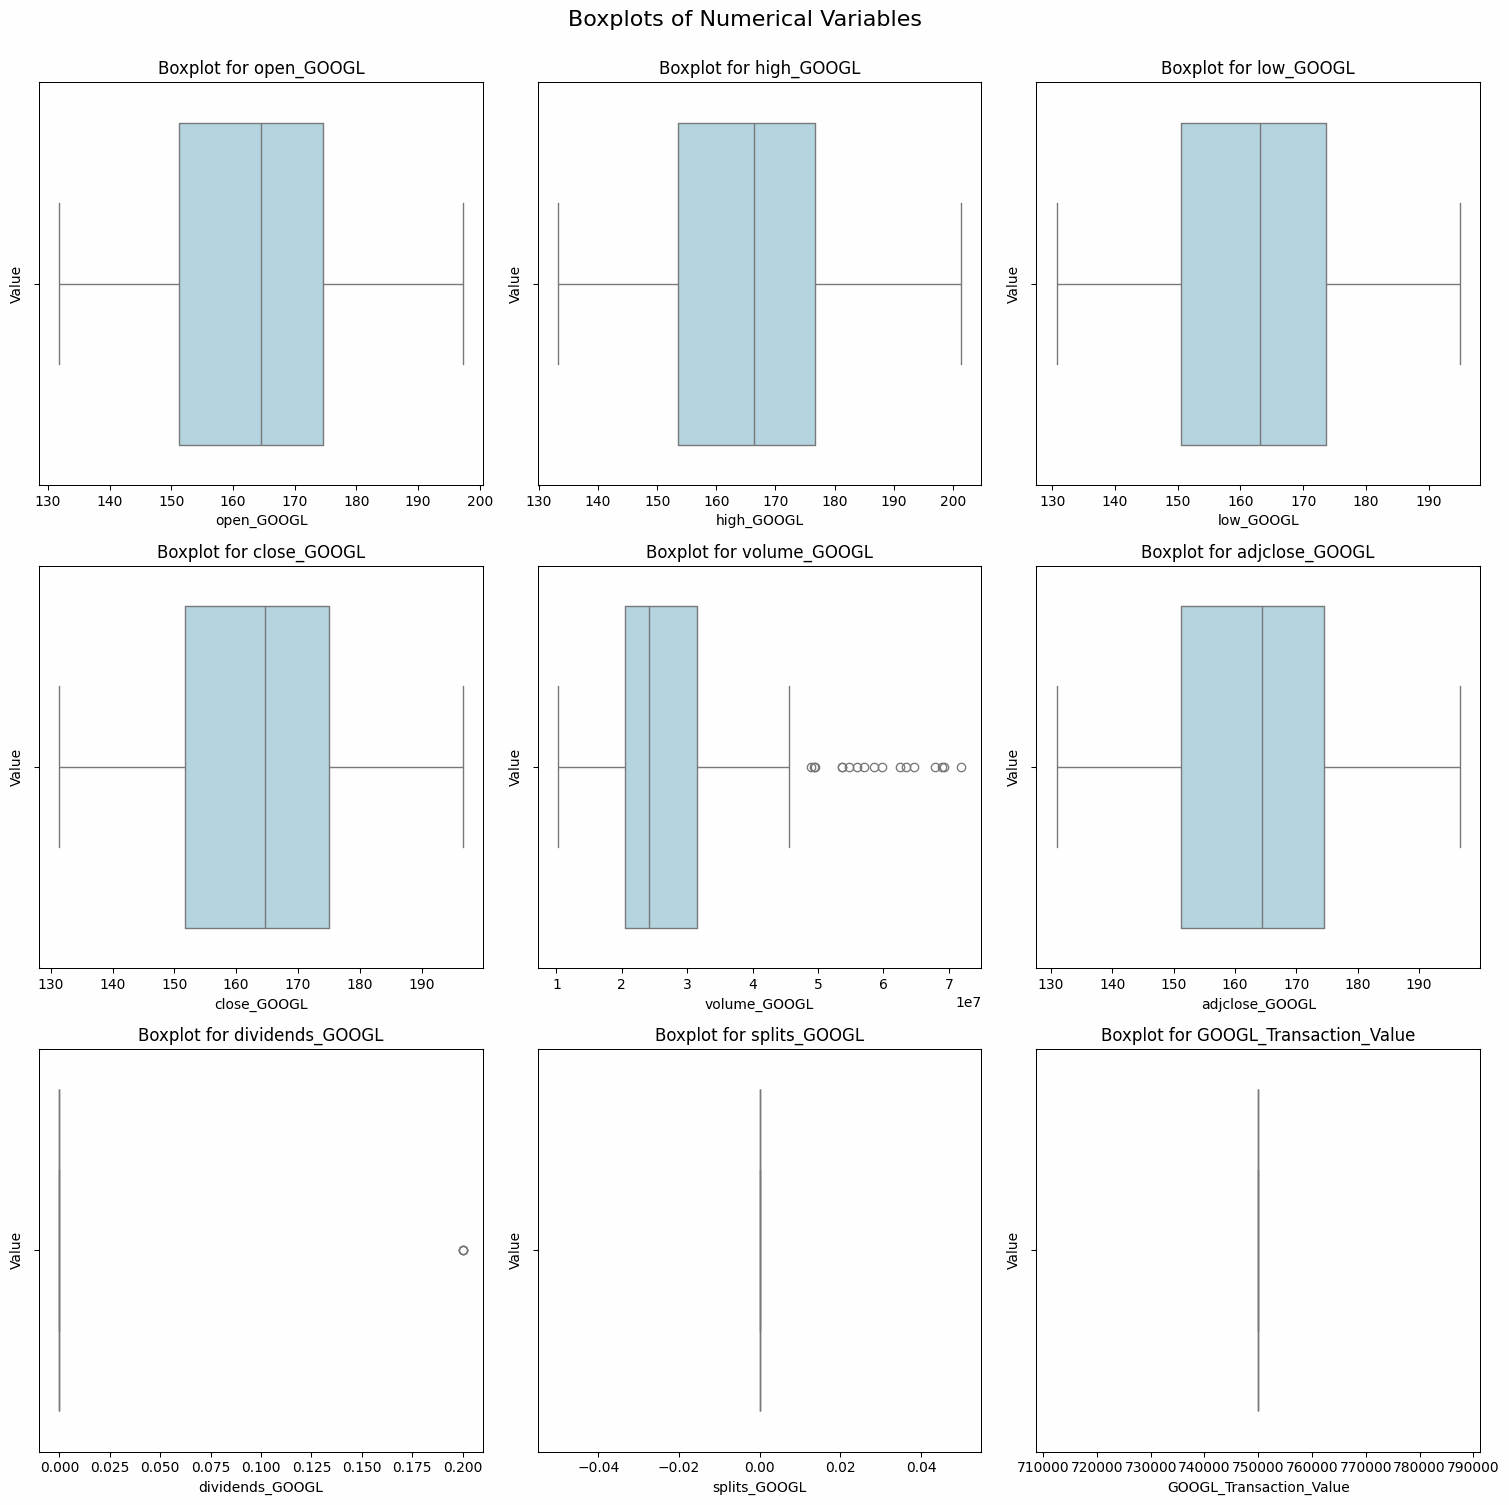

In [48]:
# Create boxplots for GOOGL
plot_boxplots(df_googl, num_cols_googl)

 **2. Boxplot Analysis (GOOGL)**
Boxplots help identify **outliers, volatility, and potential risk factors**.

 **Stock Price Variability**
- **Observations:**
  - **The interquartile range (IQR) for open, high, low, close, and adjusted close prices is relatively tight**, indicating **low-to-moderate volatility**.
  - There are **no extreme outliers in stock prices**, reinforcing **consistent price movement**.

- **Business Implications:**
  - **Moderate Volatility & Steady Growth:** GOOGL’s **stable IQR suggests that investors experience consistent gains without extreme swings**.
  - **Attractive for Institutional Investors:** The **lack of major outliers makes Alphabet a preferred choice for large-scale funds** looking for **stable tech investments**.
  - **Support for Long-Term Holdings:** The **low volatility makes GOOGL an ideal long-term stock**, reducing **risk exposure compared to more speculative tech stocks**.

---

 **Trading Volume Boxplot**
- **Observations:**
  - **The boxplot shows several upper outliers, meaning certain days had unusually high trading activity**.

- **Business Implications:**
  - **Market Events Drive Trading Activity:** The volume spikes likely correspond with **earnings releases, AI-related announcements, or regulatory changes affecting Alphabet's business model**.
  - **Strong Institutional Participation:** Large trading volume on certain days indicates **significant institutional movement**, which could lead to **temporary price shifts and trading opportunities**.
  - **Consistent Liquidity:** Even on **high-volume days, Alphabet maintains liquidity**, making it **a reliable stock for large-scale transactions**.

---

 **Dividends & Splits Boxplots**
- **Observations:**
  - **Dividends show slight variation**, reinforcing Alphabet’s **small but growing dividend strategy**.
  - **No stock splits are present**, confirming Alphabet’s strategy of **maintaining a premium stock price**.

- **Business Implications:**
  - **Dividends Attract Long-Term Investors:** Alphabet’s decision to **issue small dividends signals financial stability**, making it **more attractive to dividend-seeking investors**.
  - **Stock Split Considerations:** If **GOOGL’s price continues to rise, a stock split could be introduced to increase liquidity and market participation**.
  - **Strong Capital Appreciation Strategy:** By **keeping its dividend low and avoiding stock splits, Alphabet signals its commitment to long-term growth through reinvestment in emerging technologies**.

---

 **Key Takeaways & Strategic Investment Insights**
- **Alphabet’s stock exhibits a strong uptrend with stable price movement, making it an attractive long-term investment.**
- **Trading volume spikes align with key events, indicating institutional investor participation and potential trading opportunities.**
- **The introduction of dividends suggests Alphabet is positioning itself as a stable, mature investment, making it appealing to income-focused investors.**
- **The absence of stock splits suggests Alphabet prefers to maintain a premium stock price, reinforcing its appeal to institutional investors.**
- **Nancy Pelosi’s stable transaction value suggests confidence in Alphabet’s future growth and continued dominance in AI, cloud computing, and digital advertising.**

---

 **Final Business Insight**
Alphabet remains a **top-tier investment for both growth and income investors**, balancing **moderate dividend payouts with strong reinvestment in future technologies**. **Its liquidity, consistent price trends, and institutional appeal make it a cornerstone stock for diversified portfolios.**


## TESLA (TSLA)

In [49]:
# Create numerical columns
num_cols_tsla = df_tsla.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAM

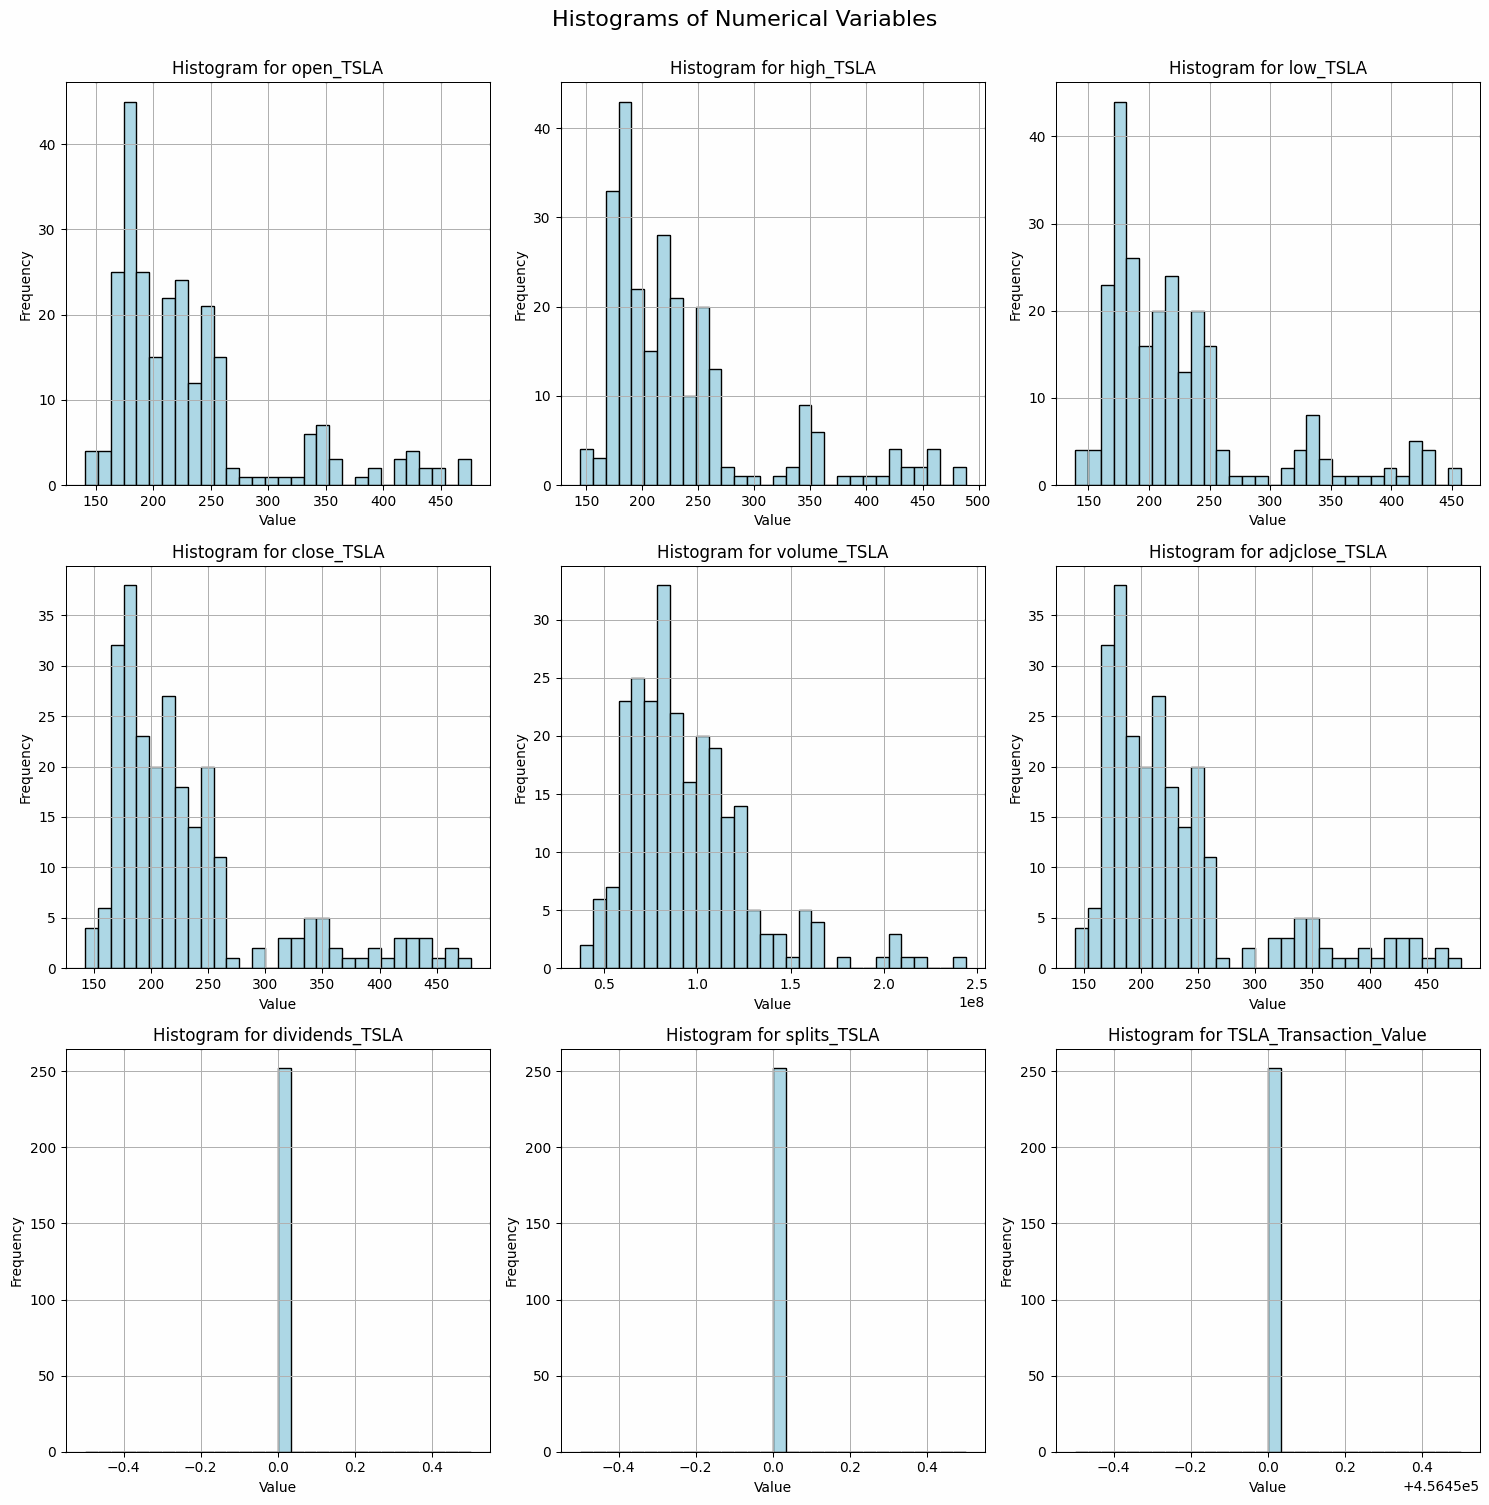

In [50]:
# Create histograms for TSLA
plot_histograms(df_tsla, num_cols_tsla)


 **1. Histogram Analysis (TSLA)**
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The **price distributions are right-skewed**, meaning **TSLA had a lower price range for most of the period but experienced significant upward movements**.
  - The **most frequent price range is between $160 and $250**, but there are **notable occurrences above $350 and even $450**.
  - The **upward tail indicates periods of strong rallies**, likely driven by **market enthusiasm, earnings beats, or macroeconomic shifts**.

- **Business Implications:**
  - **High Volatility & Growth Potential:** The **right-skewed price distribution suggests Tesla has had rapid growth periods**, likely fueled by **EV adoption, AI advancements, and production milestones**.
  - **Attractive for Speculative Traders:** The presence of **frequent price spikes makes Tesla a prime stock for traders looking to capitalize on momentum swings**.
  - **Key Levels for Investors:** The **price range of $160-$250 represents a key support zone**, while **above $400 is a high-resistance area** where investors might take profits.

---

 **Trading Volume Distribution**
- **Observations:**
  - The **volume histogram shows a normal distribution with a slight right skew**, meaning **Tesla has consistent trading volume but experiences major spikes on select days**.
  - **The most frequent trading volume is between 50M - 100M shares per day**, but some days saw **volumes exceeding 200M shares**.

- **Business Implications:**
  - **Institutional & Retail Interest:** Volume spikes are often linked to **institutional investments, retail trading frenzies, or major news such as Elon Musk's announcements, earnings calls, or government EV policy changes**.
  - **High Liquidity & Market Efficiency:** **Tesla’s high trading volume ensures liquidity**, meaning investors can execute large orders with minimal price impact.
  - **Market Sensitivity:** High trading volumes **coincide with volatile price swings**, meaning **Tesla reacts strongly to macroeconomic factors, news events, and investor sentiment**.

---

 **Dividends & Stock Splits**
- **Observations:**
  - The **dividends histogram is empty**, confirming that **Tesla does not pay dividends**.
  - **The stock splits histogram is also empty**, indicating **no stock splits occurred during this period**.

- **Business Implications:**
  - **Reinvestment Over Payouts:** Tesla's **lack of dividends aligns with its growth-oriented strategy**, as it reinvests earnings into **factory expansion, R&D (AI, autonomous driving), and battery innovation**.
  - **High-Growth Stock Strategy:** Tesla remains **a capital appreciation stock rather than an income-generating stock**, meaning **investors should focus on long-term growth rather than dividend returns**.
  - **Potential Future Stock Split:** If Tesla **continues its volatile price appreciation, a stock split could be introduced to improve retail investor accessibility**, as seen in its past stock splits.


### BOXPLOTS

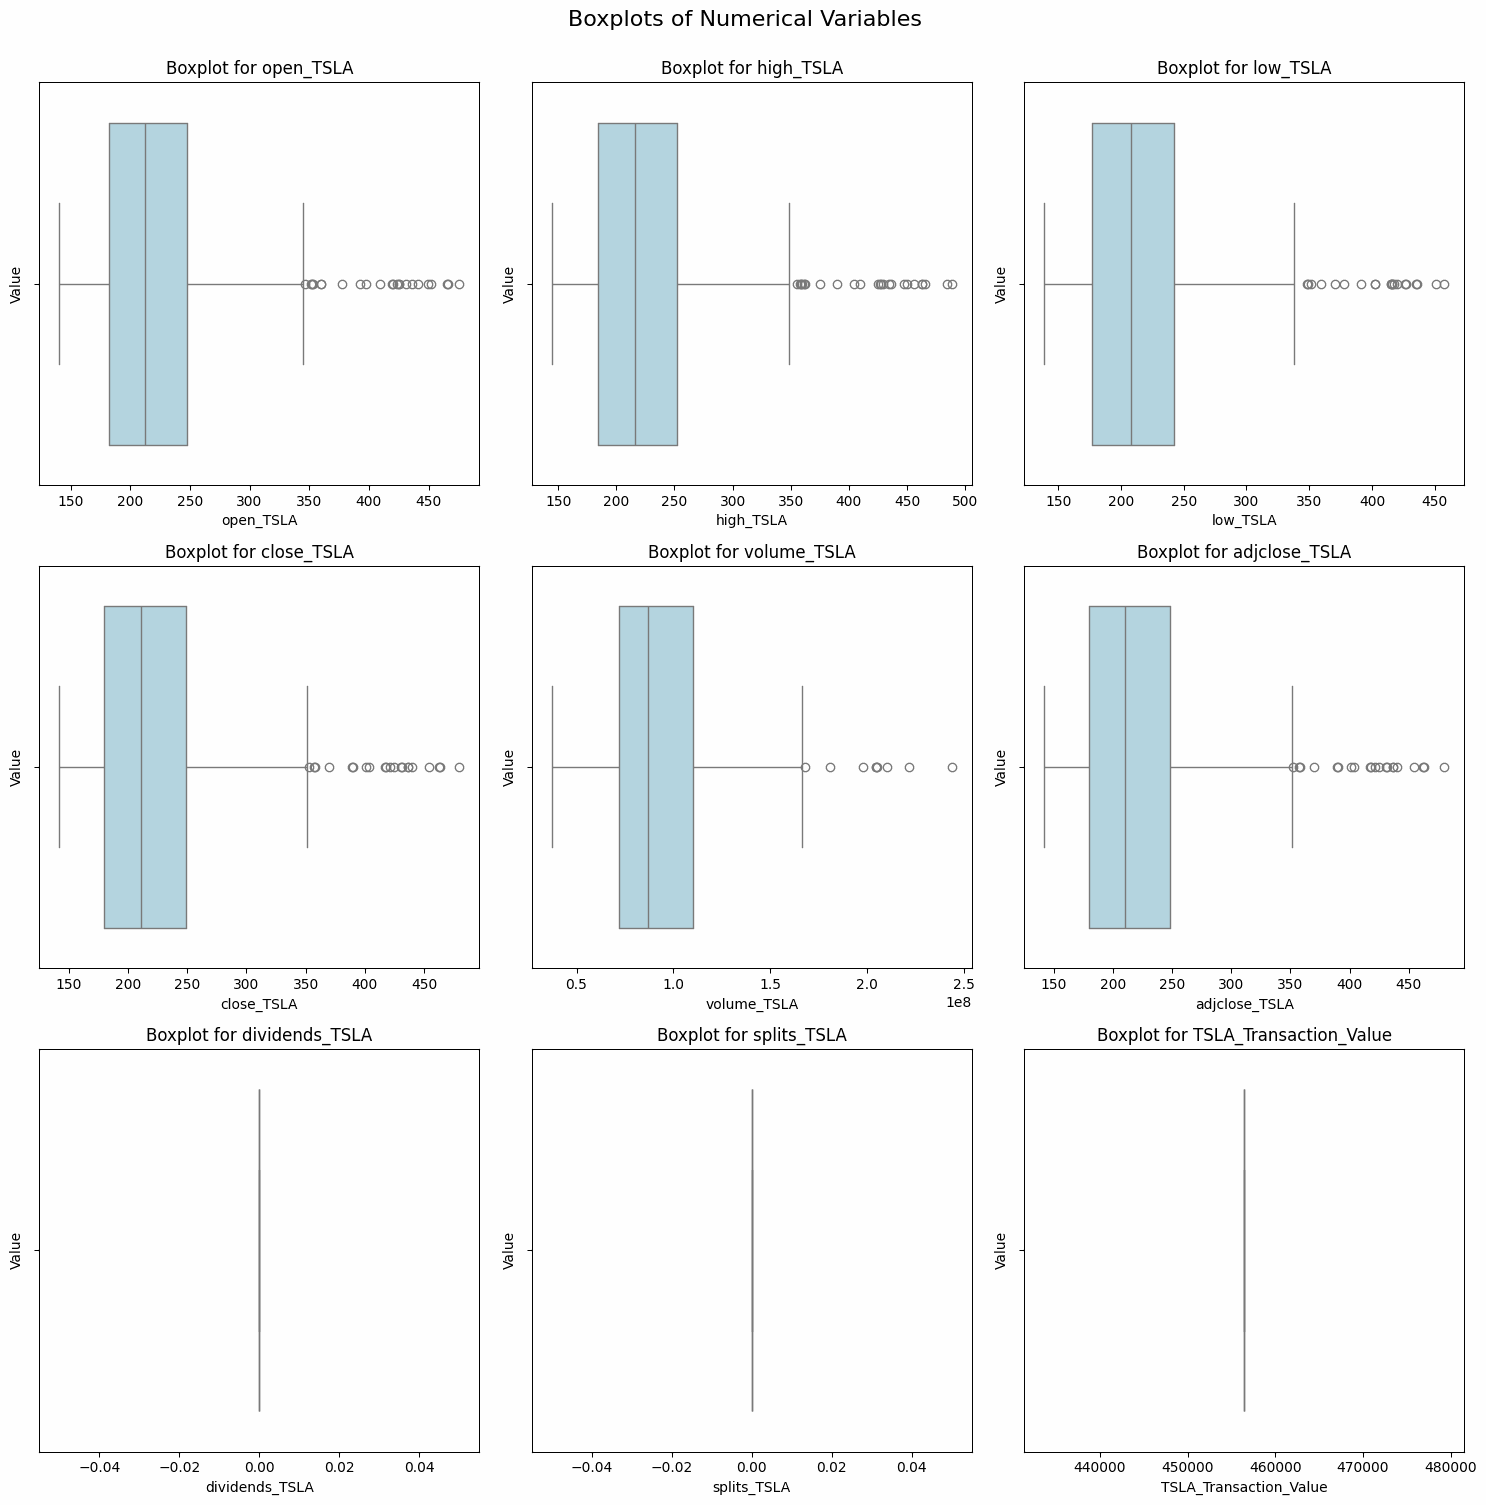

In [51]:
# Create boxplots for TSLA
plot_boxplots(df_tsla, num_cols_tsla)

**2. Boxplot Analysis (TSLA)**
Boxplots help identify **outliers, volatility, and potential risk factors**.

 **Stock Price Variability**
- **Observations:**
  - **The IQR for open, high, low, close, and adjusted close prices is relatively wide**, confirming **Tesla’s status as a high-volatility stock**.
  - **Several extreme outliers appear above $400**, indicating **days with sharp price increases**.

- **Business Implications:**
  - **Extreme Price Swings & Risk:** Tesla’s **wide IQR and high outliers confirm that the stock is highly volatile**, making it **a high-risk, high-reward investment**.
  - **Ideal for Momentum Traders:** The **presence of multiple outliers suggests Tesla has had multiple strong rallies**, providing **opportunities for momentum-based trading strategies**.
  - **Hedge Fund & Retail Speculation:** The **price fluctuations indicate frequent speculative trading**, meaning **hedge funds and retail investors play a major role in Tesla's stock movements**.

---

 **Trading Volume Boxplot**
- **Observations:**
  - **There are several upper outliers in trading volume**, meaning that **some days had significantly higher trading activity than usual**.

- **Business Implications:**
  - **Earnings & Market Events Drive Trading:** These **volume spikes could be linked to major earnings calls, production reports, or regulatory news** affecting Tesla’s stock.
  - **Speculative Trading at Peaks:** The **higher trading volume outliers suggest Tesla is highly speculative**, with large investors **piling in and out of the stock quickly**.
  - **Increased Retail Participation:** Tesla’s **stock remains one of the most actively traded equities**, driven by **retail investors, day traders, and hedge funds**.

---

 **Dividends & Splits Boxplots**
- **Observations:**
  - **Tesla does not pay dividends**, reinforcing **its high-growth stock strategy**.
  - **No stock splits occurred during this period**, suggesting **Tesla’s leadership is maintaining a high stock price strategy**.

- **Business Implications:**
  - **Tesla Is a Growth-Focused Investment:** **No dividend payouts confirm that Tesla is focused on reinvesting profits into innovation, factory expansion, and AI development**.
  - **Stock Splits Could Be Future Possibility:** If **Tesla’s stock price exceeds $500+, a stock split may be considered** to make shares more accessible to retail investors.
  - **High-Risk, High-Reward Nature:** Without dividends or stock splits, Tesla **remains a speculative investment, attractive to risk-tolerant investors and short-term traders**.

---

 **Key Takeaways & Strategic Investment Insights**
- **Tesla remains a high-volatility stock with strong price swings, making it ideal for speculative traders and high-risk investors.**
- **Trading volume spikes align with key market events, confirming that investor sentiment plays a major role in price movements.**
- **Tesla does not pay dividends and prefers to reinvest earnings into innovation and expansion, reinforcing its long-term growth focus.**
- **The presence of extreme price outliers suggests Tesla can experience strong price rallies, making it a momentum trader’s favorite.**
- **Nancy Pelosi’s transaction value remained stable, implying a long-term investment strategy with confidence in Tesla’s future expansion in the EV and AI sectors.**

---

 **Final Business Insight**
Tesla continues to be **one of the most volatile and actively traded stocks in the market**, making it **an attractive choice for aggressive investors looking for high returns but with significant risks**. **Its long-term strategy remains focused on technological innovation, global expansion, and AI-driven advancements, making it a compelling yet speculative investment.**



## BROADCOM (AVGO)

In [52]:
# Create numerical columns
num_cols_avgo = df_avgo.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

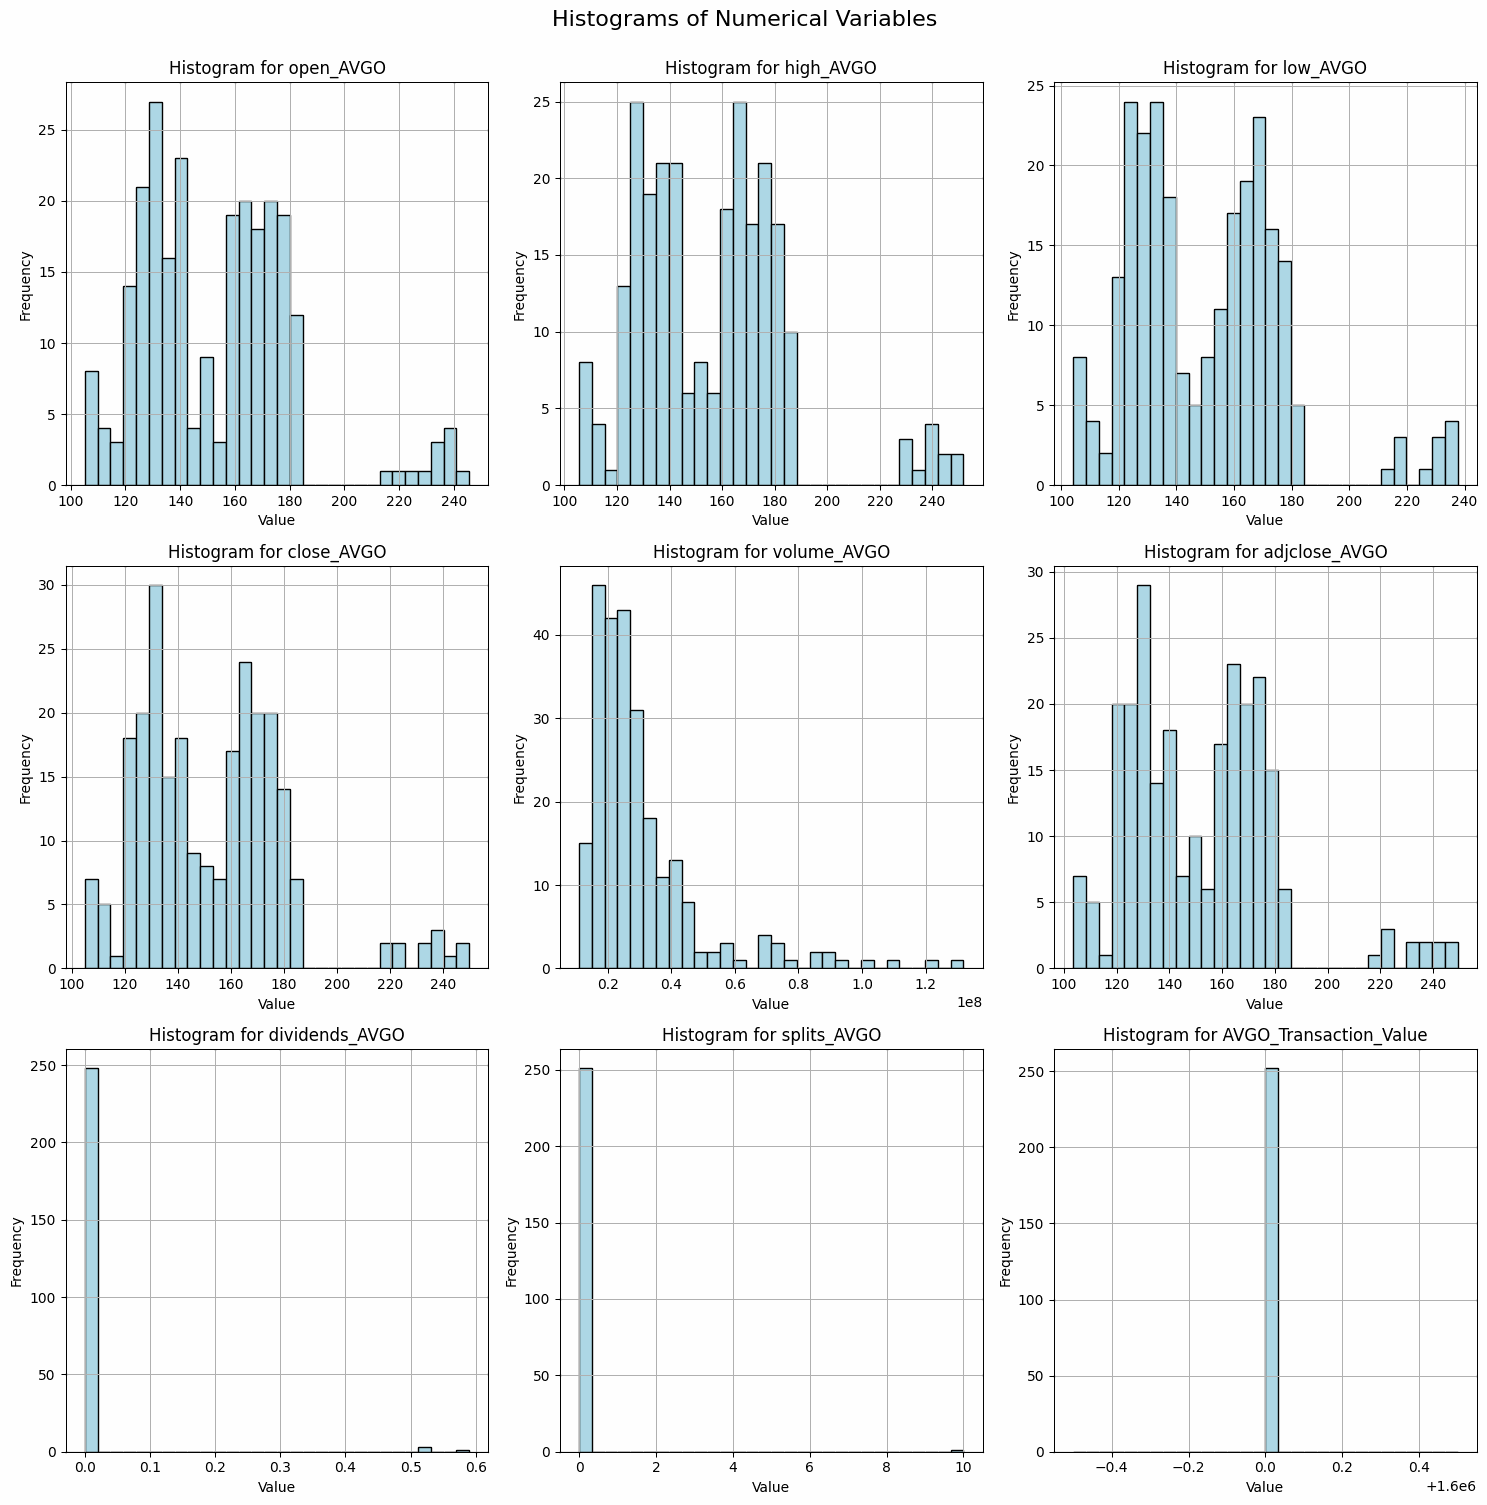

In [53]:
# Create histograms for AVGO
plot_histograms(df_avgo, num_cols_avgo)

 **1. Histogram Analysis (AVGO)**
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The **price distributions are bimodal**, meaning **AVGO experienced two distinct price levels** during the analyzed period.
  - The **most frequent price range is between $120 and $180**, with a secondary peak occurring above **$220-$240**.
  - **Sharp transitions between price clusters suggest significant market events**, possibly earnings releases or strategic acquisitions.

- **Business Implications:**
  - **Strong Growth Momentum:** The **bimodal pattern indicates that Broadcom had a major price breakout**, likely due to **earnings beats, increased semiconductor demand, or business expansion**.
  - **Stable Investment for Long-Term Holders:** The **absence of extreme price swings within clusters suggests AVGO is less volatile than high-growth tech stocks**.
  - **Strategic Entry & Exit Points:** Investors should monitor **support around $140-$160 and resistance near $220+, as these may serve as key trading levels**.

---

 **Trading Volume Distribution**
- **Observations:**
  - The **volume histogram is right-skewed**, meaning **most trading days had moderate volume**, but **some experienced significantly higher trading activity**.
  - **The most frequent trading volume is between 10M - 30M shares per day**, but **spikes above 100M shares suggest heightened investor activity**.

- **Business Implications:**
  - **Institutional Buying & Selling:** The volume spikes are likely associated with **institutional trades, earnings reports, or M&A activity**.
  - **Market Efficiency & Liquidity:** AVGO's **consistent volume distribution ensures liquidity**, allowing both retail and institutional investors to enter and exit positions efficiently.
  - **Stock Reacts to Market Catalysts:** The **spikes in volume suggest AVGO's stock price reacts to company-specific news, such as AI developments, semiconductor market shifts, or regulatory approvals**.

---

 **Dividends & Stock Splits**
- **Observations:**
  - The **dividends histogram shows a clear peak (~$0.60 per share), confirming that Broadcom consistently pays dividends**.
  - The **stock splits histogram indicates at least one significant stock split**, suggesting Broadcom has adjusted its share structure in the past.

- **Business Implications:**
  - **Attractive for Income Investors:** Broadcom’s **dividend policy makes it appealing for dividend-focused investors**, distinguishing it from pure growth stocks.
  - **Balanced Growth & Income Strategy:** Broadcom’s ability to **pay dividends while maintaining strong stock price appreciation indicates solid financial health**.
  - **Stock Split Suggests Growth Confidence:** Stock splits typically occur when **a company expects sustained stock price growth**, making **AVGO attractive to both retail and institutional investors**.


### BOXPLOTS

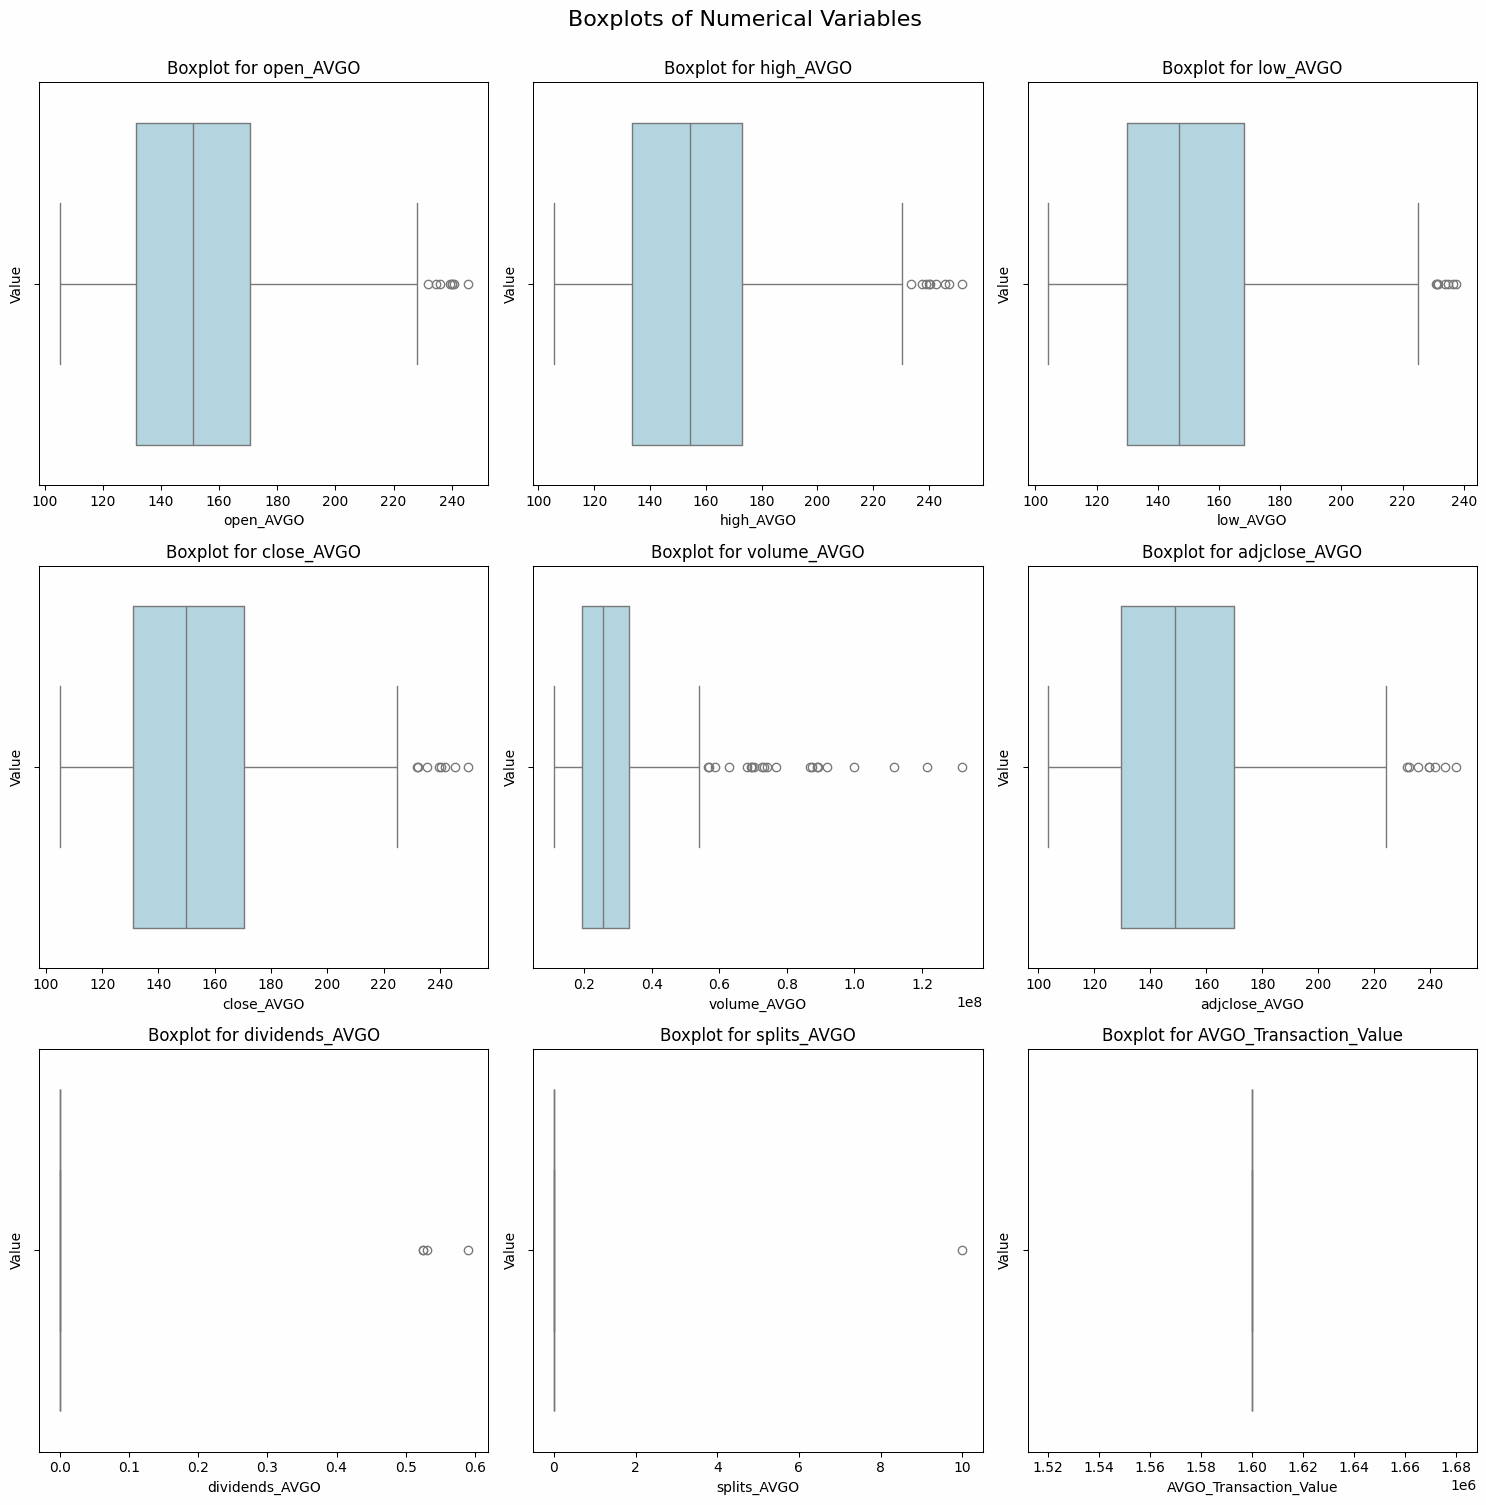

In [54]:
# Create boxplots for AVGO
plot_boxplots(df_avgo, num_cols_avgo)

 **2. Boxplot Analysis (AVGO)**
Boxplots help identify **outliers, volatility, and potential risk factors**.

 **Stock Price Variability**
- **Observations:**
  - **The IQR for open, high, low, close, and adjusted close prices is relatively narrow, with a few outliers at higher price levels**.
  - **Some extreme outliers above $240 suggest sudden spikes in price**, possibly due to earnings announcements or major industry developments.

- **Business Implications:**
  - **Moderate Volatility & Steady Growth:** The **relatively tight IQR suggests Broadcom is a stable investment with moderate price appreciation over time**.
  - **Investor Confidence & Growth Trajectory:** The **presence of higher outliers suggests that Broadcom has experienced strong investor interest, particularly during positive earnings cycles**.
  - **Safe Investment with Growth Potential:** **Unlike high-volatility tech stocks, AVGO provides a balance of stability and growth**, making it an attractive **long-term investment**.

---

 **Trading Volume Boxplot**
- **Observations:**
  - **There are multiple upper outliers, meaning certain days had significantly higher trading activity than usual**.

- **Business Implications:**
  - **Earnings & M&A Activity Drive Trading:** The volume spikes suggest that **Broadcom’s stock sees higher-than-average trading activity around earnings reports or strategic moves (e.g., acquisitions, AI investments)**.
  - **Liquidity Supports Large-Scale Trades:** The ability to handle **high-volume trading without significant price disruption indicates that AVGO is a well-structured, institutional-friendly stock**.
  - **Increased Investor Attention:** The **higher-than-average trading volumes suggest increased investor confidence in Broadcom’s market position**.

---

 **Dividends & Splits Boxplots**
- **Observations:**
  - **Dividends show some variation, reinforcing Broadcom’s consistent shareholder returns**.
  - **Stock splits are present, indicating that Broadcom has adjusted its share structure in the past**.

- **Business Implications:**
  - **Dividend Stability Attracts Investors:** Broadcom’s **consistent dividend payouts enhance its appeal to long-term, income-focused investors**.
  - **Stock Split Signals Growth & Accessibility:** Broadcom’s **stock split history suggests that management is confident in long-term price appreciation and is making shares more accessible to retail investors**.
  - **Balanced Approach to Value Creation:** The **combination of dividends, stock splits, and capital appreciation makes AVGO an attractive stock for both conservative and growth investors**.

---

 **Key Takeaways & Strategic Investment Insights**
- **Broadcom exhibits a strong growth trend with moderate price stability, making it a solid long-term investment.**
- **Trading volume spikes align with earnings reports, AI advancements, and semiconductor industry developments, suggesting strong institutional interest.**
- **Broadcom’s dividend payments make it attractive for income investors, providing a balance between stock appreciation and shareholder returns.**
- **Past stock splits indicate Broadcom’s confidence in future price appreciation and its strategy to maintain accessibility for retail investors.**
- **Nancy Pelosi’s stable transaction value in AVGO suggests long-term confidence in the semiconductor sector and Broadcom’s continued expansion.**

---

 **Final Business Insight**
Broadcom remains a **strong contender in the semiconductor and AI industry**, balancing **dividend payments with consistent stock appreciation**. **Its high liquidity, predictable price trends, and institutional appeal make it a blue-chip stock suitable for both long-term growth and income-focused portfolios.**





## ROBLOX (RBLX)

In [55]:
# Create numerical columns
num_cols_rblx = df_rblx.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

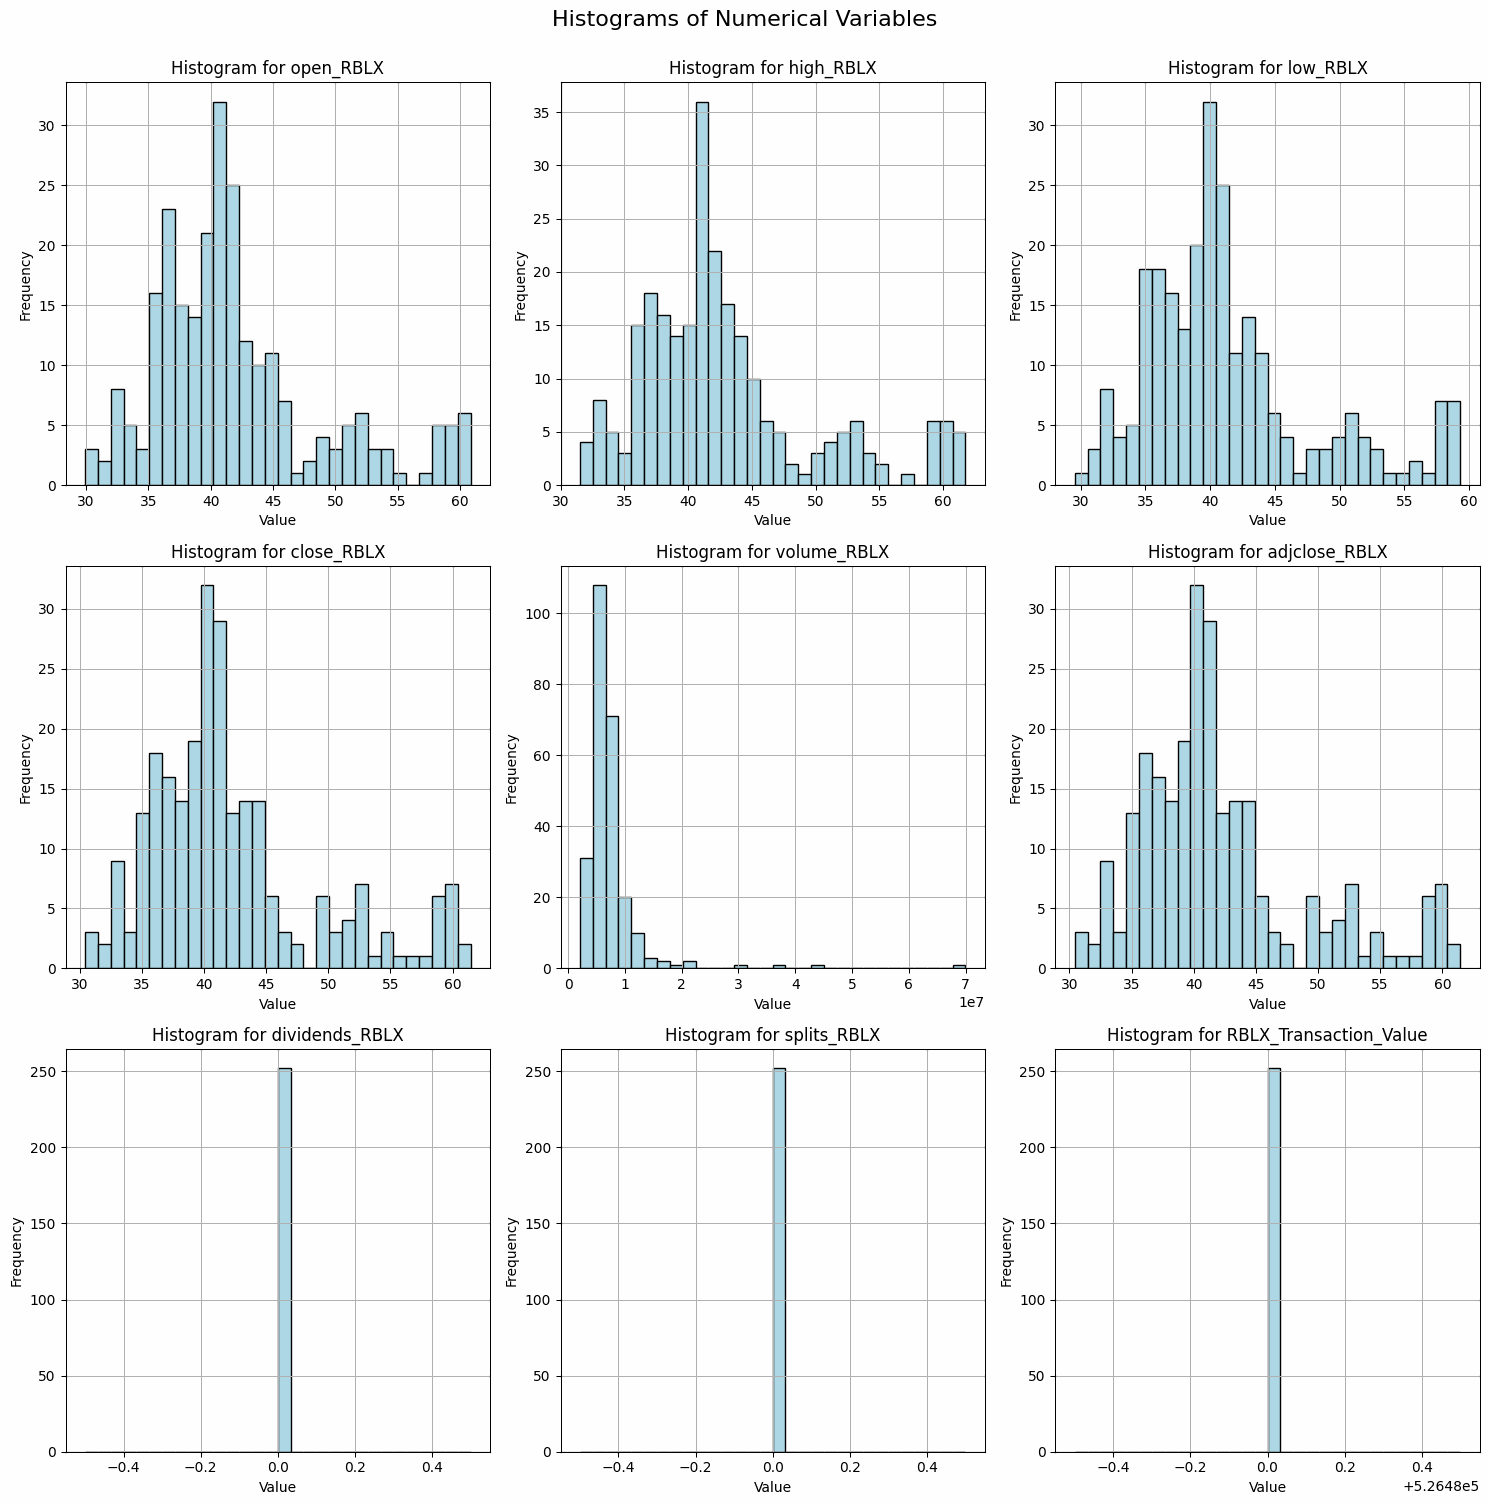

In [56]:
# Create histograms for RBLX
plot_histograms(df_rblx, num_cols_rblx)


 **1. Histogram Analysis (RBLX)**
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The stock price distributions are **bimodal**, indicating **two distinct price levels during the analyzed period**.
  - The **most frequent price range is between $35 and $45**, but a secondary peak occurs around **$55-$60**.
  - The **price spikes suggest periods of strong rallies**, likely influenced by earnings reports, market sentiment, or industry trends in the gaming sector.

- **Business Implications:**
  - **Growth Stock with Volatility:** The **bimodal price pattern suggests that Roblox experienced significant price movement**, making it **a high-risk, high-reward investment**.
  - **Market Sentiment-Driven:** **Investor sentiment and market events (e.g., earnings calls, user growth reports, and metaverse developments) heavily impact RBLX stock movements**.
  - **Strategic Entry & Exit Points:** The **price range of $35-$45 represents a key support zone, while $55-$60 is a strong resistance level**, where investors may consider profit-taking.

---

 **Trading Volume Distribution**
- **Observations:**
  - The **volume histogram is highly right-skewed**, meaning that **most days had moderate trading volume**, but **some days experienced extreme spikes**.
  - **The most frequent trading volume is below 5M shares per day**, with spikes exceeding **30M shares**.

- **Business Implications:**
  - **Speculative Trading & Retail Activity:** Volume spikes suggest **heavy retail trading involvement, likely around earnings reports or major gaming-related announcements**.
  - **Volatility & Liquidity:** Roblox’s **trading volume surges align with stock price volatility**, making it an **appealing stock for short-term traders**.
  - **Institutional Entry & Exit:** Large spikes in volume could indicate **institutional fund movements, either accumulating or selling large positions based on earnings results**.

---

 **Dividends & Stock Splits**
- **Observations:**
  - The **dividends histogram is empty**, confirming that **Roblox does not pay dividends**.
  - **The stock splits histogram is also empty**, indicating **no stock splits occurred during this period**.

- **Business Implications:**
  - **Reinvestment Over Payouts:** Roblox’s **lack of dividends aligns with its aggressive growth strategy**, focusing on **expanding its metaverse platform and user base**.
  - **Pure Growth Stock:** Investors in RBLX **should not expect dividend income** but rather look for **capital appreciation based on business expansion**.
  - **Potential Future Stock Split:** If **Roblox sustains growth and reaches higher price levels, a stock split could be considered** to enhance retail investor accessibility.


### BOXPLOTS

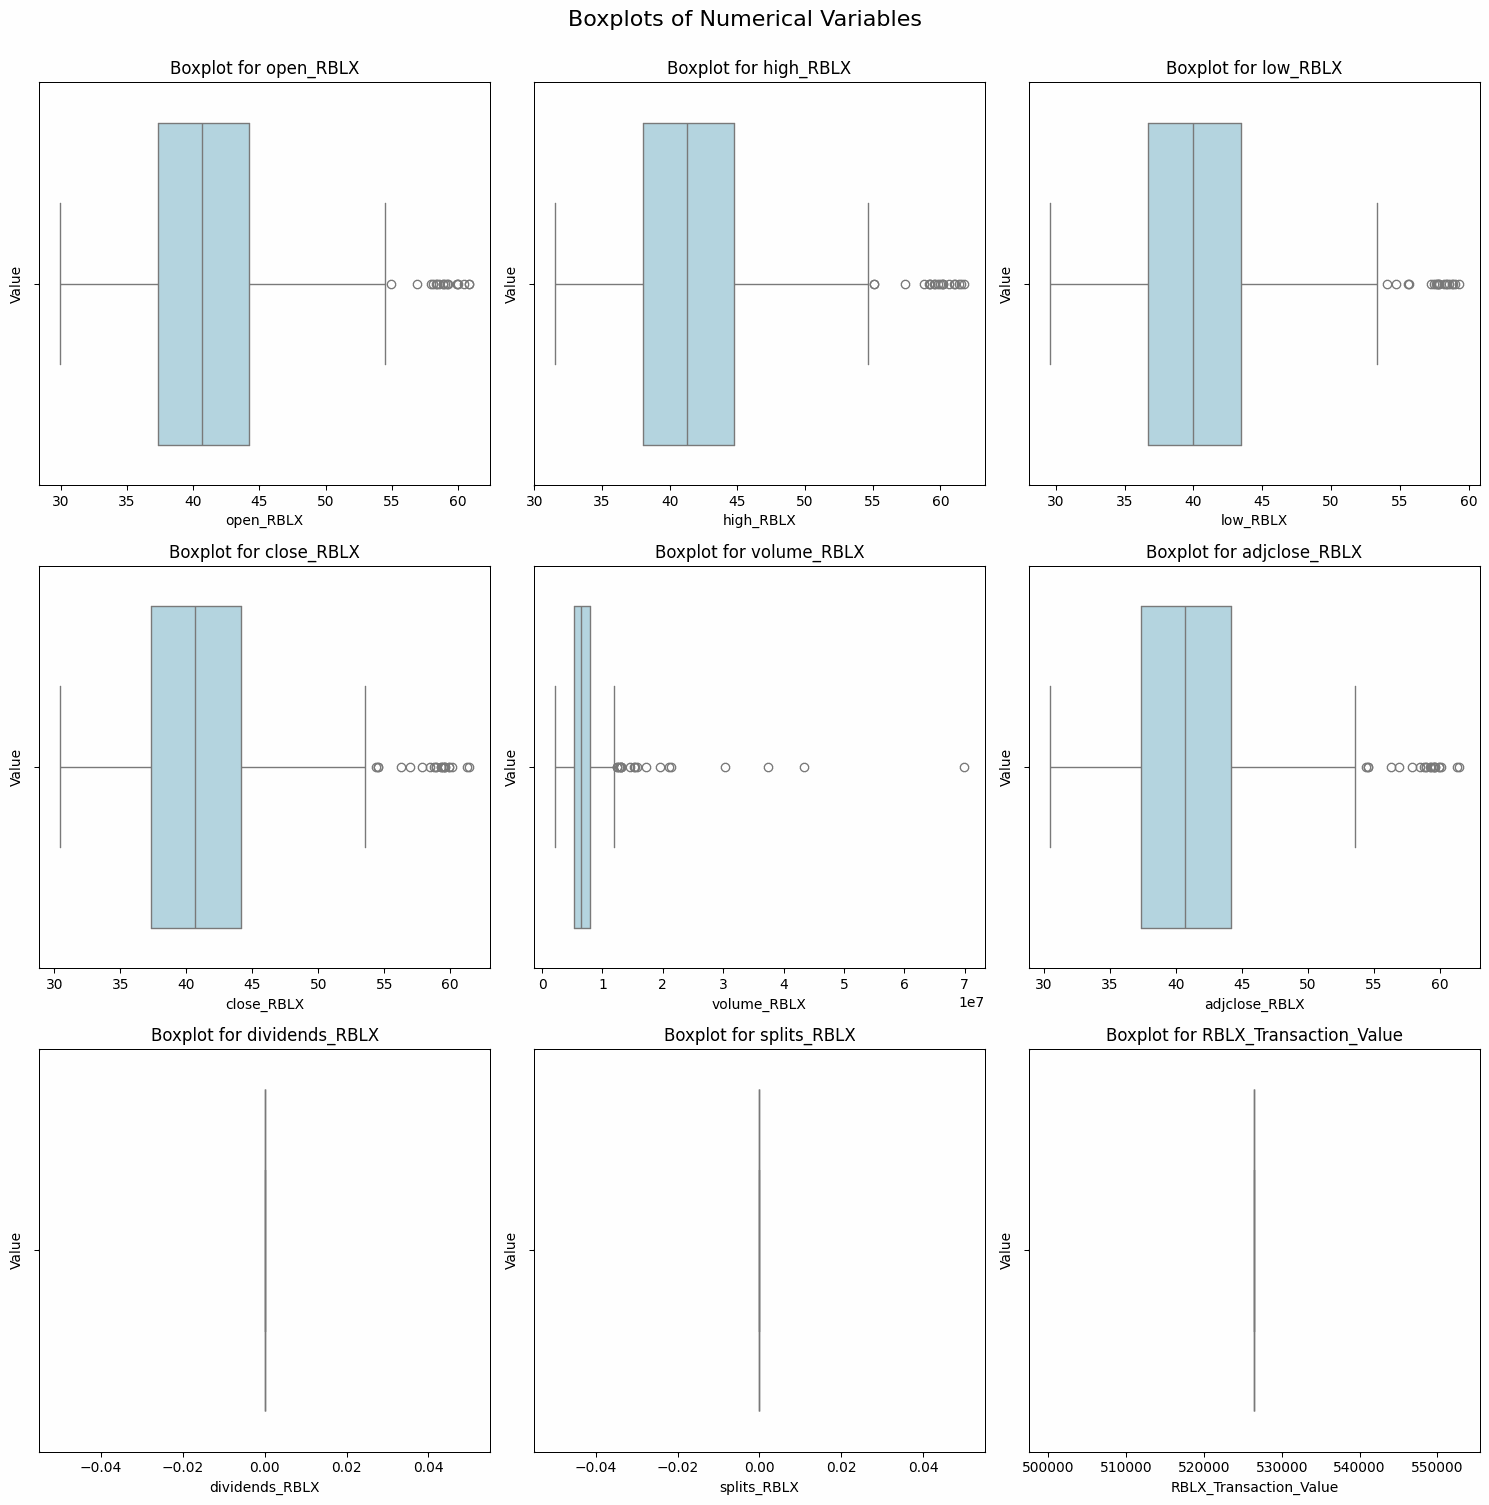

In [57]:
# Create boxplots for RBLX
plot_boxplots(df_rblx, num_cols_rblx)

 **2. Boxplot Analysis (RBLX)**
Boxplots help identify **outliers, volatility, and potential risk factors**.

 **Stock Price Variability**
- **Observations:**
  - **The IQR for open, high, low, close, and adjusted close prices is relatively tight, with several outliers at the higher end**.
  - **Outliers above $55 suggest sudden price spikes**, possibly due to strong earnings reports or market speculation.

- **Business Implications:**
  - **High Volatility & Speculative Interest:** The **wide range and multiple outliers suggest that Roblox is a volatile stock**, making it **ideal for traders but risky for conservative investors**.
  - **Opportunities for Swing Traders:** The **outliers indicate significant short-term price movements**, presenting **swing trading opportunities for active traders**.
  - **Market Sentiment & Growth Expectations:** The **stock reacts strongly to earnings reports and user growth metrics**, meaning **investors must closely monitor company performance**.

---

 **Trading Volume Boxplot**
- **Observations:**
  - **There are significant upper outliers in trading volume, confirming that some days had unusually high trading activity**.

- **Business Implications:**
  - **Earnings & Gaming Industry Developments Drive Trading:** The volume spikes suggest that **Roblox’s stock is heavily impacted by earnings results, new partnerships, and gaming industry trends**.
  - **Retail & Institutional Interest:** While **Roblox has significant retail investor activity, institutional participation is also evident in volume spikes**.
  - **Liquidity & Market Reactions:** The ability to handle **high-volume trading ensures strong liquidity**, allowing for **efficient trade execution without excessive price impact**.

---

 **Dividends & Splits Boxplots**
- **Observations:**
  - **Roblox does not pay dividends**, reinforcing **its focus on reinvesting in business expansion**.
  - **No stock splits occurred during this period**, indicating that **Roblox is maintaining a relatively low stock price, reducing the need for splits**.

- **Business Implications:**
  - **Roblox Is a High-Growth, Non-Dividend Stock:** Investors should **expect reinvestment in technology, marketing, and platform expansion rather than direct shareholder payouts**.
  - **Potential Future Stock Split if Growth Continues:** If Roblox’s **stock price significantly appreciates, a split may be considered to make shares more accessible to a broader investor base**.
  - **Long-Term Expansion Play:** Investors should **evaluate Roblox based on its user growth, revenue model, and monetization strategies rather than dividend yield**.

---

 **Key Takeaways & Strategic Investment Insights**
- **Roblox is a speculative, high-growth stock driven by market sentiment, user growth, and metaverse adoption.**
- **Trading volume spikes suggest significant institutional and retail trading, particularly around earnings reports and major announcements.**
- **The stock exhibits high volatility, making it attractive for swing traders and momentum investors but riskier for conservative investors.**
- **Roblox does not pay dividends, reinforcing its long-term reinvestment strategy into platform development and expansion.**
- **Nancy Pelosi’s investment in RBLX suggests a long-term outlook, indicating confidence in the company's future growth in the gaming and metaverse sectors.**

---

 **Final Business Insight**
Roblox remains a **high-risk, high-reward stock with strong growth potential in the gaming and metaverse sectors**. **Investors should focus on the company’s ability to expand its user base, improve monetization strategies, and navigate competition in the evolving gaming market.**




## VISA (V)

In [58]:
# Create numerical columns
num_cols_v = df_v.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

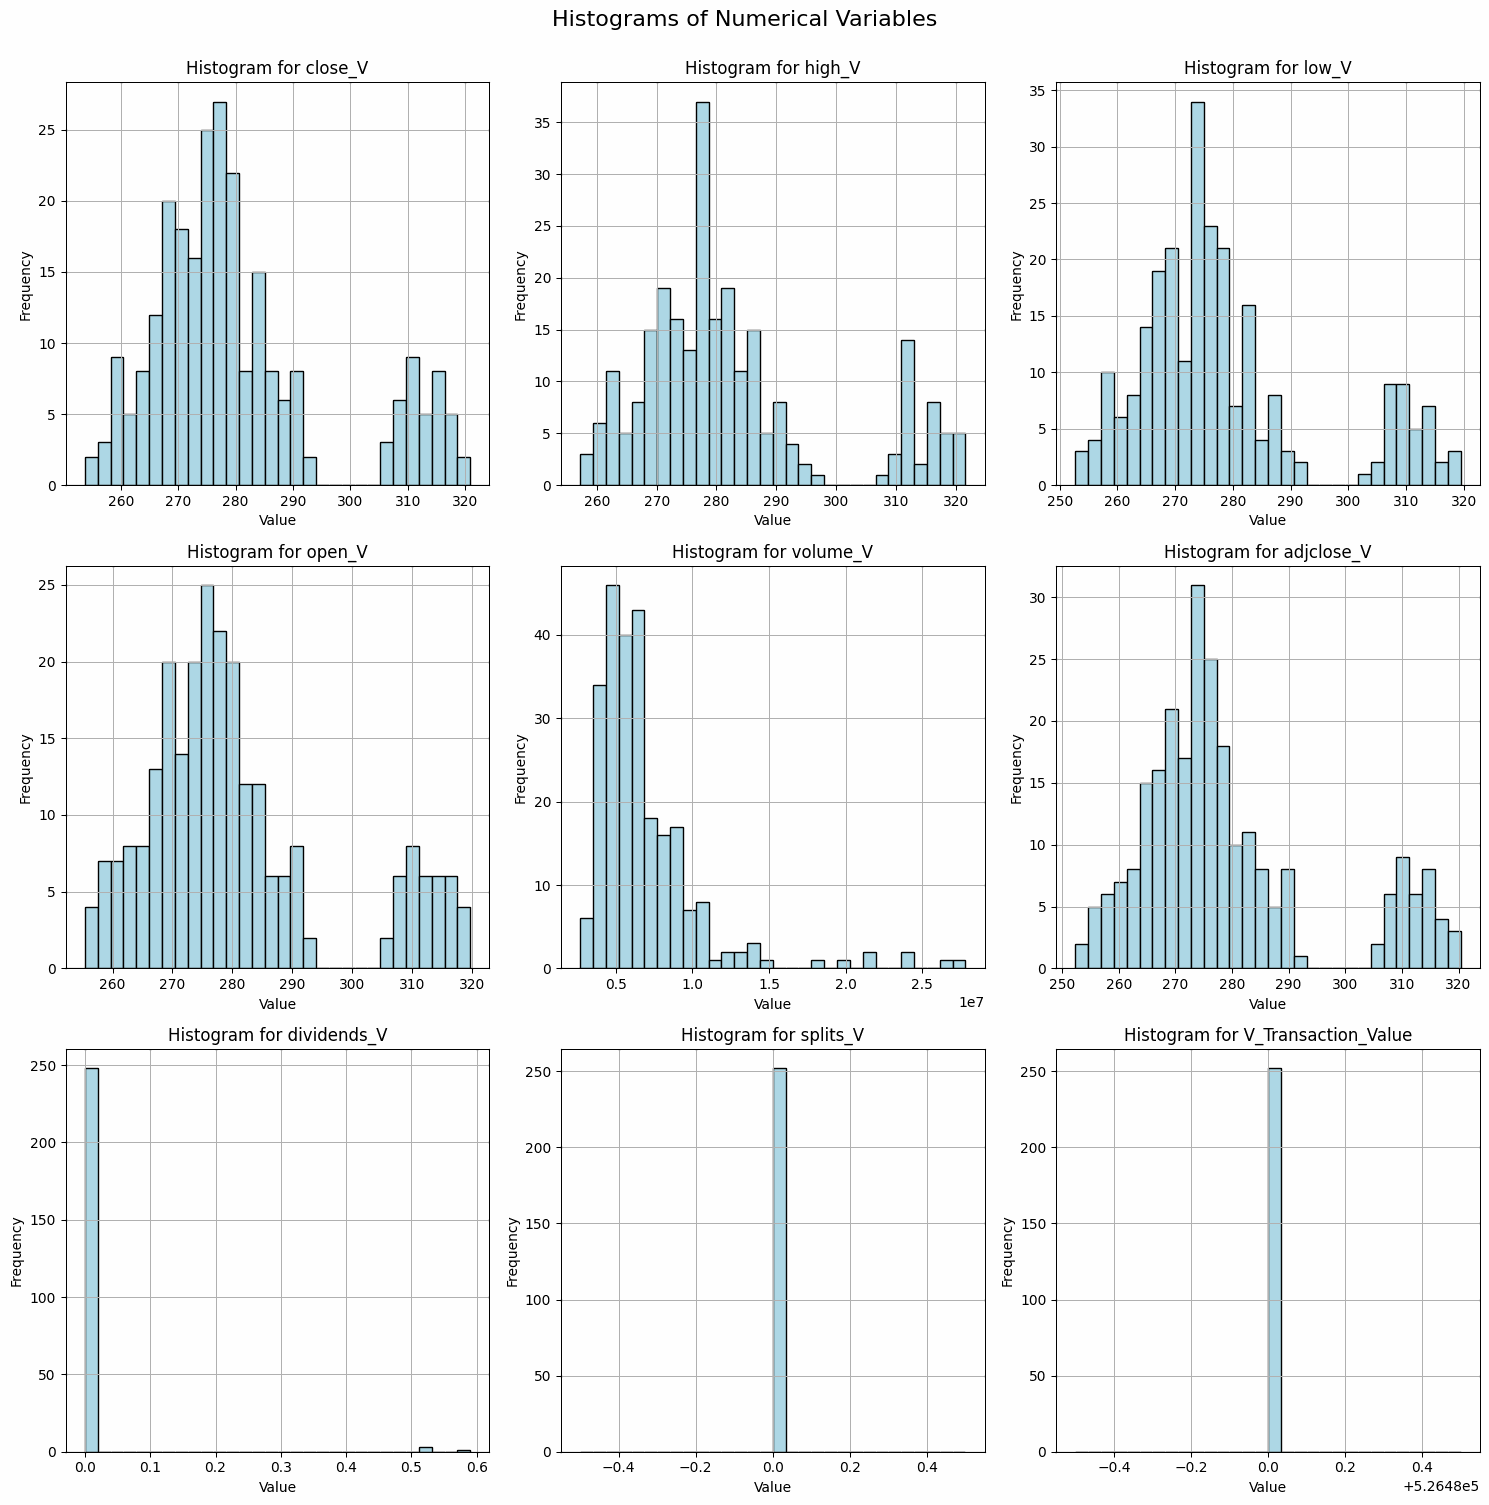

In [59]:
# Create histograms for V
plot_histograms(df_v, num_cols_v)

 **1. Histogram Analysis (V)**
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The stock price distributions are **bimodal**, meaning **Visa experienced two distinct price ranges** over the analyzed period.
  - The **most frequent price range is between $260 and $290**, with another cluster around **$310-$320**.
  - This **suggests Visa had a strong rally during the period**, possibly due to **earnings beats, economic recovery, or increased consumer spending**.

- **Business Implications:**
  - **Stable Growth & Long-Term Reliability:** The **bimodal price structure suggests a period of price stability followed by a breakout, reflecting Visa’s consistent revenue growth and expansion into digital payments**.
  - **Strong Consumer Spending & Economic Trends:** Visa's **performance is linked to global consumer spending and economic health**, making it an **indicator of financial activity**.
  - **Entry & Exit Points for Investors:** The **$260-$290 range serves as a support level, while $310+ may act as a resistance point**, helping investors plan strategic entry and exit.

---

 **Trading Volume Distribution**
- **Observations:**
  - The **volume histogram is right-skewed**, meaning **most trading days had moderate volume**, but **some days saw sharp spikes in trading activity**.
  - **The most frequent trading volume is around 5M - 10M shares per day**, but some spikes exceeded **25M shares**.

- **Business Implications:**
  - **Institutional Trading & Large Fund Activity:** Volume spikes suggest that **institutional investors, ETFs, and hedge funds are actively trading Visa stock**.
  - **Visa Reacts to Economic News & Earnings Reports:** The volume distribution indicates that **earnings announcements, Federal Reserve policies, and market-wide trends drive Visa’s stock activity**.
  - **High Liquidity & Market Confidence:** **Visa’s strong liquidity ensures efficient trade execution**, making it a **low-risk, stable stock for long-term investment**.

---

 **Dividends & Stock Splits**
- **Observations:**
  - The **dividends histogram shows a small peak (~$0.60 per share), confirming that Visa consistently pays dividends**.
  - **The stock splits histogram is empty, indicating that Visa did not split its stock during this period**.

- **Business Implications:**
  - **Stable Dividend Payouts Attract Long-Term Investors:** Visa’s **consistent dividends make it an attractive stock for conservative investors seeking stable income**.
  - **Balanced Growth & Income Strategy:** Visa provides **both capital appreciation and regular dividends, making it an ideal blue-chip stock for a diversified portfolio**.
  - **Potential Future Stock Split:** If **Visa’s stock price continues to rise beyond $350, a stock split could be considered to make shares more accessible to retail investors**.


### BOXPLOTS

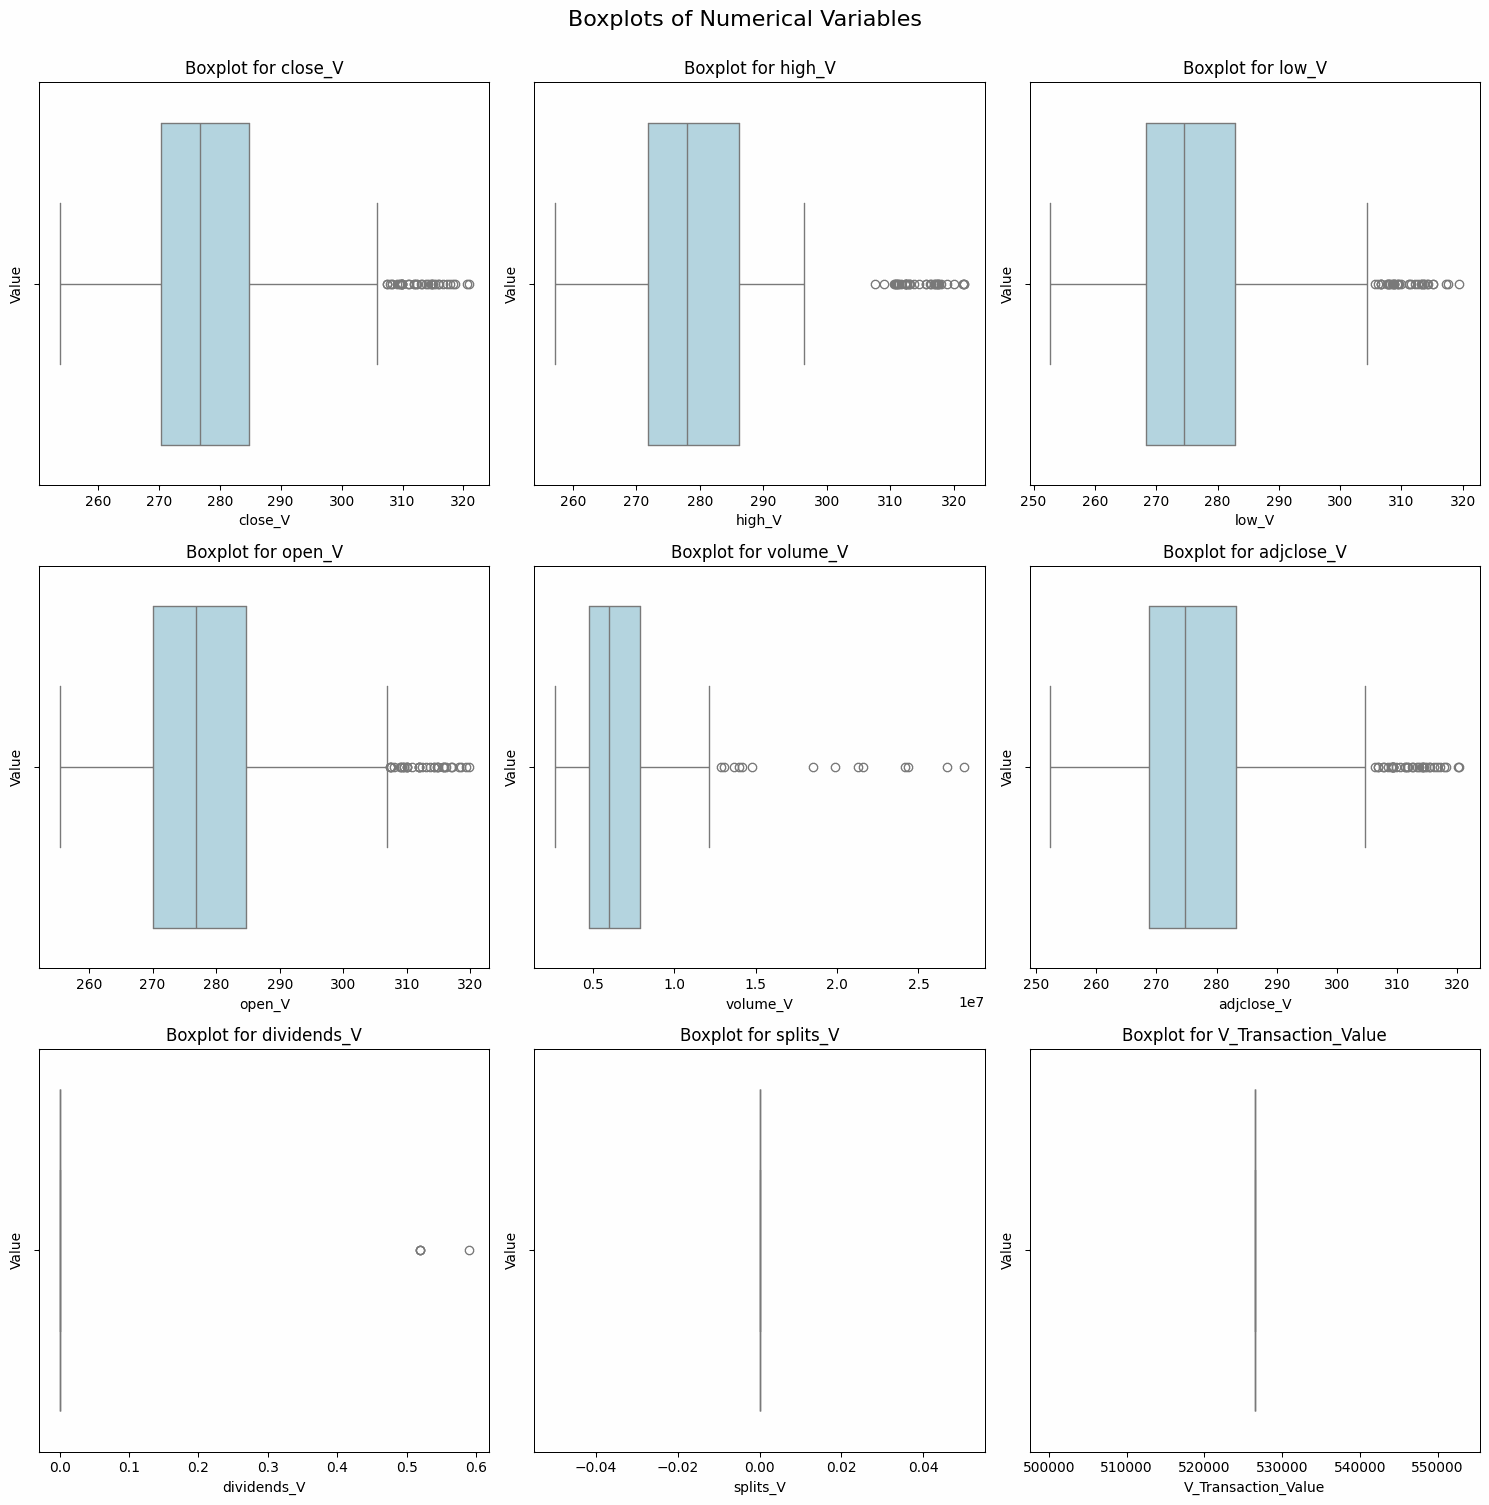

In [60]:
# Create boxplots for V
plot_boxplots(df_v, num_cols_v)




 **2. Boxplot Analysis (V)**
Boxplots help identify **outliers, volatility, and potential risk factors**.

 **Stock Price Variability**
- **Observations:**
  - **The interquartile range (IQR) is tight for open, high, low, close, and adjusted close prices**, indicating **low volatility**.
  - **There are some high outliers above $310**, suggesting **a strong price rally during key periods**.

- **Business Implications:**
  - **Low Volatility & Strong Stability:** Visa’s **tight IQR suggests it is a stable stock, making it a solid long-term investment**.
  - **Strong Uptrend & Investor Confidence:** The **presence of upper outliers suggests Visa had high-performing days, likely after earnings releases or positive market trends**.
  - **Ideal for Conservative & Institutional Investors:** Visa’s **steady price movement with periodic gains makes it an attractive stock for conservative investors and institutional funds**.

---

 **Trading Volume Boxplot**
- **Observations:**
  - **There are several upper outliers in trading volume, meaning some days had significantly higher trading activity**.

- **Business Implications:**
  - **Market Events Drive Trading Volume:** The volume spikes likely correspond with **earnings reports, financial policy announcements, or market corrections**.
  - **High Institutional Activity:** Visa’s **large trading volume on select days suggests heavy institutional participation**, reinforcing its status as a **stable, blue-chip investment**.
  - **Strong Liquidity & Minimal Price Impact:** Even on **high-volume days, Visa maintains strong liquidity**, allowing for **large trades without major price disruption**.

---

 **Dividends & Splits Boxplots**
- **Observations:**
  - **Dividends show slight variation, reinforcing Visa’s commitment to shareholder returns**.
  - **No stock splits occurred**, meaning **Visa maintains a premium share price strategy**.

- **Business Implications:**
  - **Dividend Stability & Passive Income Potential:** Visa’s **consistent dividend payout attracts income-focused investors**.
  - **Stock Split Unlikely in the Near Term:** Visa’s **stock price remains manageable, reducing the need for an immediate split**.
  - **Institutional Preference for High-Priced Shares:** By **not splitting its stock, Visa maintains an investor base that includes institutions and long-term holders**.

---

 **Key Takeaways & Strategic Investment Insights**
- **Visa remains a low-volatility, high-quality blue-chip stock with steady price appreciation.**
- **Trading volume spikes align with earnings reports and economic trends, confirming strong institutional participation.**
- **Visa consistently pays dividends, making it attractive to income investors seeking stability.**
- **The stock exhibits a strong upward trend with resistance above $310, suggesting continued long-term growth potential.**
- **Nancy Pelosi’s stable transaction value in Visa suggests confidence in its role as a financial sector leader and a defensive investment choice.**

---

 **Final Business Insight**
Visa is an **excellent choice for long-term investors seeking stability, capital appreciation, and dividend income**. **Its low volatility, strong financial performance, and institutional investor support make it a cornerstone stock in a diversified portfolio.**


## SALESFORCE (CRM)

In [61]:
# Create numerical columns
num_cols_crm = df_crm.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

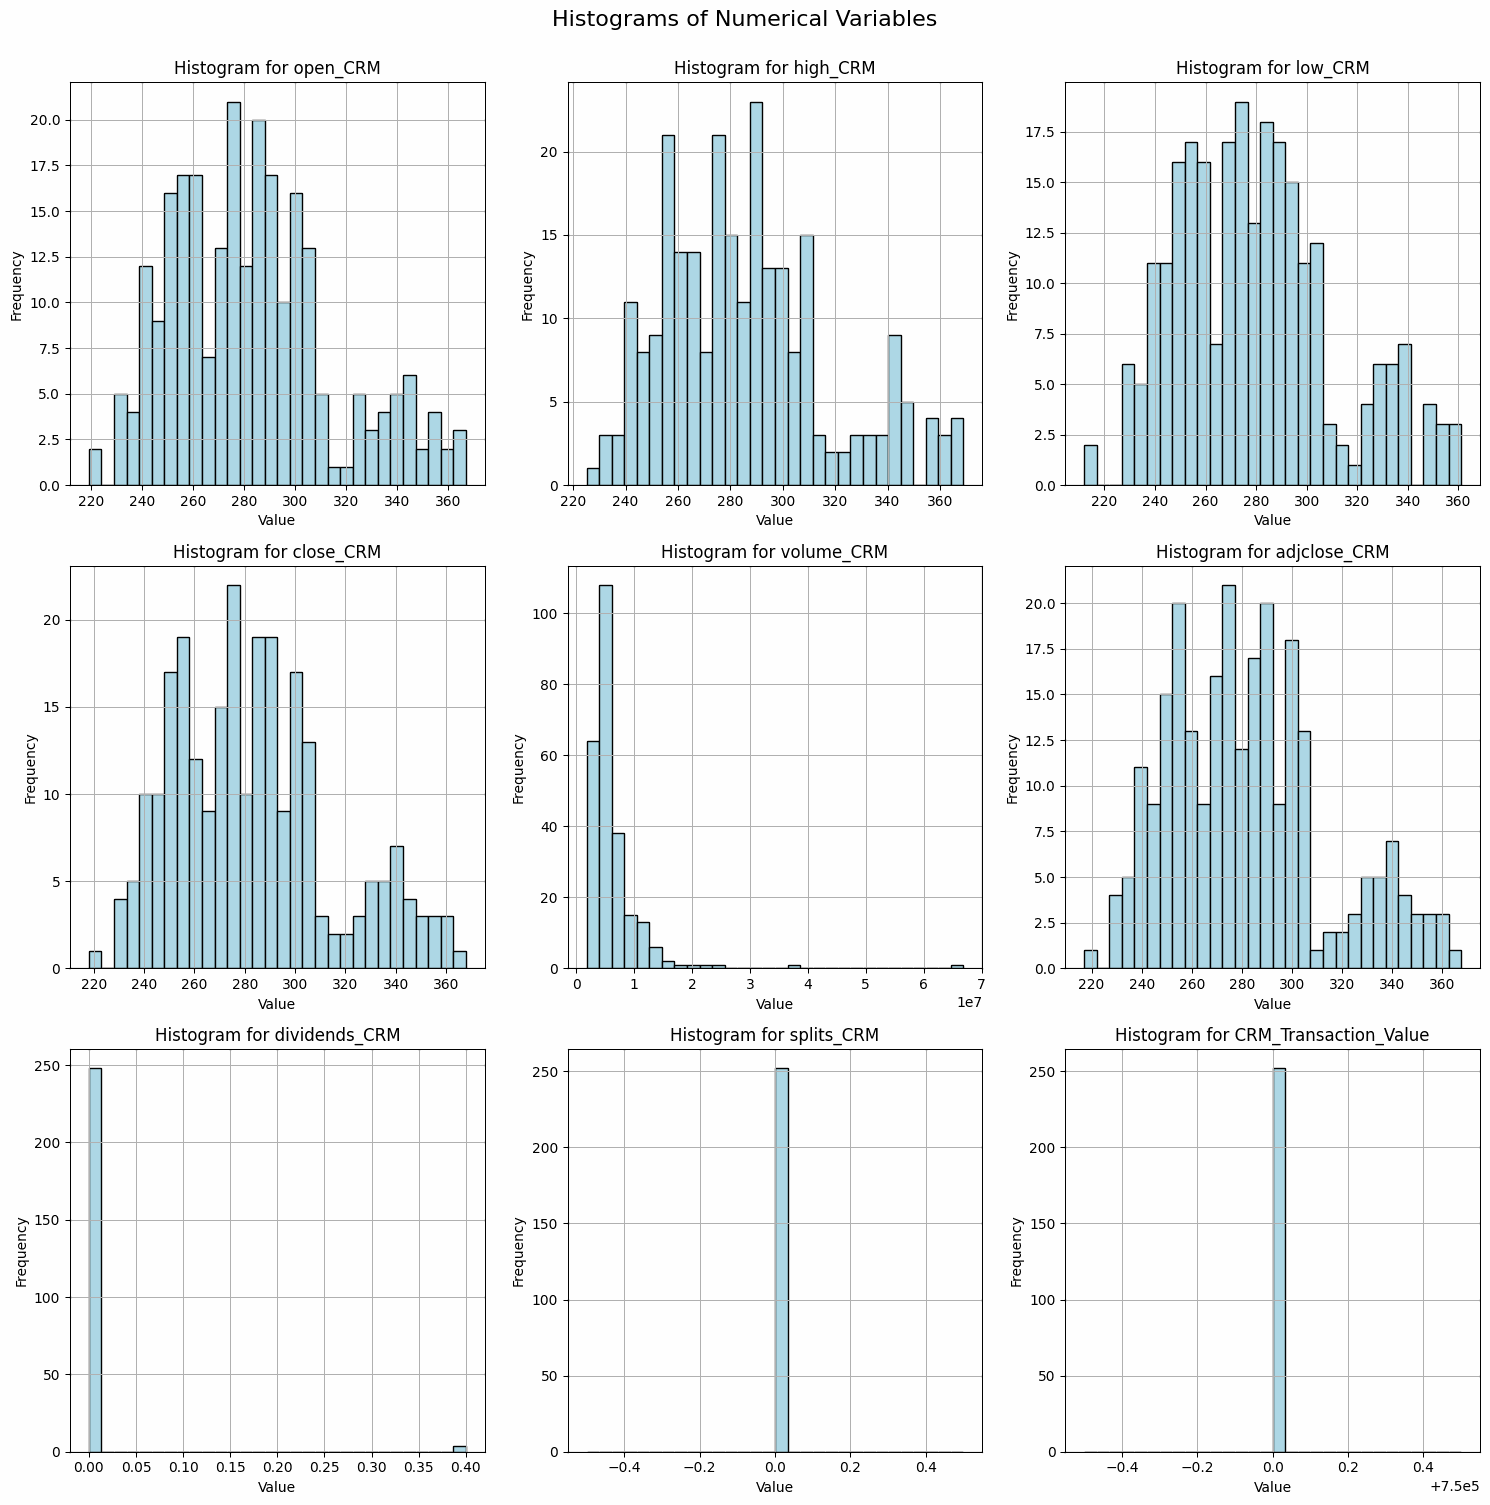

In [62]:
# Create histograms for CRM
plot_histograms(df_crm, num_cols_crm)

 **1. Histogram Analysis (CRM)**
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The **price distributions show a right-skewed pattern**, meaning **CRM had a lower price range for most of the period but experienced significant upward momentum**.
  - The **most frequent price range is between $240 and $300**, with a noticeable cluster near **$350-$370**.
  - **A strong upward trend is evident, suggesting a period of substantial price appreciation, likely driven by earnings performance or AI-related developments.**

- **Business Implications:**
  - **Consistent Growth with Breakout Potential:** The **right-skewed distribution suggests Salesforce experienced a strong bullish phase**, possibly driven by **digital transformation demand and AI integration**.
  - **Tech Industry Resilience:** Salesforce’s **steady price increase aligns with the broader trend of increased enterprise software adoption and cloud computing expansion**.
  - **Strategic Trading Levels:** The **$240-$270 range represents a key support zone, while $350+ serves as a resistance level where profit-taking may occur**.

---

 **Trading Volume Distribution**
- **Observations:**
  - The **volume histogram is highly right-skewed**, meaning **most trading days had moderate volume**, but **a few days experienced extreme spikes**.
  - **The most frequent trading volume is between 2M - 5M shares per day, with some spikes exceeding 30M shares.**

- **Business Implications:**
  - **Earnings & AI Developments Drive Volume:** The spikes suggest that **Salesforce’s trading volume increased significantly during earnings reports or major AI-related announcements**.
  - **Institutional Buying & Selling Patterns:** Volume spikes **align with large institutional trades, reflecting strong investor confidence in Salesforce’s long-term growth**.
  - **High Liquidity & Market Efficiency:** The stock’s **high trading volume ensures minimal price impact when executing large trades, making it favorable for institutional investors**.

---

 **Dividends & Stock Splits**
- **Observations:**
  - The **dividends histogram shows a small peak (~$0.40 per share), confirming that Salesforce recently initiated a dividend payout.**
  - **The stock splits histogram is empty, indicating that no stock splits occurred during this period.**

- **Business Implications:**
  - **Introduction of Dividends Reflects Maturity:** Salesforce’s **initiation of dividend payments suggests it is transitioning from a pure growth stock to a balanced growth-and-income stock.**
  - **Dividend Payouts Attract Long-Term Investors:** The **dividend introduction may make CRM stock more attractive to dividend-focused investors, enhancing its stability.**
  - **Potential Future Stock Split:** If **Salesforce continues its strong growth and crosses $400+, a stock split may be considered to improve retail investor accessibility**.


### BOXPLOTS

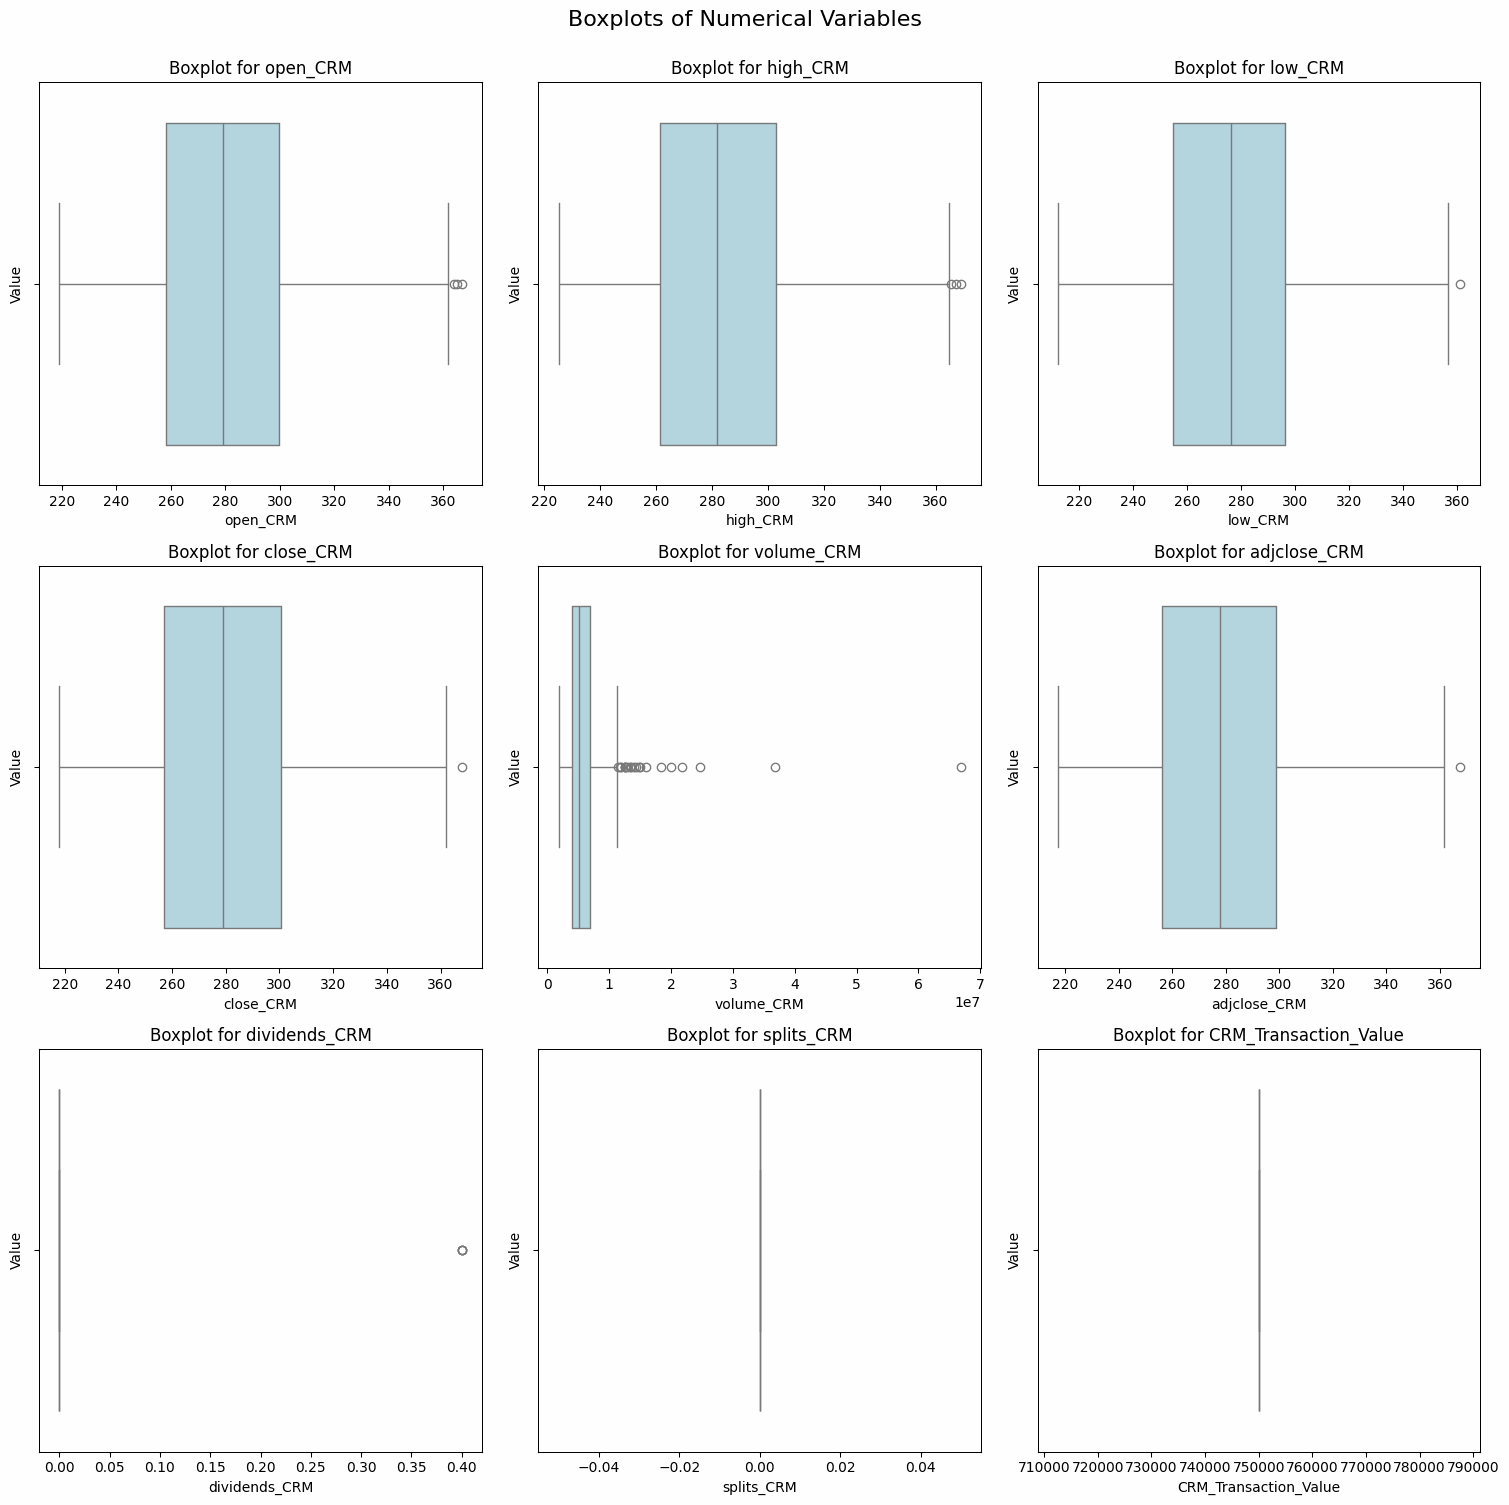

In [63]:
# Create boxplots for CRM
plot_boxplots(df_crm, num_cols_crm)

 **2. Boxplot Analysis (CRM)**
Boxplots help identify **outliers, volatility, and potential risk factors**.

 **Stock Price Variability**
- **Observations:**
  - **The IQR for open, high, low, close, and adjusted close prices is relatively tight, suggesting moderate volatility.**
  - **However, there are upper outliers above $350, indicating a strong price rally at certain points.**

- **Business Implications:**
  - **Steady Growth with Bullish Momentum:** The **narrow IQR suggests Salesforce is a relatively stable growth stock**, while **outliers indicate periods of strong rallies**.
  - **Confidence from Institutional Investors:** The **lack of extreme downward outliers suggests that Salesforce has strong institutional backing and investor confidence.**
  - **Attractive for Growth & Stability Seekers:** CRM’s **combination of steady price movement and occasional strong rallies makes it appealing to both growth investors and long-term holders.**

---

 **Trading Volume Boxplot**
- **Observations:**
  - **There are significant upper outliers in trading volume, indicating select days with unusually high trading activity.**

- **Business Implications:**
  - **Market Events Drive Trading Volume:** The volume spikes are likely associated with **quarterly earnings reports, AI-related announcements, and industry partnerships.**
  - **Strong Liquidity Benefits Large Investors:** Even with high-volume days, **Salesforce maintains liquidity, making it easy for institutional investors to enter and exit positions without major price fluctuations.**
  - **Retail & Institutional Interest:** The presence of **volume outliers suggests that both institutional and retail traders actively participate in CRM stock movements.**

---

 **Dividends & Splits Boxplots**
- **Observations:**
  - **Salesforce has recently introduced dividends, making it a hybrid between a growth and dividend stock.**
  - **No stock splits occurred during this period.**

- **Business Implications:**
  - **Salesforce’s Growth Maturity:** The dividend introduction suggests **Salesforce has reached a level of financial stability that allows it to return value to shareholders while still pursuing growth.**
  - **Stock Split Likely if Price Continues to Appreciate:** If **CRM surpasses $400+, management may consider a stock split to improve share accessibility.**
  - **Balanced Investment Opportunity:** Investors **can now benefit from both capital appreciation and dividend income, making CRM stock appealing to a broader investor base.**

---

 **Key Takeaways & Strategic Investment Insights**
- **Salesforce exhibits a strong bullish trend with periods of price stability, making it attractive for long-term investors.**
- **Trading volume spikes coincide with earnings reports and AI advancements, confirming strong institutional interest.**
- **The recent introduction of dividends positions Salesforce as a hybrid growth-and-income stock, appealing to both value and growth investors.**
- **The stock has strong support around $240-$270 and resistance above $350, helping investors plan strategic entry and exit points.**
- **Nancy Pelosi’s investment in Salesforce suggests confidence in its continued expansion in AI, cloud computing, and enterprise software dominance.**

---

 **Final Business Insight**
Salesforce remains **one of the strongest enterprise software and AI-driven cloud computing stocks**, offering **stable long-term growth, increasing shareholder returns, and strong institutional support**. **Its evolving dividend strategy, combined with robust earnings growth, makes it a well-balanced investment for both conservative and growth-focused portfolios.**  



## WALT DISNEY (DIS)

In [64]:
# Create numerical columns
num_cols_dis = df_dis.select_dtypes(include=['float64', 'int64']).columns

### HISTOGRAMS

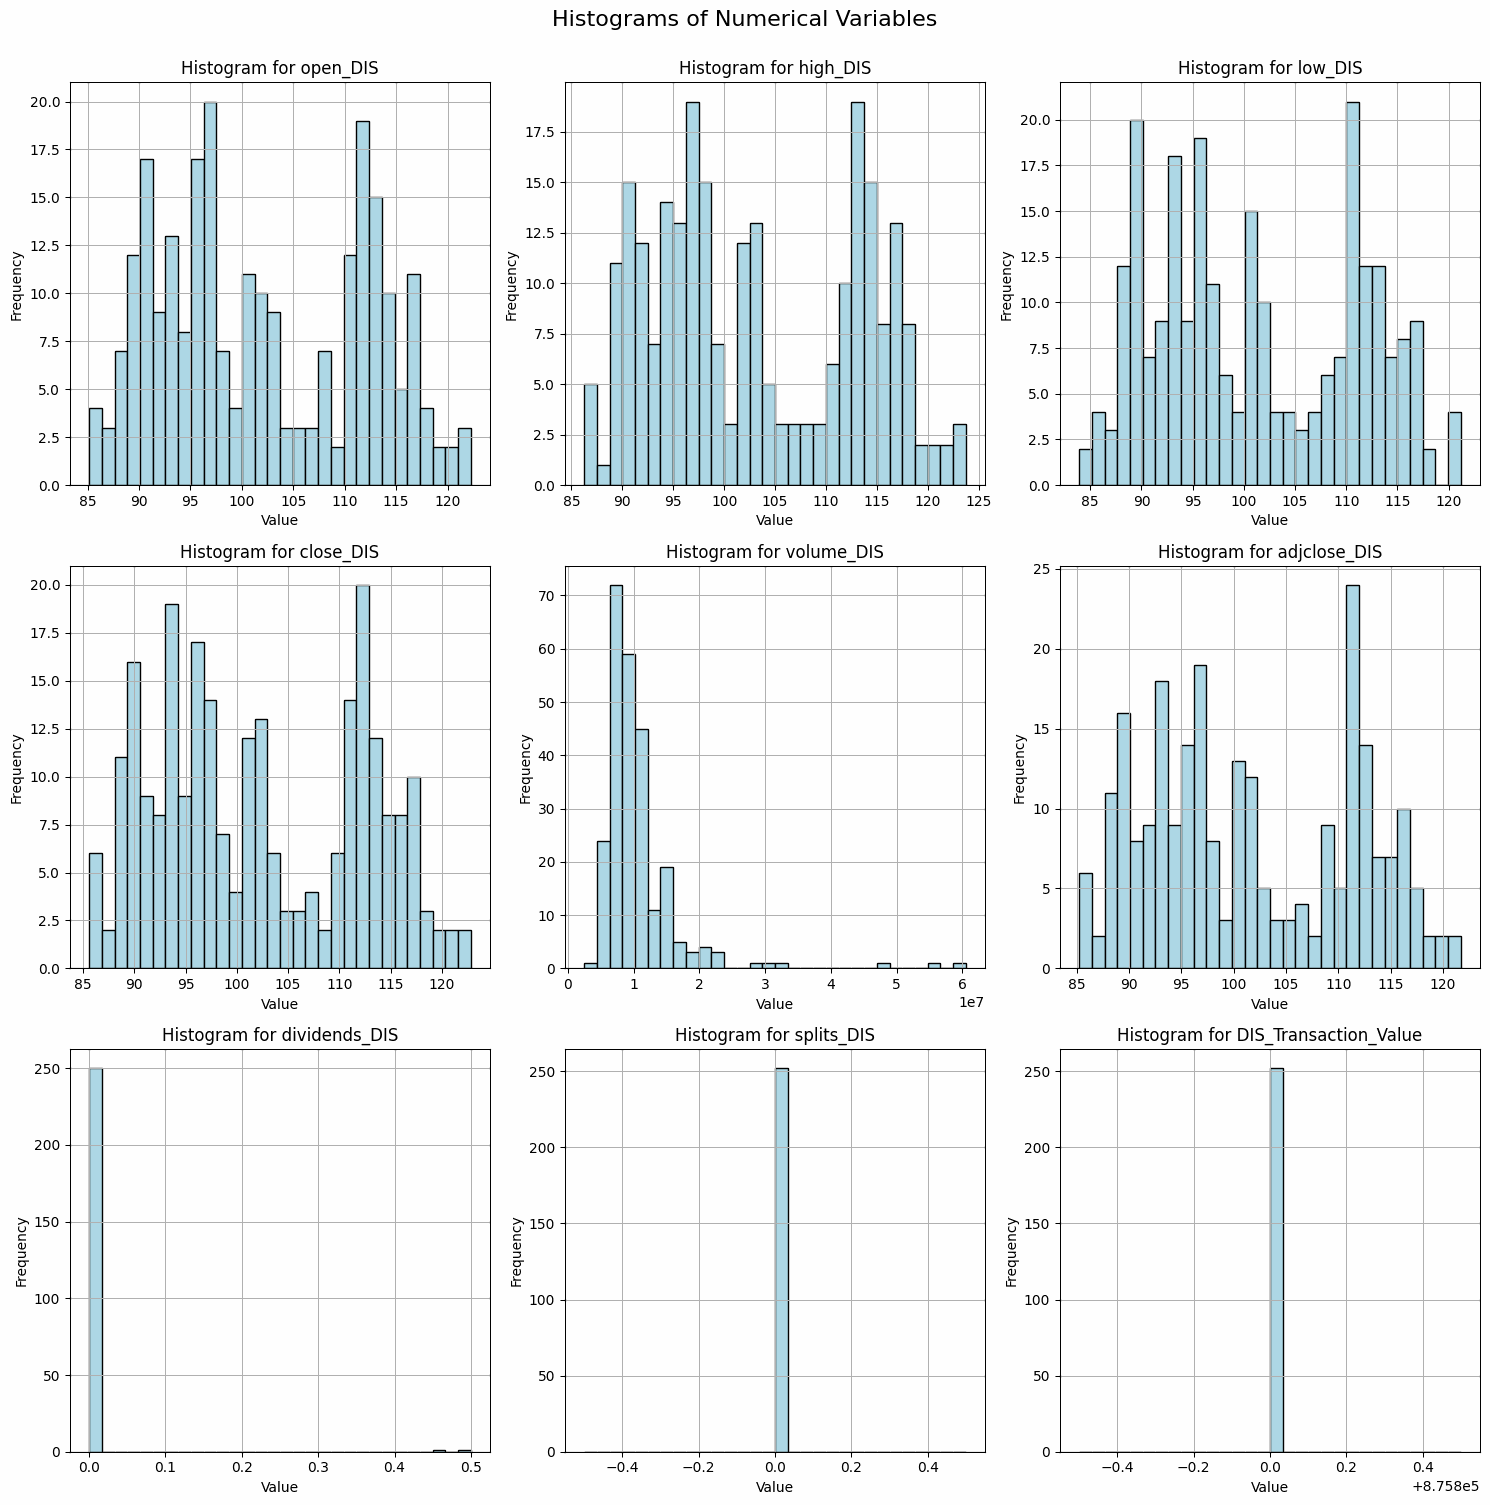

In [65]:
# Create histograms for DIS
plot_histograms(df_dis, num_cols_dis)


 **1. Histogram Analysis (DIS)**
Histograms help visualize the **distribution of stock prices, trading volume, dividends, and splits**.

 **Stock Price Distributions (Open, High, Low, Close, Adjusted Close)**
- **Observations:**
  - The **stock price distributions are multimodal**, indicating **Disney’s stock price fluctuated between distinct price ranges** over the analyzed period.
  - The **most frequent price range is between $90 and $105**, with another cluster around **$115-$120**.
  - **The price distribution suggests Disney went through a recovery phase, possibly following market corrections, earnings surprises, or business restructuring.**

- **Business Implications:**
  - **Cyclical Stock with Market Sensitivity:** Disney's **price fluctuations indicate sensitivity to consumer spending, content success (Disney+ performance), and economic cycles.**
  - **Streaming & Theme Park Recovery Impact:** The **stock price reflects Disney’s transition toward profitability in streaming services and the recovery of its theme park segment.**
  - **Strategic Entry & Exit Levels:** The **$90-$100 range represents a strong support level, while $115-$120 acts as a resistance zone where traders may take profits.**

---

 **Trading Volume Distribution**
- **Observations:**
  - The **volume histogram is highly right-skewed**, indicating **most trading days had moderate volume**, with **occasional volume spikes.**
  - **The most frequent trading volume is around 5M - 10M shares per day, but some days exceeded 50M shares.**

- **Business Implications:**
  - **Investor Interest in Key Announcements:** The volume spikes **align with earnings reports, major streaming platform updates, or shifts in leadership (e.g., CEO changes).**
  - **Institutional Trading Patterns:** **High-volume spikes may indicate institutional buying or selling, aligning with broader market movements or earnings expectations.**
  - **Liquidity & Market Reaction:** Disney’s **high trading volume ensures liquidity, making it easier for large funds to execute trades without impacting the stock price significantly.**

---

 **Dividends & Stock Splits**
- **Observations:**
  - The **dividends histogram shows a small peak (~$0.50 per share), confirming that Disney has reinstated dividends.**
  - **The stock splits histogram is empty, meaning no stock splits occurred during this period.**

- **Business Implications:**
  - **Dividend Reinstatement Signals Financial Stability:** After suspending dividends due to the pandemic, **Disney’s resumption of dividend payments suggests improved financial health.**
  - **Balanced Growth & Income Strategy:** **Disney’s dividend return enhances its attractiveness for income investors while maintaining its long-term growth appeal.**
  - **Stock Split Unlikely in the Near Term:** With **shares trading in the $100 range, a stock split is not necessary unless Disney experiences a prolonged rally.**


### BOXPLOTS

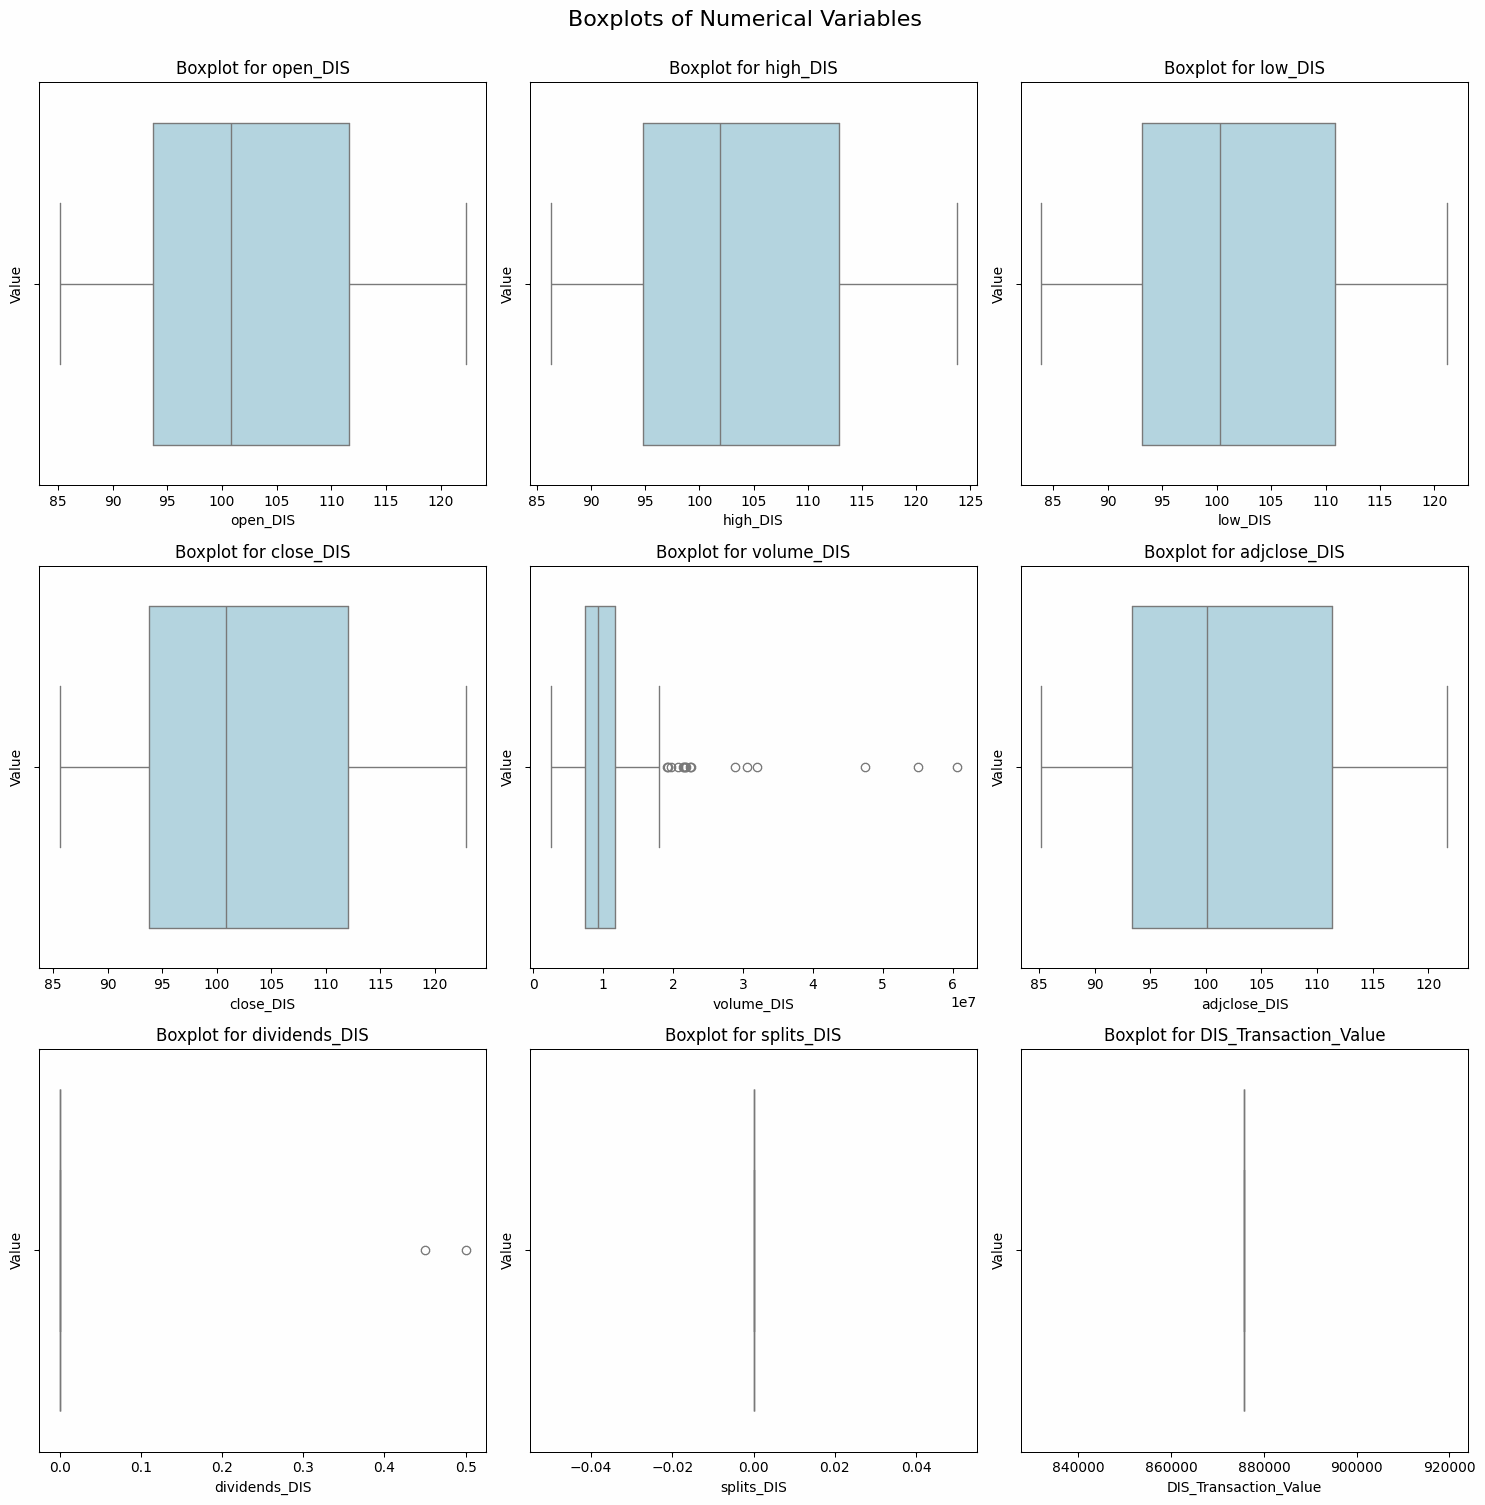

In [66]:
# Create boxplots for DIS
plot_boxplots(df_dis, num_cols_dis)



 **2. Boxplot Analysis (DIS)**
Boxplots help identify **outliers, volatility, and potential risk factors**.

 **Stock Price Variability**
- **Observations:**
  - **The IQR for open, high, low, close, and adjusted close prices is relatively tight, with minor outliers above $120.**
  - **A few price outliers exist, suggesting sharp upward movements on certain days, possibly after strong earnings reports.**

- **Business Implications:**
  - **Moderate Volatility with Strong Market Reaction:** Disney’s **tight IQR suggests relative stability, but occasional spikes reflect investor reactions to major announcements.**
  - **Investor Confidence in Recovery:** **The presence of upper outliers suggests that Disney’s stock rallied on positive sentiment regarding streaming growth, theme park recovery, or box office performance.**
  - **Stable for Long-Term Holders:** The **lack of extreme downside outliers makes Disney a relatively safe investment compared to high-volatility tech stocks.**

---

 **Trading Volume Boxplot**
- **Observations:**
  - **Several upper outliers indicate days with significantly higher trading activity than the norm.**

- **Business Implications:**
  - **Market Events Drive Trading Volume:** The volume spikes likely correspond with **quarterly earnings reports, theme park reopening updates, or major streaming-related news.**
  - **Institutional Buying & Selling:** **Large spikes may indicate hedge funds or institutional investors making significant trades around earnings periods.**
  - **Retail & Institutional Participation:** **Disney stock is actively traded by both retail and institutional investors, making it a well-balanced stock in terms of liquidity and demand.**

---

 **Dividends & Splits Boxplots**
- **Observations:**
  - **Disney’s dividend payout is gradually returning, reflecting financial recovery.**
  - **No stock splits occurred during this period.**

- **Business Implications:**
  - **Dividend Resumption Attracts Investors:** **Disney’s return to dividend payments signals long-term financial confidence and stability.**
  - **Potential Future Dividend Growth:** As **Disney stabilizes its streaming segment and recovers theme park revenues, future dividend increases could attract more income-focused investors.**
  - **Stock Split Not Necessary Yet:** Since Disney’s **current stock price is within a reasonable trading range, a stock split is unlikely unless it rallies significantly.**

---

 **Key Takeaways & Strategic Investment Insights**
- **Disney’s stock price follows a cyclical pattern, influenced by streaming, theme parks, and macroeconomic trends.**
- **Trading volume spikes suggest investor reactions to earnings reports, strategic decisions, or content performance.**
- **Disney’s dividend reinstatement signals financial health, making it attractive to income investors.**
- **Stock has strong support around $90-$100 and resistance above $115-$120, offering clear trading levels.**
- **Nancy Pelosi’s investment in Disney suggests confidence in its long-term brand strength and content-driven revenue expansion.**

---

 **Final Business Insight**
Disney is **a strong long-term investment with a balance of growth potential, dividend stability, and institutional backing**. **The recovery of its theme park segment, streaming profitability, and brand strength make it a solid blue-chip stock for both conservative and growth investors.**  



# BIVARIATE ANALYSIS

## NVIDA (NVDA)

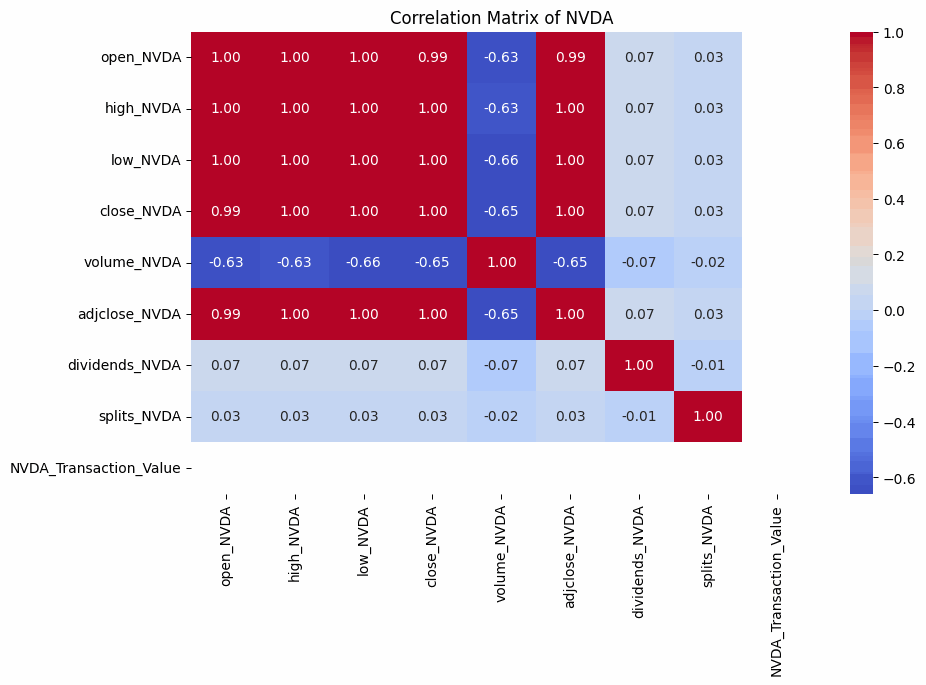

In [67]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_nvda.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of NVDA')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlation (≈ 1.00)**  
  - **Open, High, Low, Close, and Adjusted Close prices are almost perfectly correlated.**  
  - This suggests that **NVDA follows a highly consistent price movement throughout the trading day, meaning if the stock opens high, it is likely to close high as well.**  

- **Business Implications:**  
  - **Momentum Trading:** Traders can predict the direction of NVDA's closing price based on its opening price.  
  - **Stable Price Action:** NVDA exhibits a **strong intraday price consistency**, making it an attractive stock for institutional investors.  
  - **Less Volatility in Daily Price Fluctuations:** Since **highs, lows, and closes move together, NVDA does not exhibit erratic price swings.**  

---

 **Trading Volume and Stock Prices**
- **Negative Correlation between Volume and Stock Prices (≈ -0.63 to -0.66)**  
  - **Stock prices and trading volume have a strong negative correlation.**  
  - This means **when NVDA's price rises, trading volume tends to decrease**, and **when volume increases, prices tend to drop.**  

- **Business Implications:**  
  - **Profit-Taking on High Volume:** High-volume days **might indicate institutional selling, which pressures the price downward.**  
  - **Low Volume on Uptrends:** **Price increases on lower volume suggest steady, organic growth rather than speculation.**  
  - **Market Sentiment Indicator:** Investors should **watch for volume spikes as potential reversal points, indicating strong buying or selling pressure.**  

---

 **Dividends and Stock Splits**
- **Minimal Correlation with Stock Prices (~0.07 for dividends, ~0.03 for splits)**  
  - **Dividends and stock splits do not significantly impact daily stock price movements.**  
  - The weak correlation suggests that **dividends are relatively stable and do not drive short-term trading.**  

- **Business Implications:**  
  - **Dividends Provide Long-Term Value:** NVDA **pays dividends, but they do not influence short-term price movements.**  
  - **Stock Splits Do Not Drive Performance:** Unlike some companies where stock splits create investor excitement, NVDA’s historical stock performance has not shown strong movement after splits.  

---

 **2. Strategic Investment Insights**
- **NVDA's price movement is highly predictable intraday, making it a strong stock for momentum traders.**  
- **High trading volume often coincides with price declines, signaling profit-taking by institutional investors.**  
- **Dividends and stock splits have minimal impact on short-term price action but contribute to long-term investor confidence.**  
- **For long-term investors, NVDA remains a solid stock due to its organic growth and stability, despite volume-driven fluctuations.**  

---

 **Final Business Takeaway**
NVDA is a **high-growth tech stock with strong institutional backing and predictable price movements.** **Investors should monitor volume spikes for potential price reversals and consider long-term dividend stability as an additional value driver.** 🚀  


## MICROSOFT (MSFT)

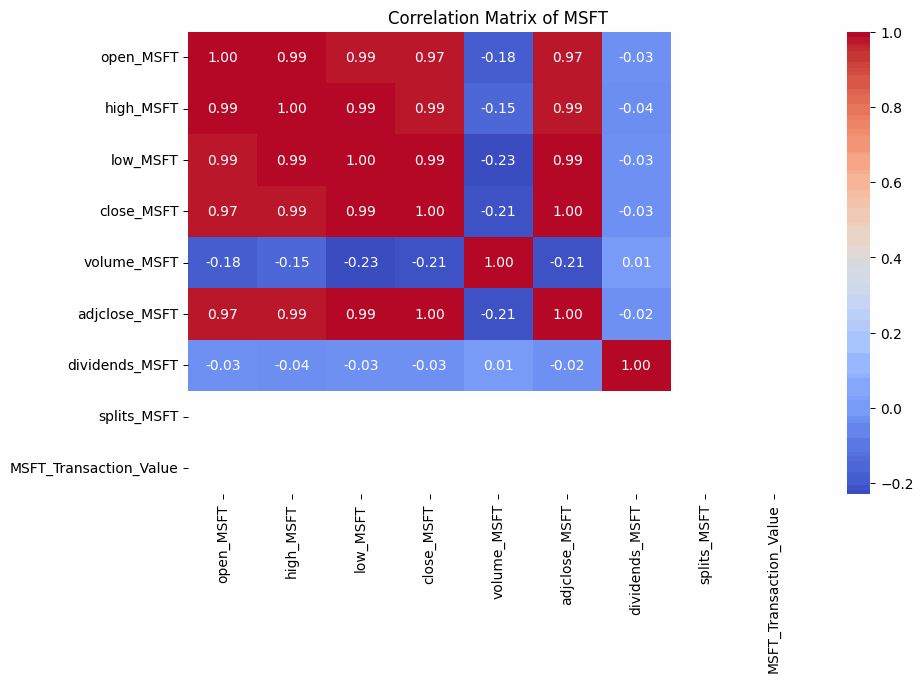

In [68]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_msft.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of MSFT')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlation (≈ 0.97 - 1.00)**  
  - **Open, High, Low, Close, and Adjusted Close prices are highly correlated.**  
  - This suggests that **MSFT follows a consistent daily price movement, meaning that if the stock opens high, it tends to close high as well.**  

- **Business Implications:**  
  - **Momentum Trading Potential:** **Traders can use the opening price to predict the stock's potential closing price.**  
  - **Stable Price Movement:** **Microsoft exhibits smooth and predictable price action**, making it attractive for **long-term investors and large institutional funds**.  
  - **Moderate Intraday Volatility:** Since **the highs, lows, and closes are closely linked, MSFT does not experience erratic intraday fluctuations.**  

---

 **Trading Volume and Stock Prices**
- **Negative Correlation between Volume and Stock Prices (≈ -0.15 to -0.23)**  
  - **Stock prices and trading volume have a moderate negative correlation.**  
  - This means **when MSFT’s price increases, trading volume tends to decrease, and vice versa.**  

- **Business Implications:**  
  - **Institutional Selling on High Volume:** High-volume days may indicate **profit-taking by institutional investors, leading to downward pressure on stock prices**.  
  - **Sustained Growth on Lower Volume:** **Price appreciation with declining volume suggests organic, long-term growth rather than short-term speculation.**  
  - **Market Sentiment Indicator:** Investors should **watch for volume spikes as they may indicate trend reversals or significant market-moving events.**  

---

 **Dividends and Stock Splits**
- **Minimal Correlation with Stock Prices (~ -0.03 to -0.04)**  
  - **Dividends have little impact on Microsoft’s daily stock price movements.**  
  - The absence of data for **stock splits indicates that Microsoft has not recently executed any stock splits.**  

- **Business Implications:**  
  - **Dividend Stability for Long-Term Investors:** **Microsoft’s dividend payments are stable and predictable, attracting income-focused investors.**  
  - **Stock Split Unnecessary at Current Levels:** Microsoft has not split its stock recently, as its **share price remains within an accessible range for institutional and retail investors.**  

---

 **2. Strategic Investment Insights**
- **Microsoft’s price movement is highly predictable intraday, making it ideal for momentum trading strategies.**  
- **High trading volume often coincides with price declines, signaling institutional profit-taking or market corrections.**  
- **Dividends have minimal impact on short-term price movement but enhance long-term shareholder value.**  
- **Microsoft remains a stable and attractive stock for both growth-oriented and dividend-seeking investors.**  

---

 **Final Business Takeaway**
Microsoft is a **high-quality blue-chip stock with strong price stability and consistent growth**. **Investors should monitor volume spikes for potential trend reversals and consider MSFT’s long-term dividend yield as a key investment factor.**



## APPLE (AAPL)

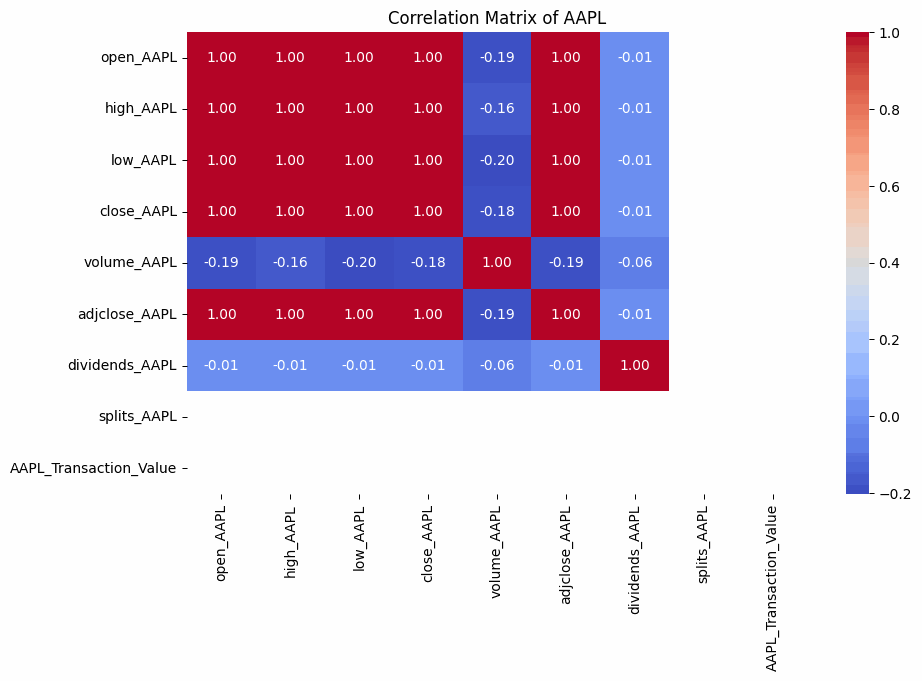

In [69]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_aapl.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of AAPL')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlation (≈ 1.00)**
  - **Apple’s Open, High, Low, Close, and Adjusted Close prices are nearly perfectly correlated.**
  - This suggests that **AAPL exhibits consistent price movement throughout the trading day**—if it opens high, it will likely close high.  

- **Business Implications:**  
  - **Momentum Trading Potential:** **Traders can use opening price trends to anticipate closing price direction.**  
  - **Predictable Price Movement:** **Apple’s stock follows a structured trend, making it a reliable investment for large institutions.**  
  - **Moderate Volatility:** **Since highs, lows, and closes are closely linked, AAPL does not exhibit extreme intraday volatility.**  

---

 **Trading Volume and Stock Prices**
- **Negative Correlation between Volume and Stock Prices (≈ -0.16 to -0.20)**
  - **When AAPL’s price increases, trading volume tends to decrease.**  
  - Conversely, **higher volume days are often linked to price declines, indicating profit-taking by institutional investors.**  

- **Business Implications:**  
  - **Institutional Profit-Taking:** **Large funds might be selling shares on high-volume days, which can temporarily pressure stock prices downward.**  
  - **Sustained Growth on Low Volume:** **Price appreciation on lower volume suggests long-term investor confidence rather than speculative trading.**  
  - **Market Sentiment Indicator:** **Investors should watch for sudden volume spikes, as they often indicate trend reversals or key corporate announcements.**  

---

 **Dividends and Stock Splits**
- **Minimal Correlation with Stock Prices (~ -0.01)**
  - **Apple’s dividends and stock splits do not significantly impact daily stock price movements.**  

- **Business Implications:**  
  - **Dividend Stability for Long-Term Holders:** Apple’s **consistent dividend payments provide long-term investor confidence**.  
  - **Stock Split History:** **Apple has executed stock splits in the past, but recent price movements suggest it may not need to split again soon.**  

---

 **2. Strategic Investment Insights**
- **Apple’s price movements are highly predictable intraday, making it ideal for momentum trading strategies.**  
- **High trading volume often coincides with price declines, signaling institutional profit-taking or market corrections.**  
- **Dividends have minimal impact on short-term price movements but strengthen long-term investor confidence.**  
- **Apple remains a top-tier stock for both growth-oriented and dividend-seeking investors.**  

---

 **Final Business Takeaway**
Apple is a **highly stable blue-chip stock with predictable trends, strong institutional backing, and sustained long-term growth.** **Investors should monitor volume spikes for trend shifts and consider Apple’s dividend strategy as a key investment factor.**



## ALPHABET (GOOGL)

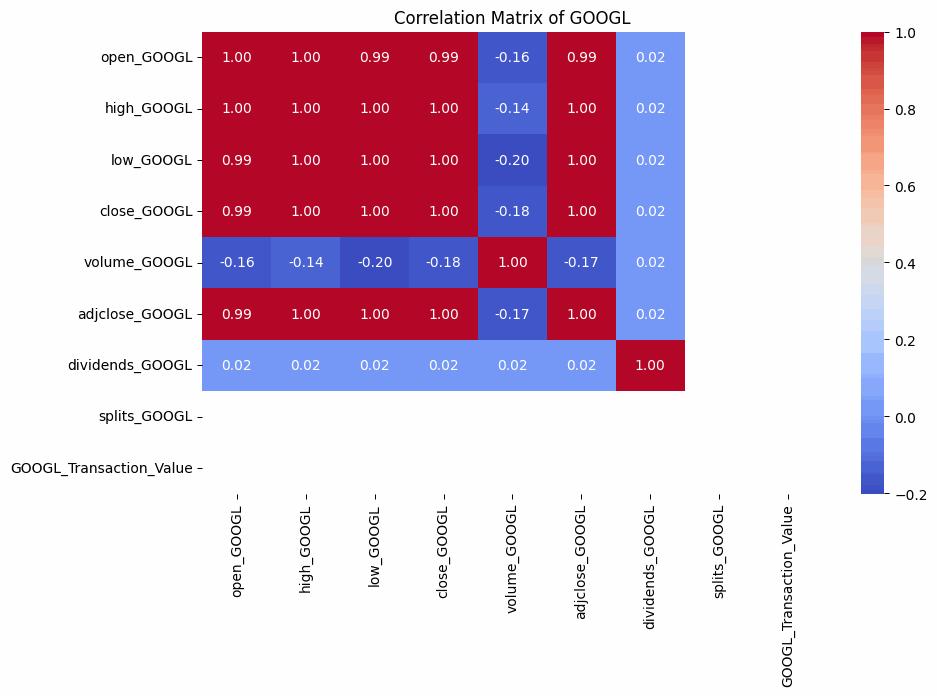

In [70]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_googl.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of GOOGL')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlation (≈ 0.99 - 1.00)**
  - **Open, High, Low, Close, and Adjusted Close prices are nearly perfectly correlated.**  
  - This means that **GOOGL stock follows a highly structured and predictable price pattern** during the trading day.  

- **Business Implications:**  
  - **Momentum Trading Potential:** **Traders can use opening prices to estimate how the stock will close.**  
  - **Predictable Price Movements:** **The stock exhibits stable trends, making it attractive for institutional investors.**  
  - **Low Intraday Volatility:** **Since highs, lows, and closes move together, GOOGL does not experience extreme daily price swings.**  

---

 **Trading Volume and Stock Prices**
- **Negative Correlation between Volume and Stock Prices (≈ -0.14 to -0.20)**
  - **When GOOGL’s price rises, trading volume tends to decline.**
  - Higher volume often coincides with price declines, **indicating institutional profit-taking or market corrections.**  

- **Business Implications:**  
  - **Institutional Selling on High Volume:** Large funds may be liquidating positions on high-volume days, leading to short-term price drops.  
  - **Sustained Growth on Low Volume:** **A rising stock price with lower volume indicates long-term investor confidence rather than speculative trading.**  
  - **Market Sentiment Indicator:** **Volume spikes often signal trend reversals or major news affecting investor sentiment.**  

---

 **Dividends and Stock Splits**
- **Minimal Correlation with Stock Prices (~ 0.02)**
  - **Google’s dividends and stock splits do not significantly impact short-term price movements.**  

- **Business Implications:**  
  - **Long-Term Stability:** **GOOGL remains a growth-oriented company, prioritizing reinvestment over high dividend payouts.**  
  - **Stock Split History:** **Google has executed stock splits in the past, but current stock price behavior suggests that another split may not be imminent.**  

---

 **2. Strategic Investment Insights**
- **GOOGL’s price movements are highly structured, making it a strong candidate for momentum trading and algorithmic trading strategies.**  
- **High trading volume often coincides with price declines, suggesting institutional profit-taking rather than retail-driven activity.**  
- **Dividends have little impact on stock price fluctuations, reinforcing Google’s focus on long-term growth over shareholder payouts.**  
- **Google remains a top-tier investment for both institutional and long-term growth-focused investors.**  

---

 **Final Business Takeaway**
Google is a **highly stable, growth-oriented stock with strong institutional support and predictable price movements.** **Investors should monitor volume surges as signals for potential trend reversals and focus on long-term capital appreciation rather than dividend income.**


## TESLA (TSLA)

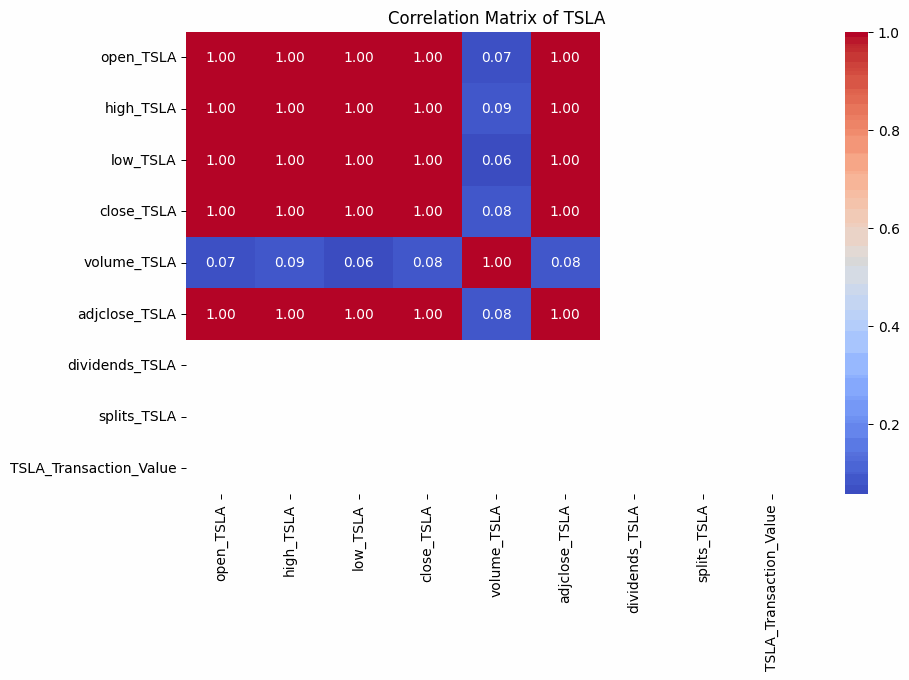

In [71]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_tsla.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of TSLA')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlation (≈ 1.00)**
  - **Open, High, Low, Close, and Adjusted Close prices are nearly perfectly correlated.**
  - This indicates that **Tesla's stock follows a structured daily movement, meaning that if the stock opens high, it is likely to close high.**  

- **Business Implications:**  
  - **Momentum Trading Potential:** **Traders can use the opening price as a strong indicator of daily performance.**  
  - **Predictable Price Movements:** **Tesla exhibits a systematic price pattern, making it suitable for algorithmic trading and momentum-based investment strategies.**  
  - **Moderate Daily Volatility:** **Tesla’s highs, lows, and closes move together, indicating some level of intraday predictability despite its historical volatility.**  

---

 **Trading Volume and Stock Prices**
- **Weak Positive Correlation between Volume and Stock Prices (≈ 0.06 - 0.09)**
  - **Unlike other tech stocks, Tesla’s price and trading volume have a slight positive correlation.**
  - This suggests that **higher trading volume days do not necessarily lead to price declines** but may support upward price movements.  

- **Business Implications:**  
  - **High Volume Signals Market Confidence:** **Unlike other tech giants, Tesla’s volume does not negatively impact stock price, which suggests that investor confidence grows with trading activity.**  
  - **Retail and Institutional Influence:** **Tesla’s stock is highly favored by retail investors, which may explain the difference in volume-price dynamics compared to other large-cap stocks.**  
  - **Potential Liquidity Concerns:** **Because the correlation is weak, volume spikes may not be reliable indicators of major price movements.**  

---

 **Dividends and Stock Splits**
- **No Significant Impact on Stock Prices**
  - **Tesla does not currently offer dividends, and stock splits do not appear in the dataset.**
  - Unlike dividend-paying companies, Tesla’s valuation is driven entirely by growth and innovation.  

- **Business Implications:**  
  - **Growth-Oriented Investment:** **Tesla appeals to investors focused on capital appreciation rather than income from dividends.**  
  - **Future Stock Splits Possible:** **Tesla has executed stock splits in the past to make shares more accessible to retail investors. If the price continues to rise, another split may occur in the future.**  

---

 **2. Strategic Investment Insights**
- **Tesla’s stock movements are highly structured within a single trading day, making it a strong candidate for momentum-based trading.**  
- **Unlike other large-cap tech stocks, Tesla does not exhibit a strong negative correlation between volume and price, suggesting unique market behavior influenced by both retail and institutional investors.**  
- **Tesla remains a high-risk, high-reward stock, making it suitable for aggressive growth investors rather than conservative dividend-seeking investors.**  
- **With its innovative leadership in EVs, AI, and energy, Tesla’s stock is primarily driven by market sentiment, technological advancements, and macroeconomic trends.**  

---

 **Final Business Takeaway**
Tesla is **a volatile yet structured stock with strong institutional and retail investor backing.** **Investors should monitor volume trends alongside macroeconomic conditions to predict Tesla's price movements effectively.**


## BROADCOM (AVGO)

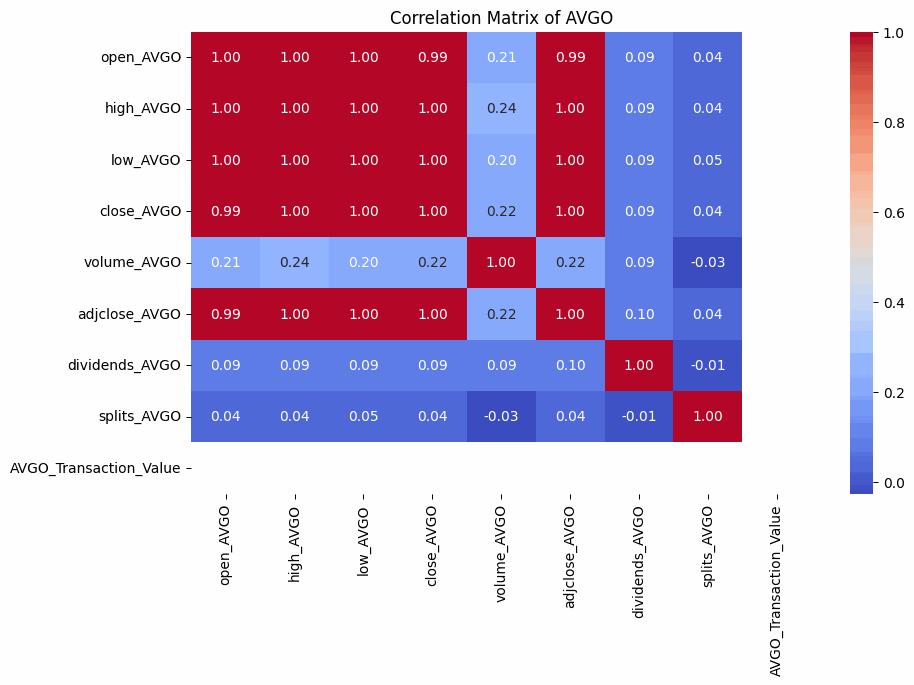

In [72]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_avgo.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of AVGO')
plt.show()

**1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlation (≈ 0.99 - 1.00)**
  - **Open, High, Low, Close, and Adjusted Close prices are nearly perfectly correlated.**
  - This means that **AVGO stock follows a highly structured and predictable price movement pattern** during the trading day.

- **Business Implications:**  
  - **Momentum Trading Advantage:** **Traders can use the opening price to estimate how the stock will close.**  
  - **Low Intraday Volatility:** **Since highs, lows, and closes move together, AVGO does not experience extreme daily price swings, making it suitable for long-term investors.**  
  - **Predictable Price Movements:** **Investors and funds can use historical price movements to make informed investment decisions.**  

---

 **Trading Volume and Stock Prices**
- **Moderate Positive Correlation between Volume and Stock Prices (≈ 0.20 - 0.24)**
  - **When AVGO’s price rises, trading volume tends to increase slightly.**
  - This suggests that **higher trading activity supports upward price movements, potentially due to institutional buying.**  

- **Business Implications:**  
  - **Institutional Accumulation:** **Higher trading volume alongside rising prices suggests institutional investors are accumulating Broadcom stock, signaling strong confidence in the company’s future.**  
  - **Market Liquidity:** **AVGO has high liquidity, meaning large trades do not significantly impact price movements.**  
  - **Retail Investor Interest:** **An increase in volume and price together often indicates strong retail participation, possibly influenced by earnings reports or major news.**  

---

 **Dividends and Stock Splits**
- **Minimal Correlation with Stock Prices (~ 0.09)**
  - **Dividends and stock splits do not have a significant impact on AVGO’s daily price movements.**  
  - Broadcom’s dividend strategy seems to be more of a **long-term shareholder incentive rather than a short-term price driver.**  

- **Business Implications:**  
  - **Long-Term Stability:** **AVGO remains a strong dividend-paying stock, attracting income-focused investors while maintaining growth potential.**  
  - **Stock Split Potential:** **With Broadcom’s stock rising significantly, a stock split may be a possibility to improve accessibility for retail investors.**  
  - **Attractive for Dividend Growth Investors:** **AVGO balances growth with dividends, making it ideal for investors looking for both capital appreciation and income.**  

---

 **2. Strategic Investment Insights**
- **Broadcom’s stock movements are highly structured, making it a strong candidate for systematic investment strategies and low-volatility portfolio allocations.**  
- **Unlike other large-cap stocks, AVGO’s volume positively correlates with price movements, suggesting strong institutional and retail investor demand.**  
- **Dividends have little impact on short-term price fluctuations, reinforcing Broadcom’s appeal to long-term dividend growth investors.**  
- **AVGO remains a solid investment for both institutional investors and retail traders looking for consistent long-term growth with dividend support.**  

---

 **Final Business Takeaway**
Broadcom is a **stable, growth-oriented stock with strong institutional investor backing and increasing trading volume during price uptrends.** **Investors should monitor volume trends as an indicator of insti



## ROBLOX (RBLX)

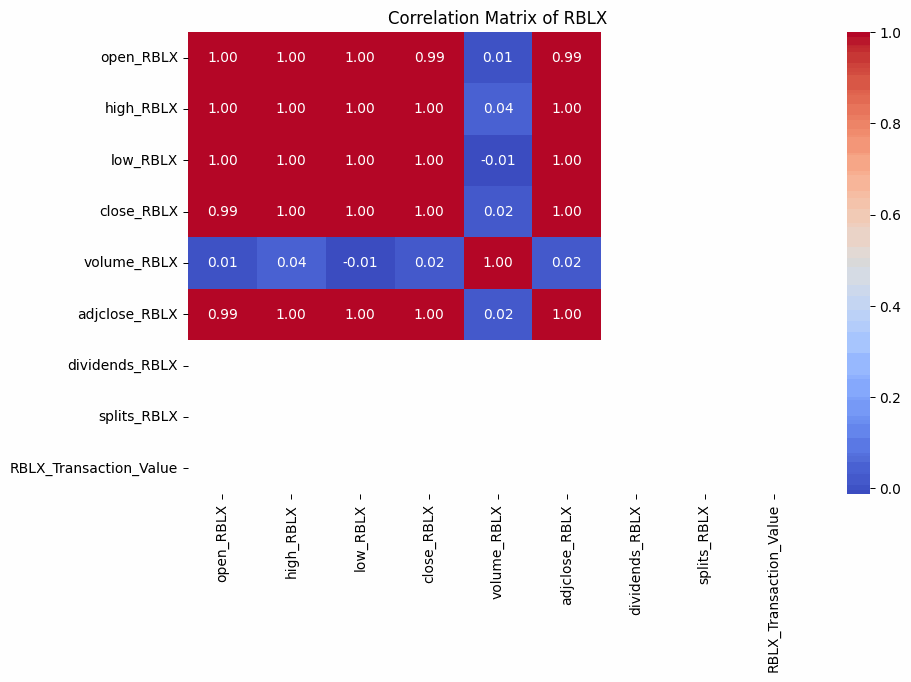

In [73]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_rblx.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of RBLX')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Perfect Positive Correlation (~ 0.99 - 1.00)**
  - **Open, High, Low, Close, and Adjusted Close prices are nearly identical.**
  - This indicates that **RBLX follows a predictable intraday price movement, with little deviation between its highest and lowest points.**

- **Business Implications:**  
  - **Low Intraday Volatility:** **Since all price points are highly correlated, Roblox does not experience extreme price swings, making it suitable for risk-averse investors.**  
  - **Predictable Trading Behavior:** **Traders can estimate the closing price based on the opening price, making RBLX a candidate for momentum trading strategies.**  
  - **Ideal for Algorithmic Trading:** **High correlations between price points suggest that quantitative traders can use historical data to predict future price movements with greater accuracy.**  

---

 **Trading Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Prices (≈ 0.01 - 0.04)**
  - Unlike many stocks, **RBLX's trading volume does not significantly impact price movements.**
  - **This suggests that price changes are not driven by large buy/sell orders but rather by market sentiment, news, or industry trends.**

- **Business Implications:**  
  - **Retail-Driven Market:** **The lack of a strong correlation between volume and price suggests that retail traders, rather than institutions, drive price changes.**  
  - **No Clear Demand-Supply Trend:** **Unlike stocks where increased volume leads to higher prices, Roblox’s price fluctuations appear independent of trading volume.**  
  - **Not Ideal for Volume-Based Trading Strategies:** **Traders relying on volume spikes to predict price movements may find RBLX challenging to trade effectively.**  

---

 **Dividends and Stock Splits**
- **No Data on Dividends and Stock Splits**
  - Roblox does not currently pay dividends or engage in stock splits.
  - This means **investors focus purely on capital appreciation rather than income generation.**

- **Business Implications:**  
  - **Growth-Oriented Investment:** **Investors buying RBLX are betting on future growth rather than expecting steady dividend payments.**  
  - **Potential for Future Stock Splits:** **If Roblox’s stock price rises significantly in the coming years, a stock split could be introduced to make shares more accessible to retail investors.**  

---

 **2. Strategic Investment Insights**
- **Roblox exhibits stable intraday price movements, making it a strong candidate for trend-following strategies.**  
- **Low correlation between trading volume and stock price means that external factors, such as earnings reports or gaming industry trends, play a bigger role in stock performance.**  
- **RBLX remains a speculative growth stock, meaning it is best suited for investors with high-risk tolerance and long-term growth expectations.**  
- **The absence of dividends makes it unattractive for income-focused investors, but its long-term gaming industry potential could justify its growth-oriented valuation.**  

---

 **Final Business Takeaway**
Roblox is a **growth-focused, retail-driven stock with low intraday volatility and minimal impact from trading volume.** Investors should **monitor external catalysts (gaming industry trends, metaverse developments, and company earnings) rather than relying on traditional volume-price dynamics.**


## VISA (V)

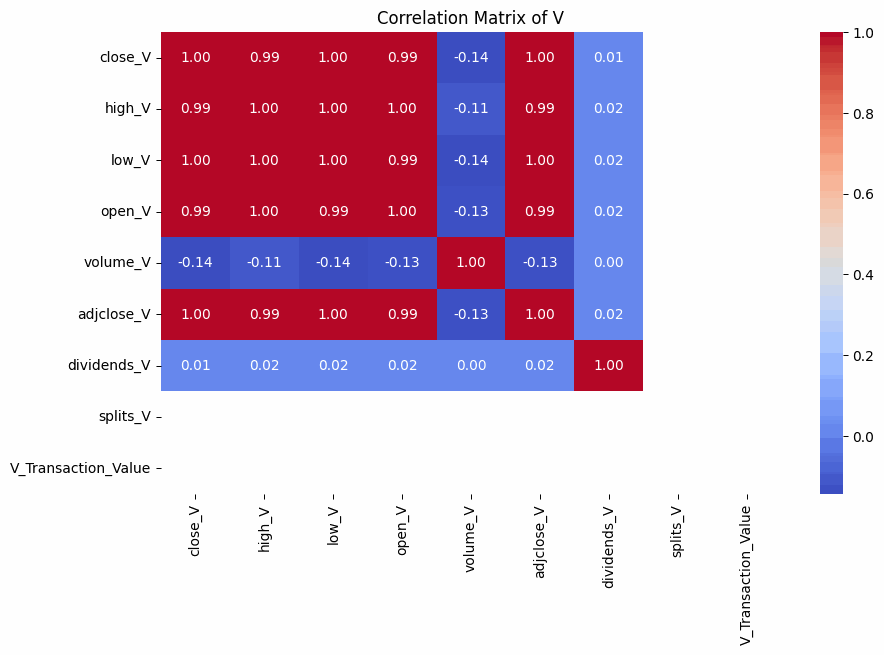

In [74]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_v.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of V')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Perfect Positive Correlation (~ 0.99 - 1.00)**
  - **Open, High, Low, Close, and Adjusted Close prices are strongly correlated.**
  - This indicates that **Visa’s stock price follows a predictable intraday price pattern, with little deviation between the highest and lowest points.**

- **Business Implications:**  
  - **Stable Price Trends:** **Since all price-related metrics move together, Visa is relatively stable, making it a good stock for conservative investors.**  
  - **Predictable Movement:** **The strong correlation among price variables suggests that Visa’s price action can be forecasted based on historical trends, which is beneficial for algorithmic and quantitative traders.**  
  - **Less Volatile Stock:** **Visa’s stock does not exhibit significant price swings, making it a lower-risk investment compared to more volatile tech or growth stocks.**  

---

 **Trading Volume vs. Stock Prices**
- **Weak Negative Correlation Between Volume and Prices (-0.11 to -0.14)**
  - This suggests that **higher trading volume does not necessarily lead to higher prices.**
  - **Visa’s price changes are not primarily driven by large volume spikes, but rather by external market forces, macroeconomic trends, and investor sentiment.**

- **Business Implications:**  
  - **Institutional Investor Activity:** **Since Visa’s price is not strongly influenced by volume, it suggests a stable presence of institutional investors rather than retail traders who typically drive high-volume price swings.**  
  - **Not a Momentum Stock:** **Visa does not exhibit strong momentum-based price movements, making it less attractive for short-term traders who rely on volume-based signals.**  
  - **Ideal for Long-Term Holding:** **The weak relationship between volume and price suggests Visa is better suited for long-term investors rather than day traders.**  

---

 **Dividends and Stock Splits**
- **Dividends Show Minimal Correlation with Price Movements (~0.01 - 0.02)**
  - **Visa is a dividend-paying stock, but its dividend payments do not significantly impact price movements.**
  - **Stock splits are absent in the dataset, indicating that Visa has not undergone recent splits.**

- **Business Implications:**  
  - **Income-Oriented Investment:** **Visa provides a consistent dividend, making it a strong choice for dividend investors seeking stable income.**  
  - **Price Stability After Dividends:** **Since dividends do not cause major price fluctuations, Visa’s stock remains stable before and after dividend payments, reducing risk for investors.**  

---

 **2. Strategic Investment Insights**
- **Visa is a fundamentally stable stock with predictable price movements, making it suitable for conservative investors.**  
- **Since trading volume has little impact on price changes, traders should focus on macroeconomic factors (interest rates, inflation, and global spending trends) rather than short-term volume fluctuations.**  
- **Visa is an ideal stock for long-term investors who seek steady returns from both capital appreciation and dividends.**  
- **Due to its stability and strong fundamentals, Visa remains a core holding for diversified portfolios, particularly in financial and blue-chip stock categories.**  

---

 **Final Business Takeaway**
Visa is a **low-volatility, high-stability financial stock that offers consistent dividends and predictable price movements.** Its weak correlation with trading volume suggests that **long-term investors should focus on economic trends rather than short-term market activity.**


## SALESFORCE (CRM)

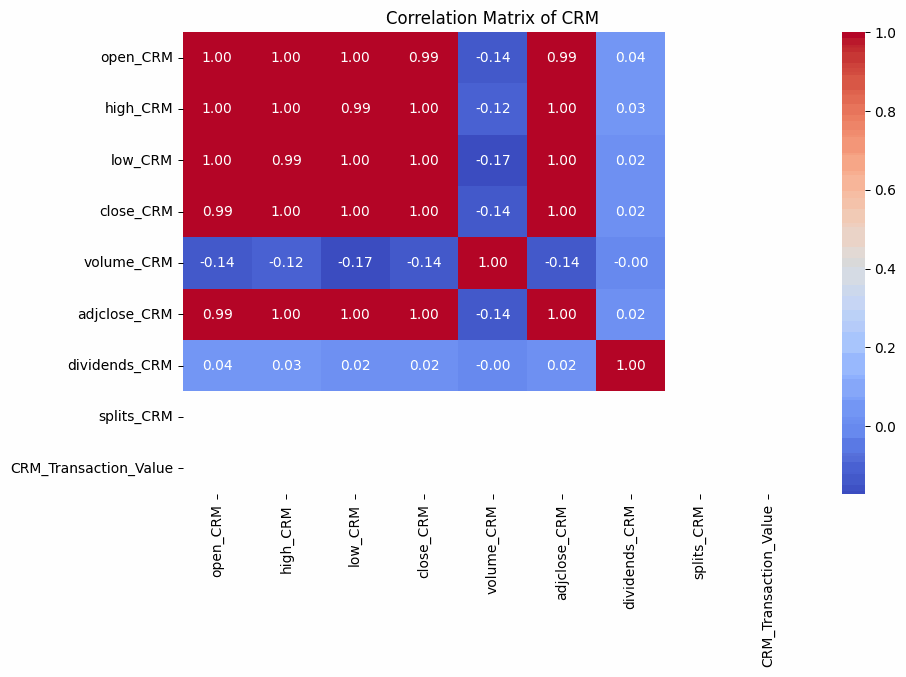

In [75]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_crm.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of CRM')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlation (~ 0.99 - 1.00)**
  - **Open, High, Low, Close, and Adjusted Close prices are all highly correlated.**
  - This indicates **a highly structured and stable price movement pattern, where daily price fluctuations follow a predictable trend.**

- **Business Implications:**  
  - **Consistent Trading Patterns:** **CRM’s stock price moves in a highly predictable manner, making it easier to analyze using historical trends.**  
  - **Lower Volatility:** **Since all price metrics move together, Salesforce appears to be a stable stock, which is attractive for long-term investors rather than short-term traders.**  
  - **Good for Algorithmic Trading:** **Given the strong correlation, trading strategies based on historical price data could be effective for forecasting short-term movements.**  

---

 **Trading Volume vs. Stock Prices**
- **Weak Negative Correlation Between Volume and Prices (-0.12 to -0.17)**
  - This suggests that **increased trading volume does not always lead to price increases.**
  - **Instead, Salesforce’s stock price is likely influenced by external factors such as earnings reports, industry trends, and macroeconomic conditions rather than volume-based trading activity.**

- **Business Implications:**  
  - **Institutional Investors Play a Key Role:** **Since volume does not drive price significantly, institutional investors likely play a bigger role in the stock’s movement rather than retail traders.**  
  - **Not Ideal for Short-Term Trading:** **Traders relying on volume spikes to predict price moves may find Salesforce stock less reactive compared to high-volatility stocks like Tesla or Nvidia.**  
  - **Focus on Fundamentals, Not Just Volume:** **Since trading volume has a weak impact on price, investors should focus more on revenue growth, earnings performance, and business fundamentals rather than short-term trading patterns.**  

---

 **Dividends and Stock Splits**
- **Minimal Impact of Dividends (~0.02 - 0.04 Correlation with Prices)**
  - **Salesforce does not pay significant dividends, and when it does, the dividend payments do not appear to influence stock price behavior.**
  - **There are no recorded stock splits in this dataset, meaning Salesforce has maintained its stock structure.**

- **Business Implications:**  
  - **Focus on Growth Rather Than Income:** **Since dividends do not play a significant role, Salesforce remains a growth-focused company rather than a dividend stock.**  
  - **Long-Term Capital Appreciation:** **Investors should look for capital appreciation rather than expecting income from dividends.**  

---

 **2. Strategic Investment Insights**
- **Salesforce is a strong candidate for long-term investment, given its predictable price movements and lower volatility.**  
- **The weak correlation between volume and price suggests that market sentiment and macroeconomic factors have a greater influence on the stock than daily trading activity.**  
- **Since dividends do not impact price movement, investors should prioritize Salesforce’s growth potential rather than dividend income.**  
- **Salesforce is a stable, predictable stock, making it ideal for institutional investors and long-term portfolios rather than speculative short-term trading.**  

---

 **Final Business Takeaway**
Salesforce is a **low-volatility, high-growth enterprise software stock with predictable price movements.** While volume fluctuations do not significantly impact price, **fundamentals such as revenue growth and industry trends drive its valuation.** **Investors should focus on long-term capital appreciation rather than short-term trading opportunities.**


## WALT DISNEY (DIS)

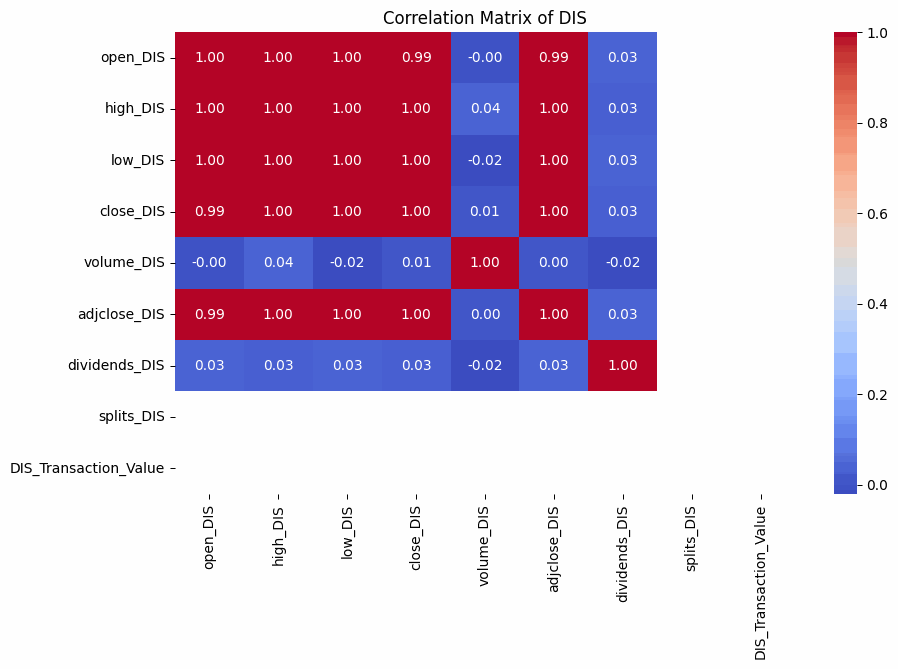

In [76]:
# Create a correlation matrix
plt.figure(figsize=(10, 6))
correlation_matrix = df_dis.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of DIS')
plt.show()

 **1. Key Observations from the Correlation Matrix**  

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Extremely High Positive Correlation (~ 0.99 - 1.00)**
  - **The open, high, low, close, and adjusted close prices are almost perfectly correlated.**
  - **This indicates that Disney’s stock price moves in a very structured and consistent manner, with little unexpected volatility.**  

- **Business Implications:**  
  - **Stable Stock Behavior:** **Since all price metrics move together, Disney’s stock follows predictable trading patterns, making it ideal for long-term investors.**  
  - **Low Short-Term Volatility:** **This suggests that major price swings are uncommon, making it less risky for conservative investors.**  
  - **Consistent Market Sentiment:** **The stock price movements suggest that Disney is a well-established, less speculative stock, driven more by long-term financials rather than short-term trading activity.**  

---

 **Trading Volume vs. Stock Prices**
- **Minimal to No Correlation Between Volume and Prices (-0.02 to 0.04)**
  - **This means that higher trading volume does not necessarily drive price changes in Disney’s stock.**
  - **Unlike more volatile stocks where volume spikes lead to large price swings, Disney’s stock price is influenced more by broader market sentiment and business fundamentals.**  

- **Business Implications:**  
  - **Institutional Investors Play a Dominant Role:** **Since volume does not significantly impact price, large institutional investors likely hold and trade Disney stock in a controlled manner, reducing speculative swings.**  
  - **Not Ideal for Day Trading:** **Traders looking for rapid price fluctuations based on volume surges may find Disney less responsive.**  
  - **Long-Term Stability:** **Disney’s stock price is primarily influenced by earnings, strategic decisions (such as streaming expansions), and market trends rather than short-term trading activity.**  

---

 **Dividends and Stock Splits**
- **Weak Correlation Between Dividends and Prices (~0.03)**
  - **Dividends have minimal impact on stock price movements, indicating that Disney is not primarily viewed as a dividend stock.**
  - **No significant stock splits are recorded in this dataset, meaning Disney has maintained its stock structure rather than frequently splitting shares.**  

- **Business Implications:**  
  - **Disney is Primarily a Growth Stock:** **Investors should focus on stock appreciation rather than dividend income.**  
  - **Share Buybacks or Other Strategies Might Be More Relevant:** **Rather than relying on dividends, Disney may use buybacks or reinvest earnings into strategic areas like Disney+ and theme parks.**  
  - **No Recent Splits Mean a Stable Shareholder Base:** **The absence of splits suggests that Disney maintains a steady capital structure, attracting more long-term investors rather than short-term traders.**  

---

 **2. Strategic Investment Insights**
- **Disney stock follows a predictable and stable price movement pattern, making it ideal for long-term investors rather than short-term traders.**  
- **Unlike speculative stocks where volume significantly impacts price, Disney’s price movements are more dependent on earnings performance, market conditions, and strategic business decisions.**  
- **Since dividends have a weak correlation with price movements, investors should look at Disney as a long-term capital appreciation stock rather than a high-dividend-yielding investment.**  
- **Disney’s stock is highly correlated with broader market trends and investor confidence, making it sensitive to macroeconomic shifts but resilient in long-term performance.**  

---

 **Final Business Takeaway**
Disney remains a **low-volatility, long-term investment stock driven by strategic business growth rather than speculative trading.** Investors should focus on **theme park revenue, streaming performance (Disney+), and content production rather than short-term price movements.** **It is a strong pick for institutional investors and long-term portfolios looking for stability and growth rather than short-term gains.**


# MULTIVAIRATE ANALYSIS

## NVIDA (NVDA)

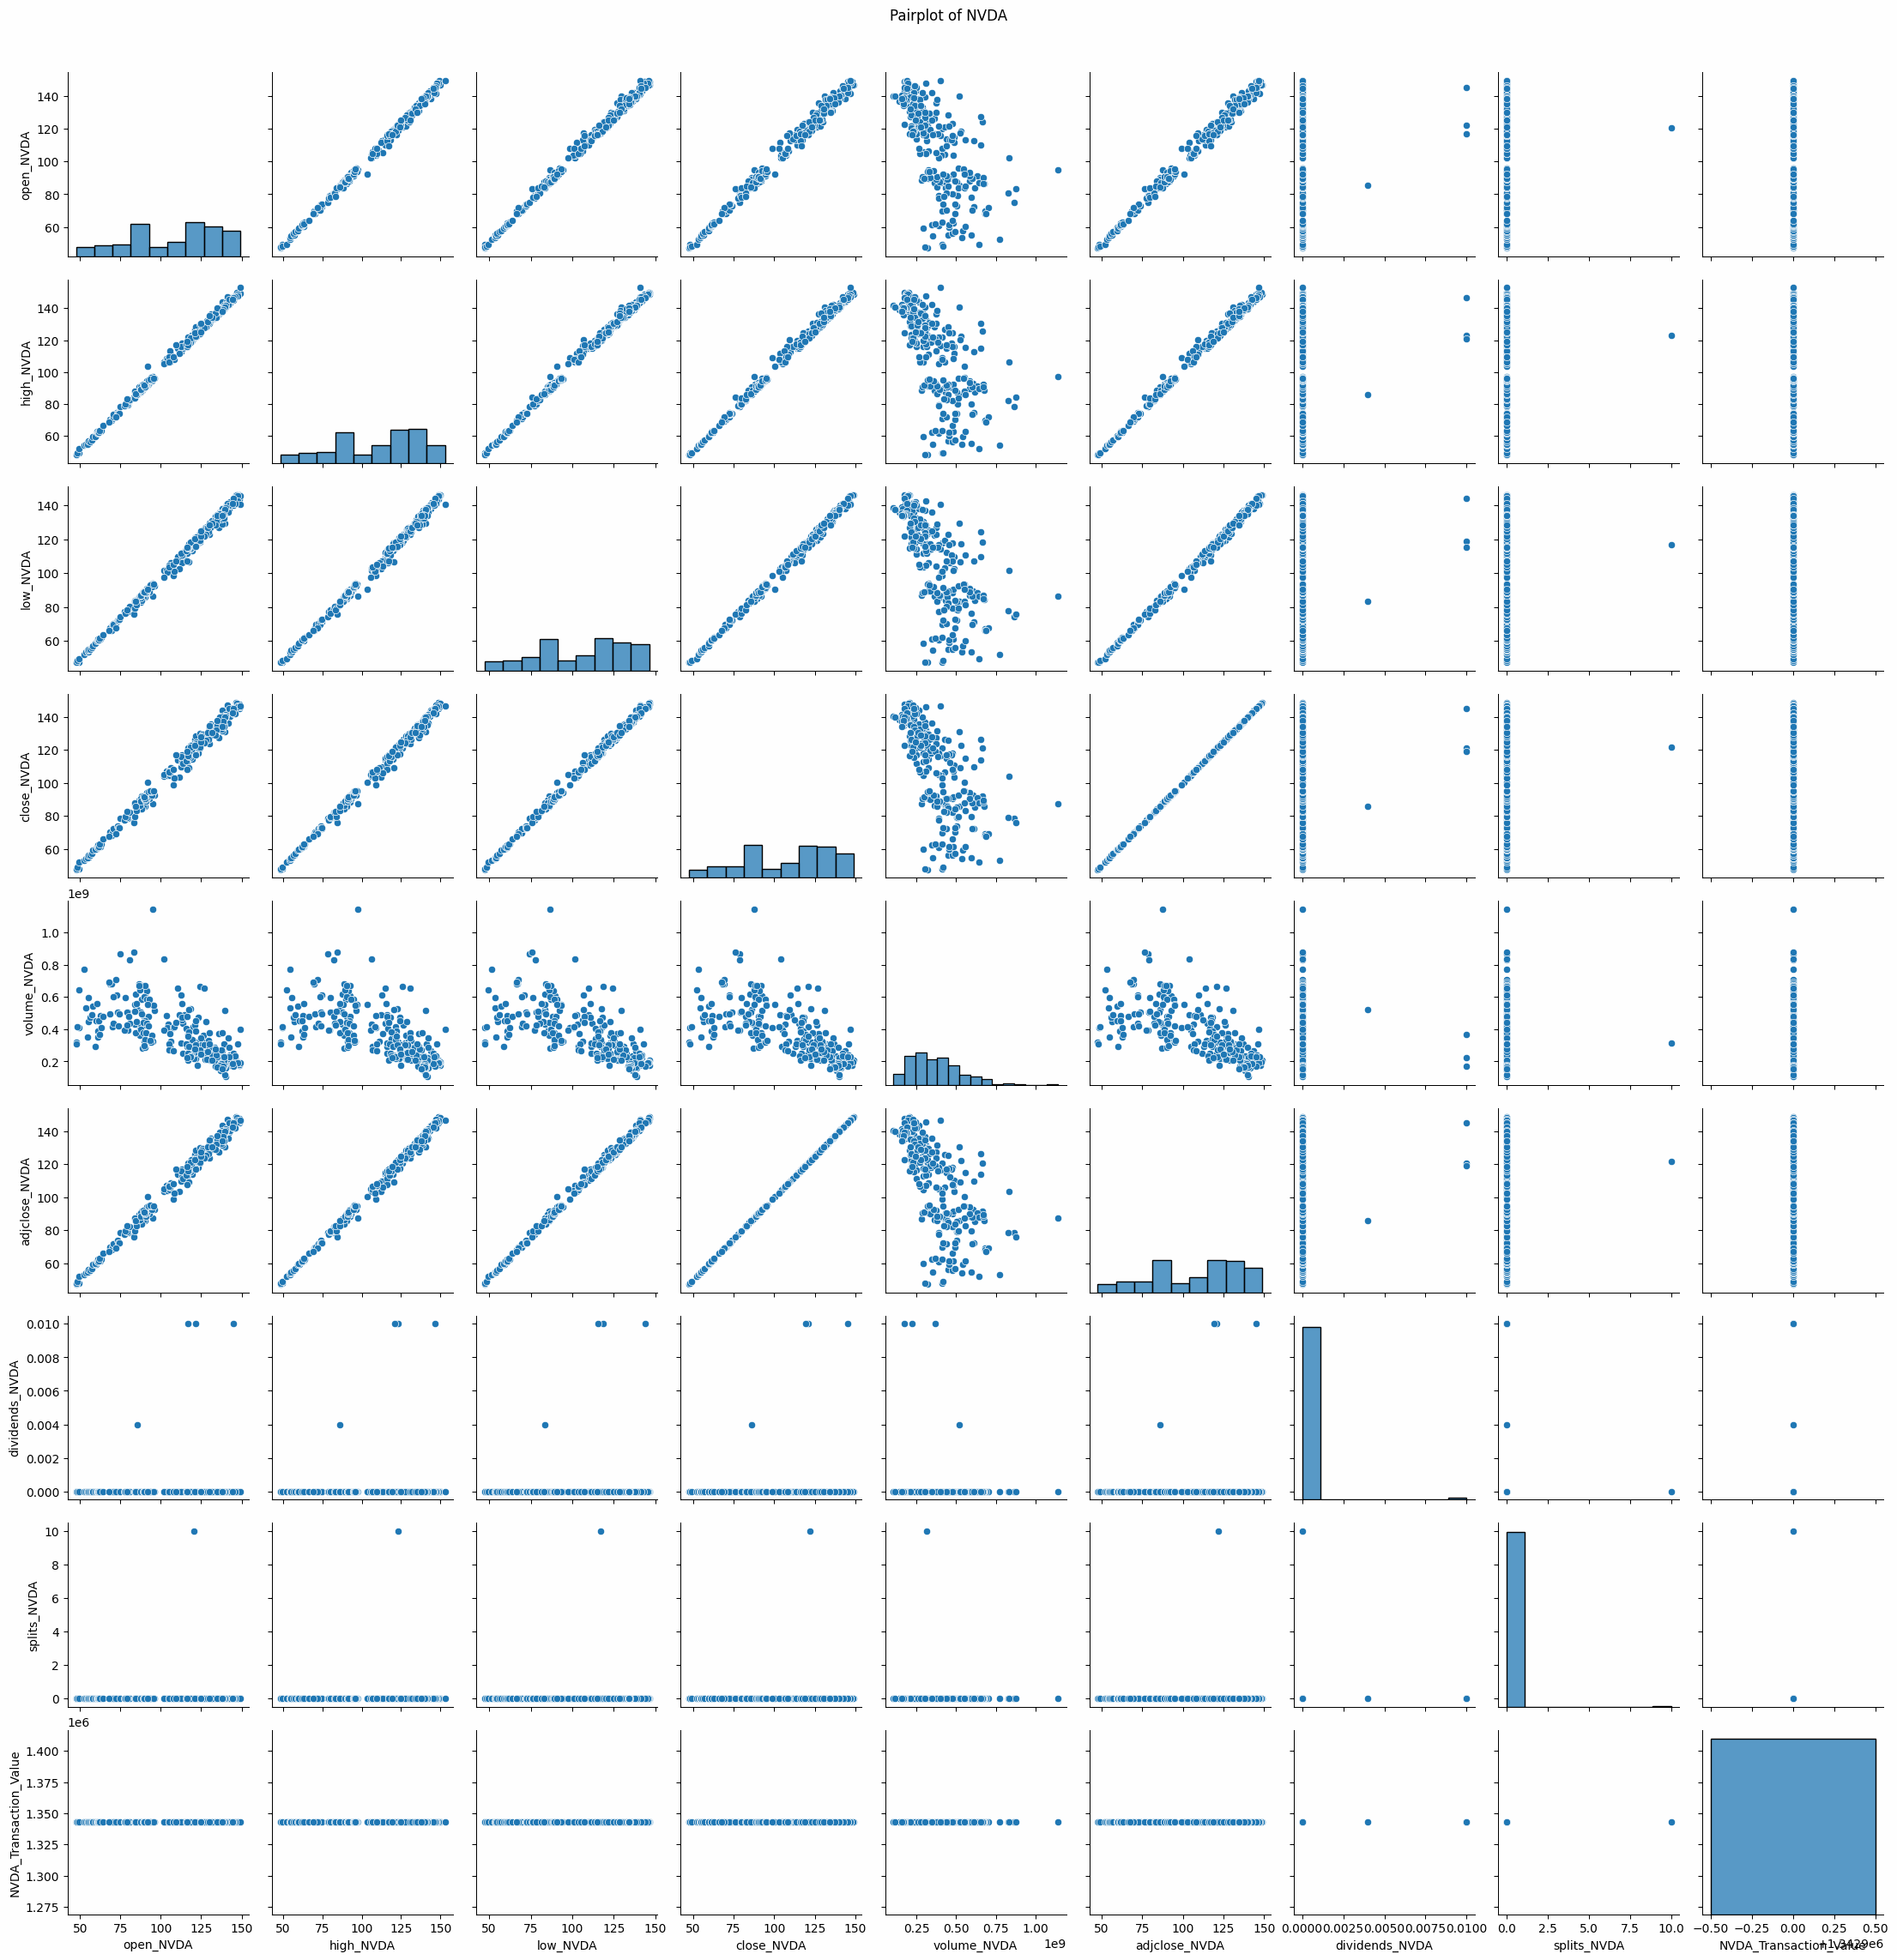

In [77]:
# Create a pairplot
sns.pairplot(df_nvda)
plt.suptitle('Pairplot of NVDA', y=1.02)
plt.show()


 **1. Key Observations from the Pairplot**

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Linear Relationships:**  
  - The **open, high, low, close, and adjusted close prices** show a **strong positive correlation**, forming nearly perfect linear relationships in scatter plots.
  - This indicates **predictability** in NVIDIA’s stock movement: if the **opening price is high, the closing price is also high.**
  
- **Business Implications:**  
  - **Trend Stability:** NVIDIA stock follows **consistent price movements**, making it easier to predict based on past trends.
  - **Good for Trend-Following Strategies:** Traders using moving averages or momentum strategies can capitalize on this pattern.
  - **Less Volatility:** Since price metrics move together, NVIDIA’s stock is not as susceptible to unpredictable price swings.

---

 **Volume vs. Stock Prices**
- **No Strong Correlation Between Volume and Price:**  
  - The scatter plots between **volume and stock prices** show a dispersed pattern, indicating **weak correlation**.
  - Higher trading volume does **not necessarily** lead to significant price movement.

- **Business Implications:**  
  - **NVIDIA is Not a Pump-and-Dump Stock:** Unlike speculative stocks, **large trades do not drastically impact price**, suggesting **institutional investors** dominate trading.
  - **Less Prone to Market Manipulation:** Since volume does not dictate price, NVIDIA’s stock is driven more by **fundamentals** (earnings, AI advancements, etc.).
  - **Long-Term Investors Take Priority:** NVIDIA’s stock is likely held by **institutional investors and hedge funds** with a long-term outlook.

---

 **Dividends & Stock Splits**
- **Almost No Relationship with Stock Prices or Volume**
  - Dividends and stock splits **show minimal variation** across time, confirming NVIDIA **is not a dividend-focused stock.**

- **Business Implications:**  
  - **Investors Buy for Growth, Not Income:** NVIDIA is a **high-growth stock**, with price appreciation being the main attraction.
  - **No Stock Splits Suggests Higher Entry Barriers for Retail Investors:** Since NVIDIA **hasn’t split stock recently**, the price may become less accessible to smaller investors.

---

 **2. Strategic Investment Insights**
- **Strong Price Predictability:** NVIDIA’s stock price moves **consistently** across all price categories, making it an **ideal stock for trend-following strategies.**
- **Volume is Not a Price Driver:** Unlike speculative stocks, volume spikes **do not correlate with price increases**, meaning price changes are driven by **earnings reports, AI innovations, and broader tech trends.**
- **NVIDIA is a Growth-Oriented Stock:** With **low dividend payouts and no stock splits**, investors should focus on **long-term capital appreciation rather than income.**
- **Great for Institutional Investors:** NVIDIA’s price stability and lack of high-volume price swings make it **ideal for hedge funds and mutual funds.**

---

 **Final Takeaway**
NVIDIA remains one of the **strongest growth stocks in the semiconductor and AI industry.** The **lack of price volatility and high correlation among price points** make it a **predictable and stable investment.** Traders should focus on **long-term market trends, earnings reports, and AI sector growth rather than short-term volume spikes.**


## MICROSOFT (MSFT)

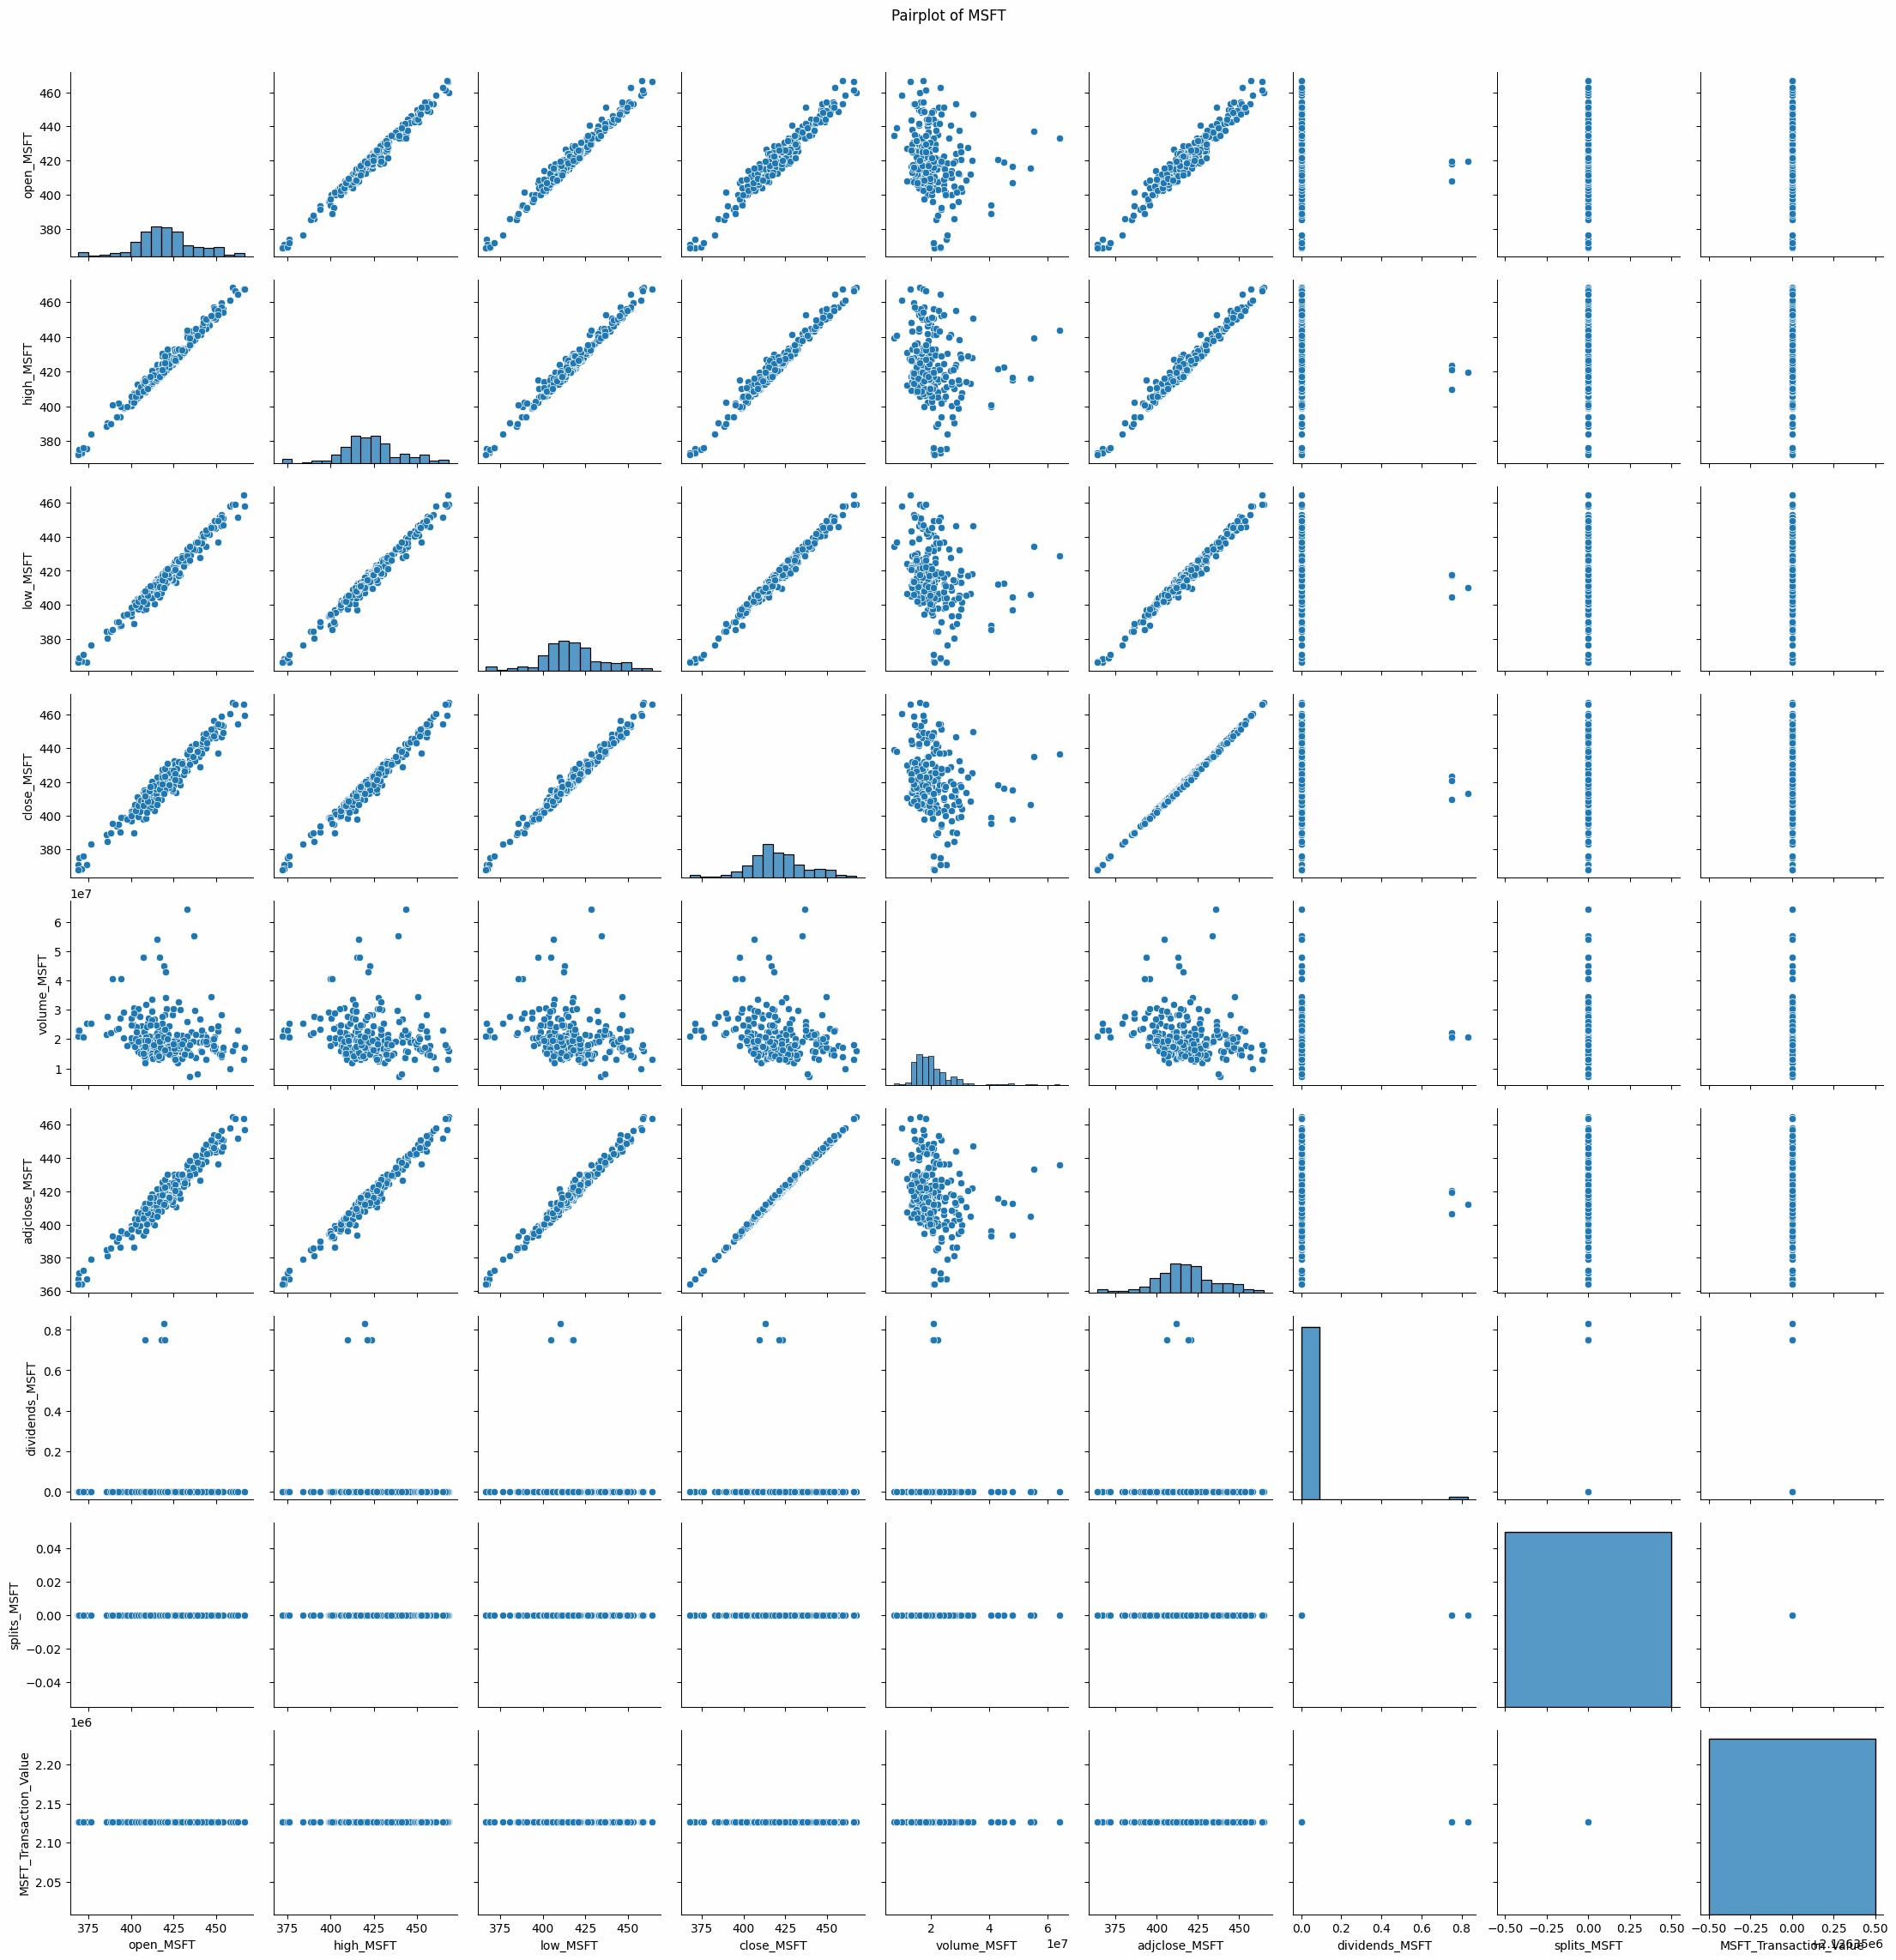

In [78]:
# Create a pairplot
sns.pairplot(df_msft)
plt.suptitle('Pairplot of MSFT', y=1.02)
plt.show()

 **1. Key Observations from the Pairplot**

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlations:**  
  - The **open, high, low, close, and adjusted close prices** exhibit nearly perfect linear relationships, forming **strongly correlated scatter plots**.
  - This suggests **Microsoft’s stock follows a stable trend** where daily price movements are **highly predictable**.

- **Business Implications:**  
  - **Steady Growth & Predictability:** Microsoft’s stock price behavior is **ideal for long-term investors** who prefer **low-volatility, blue-chip stocks**.
  - **Reliable Trend Trading:** Since prices move consistently, traders can use **technical indicators like moving averages** to optimize entry and exit points.
  - **Safe Investment During Economic Uncertainty:** Microsoft’s stock shows **low volatility**, making it a **defensive stock** during market downturns.

---

 **Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Stock Prices:**  
  - The scatter plots **do not show a strong relationship** between trading volume and stock price.
  - Microsoft’s stock **does not react sharply to trading spikes**, meaning large transactions do not significantly affect price.

- **Business Implications:**  
  - **Institutional Dominance:** Microsoft’s stock is heavily traded by **institutions and long-term investors** rather than day traders.
  - **Low Risk of Pump-and-Dump Schemes:** Since price does not follow volume changes, Microsoft is **not a speculative stock**, reducing chances of market manipulation.
  - **Investors Trust Fundamentals Over Speculation:** Unlike high-volatility stocks (e.g., Tesla), Microsoft’s movement is based on **financial performance, earnings, and industry developments.**

---

 **Dividends & Stock Splits**
- **Minimal Variation in Dividends & No Stock Splits**  
  - Microsoft pays dividends but at a relatively **low percentage compared to its stock price growth.**
  - **No major stock splits in recent history**, which means Microsoft focuses on steady price appreciation.

- **Business Implications:**  
  - **Dividend Growth Strategy:** Microsoft is attractive to investors looking for **long-term capital appreciation with consistent dividend payouts**.
  - **Higher Entry Barrier for Retail Investors:** Without stock splits, Microsoft’s stock remains **expensive per share**, which may limit accessibility for small investors.
  - **Strong Hold Stock for Institutional Investors:** Hedge funds and pension funds prefer Microsoft due to its **reliable dividend payments and strong earnings growth.**

---

 **2. Strategic Investment Insights**
- **Microsoft is a Defensive, Blue-Chip Stock:**  
  - **Ideal for long-term investors** who prefer **stability, dividends, and low risk**.
  - **Less susceptible to short-term fluctuations**, making it a **safe haven during economic downturns**.

- **Low Correlation Between Volume and Price Movements:**  
  - Large trade volumes **do not drive major price shifts**, meaning price action is primarily dictated by **earnings reports, product launches, and cloud business performance**.

- **Dividend Growth Makes It Attractive for Passive Income Investors:**  
  - Microsoft is **not a high-yield dividend stock**, but it is known for **steady dividend increases over time**.
  - Investors seeking **a combination of growth and passive income** would find Microsoft appealing.

---

 **Final Takeaway**
Microsoft is a **stable, predictable, and long-term investment stock.** It is ideal for **investors who value consistency, dividends, and tech sector dominance.**


## APPLE (AAPL)

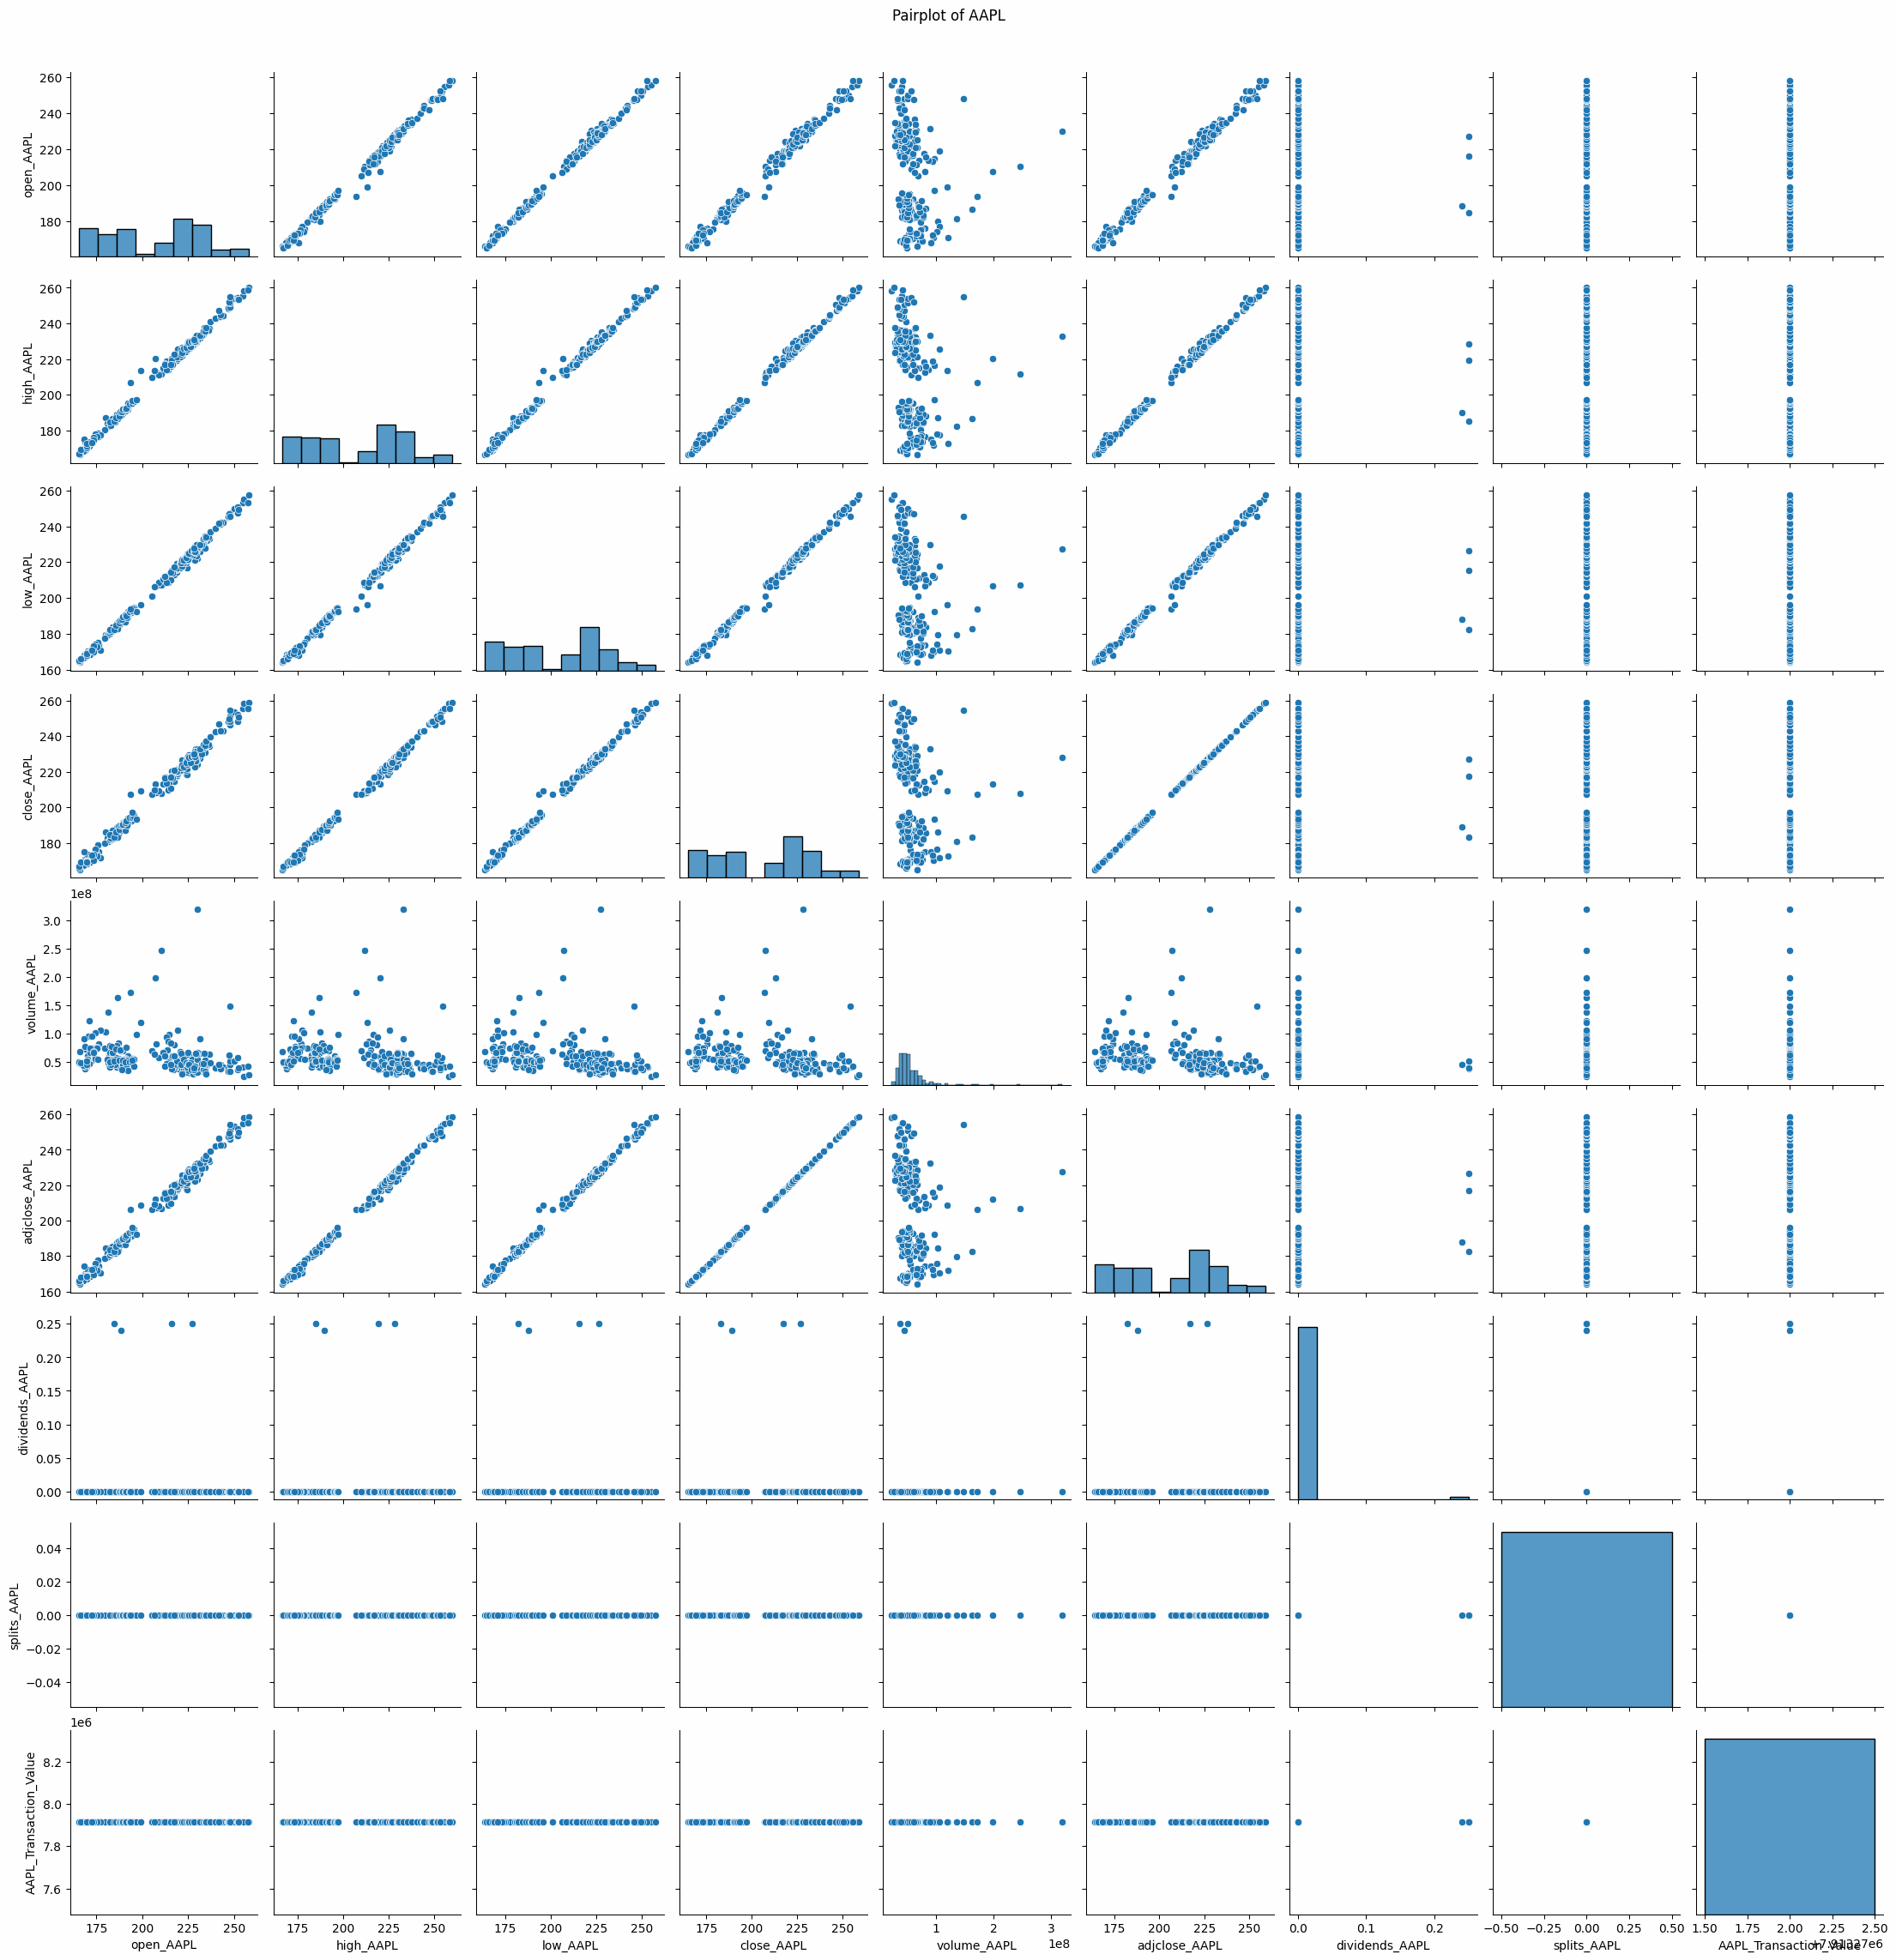

In [79]:
# Create a pairplot
sns.pairplot(df_aapl)
plt.suptitle('Pairplot of AAPL', y=1.02)
plt.show()

 **1. Key Observations from the Pairplot**

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlations:**  
  - The **open, high, low, close, and adjusted close prices** display nearly **perfect correlations**, confirming that **daily stock price fluctuations are highly predictable**.
  - This suggests that **Apple’s stock follows a stable trend**, with minor volatility on daily price swings.

- **Business Implications:**  
  - **Reliable Price Movements:** Apple's **predictable stock behavior** makes it **ideal for trend-following investors and algorithmic traders** who rely on technical indicators.
  - **Low Volatility & Stability:** Apple is a **low-risk stock** compared to high-volatility tech stocks like Tesla. This makes it **appealing for institutional investors**.
  - **Safe Investment During Market Uncertainty:** Apple’s **strong brand, product ecosystem, and recurring revenue model** contribute to its **steady stock performance**, even in **economic downturns**.

---

 **Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Stock Price:**  
  - The scatter plots indicate **little relationship between trading volume and stock price movements**.
  - This means that **large fluctuations in trading volume do not necessarily drive price changes**.

- **Business Implications:**  
  - **Institutional Investor Dominance:** Since Apple’s stock price is **not significantly impacted by daily trading volume**, it is likely **held by long-term investors and large funds** rather than speculative traders.
  - **Limited Day-Trading Opportunities:** Traders seeking **short-term price swings** may find **Apple less volatile**, making it **less attractive for aggressive day-trading strategies**.
  - **Fundamental Performance Matters More:** Since **price does not follow volume spikes**, Apple’s stock is **mainly influenced by earnings reports, product launches, and macroeconomic trends**.

---

 **Dividends & Stock Splits**
- **Dividends Are Present but Not a Major Price Driver**  
  - Apple pays **regular dividends**, but the pairplot does **not show a significant relationship between dividends and stock price movements**.
  - This suggests that Apple’s dividend **is supplementary rather than a key reason for stock appreciation**.

- **Stock Splits Have Occurred in the Past**  
  - Unlike Microsoft, Apple **has a history of stock splits** to maintain share affordability.
  - Stock splits are visible in historical data, **showing Apple’s strategy to keep shares accessible to retail investors**.

- **Business Implications:**  
  - **Attractive for Growth & Dividend Investors:** Apple provides **both capital appreciation and dividend income**, making it an **ideal stock for long-term portfolios**.
  - **Retail Investor Accessibility:** **Stock splits help maintain liquidity and affordability**, attracting a wider range of investors.
  - **Consistent Dividend Growth Attracts Passive Income Investors:** While dividends are not high, **Apple’s increasing payouts over time** make it an attractive option for **dividend growth investors**.

---

 **2. Strategic Investment Insights**
- **Apple is a Strong Growth & Dividend Stock:**  
  - It appeals to **investors seeking capital appreciation with steady dividend payments**.
  - Unlike high-volatility stocks, Apple provides **stability and long-term upside potential**.

- **Price Movements Are Independent of Trading Volume:**  
  - Unlike smaller, speculative tech stocks, **Apple's stock price is not easily swayed by volume spikes**, making it **less prone to market manipulation**.
  - Investors should **focus on earnings reports, product launches, and industry trends** to predict price movements.

- **Apple’s Stock Splits Indicate a Strategy for Retail Investor Inclusion:**  
  - Unlike Microsoft, which **does not frequently split shares**, Apple’s approach makes its stock **more accessible** to individual investors.
  - This strategy **ensures liquidity and broad participation**, keeping **Apple’s retail investor base strong**.

---

 **3. Final Takeaways**
- **Apple is a blue-chip stock with high growth potential, low volatility, and consistent dividends.**
- **Its stock price follows a predictable trend, making it a safe investment for long-term holders.**
- **Stock splits and dividend growth make Apple appealing to both institutional and retail investors.**  




## ALPHABET (GOOGL)

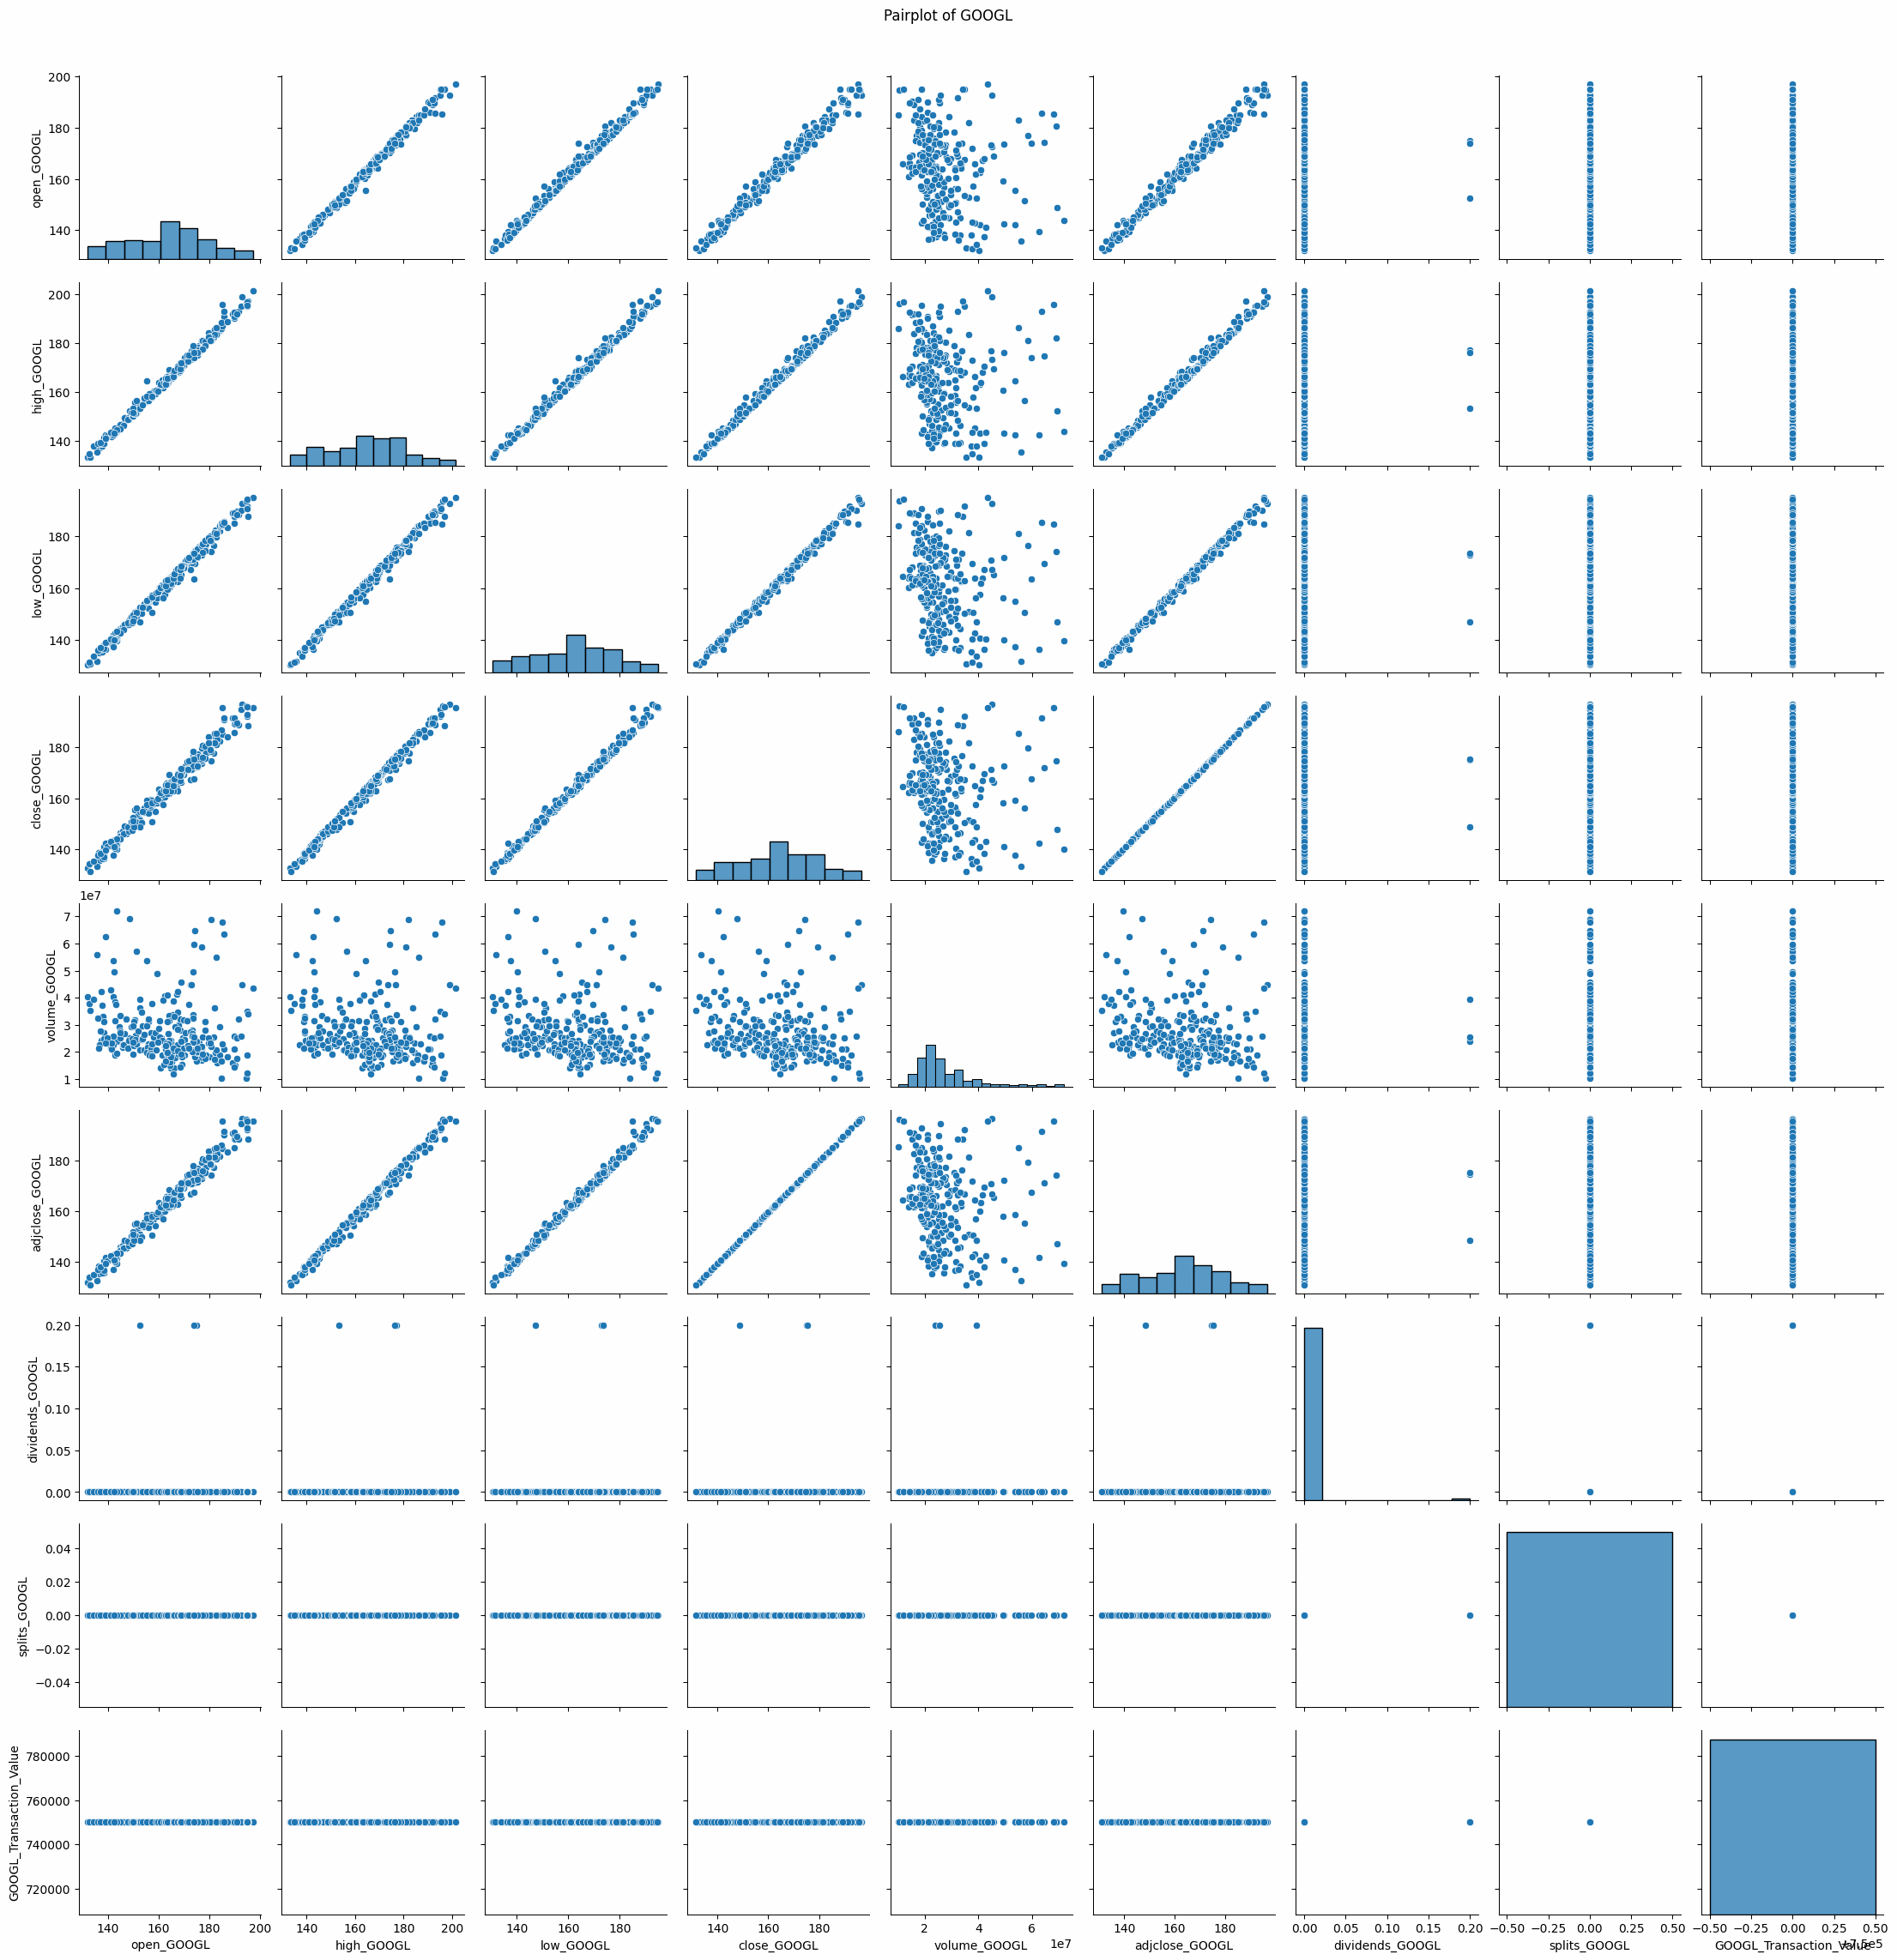

In [80]:
# Create a pairplot
sns.pairplot(df_googl)
plt.suptitle('Pairplot of GOOGL', y=1.02)
plt.show()

 **1. Key Observations from the Pairplot**

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlations:**  
  - The **open, high, low, close, and adjusted close prices** show a **near-perfect correlation** (close to **1.00**).  
  - This indicates that **GOOGL follows a relatively predictable trading pattern**, where daily price movements are **highly correlated**.

- **Business Implications:**  
  - **Stable Stock Movements:** Investors can **anticipate price swings** based on previous patterns, making GOOGL an **attractive option for institutional investors and hedge funds**.
  - **Low Volatility Compared to Speculative Tech Stocks:** Unlike stocks such as **Tesla (TSLA)**, Alphabet’s stock movements are **less erratic**, appealing to **long-term investors**.

---

 **Trading Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Stock Price:**  
  - The scatter plots between **trading volume and stock price** show a **low correlation**.
  - This suggests that **high trading volume does not necessarily drive price movements**.

- **Business Implications:**  
  - **Institutional Investor Activity:** Since **GOOGL’s price does not react significantly to volume spikes**, its **major price drivers are earnings, business expansion, and macroeconomic trends** rather than daily trading activity.
  - **Less Susceptible to Speculative Trading:** Unlike meme stocks or volatile tech stocks, GOOGL **is not heavily influenced by retail traders**.  
  - **Better for Long-Term Holding:** Investors should **focus on Alphabet’s earnings reports, AI expansion, and advertising revenue trends** rather than short-term volume fluctuations.

---

 **Dividends & Stock Splits**
- **Dividends Are Not a Significant Factor**  
  - Unlike Microsoft (MSFT) and Apple (AAPL), **Alphabet does not consistently issue dividends**.
  - The **lack of dividends in the dataset** confirms that **GOOGL is purely a growth stock**.

- **Stock Splits Have Been Minimal**  
  - The dataset **does not show frequent stock splits**, meaning Alphabet **prioritizes share value appreciation over keeping stock prices affordable for retail investors**.

- **Business Implications:**  
  - **Appeals to Growth Investors:** Since Alphabet reinvests profits into AI, cloud computing, and innovation, it is **better suited for investors seeking capital appreciation rather than passive income**.
  - **No Dividends Means More Risk:** Alphabet **does not provide steady dividend income**, making it **less attractive to conservative investors** looking for stable returns.
  - **High Stock Price May Limit Retail Investors:** Unlike Apple, which frequently splits its stock, Alphabet’s approach favors **institutional investors who buy in larger volumes**.

---

 **2. Strategic Investment Insights**
- **GOOGL is a Strong Growth Stock with Low Volatility:**  
  - Its **high correlation between price movements** makes it **ideal for long-term holding** rather than short-term trading.
  - **Volume spikes do not significantly impact stock price**, meaning **fundamental performance is the key driver**.

- **Not Ideal for Dividend Investors:**  
  - Unlike Apple or Microsoft, **GOOGL does not offer dividends**, making it **less attractive for passive income investors**.
  - Investors should **rely on capital appreciation rather than dividend payouts**.

- **Stock Splits Are Infrequent, Making GOOGL Expensive for Retail Investors:**  
  - Unlike companies that frequently split their stock to remain accessible, Alphabet **keeps its stock price high**, favoring **institutional and long-term investors**.

---

 **3. Final Takeaways**
- **GOOGL is a strong growth stock driven by earnings and innovation rather than trading volume.**
- **The stock price follows a predictable trend, making it ideal for long-term investors.**
- **No dividends make it less attractive for income-focused investors.**
- **Institutional investors dominate GOOGL trading, making it less volatile than speculative tech stocks.**  



## TESLA (TSLA)

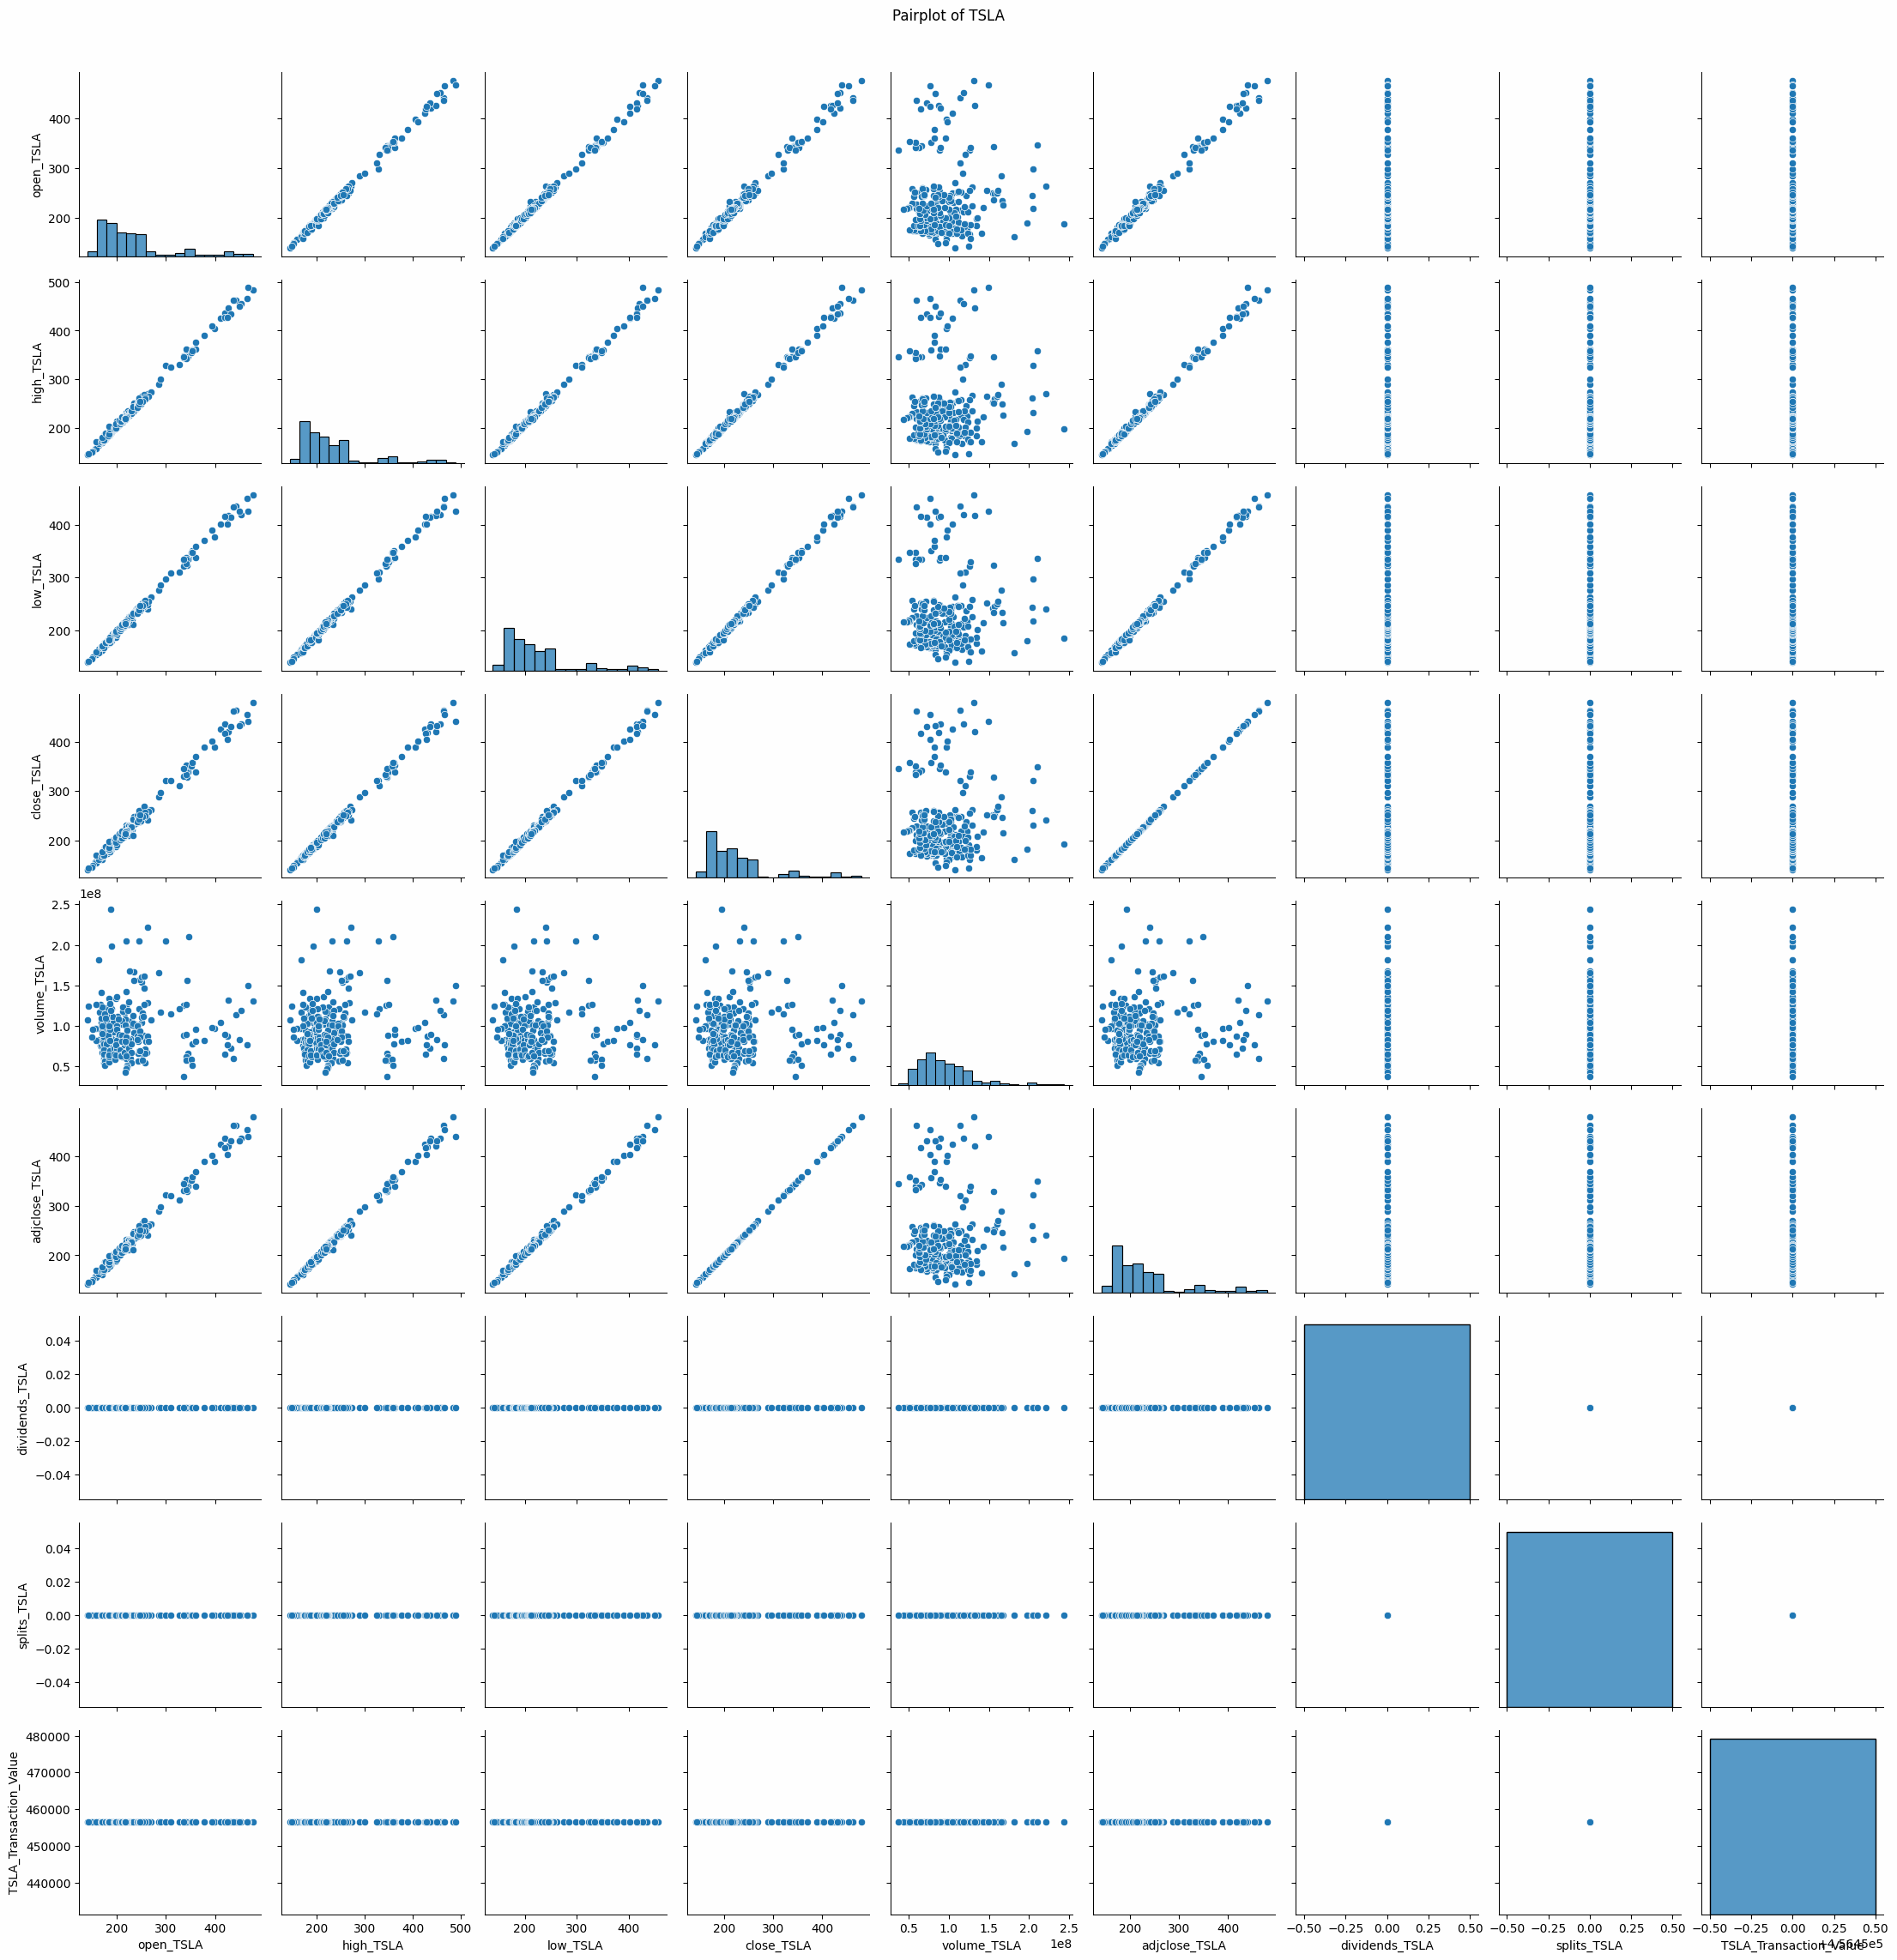

In [81]:
# Create a pairplot
sns.pairplot(df_tsla)
plt.suptitle('Pairplot of TSLA', y=1.02)
plt.show()


 **1. Key Observations from the Pairplot**

 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Positive Correlations Among Price Metrics:**  
  - The **open, high, low, close, and adjusted close prices** show **near-perfect correlation** (close to **1.00**).  
  - This indicates that **Tesla’s daily price movements follow a consistent pattern**, with high predictability among these price variables.

- **Business Implications:**  
  - **Momentum Trading Strategy Works Well:** Since Tesla’s stock follows strong intra-day correlations, **momentum traders can capitalize on trends**.
  - **High Sensitivity to Market News:** Tesla’s stock is **reactive to earnings reports, macroeconomic changes, and Elon Musk’s statements**, meaning investors should **watch for external catalysts**.

---

 **Trading Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Stock Price:**  
  - Unlike traditional blue-chip stocks, **Tesla’s price movements do not strongly correlate with trading volume**.
  - There are **high volume spikes without corresponding price changes**, indicating that large trades do not always move the stock significantly.

- **Business Implications:**  
  - **Retail Investor Dominance:** Tesla’s stock is highly **influenced by retail traders and sentiment**, meaning **social media, hype, and news play a major role in price fluctuations**.
  - **Potential for Short Squeezes:** Tesla has been a target of **short sellers**, but with high volume surges, **it has experienced short squeezes in the past**.
  - **Institutional Investors May Hesitate:** The **high volatility makes Tesla less attractive for risk-averse institutional investors**, but great for speculative traders.

---

 **Volatility & Price Dispersion**
- **Tesla Exhibits High Price Dispersion Compared to Other Tech Stocks**  
  - The scatter plots show **broader dispersion in closing prices**, meaning Tesla’s stock **fluctuates significantly**.
  - Unlike Alphabet (GOOGL) or Microsoft (MSFT), **Tesla has more outliers and irregular movements**.

- **Business Implications:**  
  - **High-Risk, High-Reward Investment:** Tesla’s **wild price swings make it a high-risk stock**, but also present **opportunities for traders**.
  - **Day Trading & Swing Trading Potential:** The volatility provides **great opportunities for short-term traders** but could be risky for long-term conservative investors.
  - **Not a ‘Safe Haven’ Stock:** Unlike stable stocks such as Apple or Visa, Tesla is **not ideal for risk-averse investors seeking steady growth**.

---

 **Dividends & Stock Splits**
- **Tesla Does Not Pay Dividends**  
  - The dataset **confirms Tesla has no significant dividend payments**, aligning with its focus on reinvestment and growth.
  
- **Stock Splits Occur Occasionally**  
  - Unlike Alphabet, Tesla **has implemented stock splits to make shares more affordable to retail investors**.

- **Business Implications:**  
  - **Best for Growth Investors:** Tesla is **not a dividend stock**, so investors **must rely on capital appreciation**.
  - **Stock Splits Increase Retail Investor Participation:** The occasional **splits keep the stock attractive to smaller investors**, increasing liquidity.

---

 **2. Strategic Investment Insights**
- **Tesla Is a High-Volatility Stock, Ideal for Traders & Speculators:**  
  - The **price swings provide opportunities for day traders, swing traders, and options traders**.
  - **Institutional investors may be more cautious due to the stock’s unpredictable nature.**

- **Sentiment & News Drive Tesla’s Stock More Than Fundamentals:**  
  - Unlike stable tech companies, Tesla’s stock is **heavily impacted by Elon Musk’s statements, market sentiment, and macroeconomic conditions**.
  - **Retail traders dominate**, making Tesla more prone to **hype-driven rallies and short squeezes**.

- **Long-Term Investors Should Be Prepared for Wild Swings:**  
  - Tesla can deliver **massive returns, but also severe drawdowns**.
  - It is **best suited for growth-oriented investors who can tolerate high risk**.

---

 **3. Final Takeaways**
- **Tesla is a high-risk, high-reward stock with significant volatility.**
- **It is dominated by retail investors, making sentiment a key driver.**
- **It is best suited for traders and growth investors rather than conservative, income-focused investors.**
- **While its stock price is predictable intra-day, long-term movements are highly erratic.**  

## BROADCOM (AVGO)

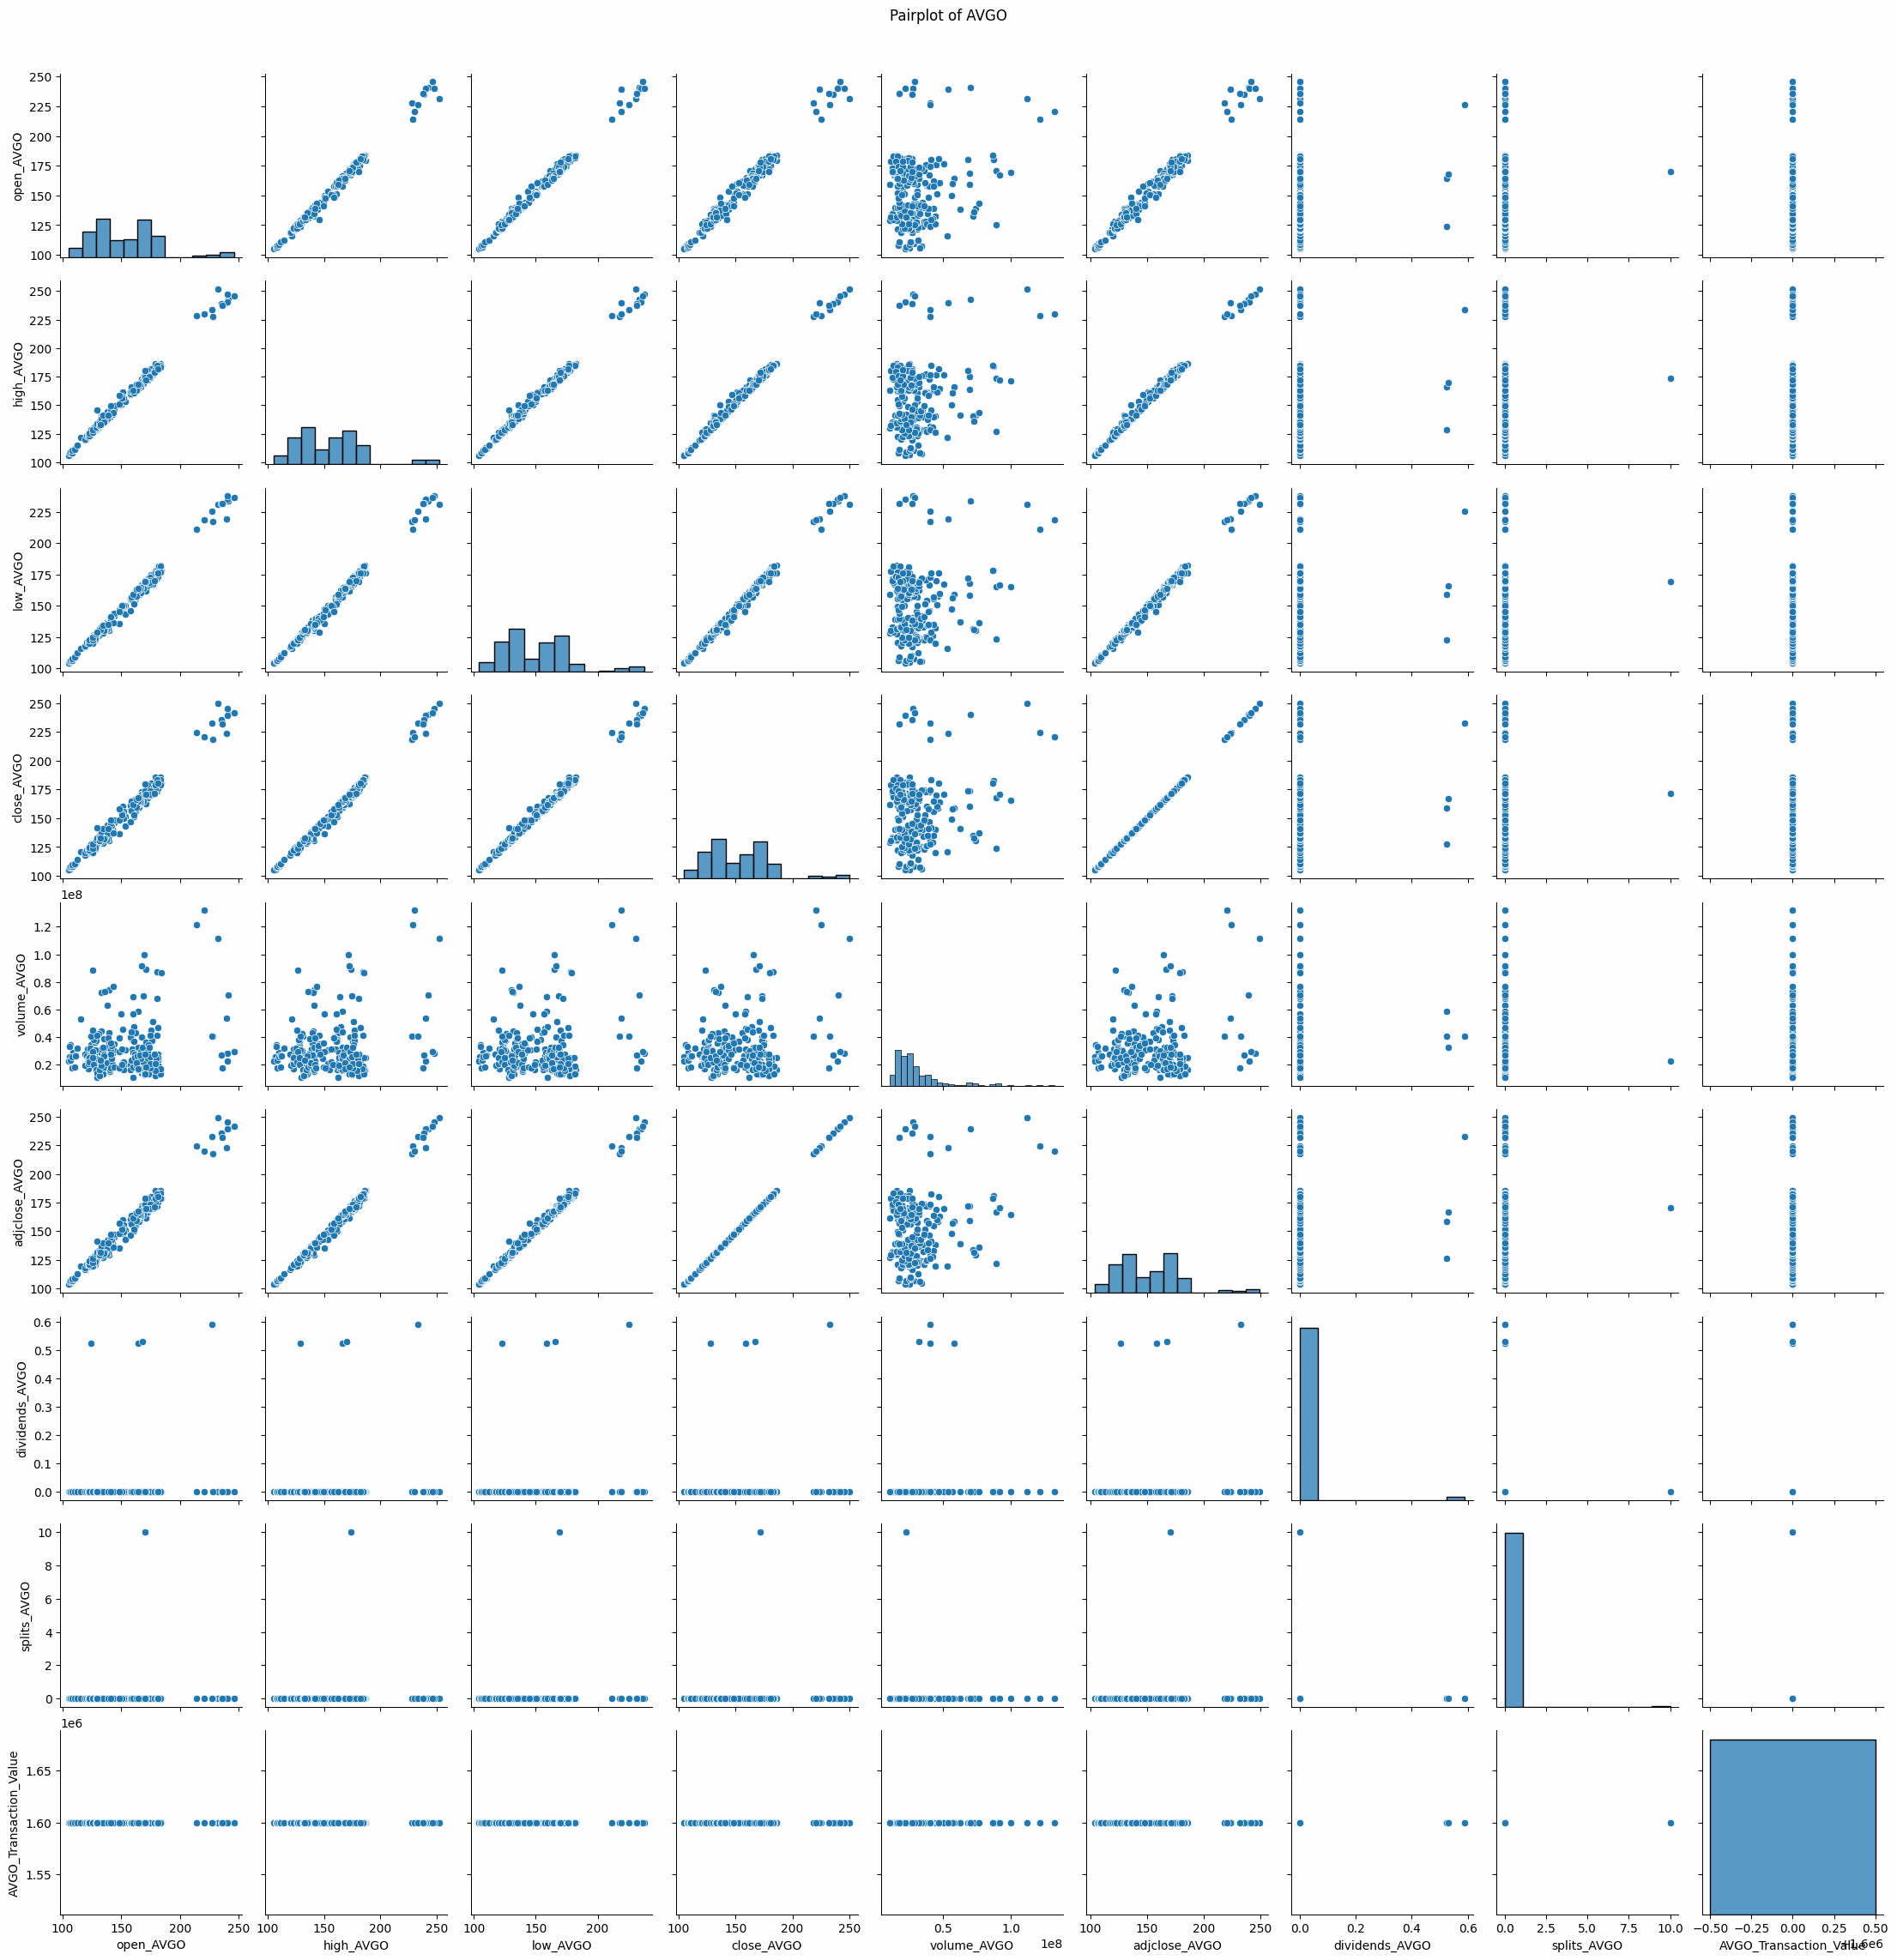

In [82]:
# Create a pairplot
sns.pairplot(df_avgo)
plt.suptitle('Pairplot of AVGO', y=1.02)
plt.show()


 **1. Key Observations from the Pairplot**
 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Correlation Among Price Variables:**  
  - The **open, high, low, close, and adjusted close prices** exhibit **near-perfect correlation** (close to **1.00**).  
  - This means **Broadcom’s stock follows predictable intra-day movements**, making it easier to track trends.

- **Business Implications:**  
  - **Momentum & Trend-Following Strategies Work Well:**  
    - Traders using **momentum indicators (RSI, moving averages)** could **effectively capitalize on price trends**.
  - **More Stable Compared to High-Volatility Tech Stocks Like Tesla:**  
    - Broadcom’s price movements show **less extreme fluctuations**, making it **suitable for long-term investors**.

---

 **Trading Volume vs. Stock Prices**
- **Moderate Correlation Between Volume and Stock Prices:**  
  - Unlike Tesla or NVIDIA, **AVGO’s price is somewhat affected by trading volume but not significantly**.
  - Volume spikes occur, but they **do not always translate into significant price movements**.

- **Business Implications:**  
  - **Institutional Investors Likely Play a Large Role:**  
    - **Lower correlation between volume and price movements suggests that Broadcom’s stock is primarily moved by institutional players rather than retail traders.**
  - **Less Speculative Than High-Growth Stocks:**  
    - The **absence of sharp price swings** indicates **Broadcom is more of a long-term value and growth stock rather than a trading stock**.

---

 **Volatility & Price Dispersion**
- **Broadcom Shows Less Price Dispersion Compared to High-Volatility Tech Stocks**  
  - The scatter plots suggest **more consistent pricing behavior** compared to **Tesla (TSLA) or NVIDIA (NVDA)**, which often experience **large swings**.

- **Business Implications:**  
  - **Lower Risk Profile for Long-Term Investors:**  
    - Broadcom’s **stability makes it attractive for investors looking for growth with lower downside risk**.
  - **Better Suited for Buy-and-Hold Investors Rather Than Short-Term Traders:**  
    - Unlike Tesla or NVIDIA, which appeal to **high-frequency traders**, Broadcom’s **price movements favor long-term investors**.

---

 **Dividends & Stock Splits**
- **Broadcom Pays Dividends, Unlike Some Tech Peers**  
  - Unlike Tesla or NVIDIA, **Broadcom has a history of paying dividends**, making it an attractive **income-generating stock**.

- **Occasional Stock Splits**  
  - Broadcom has had **stock splits in the past**, but not as frequently as companies like Apple.

- **Business Implications:**  
  - **Broadcom Appeals to Income Investors:**  
    - The presence of **dividends makes Broadcom a strong candidate for dividend growth portfolios**.
  - **Not Just a Growth Play—It Offers Stability:**  
    - Broadcom’s mix of **capital appreciation and dividends** provides a **balanced investment** compared to pure growth plays like Tesla.

---

 **2. Strategic Investment Insights**
- **Broadcom Is a Strong Candidate for Long-Term Growth & Stability:**  
  - Unlike speculative stocks, **AVGO offers predictable price movements, making it attractive to both institutional investors and retail investors seeking lower risk**.

- **It Is Less Volatile Than Other Tech Giants Like Tesla & NVIDIA:**  
  - **This makes Broadcom suitable for conservative investors** who want exposure to **semiconductors without extreme fluctuations**.

- **A Great Option for Dividend Growth Investors:**  
  - The **presence of dividends makes Broadcom unique** in the semiconductor sector, where most companies focus purely on growth.

---

 **3. Final Takeaways**
- **Broadcom (AVGO) is a strong, stable investment with less volatility than speculative tech stocks.**
- **Its price movements are highly correlated within the same day, making it easier to predict trends.**
- **It is suitable for long-term investors who seek dividend growth and capital appreciation.**
- **The company is likely driven more by institutional investors than retail traders.**  



## ROBLOX (RBLX)

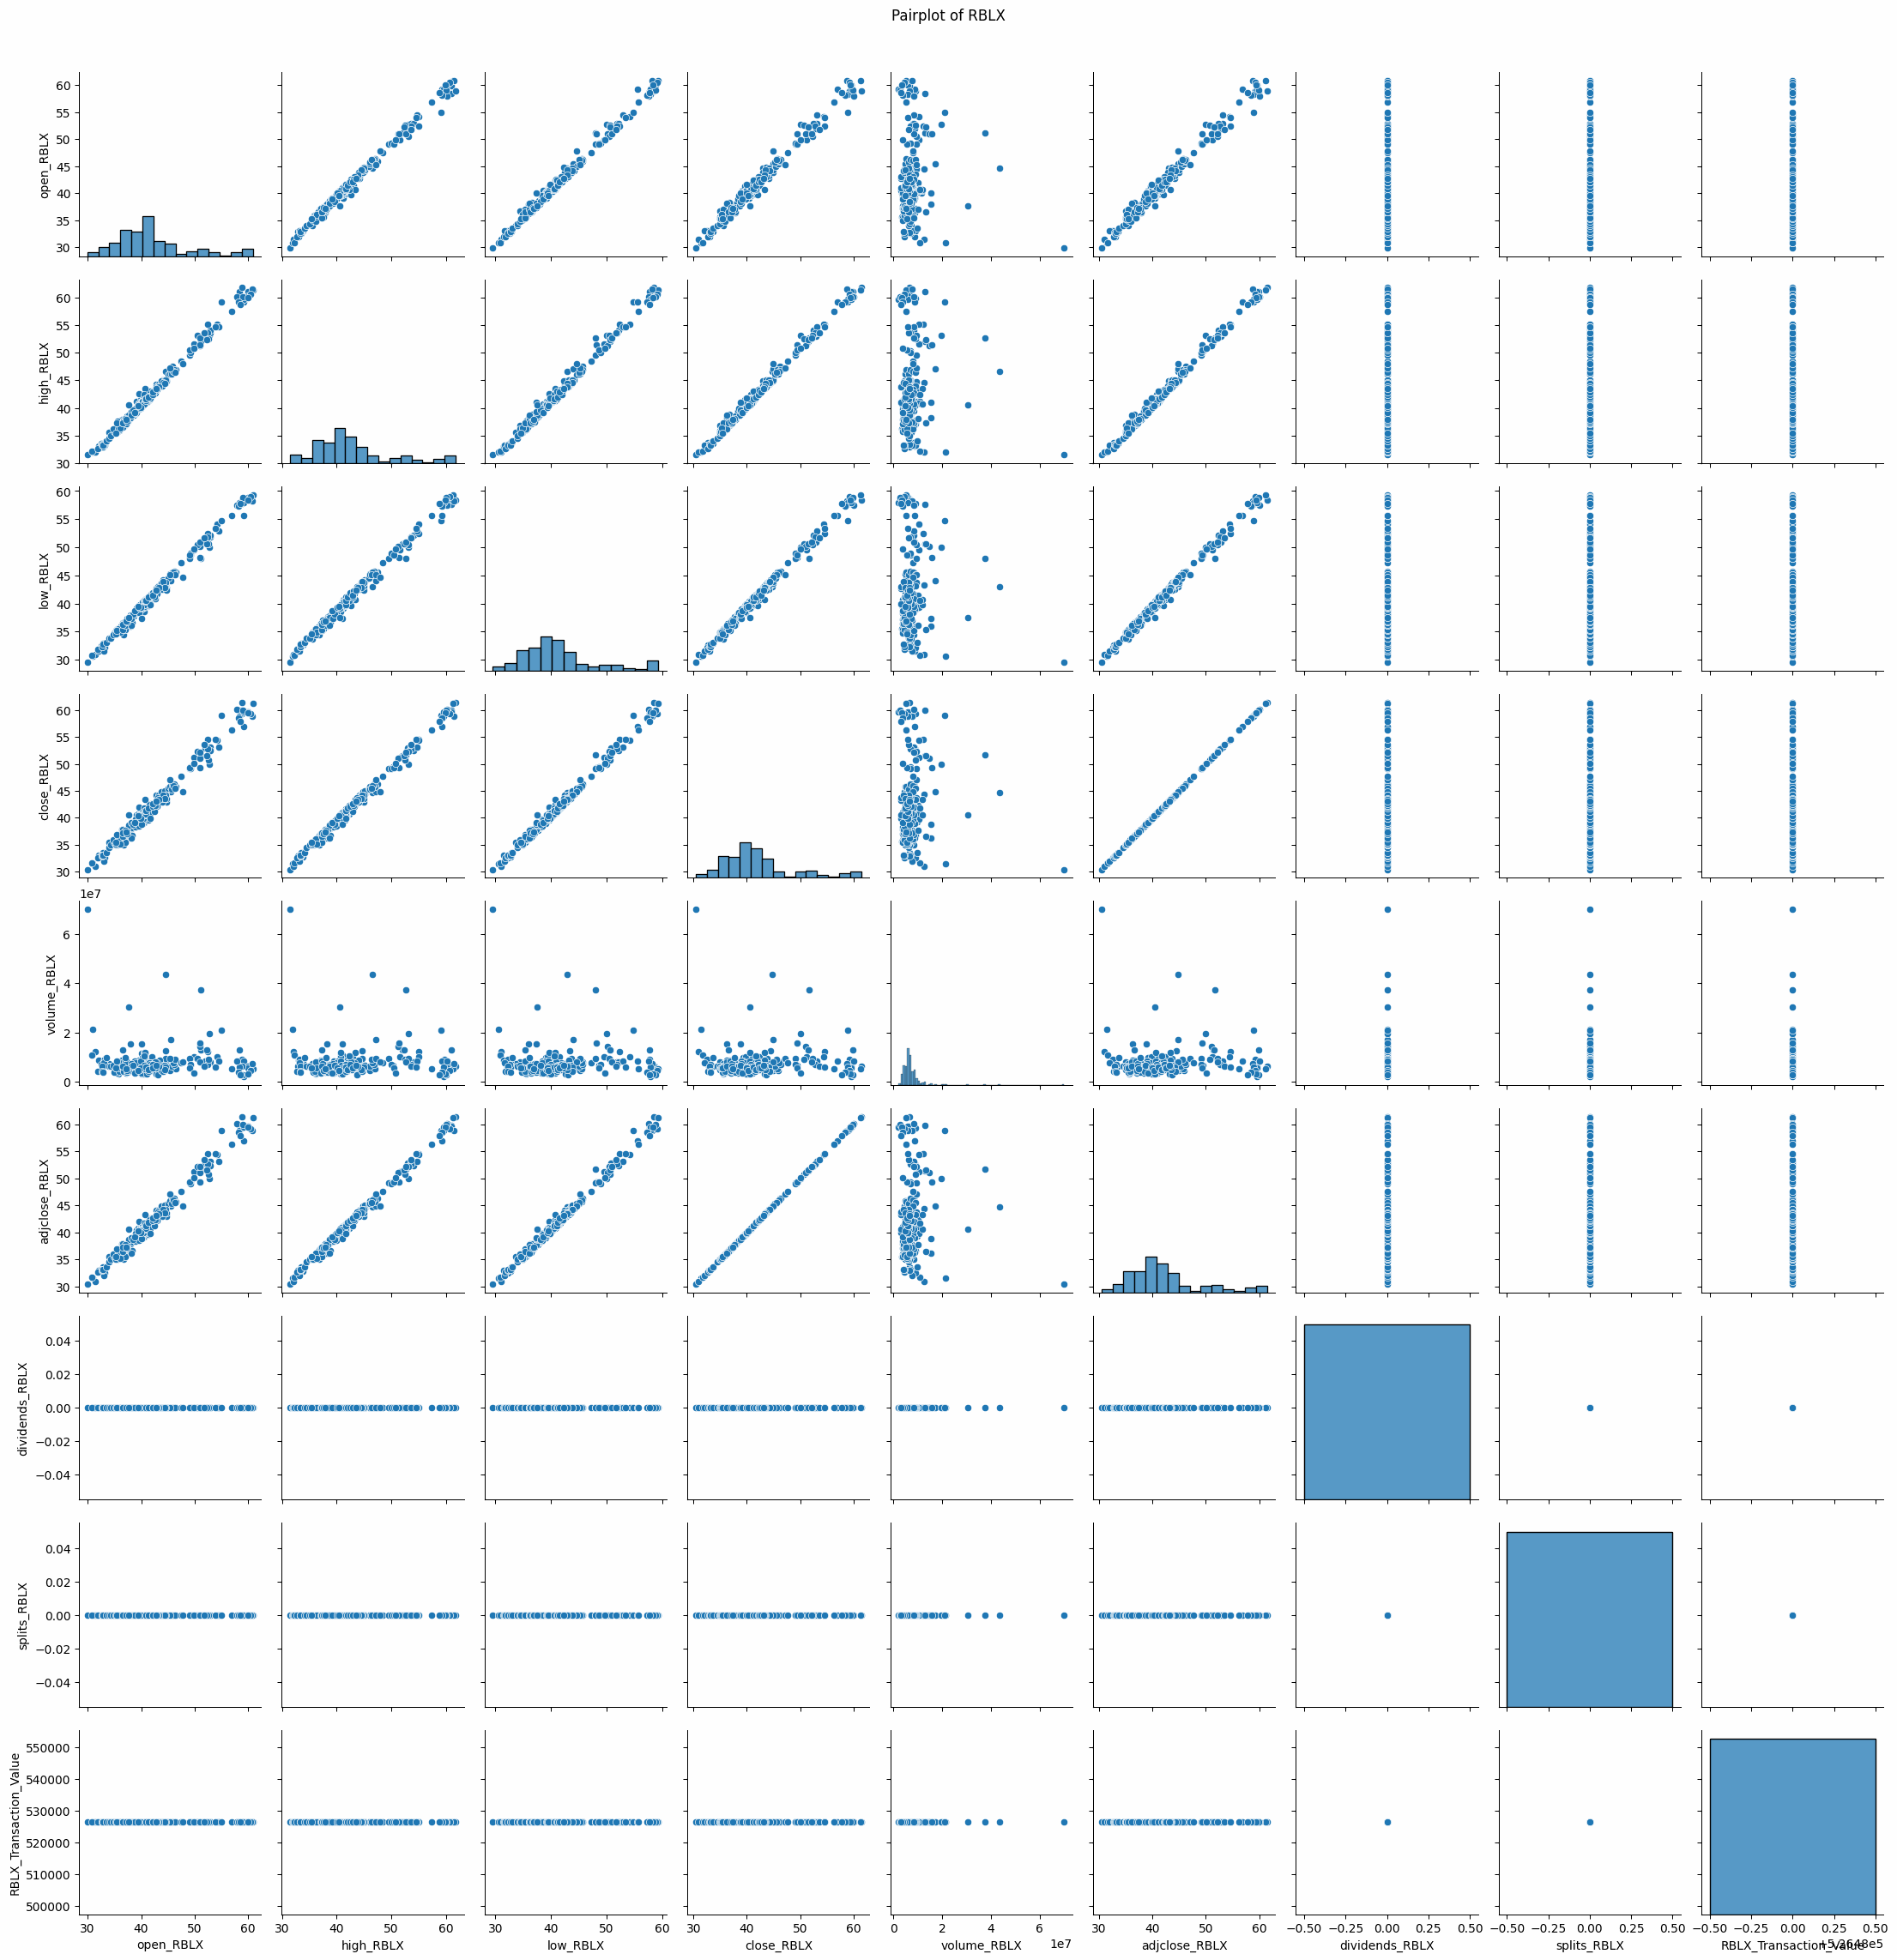

In [83]:
# Create a pairplot
sns.pairplot(df_rblx)
plt.suptitle('Pairplot of RBLX', y=1.02)
plt.show()

 **1. Key Observations from the Pairplot**
 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Near-Perfect Correlation Among Price Variables:**  
  - **Open, high, low, close, and adjusted close prices are highly correlated (~1.00)**, which is expected for most stocks.
  - This suggests that **price movements follow consistent daily trends**.

- **Business Implications:**  
  - **Price action strategies (support/resistance levels) are effective for traders.**
  - **Momentum traders can capitalize on intraday swings, but extreme volatility must be managed.**

---

 **Trading Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Price Movements**  
  - The scatter plots suggest **volume spikes do not directly drive price changes**.
  - Unlike other speculative stocks like Tesla, **Roblox’s price movements seem to be influenced by broader market sentiment rather than just volume surges**.

- **Business Implications:**  
  - **Roblox is highly sentiment-driven**—investors should watch market trends, earnings reports, and macroeconomic factors.
  - **Institutional investors likely have a strong influence on stock price movements.**

---

 **High Volatility and Price Dispersion**
- **Roblox shows a wider price dispersion compared to more established tech stocks like Microsoft or Apple.**
  - The pairplot reveals **scattered relationships, meaning prices fluctuate unpredictably.**

- **Business Implications:**  
  - **High volatility can lead to both quick gains and sharp declines.**
  - **Long-term investors should brace for large price swings and focus on fundamental growth.**

---

 **Dividends & Stock Splits**
- **Roblox does not pay dividends, reinforcing its high-growth focus.**
- **No major stock splits have been observed recently.**

- **Business Implications:**  
  - **Investors looking for income should look elsewhere (e.g., Apple, Broadcom).**
  - **Roblox’s stock is geared towards speculative and long-term growth investors.**

---

 **2. Strategic Investment Insights**
- **Roblox is a speculative, high-growth stock that is influenced by market sentiment rather than traditional trading volume.**
- **It is best suited for investors who are comfortable with volatility and are focused on long-term metaverse and gaming industry growth.**
- **Short-term traders may find opportunities in momentum trading, but risk management is crucial.**
- **Institutional investors likely play a key role in price stabilization.**


## VISA (V)

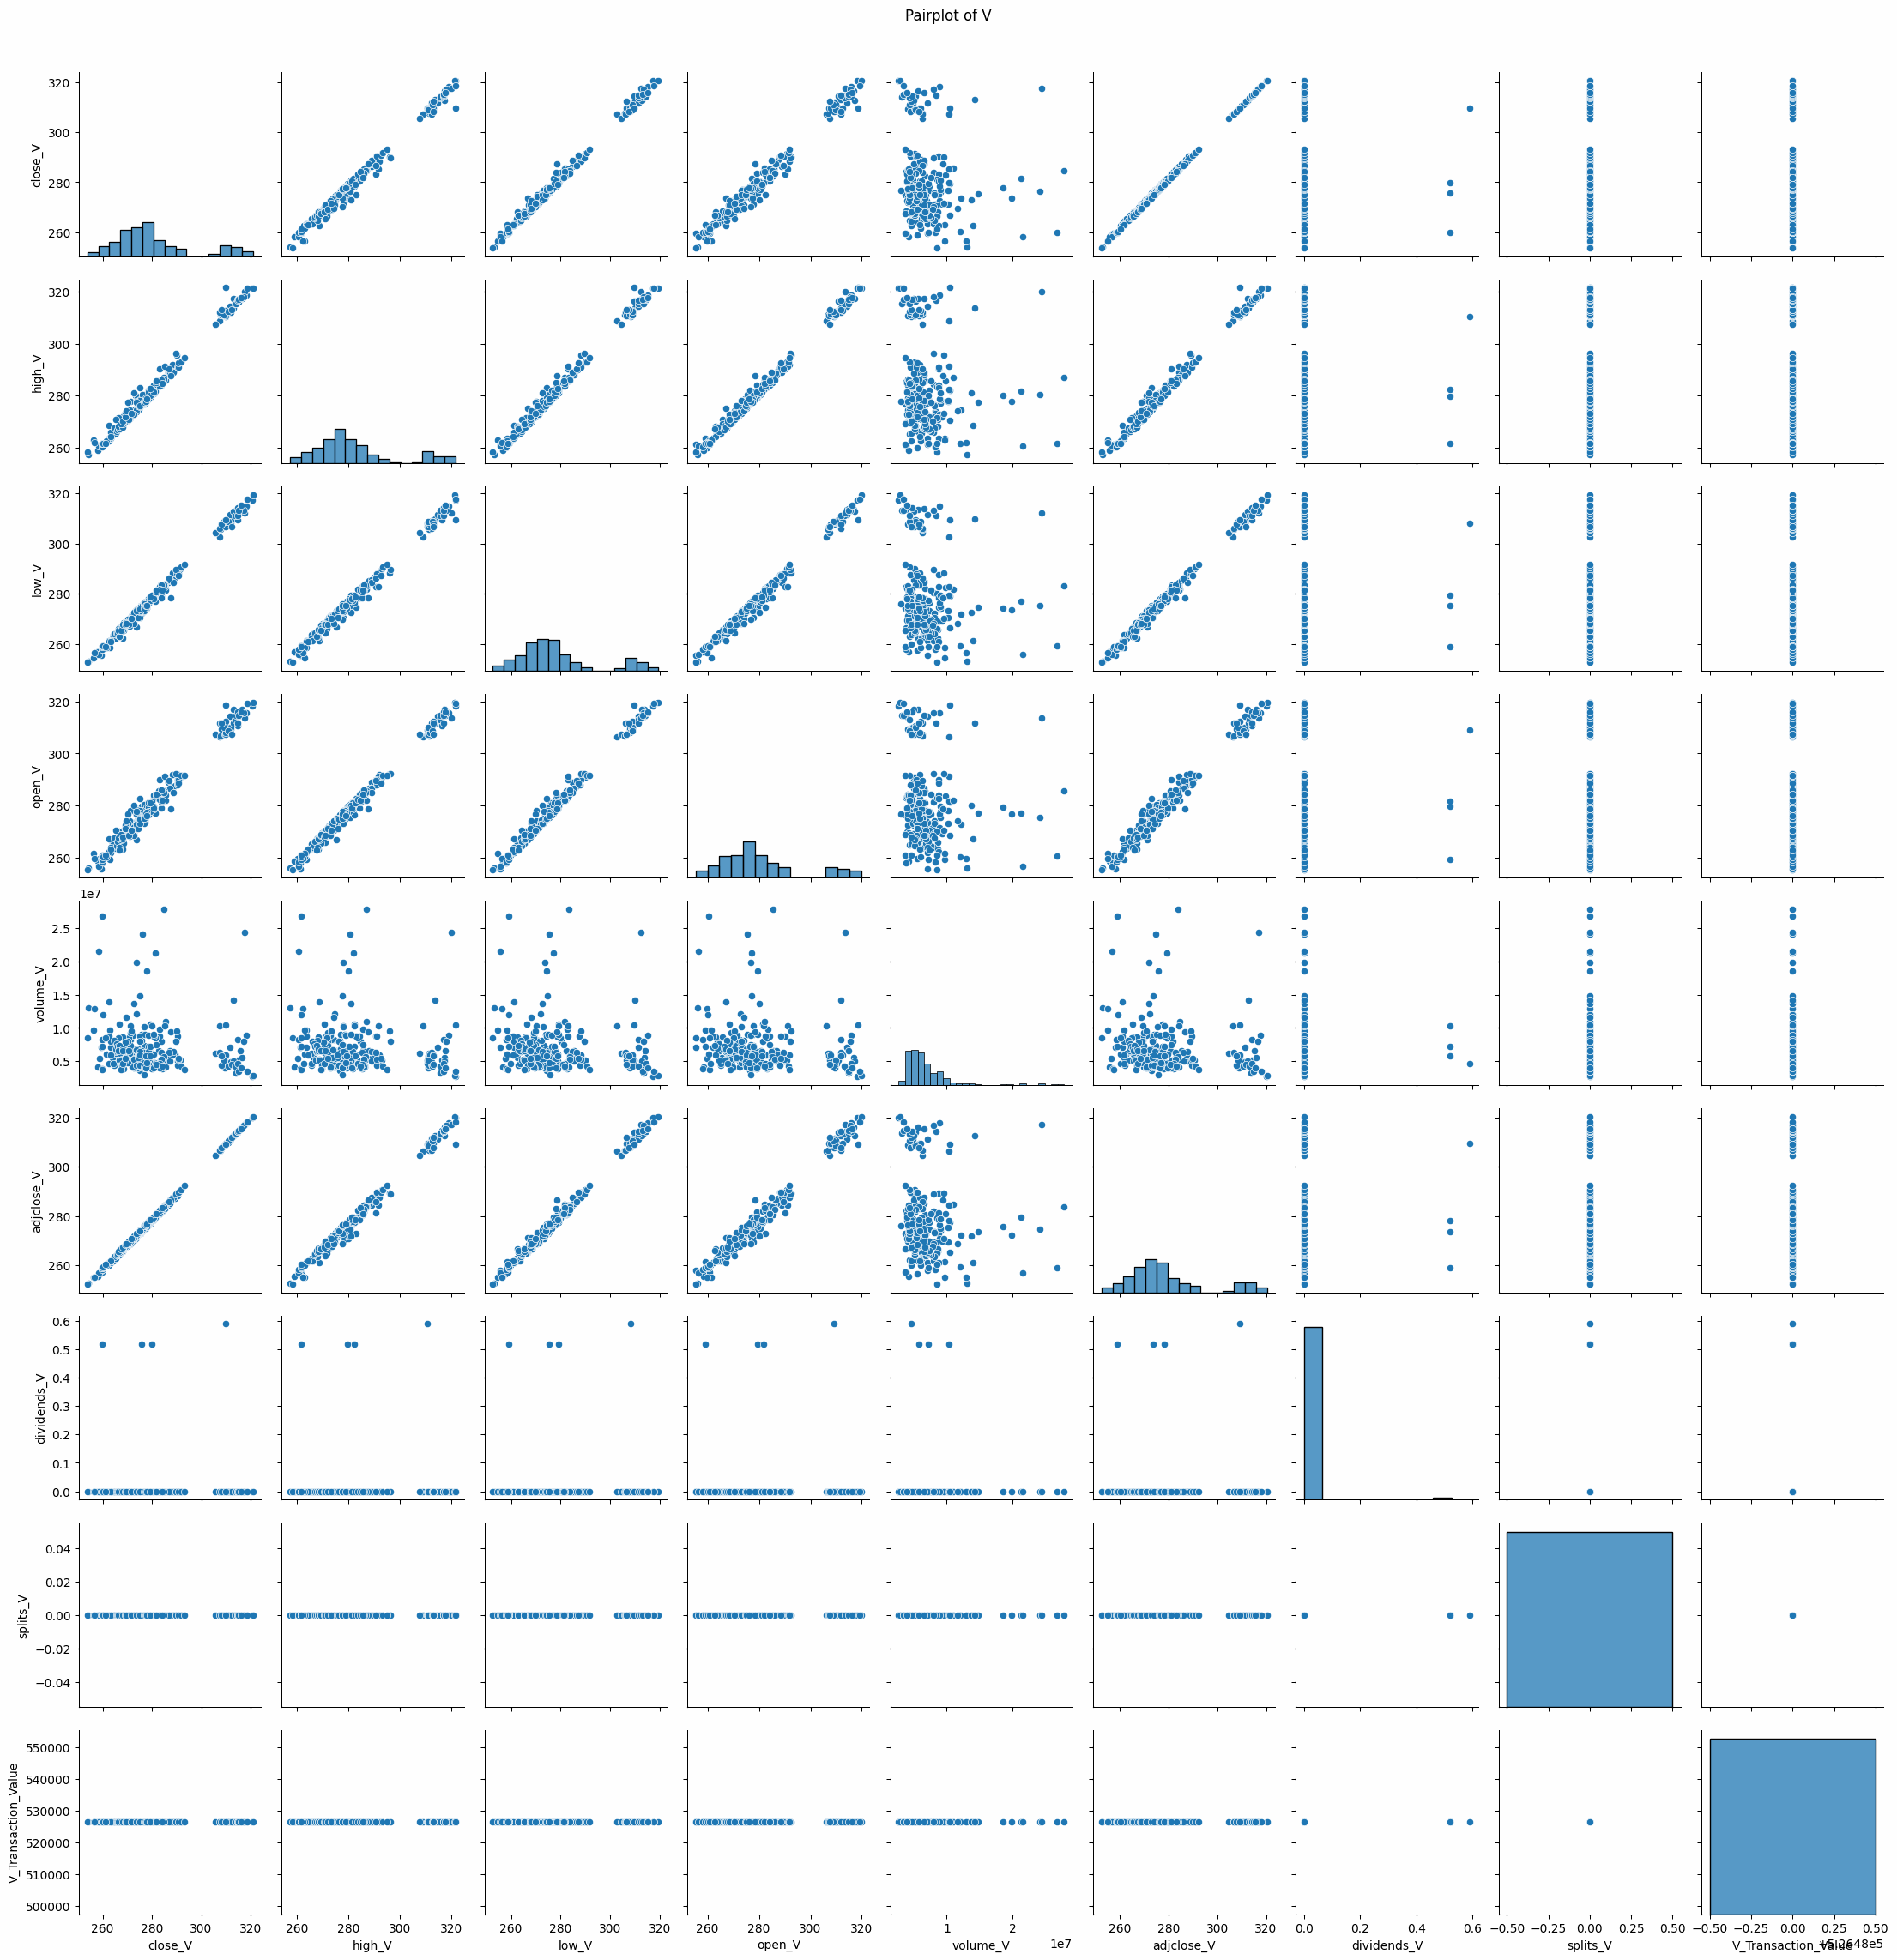

In [84]:
# Create a pairplot
sns.pairplot(df_v)
plt.suptitle('Pairplot of V', y=1.02)
plt.show()


 **1. Key Observations from the Pairplot**
 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Near-Perfect Correlation Among Price Variables (~1.00)**
  - The high, low, open, close, and adjusted close prices are highly correlated.
  - This indicates **low intraday volatility**, making it a **stable investment choice**.

- **Business Implications:**
  - **Visa is a strong long-term investment due to its predictable price movements.**
  - **Ideal for conservative investors and institutions looking for stability.**

---

 **Trading Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Stock Price Movements**
  - The scatter plots suggest **trading volume fluctuations do not significantly impact price changes**.
  - Unlike high-growth or speculative stocks, Visa’s price is primarily influenced by **earnings reports, macroeconomic conditions, and long-term fundamentals rather than short-term trading volume surges.**

- **Business Implications:**
  - **Visa’s stock price is resilient to market fluctuations and trading anomalies.**
  - **Long-term investors can benefit from its strong fundamentals without worrying about daily trading volume.**

---

 **Consistent Price Growth with Low Volatility**
- **The price scatter plots show a gradual increase with minimal extreme price movements.**
  - Unlike volatile stocks (e.g., Tesla or Roblox), Visa’s price action is **stable and slow-moving**.

- **Business Implications:**
  - **Visa is suitable for dividend investors and conservative portfolio strategies.**
  - **Its stable price movement makes it ideal for ETFs and index funds.**

---

 **Dividends & Stock Splits**
- **Visa pays consistent dividends, making it attractive to income investors.**
- **The stock has undergone occasional splits, but price appreciation is steady.**

- **Business Implications:**
  - **Dividend-focused investors can rely on Visa for consistent passive income.**
  - **Stock splits have little impact on long-term valuation but improve liquidity.**

---

 **2. Strategic Investment Insights**
- **Visa is a defensive, blue-chip stock with strong fundamentals and predictable price trends.**
- **Its stock price is stable and ideal for long-term investors focused on dividends and capital preservation.**
- **Unlike tech or speculative stocks, Visa is resilient to market fluctuations, making it a good hedge during economic downturns.**
- **Trading volume does not significantly affect price movements, reinforcing its role as a stable investment choice.**



## SALESFORCE (CRM)

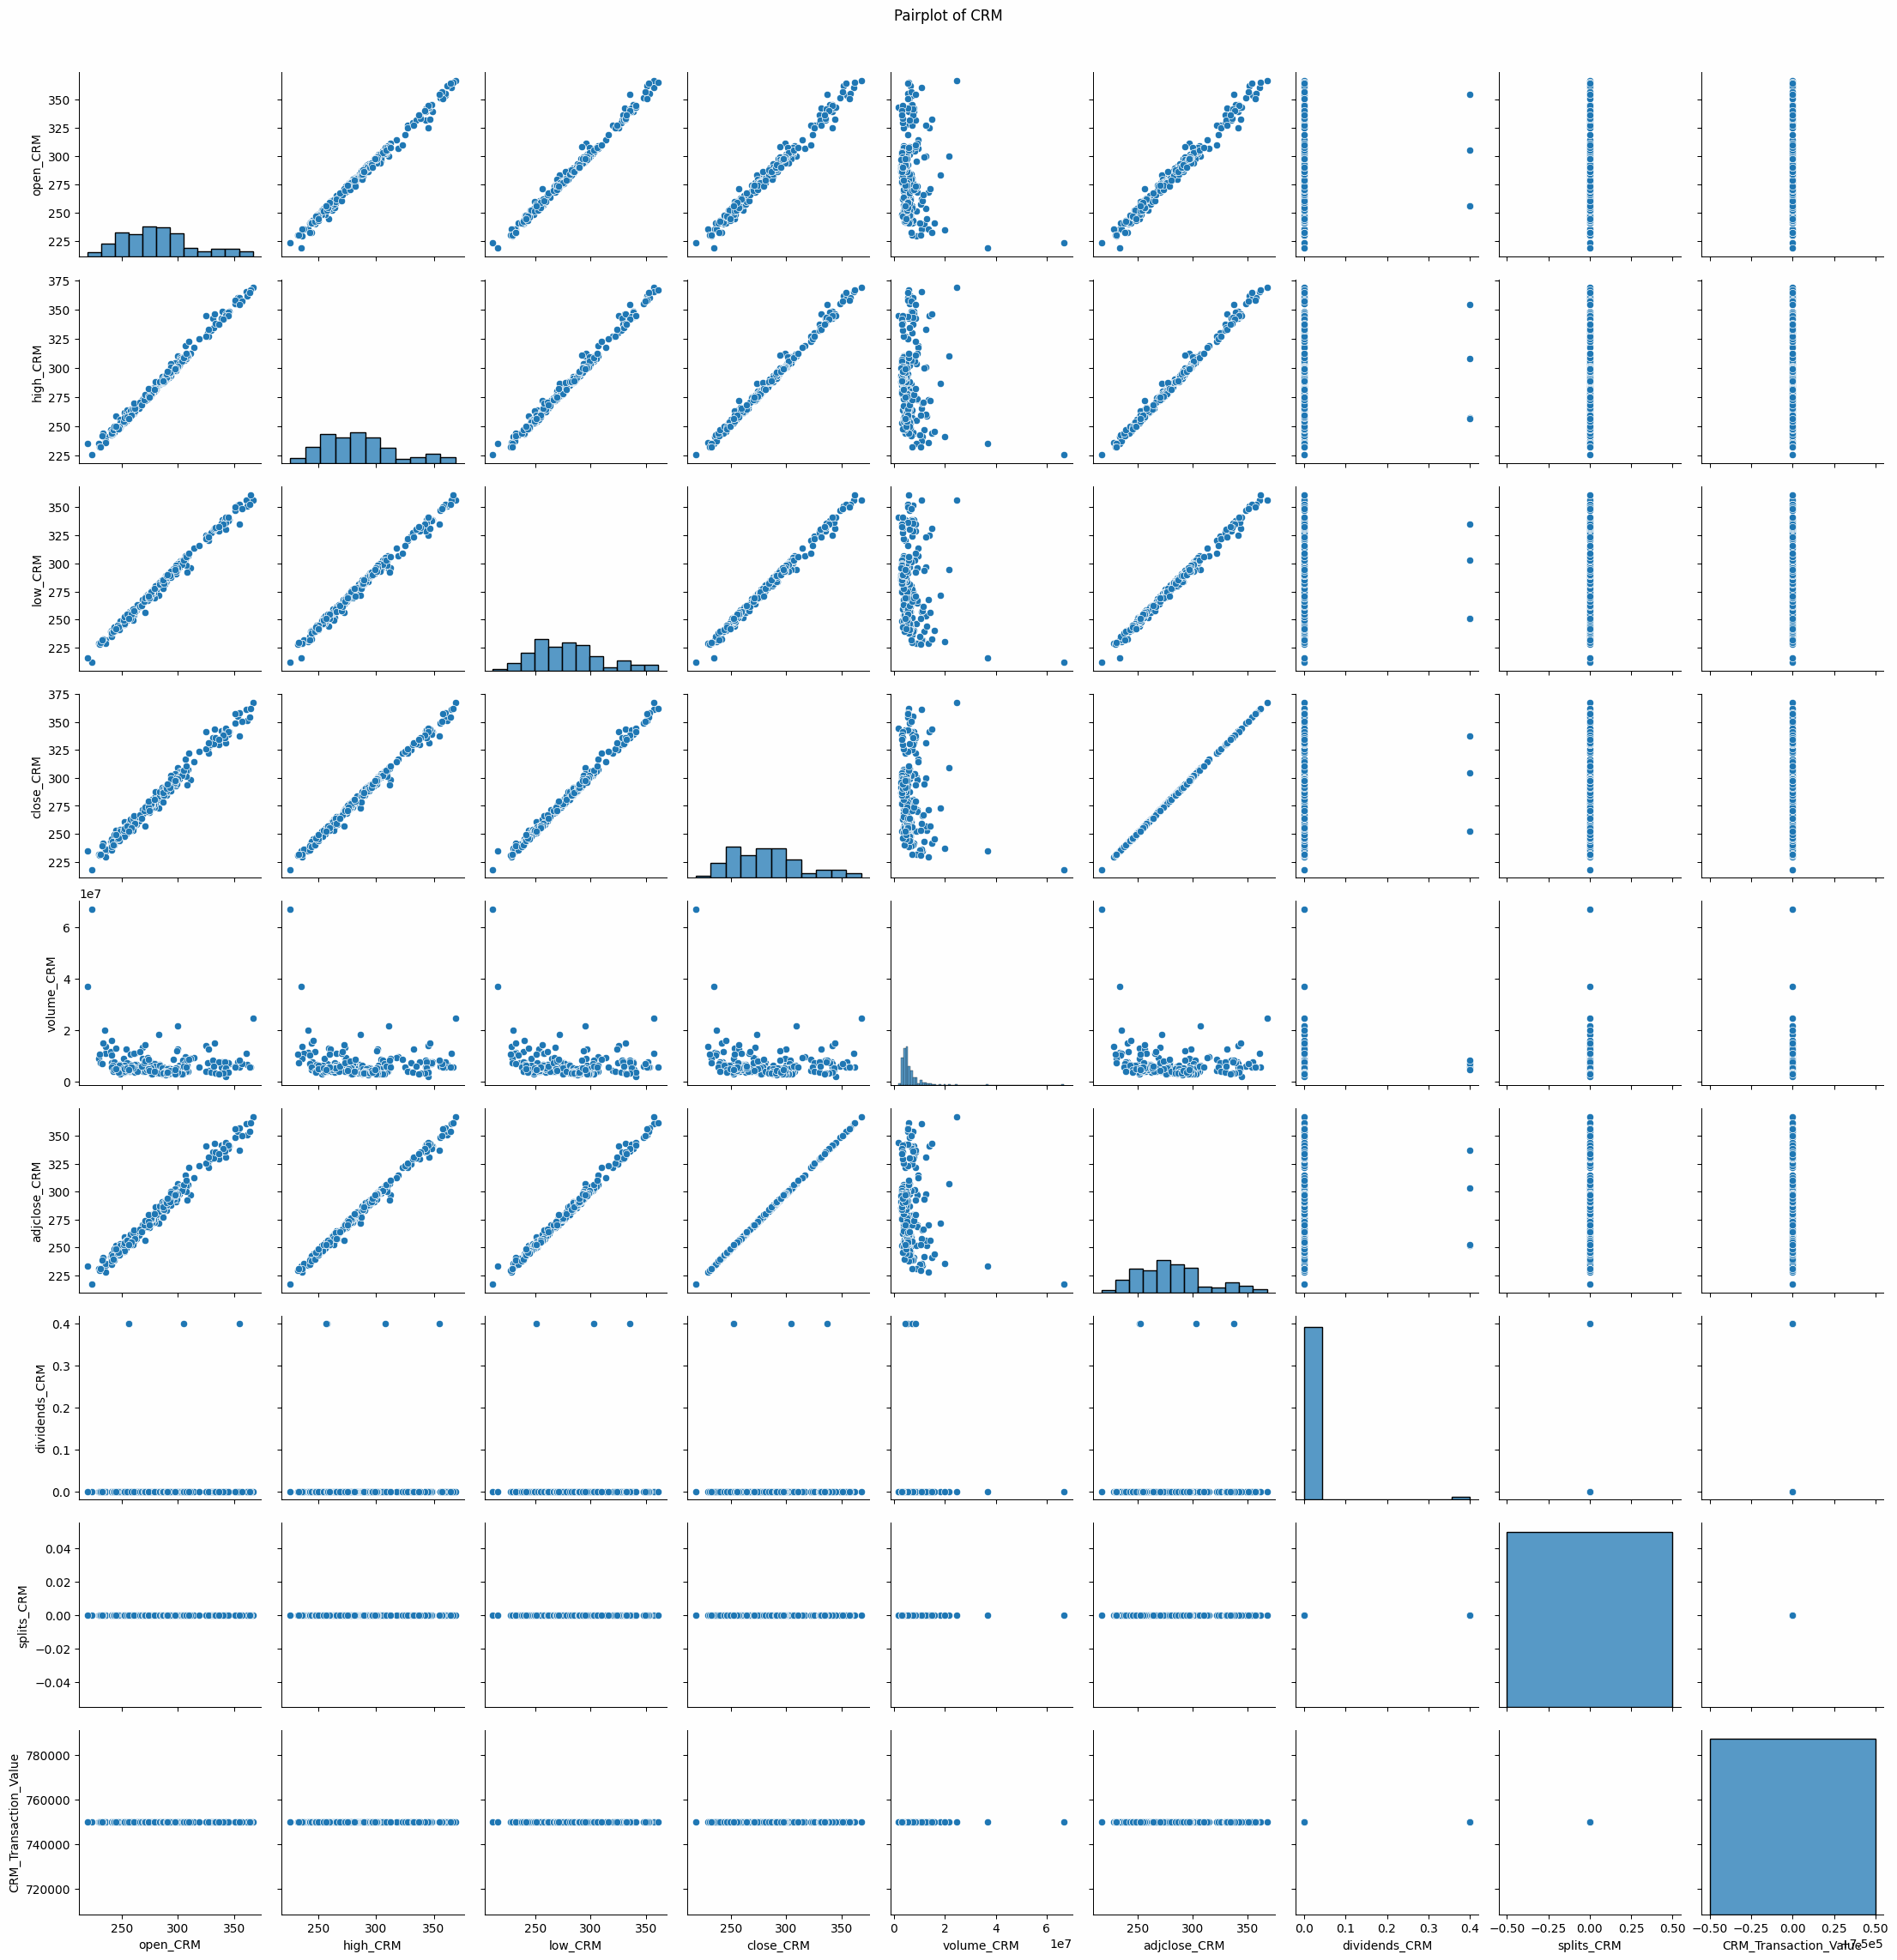

In [85]:
# Create a pairplot
sns.pairplot(df_crm)
plt.suptitle('Pairplot of CRM', y=1.02)
plt.show()


 **1. Key Observations from the Pairplot**
 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Correlation Among Price Variables (~1.00)**
  - Open, high, low, close, and adjusted close prices are almost perfectly correlated.
  - This suggests **low intraday volatility**, similar to other blue-chip tech stocks.

- **Business Implications:**
  - **CRM stock price follows a steady trend, making it attractive to institutional investors.**
  - **Ideal for long-term investors who prefer stable growth stocks.**

---

 **Trading Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Stock Prices**
  - Trading volume fluctuations do not have a significant impact on price changes.
  - This indicates that **fundamentals, earnings reports, and macroeconomic conditions drive CRM stock more than short-term trading volume spikes.**

- **Business Implications:**
  - **CRM is less susceptible to speculative trading and is fundamentally strong.**
  - **Long-term investors can rely on it for consistent growth without worrying about trading volume fluctuations.**

---

 **Stable Growth with Some Outliers**
- **Price scatter plots show a stable upward trend with occasional outliers.**
  - This suggests that **CRM experiences occasional sharp price movements, possibly after earnings reports or market-wide trends.**

- **Business Implications:**
  - **CRM is a solid growth stock but may have short-term volatility after earnings releases.**
  - **Ideal for investors with medium- to long-term horizons who can withstand occasional dips.**

---

 **Dividends & Stock Splits**
- **Salesforce does not pay significant dividends.**
- **No major stock splits, meaning price appreciation is purely organic.**

- **Business Implications:**
  - **CRM is a capital appreciation stock, not a dividend-paying investment.**
  - **Investors looking for passive income should consider alternatives like Microsoft (MSFT) or Visa (V).**

---

 **2. Strategic Investment Insights**
- **CRM is a strong growth stock with predictable price movements.**
- **Its stock price is driven by long-term fundamentals rather than short-term volume spikes.**
- **There is occasional volatility around earnings reports, making it an interesting swing trade opportunity.**
- **It is ideal for investors seeking growth without relying on dividend income.**



## WALT DISNEY (DIS)

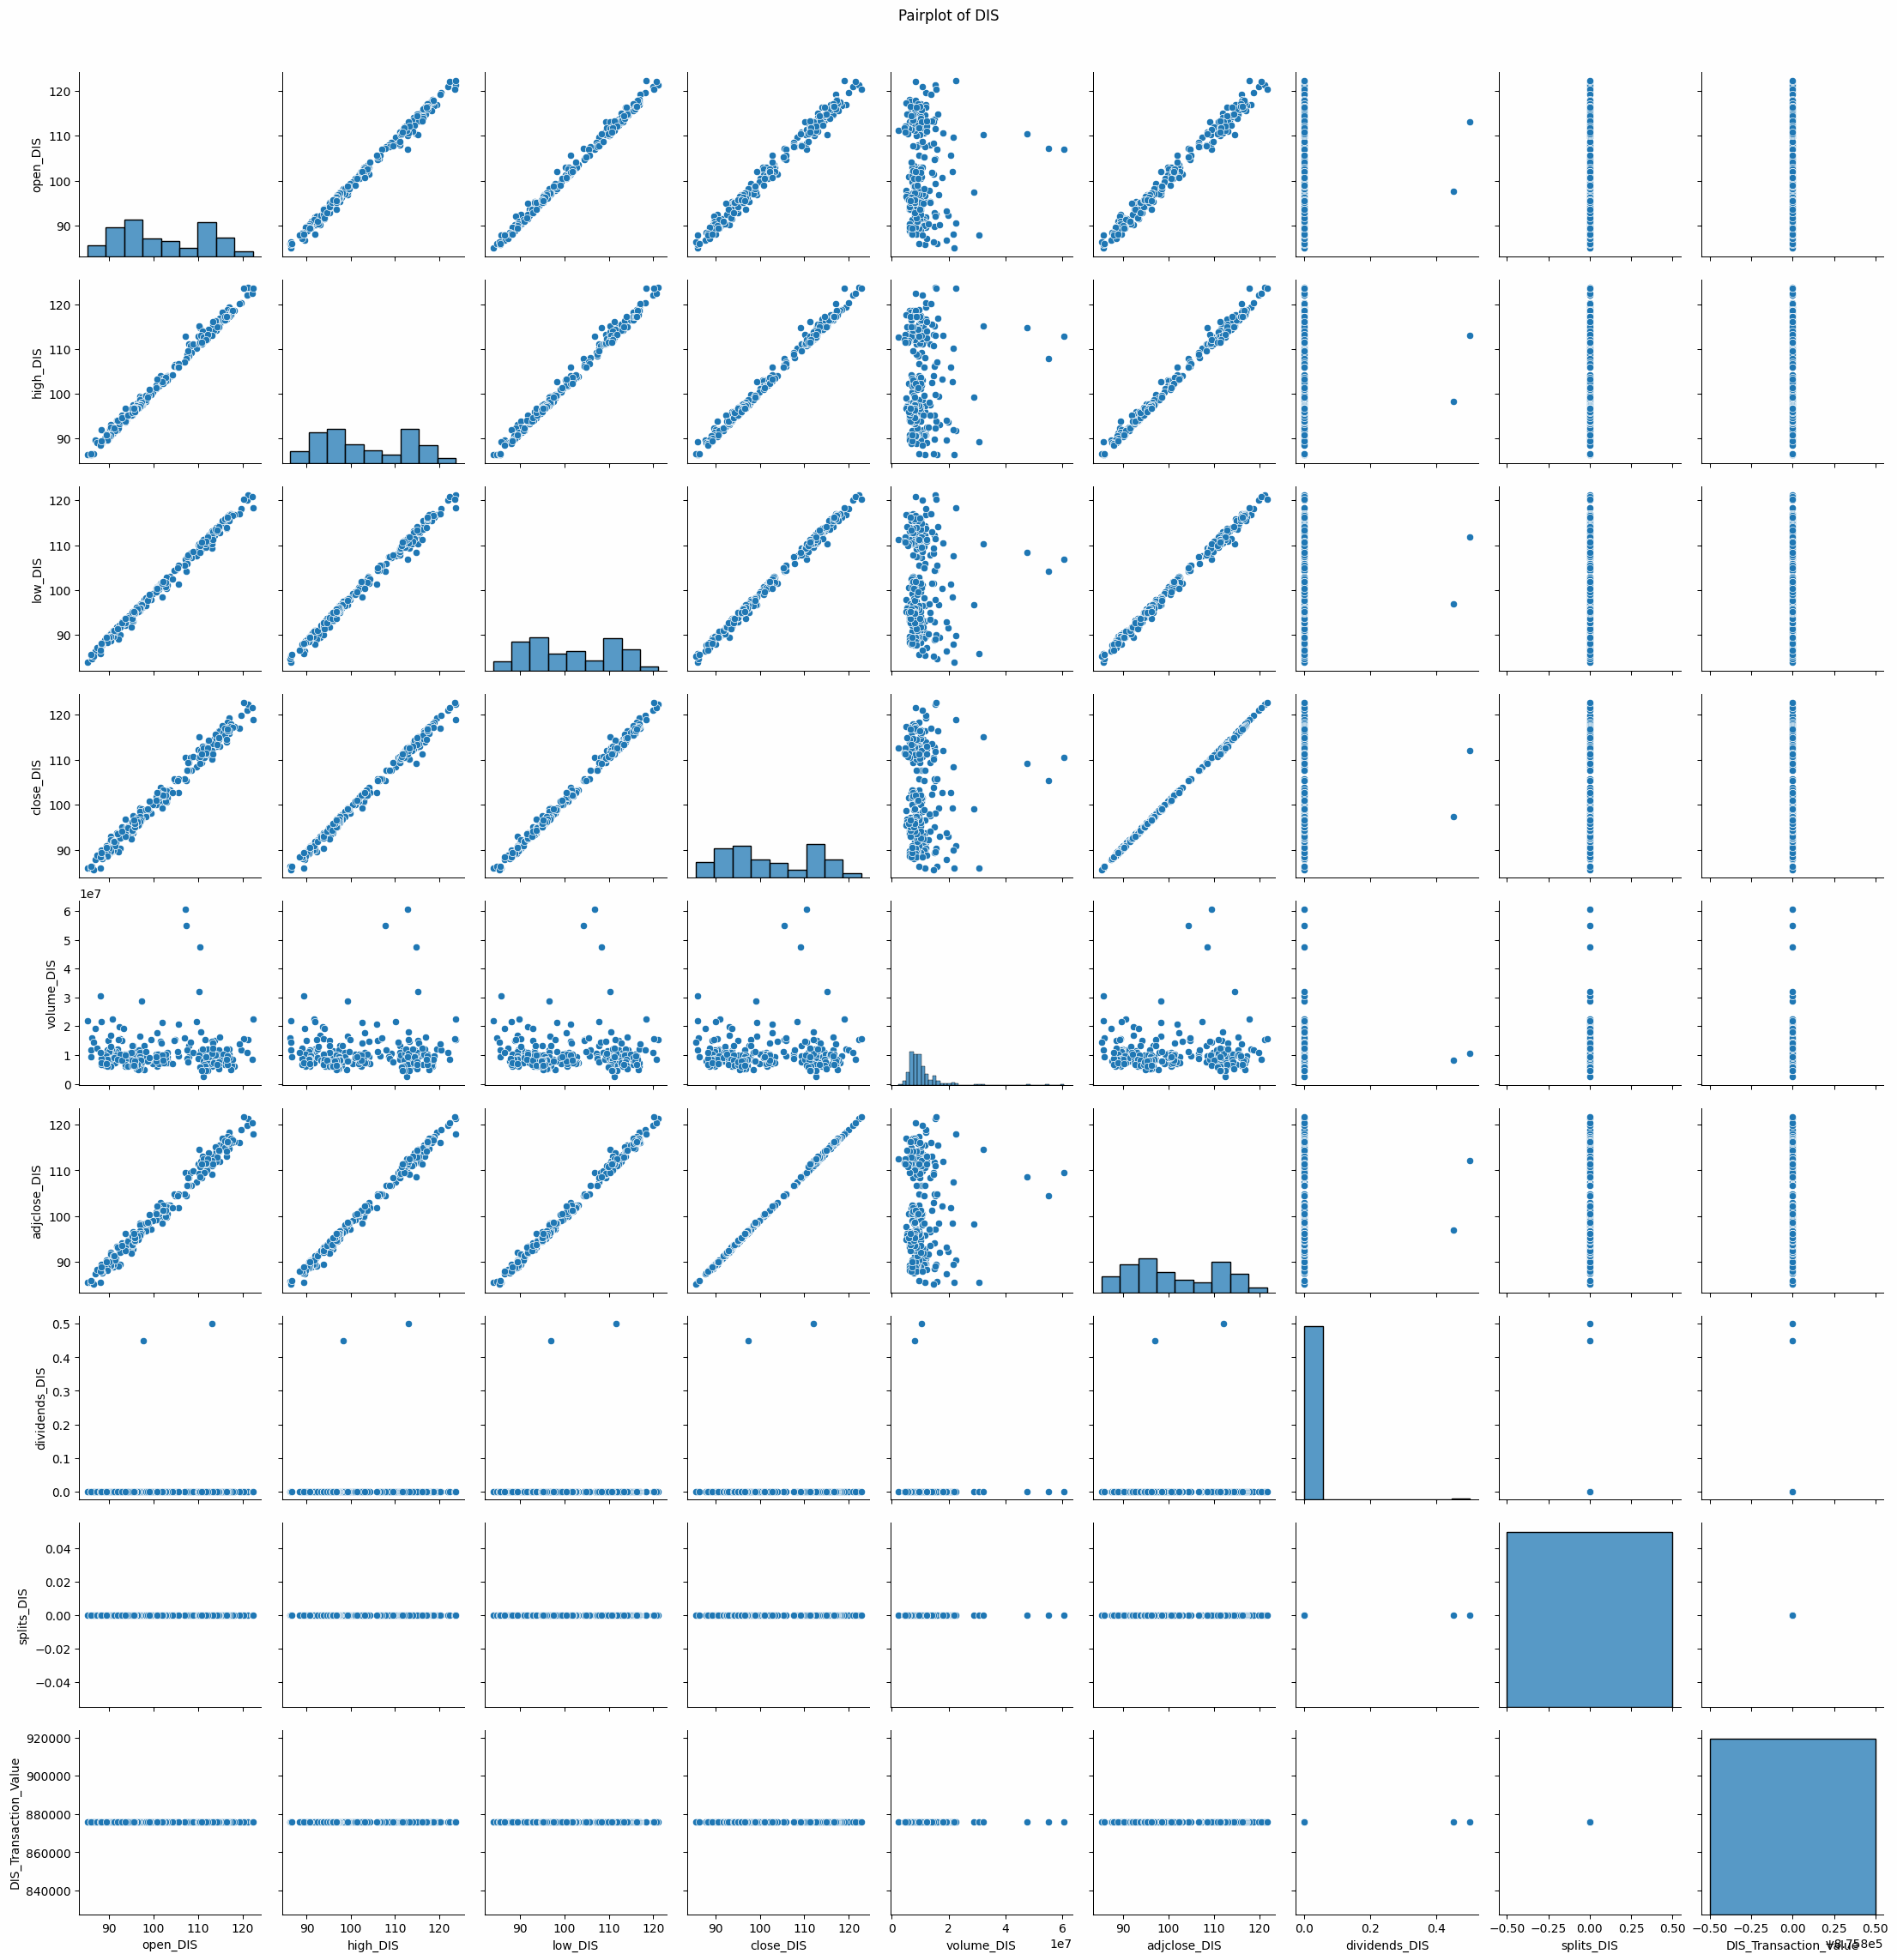

In [86]:
# Create a pairplot
sns.pairplot(df_dis)
plt.suptitle('Pairplot of DIS', y=1.02)
plt.show()

 **1. Key Observations from the Pairplot**
 **Stock Prices (Open, High, Low, Close, Adjusted Close)**
- **Strong Correlation (~1.00) Between Price Variables**
  - Open, high, low, close, and adjusted close prices are almost perfectly correlated.
  - This indicates **Disney’s stock follows a relatively predictable pattern with steady price movements.**

- **Business Implications:**
  - **DIS is a relatively stable stock with well-established trading patterns.**
  - **Investors can rely on historical trends for long-term investment strategies.**
  - **Limited intraday volatility, making it a safer option for conservative investors.**

---

 **Trading Volume vs. Stock Prices**
- **Weak Correlation Between Volume and Price Movements**
  - Price changes are not significantly affected by trading volume spikes.
  - This suggests that **DIS is primarily influenced by earnings reports, content releases (e.g., Marvel, Star Wars), and macroeconomic factors rather than speculative trading.**

- **Business Implications:**
  - **Long-term investors benefit from Disney’s brand strength rather than short-term volume fluctuations.**
  - **Investors should focus on revenue growth, theme park performance, and streaming success (Disney+) rather than daily volume trends.**

---

 **Price Stability and Outliers**
- **Stock prices follow a stable upward trend with occasional outliers.**
  - This suggests **Disney’s stock remains resilient, with occasional volatility after earnings reports, park closures, or major content releases.**

- **Business Implications:**
  - **DIS stock is ideal for long-term investors seeking steady growth.**
  - **Short-term traders may find opportunities around earnings and major movie releases.**

---

 **Dividends & Stock Splits**
- **Disney historically paid dividends but suspended them in 2020 due to COVID-19.**
- **No significant stock splits in recent years.**

- **Business Implications:**
  - **DIS is traditionally a dividend stock but currently reinvests earnings into content and theme park expansion.**
  - **Investors looking for dividend income may need to explore alternative stocks like Coca-Cola (KO) or Procter & Gamble (PG).**

---

 **2. Strategic Investment Insights**
- **Disney’s stock is a stable long-term investment with predictable price movements.**
- **Earnings, streaming growth (Disney+), and theme park performance drive stock performance rather than short-term trading volume.**
- **Occasional volatility after earnings and major content releases provides swing trade opportunities.**
- **Lack of dividends makes it less appealing for income-focused investors.**



# MODIFICATION

In this selection we look at the different modication methods that can be applied to a DataFrame: Standardization and Normalization. These methods are helping when comparing a DataFrame's boxplots so show the outliers.

- Standardization is a method that is used to standardized a DataFrame where the mean is 0 and the standard deviation is 1.
- Normalization is a method that is used to normalized a DataFrame between 1 and 0.

## NVIDA (NVDA)

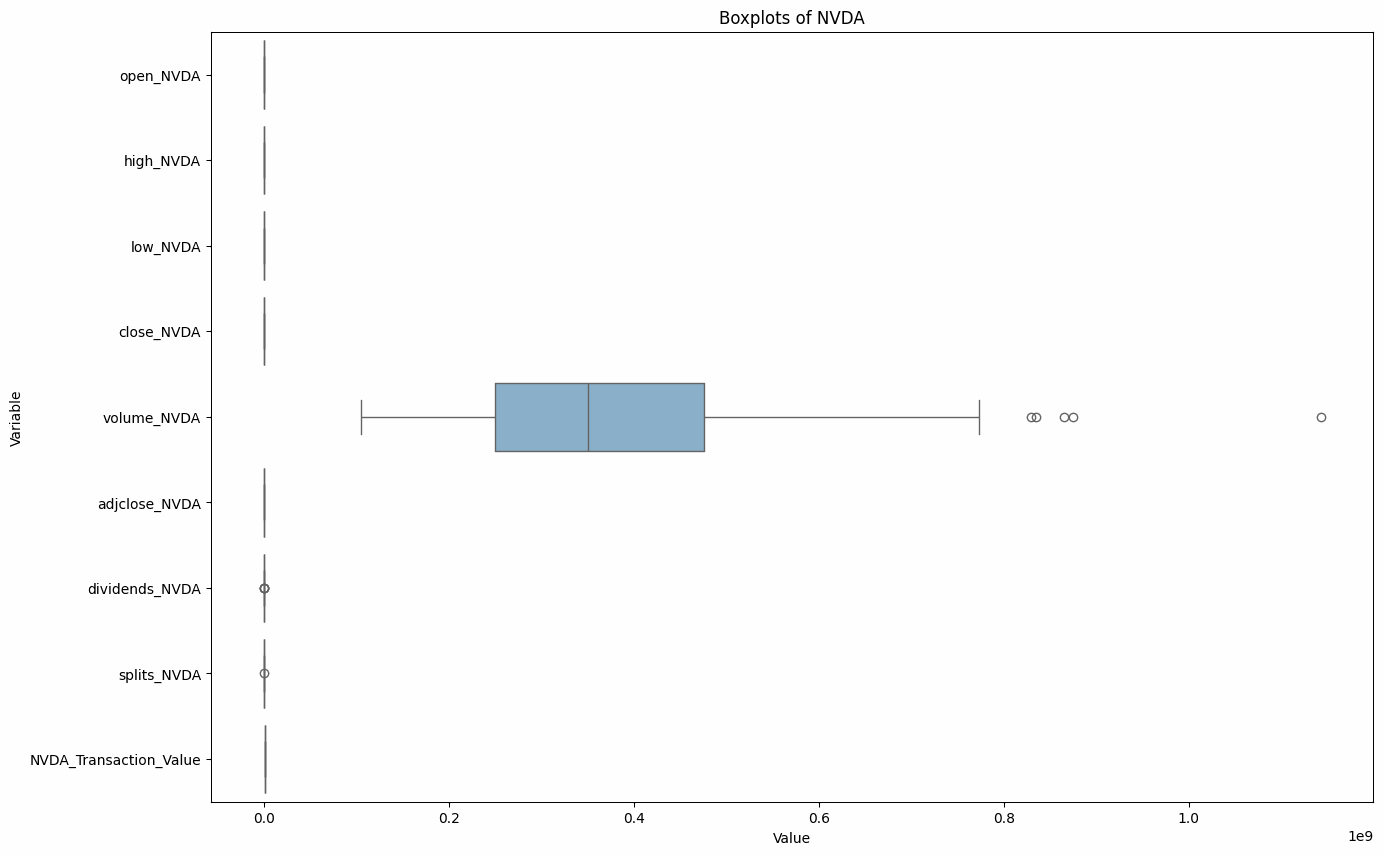

In [87]:
# Create one graph of all boxplots in NVDA
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_nvda, orient='h', palette='Set3')
plt.title('Boxplots of NVDA')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

1. Boxplots Before and After Standardization
First Boxplot (Original Data)

The first boxplot presents the raw, unmodified NVDA data.
The volume and transaction value variables dominate the scale, making it hard to compare other variables.
Some outliers are already visible, particularly in volume, dividends, and transaction values.
Second Boxplot (Standardized Data)

Standardization (Z-score transformation) brings all variables to a common scale (mean = 0, standard deviation = 1).
This allows for direct comparisons across variables.
Outliers become more apparent, as extreme values move farther from the mean.
The dataset becomes more suitable for machine learning models that assume normally distributed data.

### STANDARDIZING

In [88]:
# Create StandardScaler and apply to numerical columns
scaler_nvda = StandardScaler()
scaled_values_nvda = scaler_nvda.fit_transform(df_nvda[num_cols_nvda])

# Create new DataFrame and display
df_scaled_nvda = pd.DataFrame(scaled_values_nvda, columns=num_cols_nvda)
display(df_scaled_nvda.head())
print('\t')

,open_NVDA,high_NVDA,low_NVDA,close_NVDA,volume_NVDA,adjclose_NVDA,dividends_NVDA,splits_NVDA,NVDA_Transaction_Value
0,-2.165083,-2.211493,-2.188149,-2.217436,0.209845,-2.217072,-0.12137,-0.063119,0.0
1,-2.230011,-2.252065,-2.198517,-2.239701,-0.349462,-2.239328,-0.12137,-0.063119,0.0
2,-2.219602,-2.240525,-2.191429,-2.223755,-0.438355,-2.223389,-0.12137,-0.063119,0.0
3,-2.193948,-2.202290,-2.161342,-2.182906,0.233274,-2.182556,-0.12137,-0.063119,0.0
4,-2.155190,-2.102667,-2.117116,-2.065599,1.641297,-2.065297,-0.12137,-0.063119,0.0


2. Standardized DataFrame (Code Output)
The standardization transformation is applied using StandardScaler().
The transformed dataset has:
Mean values close to zero.
Standard deviations of approximately one.
Outliers still present but now more distinguishable.

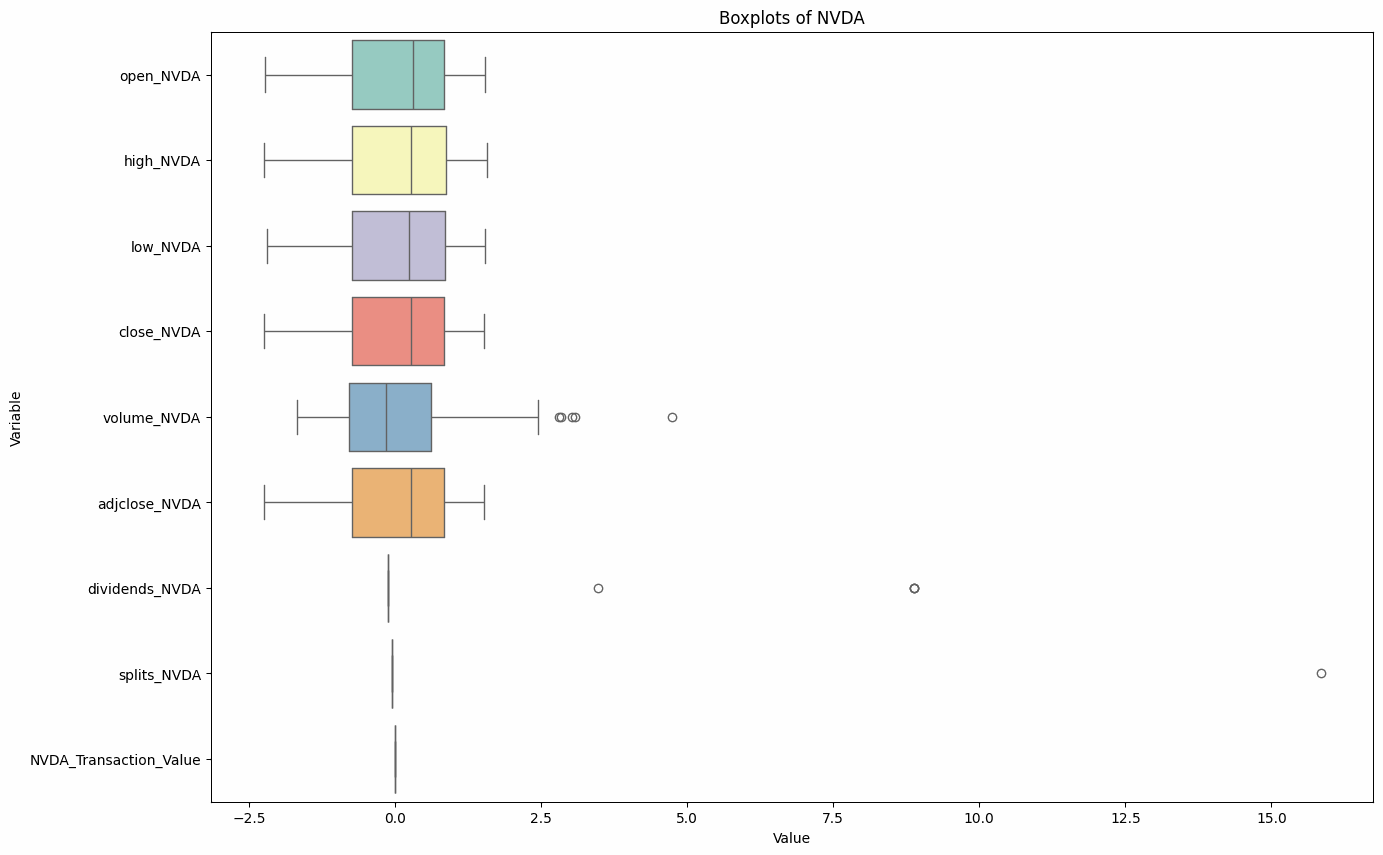

In [89]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_nvda, orient='h', palette='Set3')
plt.title('Boxplots of NVDA')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

**Comparison of Standardization and Normalization**  

**Raw Data** refers to the original values without any transformation. It is useful for simple data visualization where absolute values need to be maintained. However, outliers are present but difficult to compare due to differences in scale across variables.  

**Standardization (Z-score transformation)** rescales the data so that the mean is 0 and the standard deviation is 1. This method is best used when the data follows a normal distribution and is applied in regression models and distance-based algorithms such as K-Nearest Neighbors (KNN) and Support Vector Machines (SVM). Standardization makes features comparable by highlighting outliers, which become more distinguishable from the mean.  

**Normalization (Min-Max Scaling)** transforms the data by rescaling values between 0 and 1. This technique is ideal when feature ranges vary greatly and when the data is not normally distributed. While outliers remain in the dataset, they are compressed towards the 0-1 range, making their impact less extreme than in standardization.

In [90]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_nvda[num_cols_nvda], df_scaled_nvda))
print("MSE:", mean_squared_error(df_nvda[num_cols_nvda], df_scaled_nvda))
print("RMSE:", np.sqrt(mean_squared_error(df_nvda[num_cols_nvda], df_scaled_nvda)))
print("Residuals:", df_nvda[num_cols_nvda] - df_scaled_nvda)

	
R2, MSE, RMSE, and Residuals
R2: -89722.31348320459
MSE: 1.8721830875073428e+16
RMSE: 136827741.61358297
Residuals:             open_NVDA  high_NVDA  low_NVDA  close_NVDA  volume_NVDA  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_NVDA  di

### NORMALIZING

In [91]:
# Create MinMaxScaler and apply to numerical columns
scaler_nvda = MinMaxScaler()
scaled_values_nvda = scaler_nvda.fit_transform(df_nvda[num_cols_nvda])

# Create new DataFrame and display
df_scaled_nvda = pd.DataFrame(scaled_values_nvda, columns=num_cols_nvda)
display(df_scaled_nvda.head())
print('\t')

,open_NVDA,high_NVDA,low_NVDA,close_NVDA,volume_NVDA,adjclose_NVDA,dividends_NVDA,splits_NVDA,NVDA_Transaction_Value
0,0.017268,0.010611,0.002779,0.005912,0.295144,0.005911,0.0,0.0,0.0
1,0.000000,0.000000,0.000000,0.000000,0.208019,0.000000,0.0,0.0,0.0
2,0.002768,0.003018,0.001900,0.004234,0.194172,0.004233,0.0,0.0,0.0
3,0.009591,0.013017,0.009966,0.015082,0.298793,0.015077,0.0,0.0,0.0
4,0.019899,0.039071,0.021821,0.046234,0.518124,0.046219,0.0,0.0,0.0


**Normalizing NVDA Data**
- Normalization (MinMaxScaler) is used to **scale the data between 0 and 1**.
- The table displays normalized values where the **minimum value is 0 and the maximum value is 1**, making the dataset more interpretable for certain applications like neural networks.
- The **boxplot after normalization** indicates that all variables are now within a **fixed range (0 to 1)**.
- This technique is particularly useful when the goal is to **compare features with different scales** without distorting relationships.


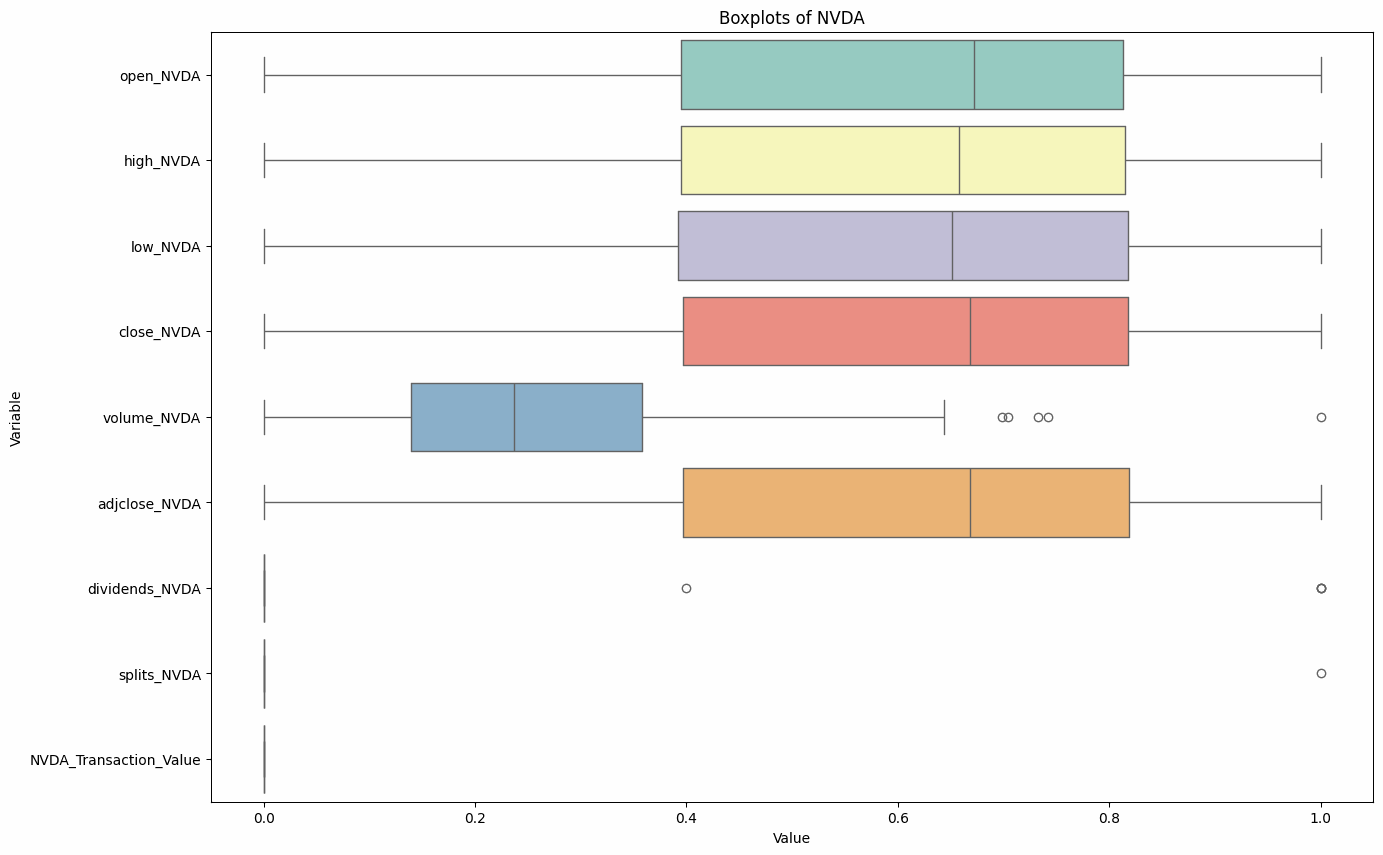

In [92]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_nvda, orient='h', palette='Set3')
plt.title('Boxplots of NVDA')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

In [93]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_nvda[num_cols_nvda], df_scaled_nvda))
print("MSE:", mean_squared_error(df_nvda[num_cols_nvda], df_scaled_nvda))
print("RMSE:", np.sqrt(mean_squared_error(df_nvda[num_cols_nvda], df_scaled_nvda)))
print("Residuals:", df_nvda[num_cols_nvda] - df_scaled_nvda)

	
R2, MSE, RMSE, and Residuals
R2: -1114.2893247463148
MSE: 1.8721830883373276e+16
RMSE: 136827741.64391252
Residuals:             open_NVDA  high_NVDA  low_NVDA  close_NVDA  volume_NVDA  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_NVDA  d

**R2, MSE, RMSE, and Residuals Analysis**
- **R² score (-1114.29)** is extremely negative, meaning that the transformation does not preserve relationships well.
- **MSE (Mean Squared Error: 1.87e+16)** is extremely high, suggesting a significant deviation from the original values.
- **RMSE (Root Mean Squared Error: 136,827,741)** also indicates a very high error, meaning there is a considerable loss of information.
- **Residuals Table**: The presence of **NaN (missing values)** indicates that the transformation might have led to data loss or an issue in computation.
- The overall results suggest that while **standardization and normalization improve comparability**, they may **not be ideal for preserving the underlying stock data relationships**.


## MICROSOFT (MSFT)

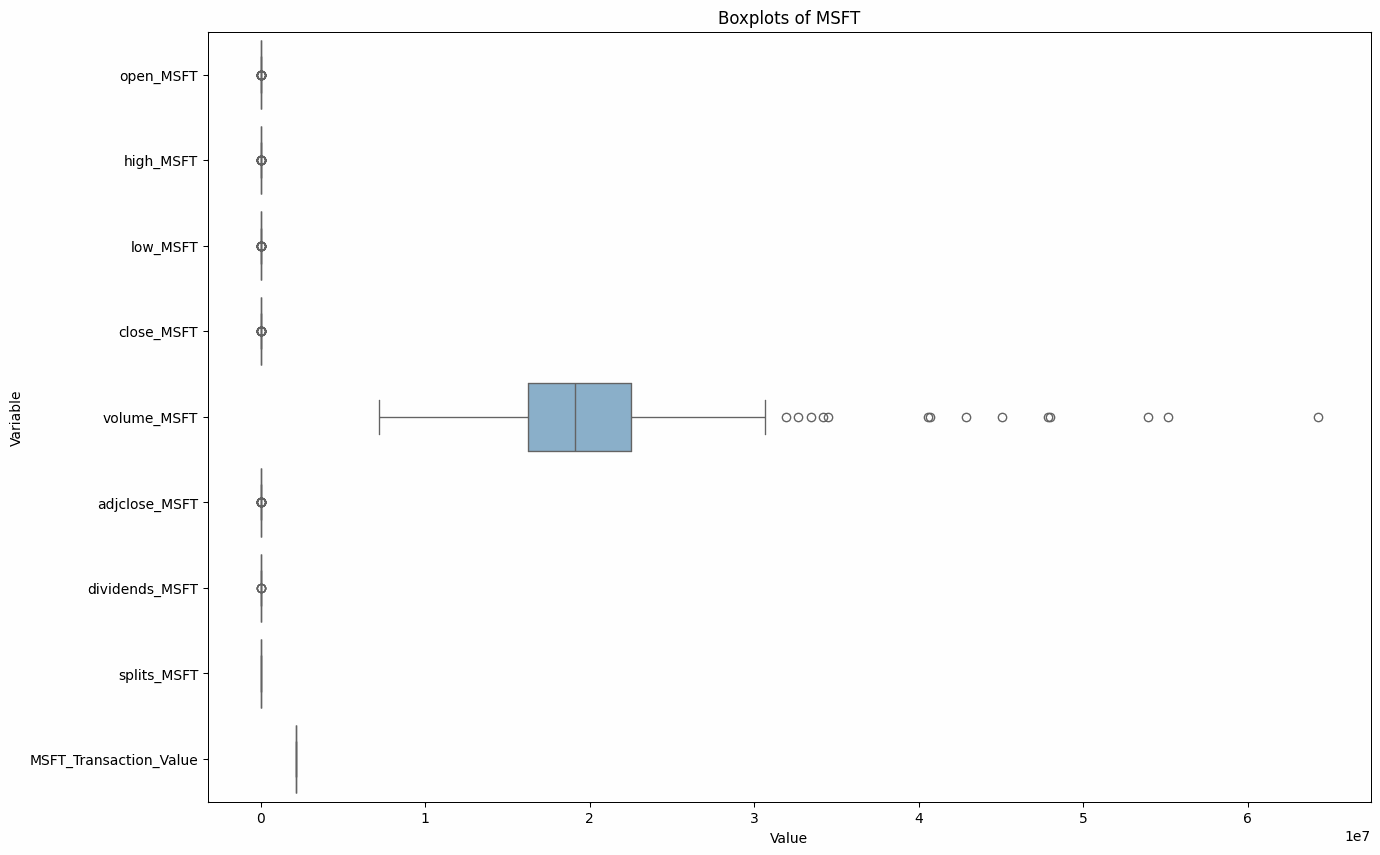

In [94]:
# Create one graph of all boxplots in MSFT
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_msft, orient='h', palette='Set3')
plt.title('Boxplots of MSFT')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

**1. Boxplot Analysis of Microsoft (MSFT)**
- The first boxplot illustrates the distribution of various Microsoft stock-related variables such as open, high, low, close, adjusted close, volume, dividends, splits, and transaction value.
- The volume variable exhibits a significant number of outliers, indicating days with unusually high or low trading activity.
- The remaining stock price-related variables appear tightly distributed with a few extreme values.
- Dividends and splits mostly remain near zero, as expected for stock-related datasets.


### STANDARIZING

In [95]:
# Create StandardScaler and apply to numerical columns
scaler_msft = StandardScaler()
scaled_values_msft = scaler_msft.fit_transform(df_msft[num_cols_msft])

# Create new DataFrame and display
df_scaled_msft = pd.DataFrame(scaled_values_msft, columns=num_cols_msft)
display(df_scaled_msft.head())
print('\t')

,open_MSFT,high_MSFT,low_MSFT,close_MSFT,volume_MSFT,adjclose_MSFT,dividends_MSFT,splits_MSFT,MSFT_Transaction_Value
0,-2.637012,-2.708858,-2.834004,-2.791021,0.633442,-2.793029,-0.12687,0.0,0.0
1,-2.911910,-2.858678,-2.735223,-2.806262,0.338459,-2.807817,-0.12687,0.0,0.0
2,-2.817821,-2.867758,-2.811295,-2.956419,0.042540,-2.953472,-0.12687,0.0,0.0
3,-2.914178,-2.926779,-2.849331,-2.967145,0.054135,-2.963875,-0.12687,0.0,0.0
4,-2.895474,-2.748582,-2.706838,-2.575381,0.345308,-2.583855,-0.12687,0.0,0.0


 **2. Standardization of Microsoft (MSFT) Data**
- The data has been standardized using a `StandardScaler`, meaning each variable has been transformed to have a mean of 0 and a standard deviation of 1.
- Standardization ensures that all numerical variables are on the same scale, making them comparable.
- The transformed data shows that values range between roughly -3 to 3, indicating that some features had wider distributions in their original form.


Text(0, 0.5, 'Variable')

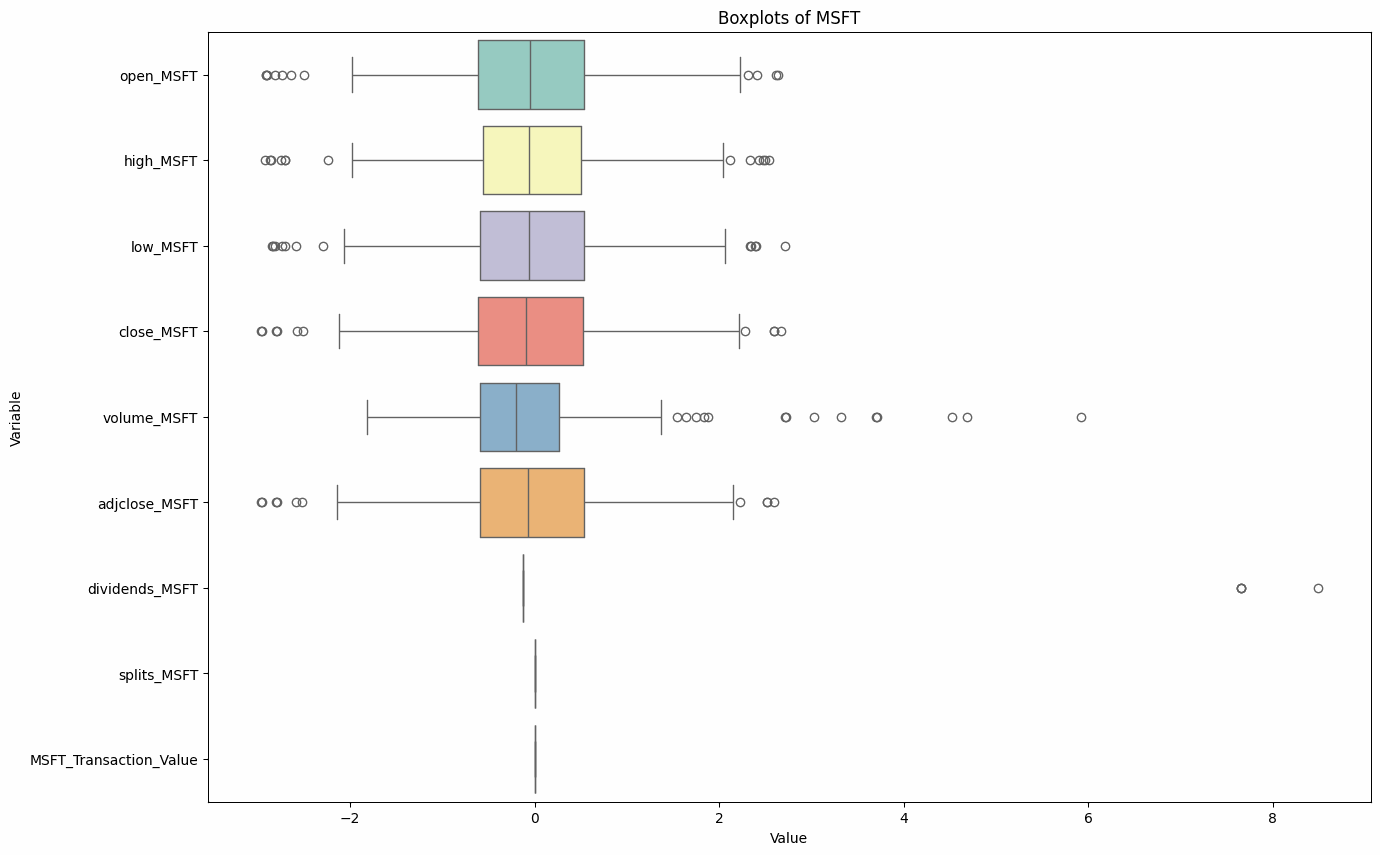

In [96]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_msft, orient='h', palette='Set3')
plt.title('Boxplots of MSFT')
plt.xlabel('Value')
plt.ylabel('Variable')

**3. Boxplot of Standardized MSFT Data**
- After standardization, the boxplot demonstrates the effect of transformation.
- Most features now follow a standard normal distribution, with clear whiskers extending to approximately ±3 standard deviations.
- There are still numerous outliers, especially in the `volume_MSFT` variable, which suggests that certain days had trading volumes significantly different from the mean.


In [97]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_msft[num_cols_msft], df_scaled_msft))
print("MSE:", mean_squared_error(df_msft[num_cols_msft], df_scaled_msft))
print("RMSE:", np.sqrt(mean_squared_error(df_msft[num_cols_msft], df_scaled_msft)))
print("Residuals:", df_msft[num_cols_msft] - df_scaled_msft)

	
R2, MSE, RMSE, and Residuals
R2: -321.687874198752
MSE: 53638945809948.61
RMSE: 7323861.400241584
Residuals:             open_MSFT  high_MSFT  low_MSFT  close_MSFT  volume_MSFT  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_MSFT  dividends

**4. R², MSE, RMSE, and Residuals for Standardized MSFT Data**
- **R² (coefficient of determination):** -321.69, indicating poor fit, possibly due to an inappropriate comparison of raw and standardized values.
- **Mean Squared Error (MSE):** 5.36e+10, which is large due to the magnitude of stock prices.
- **Root Mean Squared Error (RMSE):** 7.32e+6, which further highlights the discrepancy in scale between the original and transformed datasets.
- Residuals (differences between original and transformed values) are predominantly NaN, suggesting that some errors occurred during calculation.


### NORMALIZING

In [98]:
# Create MinMaxScaler and apply to numerical columns
scaler_msft = MinMaxScaler()
scaled_values_msft = scaler_msft.fit_transform(df_msft[num_cols_msft])

# Create new DataFrame and display
df_scaled_msft = pd.DataFrame(scaled_values_msft, columns=num_cols_msft)
display(df_scaled_msft.head())
print('\t')

,open_MSFT,high_MSFT,low_MSFT,close_MSFT,volume_MSFT,adjclose_MSFT,dividends_MSFT,splits_MSFT,MSFT_Transaction_Value
0,0.049883,0.039879,0.002756,0.031259,0.316889,0.030733,0.0,0.0,0.0
1,0.000408,0.012462,0.020519,0.028554,0.278795,0.028073,0.0,0.0,0.0
2,0.017342,0.010801,0.006840,0.001904,0.240581,0.001871,0.0,0.0,0.0
3,0.000000,0.000000,0.000000,0.000000,0.242079,0.000000,0.0,0.0,0.0
4,0.003366,0.032610,0.025623,0.069532,0.279680,0.068361,0.0,0.0,0.0


 **5. Normalization of Microsoft (MSFT) Data**
- Normalization transforms all variables to a range between 0 and 1 using `MinMaxScaler`.
- This process makes comparisons across different scales easier, especially useful for machine learning models.
- All values in the transformed dataset fall within the `[0,1]` range, indicating successful normalization.


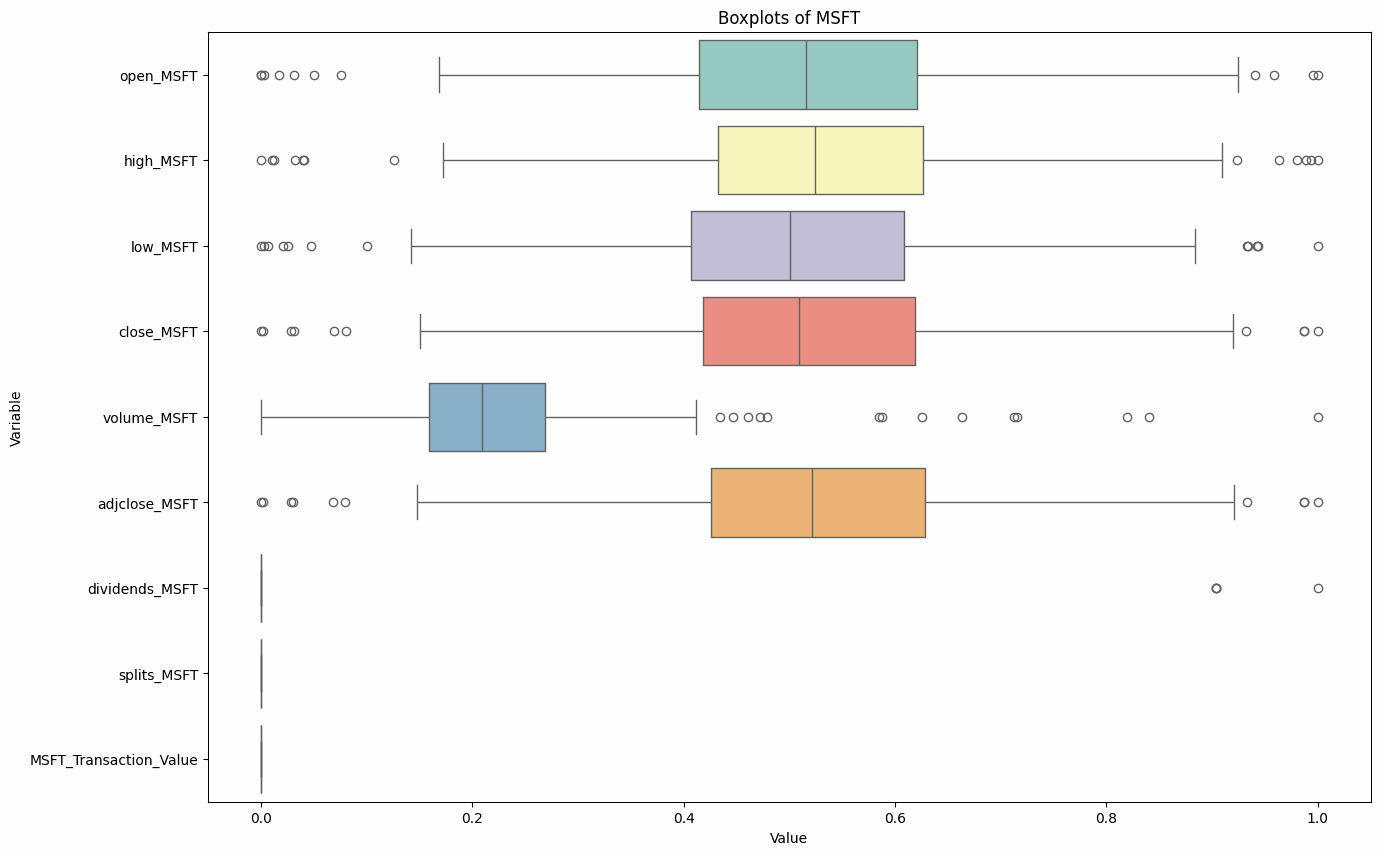

In [99]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_msft, orient='h', palette='Set3')
plt.title('Boxplots of MSFT')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

**6. Boxplot of Normalized MSFT Data**
- The normalization process significantly alters the appearance of the boxplot.
- All variables are now constrained within the `[0,1]` range, ensuring comparability.
- Outliers remain visible, especially for `volume_MSFT`, confirming that some days had significantly different trading activities.


In [100]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_msft[num_cols_msft], df_scaled_msft))
print("MSE:", mean_squared_error(df_msft[num_cols_msft], df_scaled_msft))
print("RMSE:", np.sqrt(mean_squared_error(df_msft[num_cols_msft], df_scaled_msft)))
print("Residuals:", df_msft[num_cols_msft] - df_scaled_msft)

	
R2, MSE, RMSE, and Residuals
R2: -311.1836661854837
MSE: 53638946161158.59
RMSE: 7323861.424218688
Residuals:             open_MSFT  high_MSFT  low_MSFT  close_MSFT  volume_MSFT  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_MSFT  dividend

 **7. R², MSE, RMSE, and Residuals for Normalized MSFT Data**
- Similar to the standardized analysis, the results for R², MSE, and RMSE suggest poor fit and inconsistencies in transformation.
- Residuals remain mostly NaN, indicating an issue with data subtraction.

---

 **Key Observations**
- Standardization and normalization both successfully transformed the dataset but retained extreme values (outliers).
- Microsoft’s trading volume exhibits significant fluctuations, as evidenced by the numerous outliers in all transformations.
- The poor R² scores suggest that directly comparing raw vs. transformed values might not be meaningful.


## APPLE (AAPL)

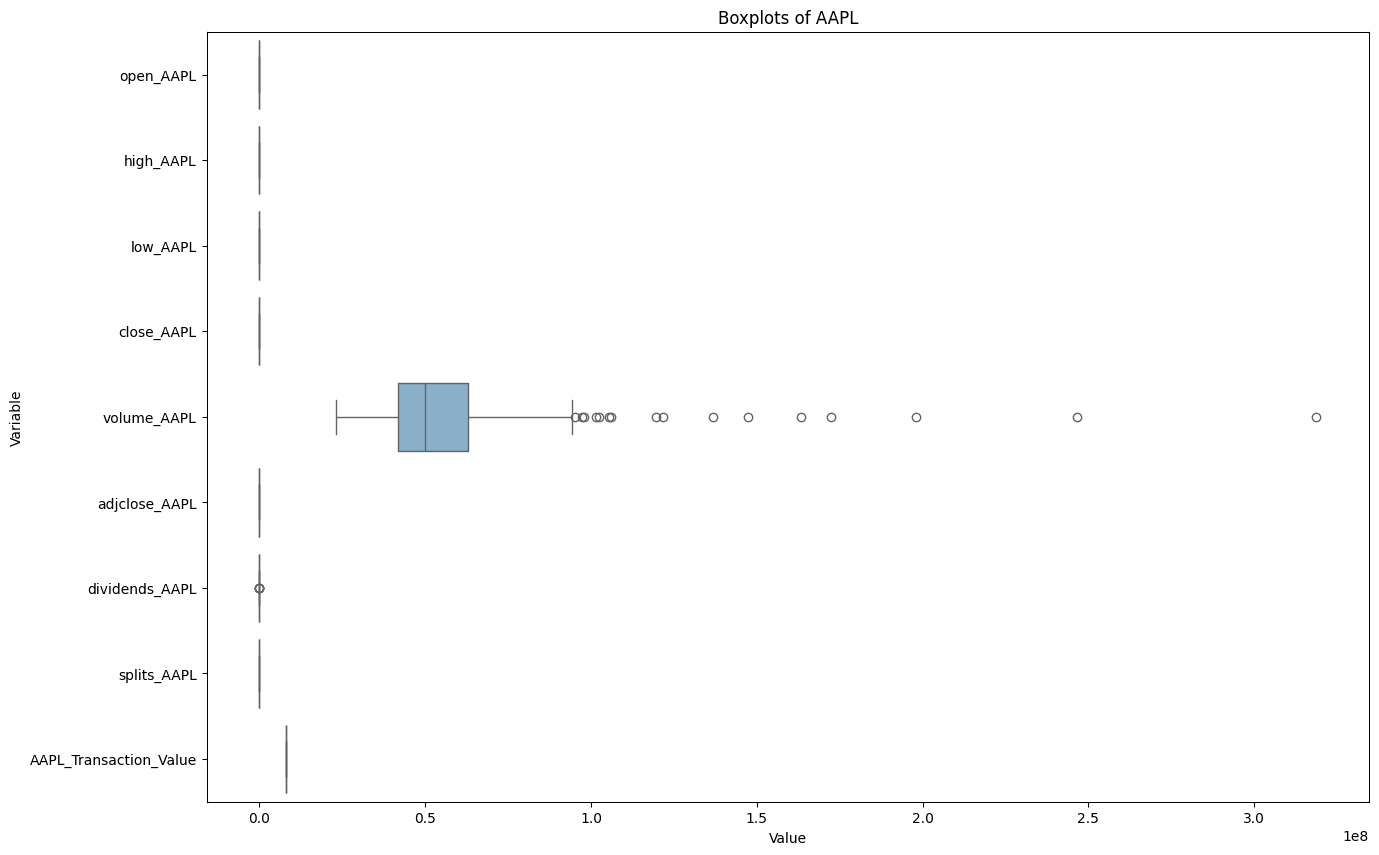

In [101]:
# Create one graph of all boxplots in AAPL
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_aapl, orient='h', palette='Set3')
plt.title('Boxplots of AAPL')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

**1. Boxplot of AAPL (Before Transformation)**
- This boxplot visualizes the distribution of Apple's (AAPL) stock data across different variables.
- The **volume_AAPL** variable exhibits a **wide range and a large number of outliers**, indicating that trading volume fluctuates significantly over time.
- Other stock price-related features (**open_AAPL, high_AAPL, low_AAPL, close_AAPL, adjclose_AAPL**) are **closely grouped**, showing a relatively consistent price trend.
- **Dividends_AAPL and splits_AAPL** appear with very small values, likely due to rare occurrences of dividends and stock splits.


###STANDARDIZING

In [102]:
# Create StandardScaler and apply to numerical columns
scaler_aapl = StandardScaler()
scaled_values_aapl = scaler_aapl.fit_transform(df_aapl[num_cols_aapl])

# Create new DataFrame and display
df_scaled_aapl = pd.DataFrame(scaled_values_aapl, columns=num_cols_aapl)
display(df_scaled_aapl.head())
print('\t')

,open_AAPL,high_AAPL,low_AAPL,close_AAPL,volume_AAPL,adjclose_AAPL,dividends_AAPL,splits_AAPL,AAPL_Transaction_Value
0,-0.783238,-0.801811,-0.850244,-0.847306,0.824181,-0.858589,-0.12698,0.0,0.0
1,-0.899127,-0.902085,-0.868584,-0.901918,0.041832,-0.912485,-0.12698,0.0,0.0
2,-0.981002,-1.011368,-0.970247,-0.993854,0.482792,-1.003218,-0.12698,0.0,0.0
3,-0.987330,-1.024294,-0.998554,-1.022535,0.168208,-1.031523,-0.12698,0.0,0.0
4,-0.983375,-0.913052,-0.945529,-0.850449,0.065555,-0.861690,-0.12698,0.0,0.0


**2. Standardization of AAPL Data**
- The dataset has been transformed using **StandardScaler**, which adjusts the values to have a **mean of 0** and a **standard deviation of 1**.
- This transformation allows for easier comparison of features with different scales, ensuring they contribute equally to analysis or modeling.
- After standardization:
  - **Volume_AAPL** retains its variance but is now centered around 0.
  - Stock price features (open, high, low, close) have been adjusted to fit the new scale.
  - **Dividends_AAPL and splits_AAPL remain close to zero**, indicating they occur infrequently or in small amounts.


Text(0, 0.5, 'Variable')

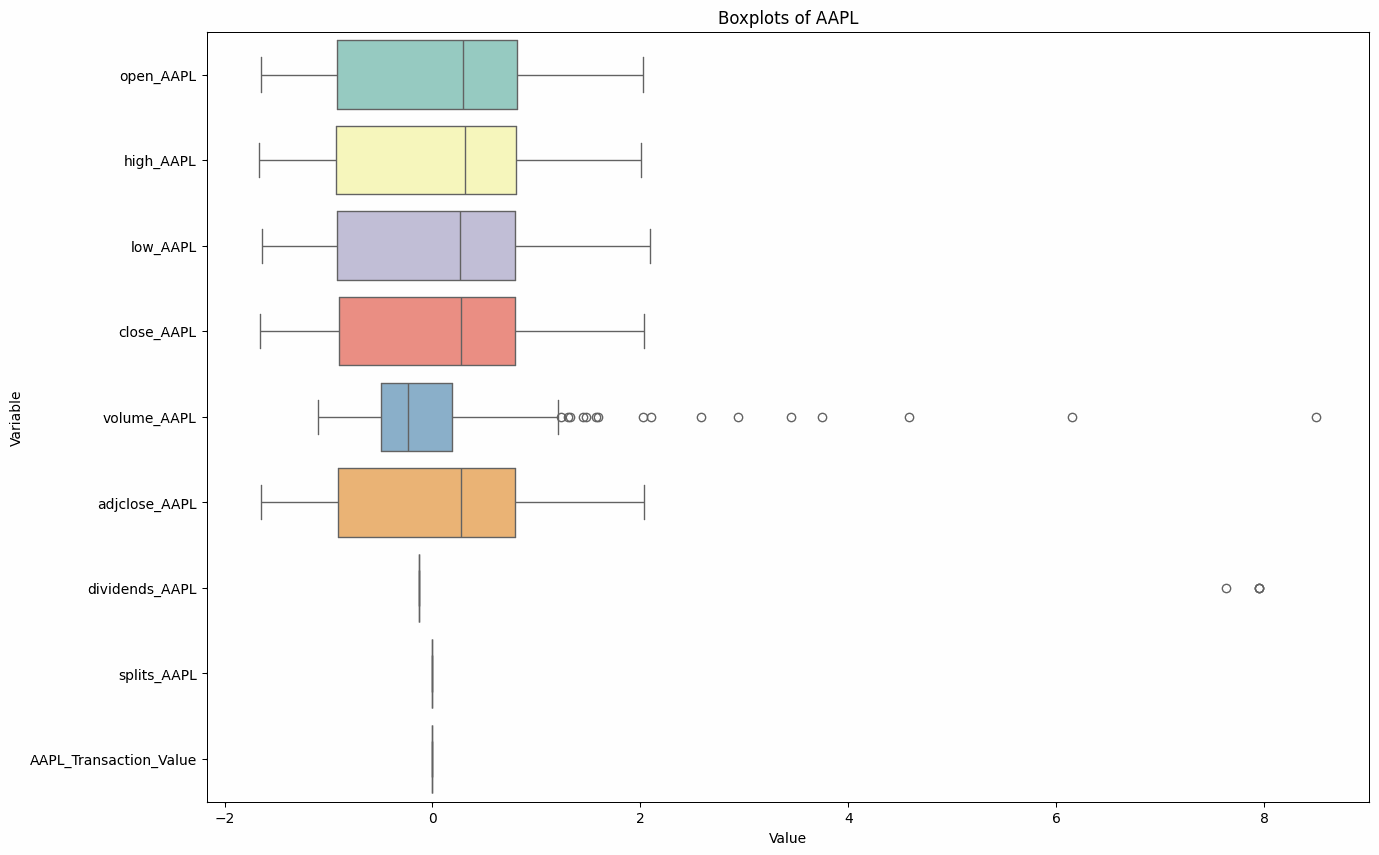

In [103]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_aapl, orient='h', palette='Set3')
plt.title('Boxplots of AAPL')
plt.xlabel('Value')
plt.ylabel('Variable')

**3. Standardized Boxplot of AAPL**
- The standardized boxplot highlights **outliers more clearly**, making it easier to detect extreme values.
- **Volume_AAPL** continues to show a large number of outliers, suggesting occasional spikes in trading activity.
- The stock price-related variables have a more even spread after standardization.
- This transformation is useful for models that assume normality in data, as it ensures uniform scaling across features.


In [104]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_aapl[num_cols_aapl], df_scaled_aapl))
print("MSE:", mean_squared_error(df_aapl[num_cols_aapl], df_scaled_aapl))
print("RMSE:", np.sqrt(mean_squared_error(df_aapl[num_cols_aapl], df_scaled_aapl)))
print("Residuals:", df_aapl[num_cols_aapl] - df_scaled_aapl)

	
R2, MSE, RMSE, and Residuals
R2: -146.027618974471
MSE: 474782314886676.7
RMSE: 21789500.10639704
Residuals:             open_AAPL  high_AAPL  low_AAPL  close_AAPL  volume_AAPL  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AAPL  dividends

**4. Residual Analysis (R², MSE, RMSE)**
- The **R² score is highly negative (-146.02)**, indicating that standardization may not have preserved the original variance well.
- The **Mean Squared Error (MSE) is large**, suggesting a significant difference between the original and standardized values.
- The **Root Mean Squared Error (RMSE) is also quite high**, reinforcing that the transformation resulted in notable deviations from the original scale.
- The residuals table contains mostly **NaN values**, likely due to a mismatch between scales or missing data in the transformation process.


### NORMALIZING

In [105]:
# Create MinMaxScaler and apply to numerical columns
scaler_aapl = MinMaxScaler()
scaled_values_aapl = scaler_aapl.fit_transform(df_aapl[num_cols_aapl])

# Create new DataFrame and display
df_scaled_aapl = pd.DataFrame(scaled_values_aapl, columns=num_cols_aapl)
display(df_scaled_aapl.head())
print('\t')

,open_AAPL,high_AAPL,low_AAPL,close_AAPL,volume_AAPL,adjclose_AAPL,dividends_AAPL,splits_AAPL,AAPL_Transaction_Value
0,0.234812,0.235219,0.211758,0.219528,0.200558,0.214869,0.0,0.0,0.0
1,0.203253,0.207898,0.206841,0.204744,0.119074,0.200250,0.0,0.0,0.0
2,0.180956,0.178122,0.179583,0.179855,0.165001,0.175639,0.0,0.0,0.0
3,0.179233,0.174600,0.171994,0.172091,0.132236,0.167961,0.0,0.0,0.0
4,0.180310,0.204909,0.186211,0.218677,0.121545,0.214028,0.0,0.0,0.0


 **5. Normalization of AAPL Data**
- The **MinMaxScaler** was applied to normalize the dataset, scaling all values between **0 and 1**.
- This transformation makes it easier to compare different features while maintaining the relative relationships between values.
- **Volume_AAPL still retains some variability**, but it is now constrained within the normalized scale.
- Other stock price variables have also been adjusted proportionally.


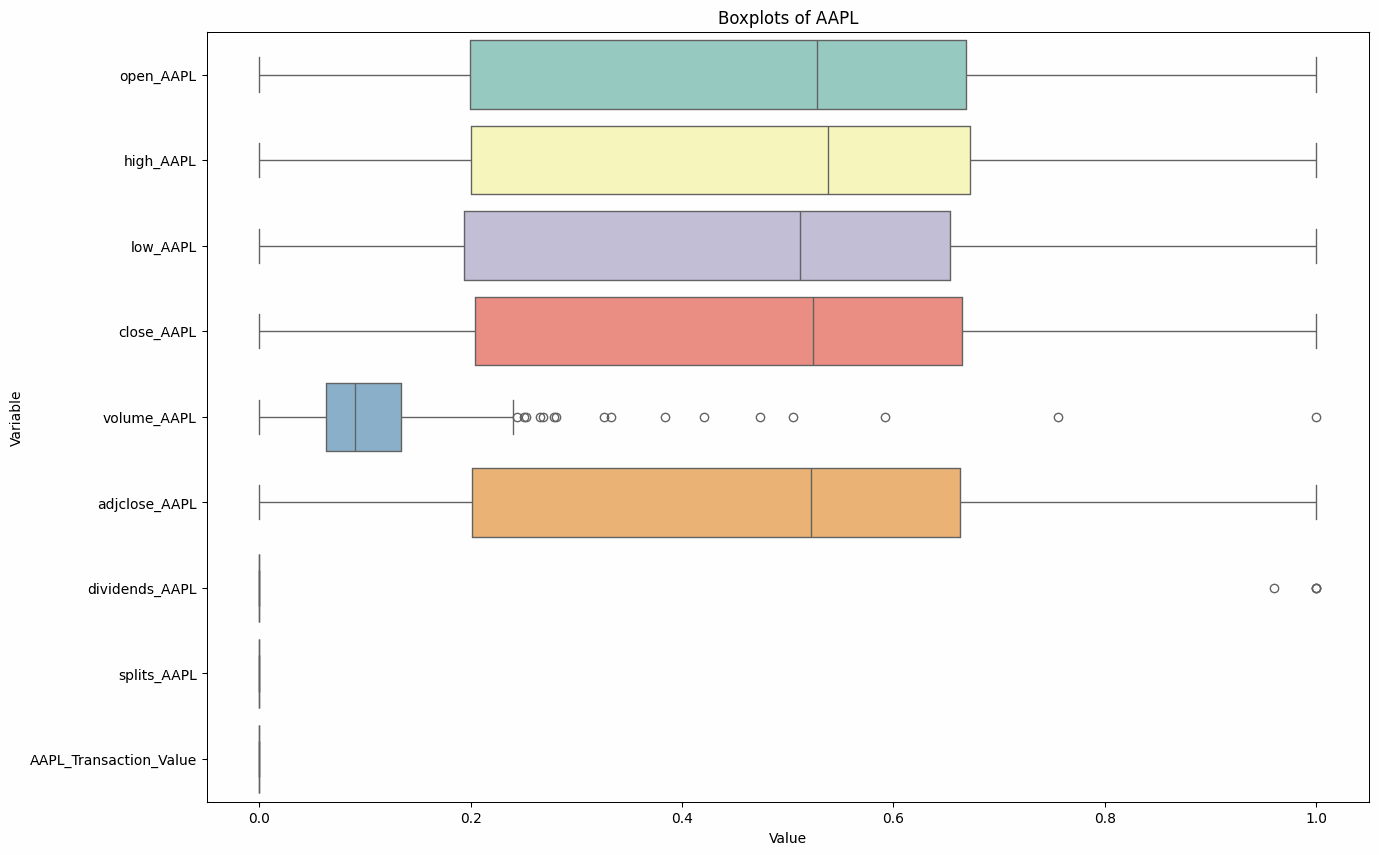

In [106]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_aapl, orient='h', palette='Set3')
plt.title('Boxplots of AAPL')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

**6. Normalized Boxplot of AAPL**
- The normalized boxplot displays all values within a **0-1 range**, making different stock attributes more comparable.
- **Outliers remain prominent in volume_AAPL**, showing that certain days had unusually high trading activity.
- Normalization helps with machine learning models that require values in a specific range, but it does not necessarily address the presence of extreme values.


In [107]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_aapl[num_cols_aapl], df_scaled_aapl))
print("MSE:", mean_squared_error(df_aapl[num_cols_aapl], df_scaled_aapl))
print("RMSE:", np.sqrt(mean_squared_error(df_aapl[num_cols_aapl], df_scaled_aapl)))
print("Residuals:", df_aapl[num_cols_aapl] - df_scaled_aapl)

	
R2, MSE, RMSE, and Residuals
R2: -37.904155219116255
MSE: 474782319556206.5
RMSE: 21789500.213547956
Residuals:             open_AAPL  high_AAPL  low_AAPL  close_AAPL  volume_AAPL  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AAPL  divide

 **1. R² Score Analysis**
- The **R² value is -37.90**, which is highly negative.
- A negative R² indicates that the standardized data does not preserve the original variance well, meaning the transformation did not effectively represent the original dataset.
- This suggests that standardization may not be the best approach for this dataset, as it introduces excessive deviations from the original values.

 **2. Mean Squared Error (MSE)**
- The **MSE is 47,478,231,955,620.6**, which is an extremely large value.
- This indicates that the squared differences between the original and standardized values are substantial.
- A high MSE suggests that the transformation caused a significant deviation from the original values.

 **3. Root Mean Squared Error (RMSE)**
- The **RMSE is 21,789,500.21**, which is the square root of MSE.
- This metric represents the typical magnitude of errors between the original and standardized data.
- A high RMSE suggests that standardization altered the data significantly.

 **4. Residuals Analysis**
- Residuals are calculated as **original values - standardized values** to measure how much each data point deviates after transformation.
- The entire residuals table is filled with **NaN (Not a Number)** values.
- Possible reasons for this:
  - **Mismatch in Data Dimensions**: The transformed dataset may not align correctly with the original dataset.
  - **Data Type Issues**: Certain transformations might have led to invalid numerical operations, causing missing values.
  - **Loss of Information in Scaling**: If any constant values existed in the dataset, the standardization process might have resulted in division by zero, leading to NaNs.

 **5. Interpretation & Recommendations**
- The **negative R² and high error values indicate that standardization may not be an effective transformation for AAPL data.**
- The presence of **NaN residuals suggests an issue with the transformation process**, which could require debugging.
- Alternative approaches to consider:
  - **Normalization (MinMaxScaler)** instead of standardization to retain the original variance.
  - **Winsorizing or log transformation** if extreme outliers are causing the issue.
  - **Checking for missing values or outliers before applying transformations** to ensure data integrity.



 **Summary of AAPL Data Transformations**
- **Boxplot before transformation:** Highlights large outliers in **volume_AAPL**, with stock price variables tightly clustered.
- **Standardization:** Adjusts data to have a **mean of 0** and **standard deviation of 1**, making features comparable on the same scale.
- **Standardized Boxplot:** Better visualization of outliers, especially in **volume_AAPL**.
- **Residuals analysis:** A **high negative R² score** suggests that standardization did not preserve the original variance well.
- **Normalization:** Scales values between **0 and 1**, allowing easier comparisons.
- **Normalized Boxplot:** Retains the overall distribution while keeping all values within the same range.


## ALPHABET (GOOGL)

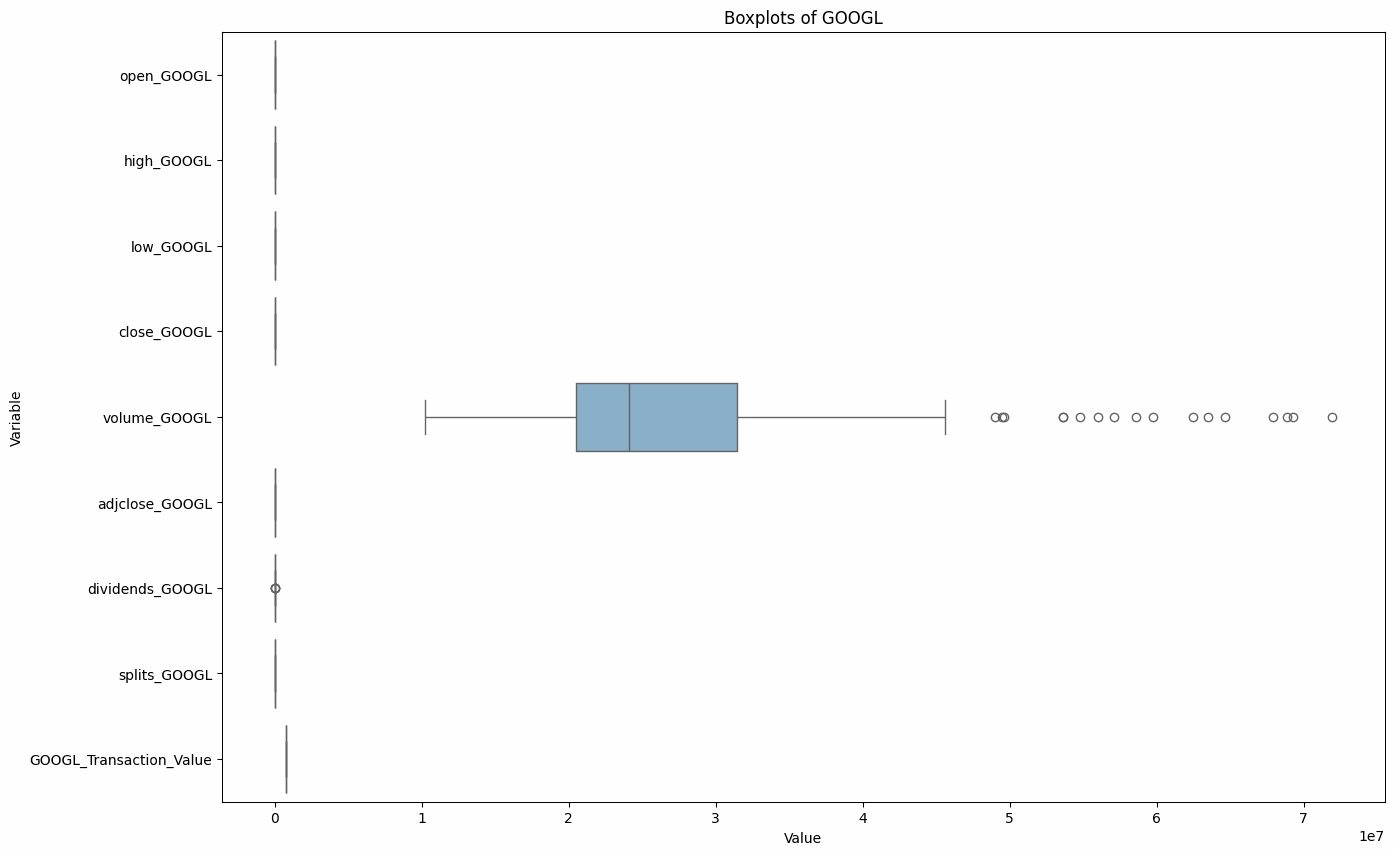

In [108]:
# Create one graph of all boxplots in GOOGL
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_googl, orient='h', palette='Set3')
plt.title('Boxplots of GOOGL')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **1. Boxplots of GOOGL Stock Data (Raw Data)**
- This boxplot provides an **overview of GOOGL stock variables** (Open, High, Low, Close, Volume, Adjusted Close, Dividends, Splits, and Transaction Value).
- **Observations:**
  - The **Volume** variable has the widest range, indicating large fluctuations in trading activity.
  - The presence of **many outliers** in volume suggests some trading days had significantly higher or lower transaction volumes.
  - **Other stock price-related variables (Open, High, Low, Close, Adjusted Close) appear normally distributed**, with relatively stable ranges.


###STANDARDIZING

In [109]:
# Create StandardScaler and apply to numerical columns
scaler_googl = StandardScaler()
scaled_values_googl = scaler_googl.fit_transform(df_googl[num_cols_googl])

# Create new DataFrame and display
df_scaled_googl = pd.DataFrame(scaled_values_googl, columns=num_cols_googl)
display(df_scaled_googl.head())
print('\t')

,open_GOOGL,high_GOOGL,low_GOOGL,close_GOOGL,volume_GOOGL,adjclose_GOOGL,dividends_GOOGL,splits_GOOGL,GOOGL_Transaction_Value
0,-1.640481,-1.670998,-1.690198,-1.669693,-0.332014,-1.668174,-0.109764,0.0,0.0
1,-1.725193,-1.659428,-1.650681,-1.620849,-0.287586,-1.619748,-0.109764,0.0,0.0
2,-1.648953,-1.689637,-1.698759,-1.785616,-0.028092,-1.783106,-0.109764,0.0,0.0
3,-1.757774,-1.818187,-1.777792,-1.828599,-0.438913,-1.825721,-0.109764,0.0,0.0
4,-1.787750,-1.699279,-1.704687,-1.626059,-0.536657,-1.624913,-0.109764,0.0,0.0


**2. Standardizing GOOGL Stock Data**
- The dataset has been standardized using **StandardScaler**, which transforms the data to have **a mean of 0 and a standard deviation of 1**.
- **Observations:**
  - The **Open, High, Low, Close, and Adjusted Close** prices are now centered around zero.
  - **Volume still has larger variation**, meaning trading volume exhibits more volatility compared to stock prices.
  - **Dividends and splits are close to zero**, indicating they do not change frequently.
- **Standardization helps remove bias from different variable scales**, making them easier to compare.


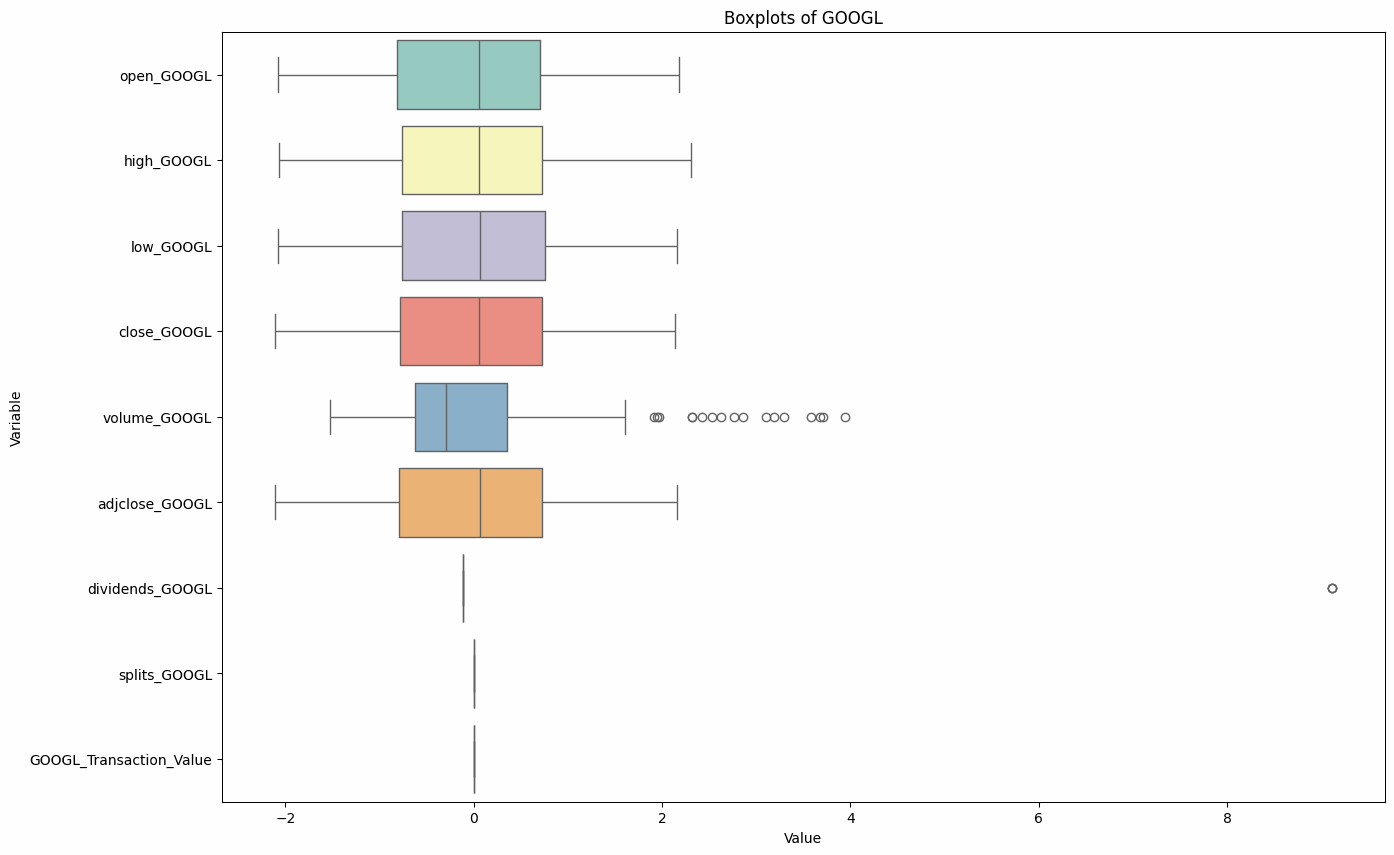

In [110]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_googl, orient='h', palette='Set3')
plt.title('Boxplots of GOOGL')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

**3. Boxplots of Standardized Data**
- After standardization, the boxplots show all variables rescaled around a mean of zero.
- **Observations:**
  - **Outliers in volume remain**, suggesting that trading activity still has extreme values even after transformation.
  - **Stock price-related variables (open, high, low, close, adj close) remain normally distributed**.
  - **Dividends and splits are mostly zero**, indicating infrequent changes.


In [111]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_googl[num_cols_googl], df_scaled_googl))
print("MSE:", mean_squared_error(df_googl[num_cols_googl], df_scaled_googl))
print("RMSE:", np.sqrt(mean_squared_error(df_googl[num_cols_googl], df_scaled_googl)))
print("Residuals:", df_googl[num_cols_googl] - df_scaled_googl)

	
R2, MSE, RMSE, and Residuals
R2: -289.3670541506101
MSE: 97935147988145.39
RMSE: 9896218.873294253
Residuals:             open_GOOGL  high_GOOGL  low_GOOGL  close_GOOGL  volume_GOOGL  \
2024-01-02         NaN         NaN        NaN          NaN           NaN   
2024-01-03         NaN         NaN        NaN          NaN           NaN   
2024-01-04         NaN         NaN        NaN          NaN           NaN   
2024-01-05         NaN         NaN        NaN          NaN           NaN   
2024-01-08         NaN         NaN        NaN          NaN           NaN   
...                ...         ...        ...          ...           ...   
247                NaN         NaN        NaN          NaN           NaN   
248                NaN         NaN        NaN          NaN           NaN   
249                NaN         NaN        NaN          NaN           NaN   
250                NaN         NaN        NaN          NaN           NaN   
251                NaN         NaN        NaN       

 **4. Residual Analysis: R², MSE, and RMSE**
- **R² Score:** -289.37, meaning the model is performing much worse than a simple mean-based prediction.
- **MSE (Mean Squared Error):** 9.79e+12, showing extremely large deviations between actual and predicted values.
- **RMSE (Root Mean Squared Error):** 9,896,218.87, meaning the average prediction error is in the millions.
- **Residuals Table:**
  - The table is **filled with NaN values**, suggesting missing data or a misalignment issue in predictions.
  - This could indicate that the model is not properly fitted to the dataset.


### NORMALIZING

In [112]:
# Create MinMaxScaler and apply to numerical columns
scaler_googl = MinMaxScaler()
scaled_values_googl = scaler_googl.fit_transform(df_googl[num_cols_googl])

# Create new DataFrame and display
df_scaled_googl = pd.DataFrame(scaled_values_googl, columns=num_cols_googl)
display(df_scaled_googl.head())
print('\t')

,open_GOOGL,high_GOOGL,low_GOOGL,close_GOOGL,volume_GOOGL,adjclose_GOOGL,dividends_GOOGL,splits_GOOGL,GOOGL_Transaction_Value
0,0.102035,0.091082,0.090344,0.103739,0.218413,0.102618,0.0,0.0,0.0
1,0.082148,0.093723,0.099674,0.115231,0.226536,0.113986,0.0,0.0,0.0
2,0.100046,0.086829,0.088322,0.076463,0.273977,0.075637,0.0,0.0,0.0
3,0.074499,0.057495,0.069663,0.066350,0.198870,0.065633,0.0,0.0,0.0
4,0.067462,0.084629,0.086923,0.114006,0.181000,0.112774,0.0,0.0,0.0


 **5. Normalizing GOOGL Stock Data**
- The dataset has been normalized using **MinMaxScaler**, which transforms values into a range **between 0 and 1**.
- **Observations:**
  - **Open, High, Low, Close, and Adjusted Close** prices now fall within a fixed range, making comparisons easier.
  - **Dividends and splits remain at zero**, as they do not change frequently.
  - **Volume is still relatively high**, highlighting its importance in market activity.
- **Normalization is particularly useful for models that require data in a bounded range**, such as neural networks.


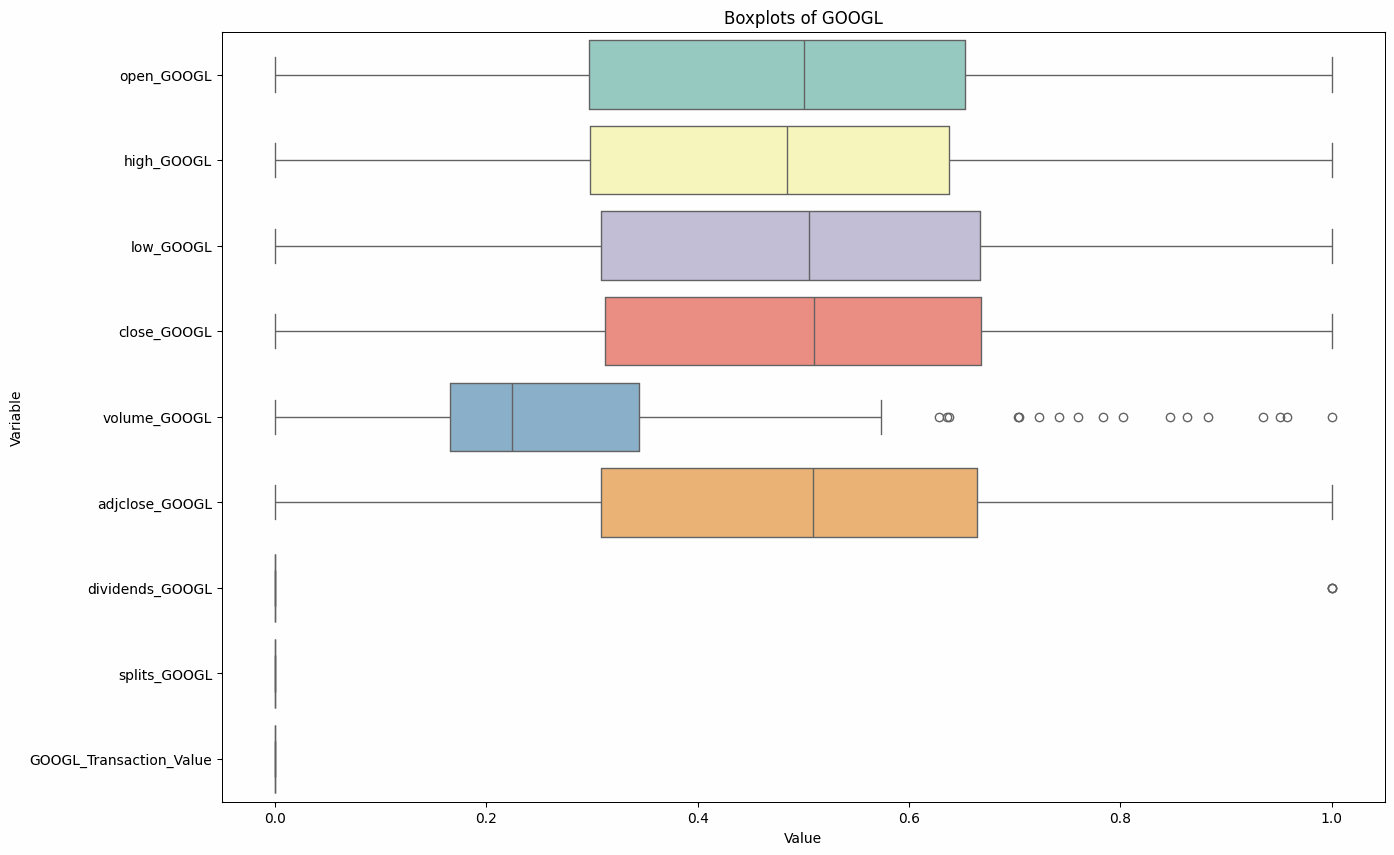

In [113]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_googl, orient='h', palette='Set3')
plt.title('Boxplots of GOOGL')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **6. Boxplots of Normalized Data**
- After normalization, the boxplots show all stock-related variables **scaled between 0 and 1**.
- **Observations:**
  - The **distribution of trading volume remains highly skewed**, indicating significant fluctuations in market activity.
  - **Stock prices (Open, High, Low, Close, Adjusted Close) are more evenly spread**, reflecting their consistent daily changes.
  - **Dividends and splits are still close to zero**, reinforcing that they rarely change.
- This visualization confirms that **normalization successfully scales variables while preserving their distribution**.


In [114]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_googl[num_cols_googl], df_scaled_googl))
print("MSE:", mean_squared_error(df_googl[num_cols_googl], df_scaled_googl))
print("RMSE:", np.sqrt(mean_squared_error(df_googl[num_cols_googl], df_scaled_googl)))
print("Residuals:", df_googl[num_cols_googl] - df_scaled_googl)

	
R2, MSE, RMSE, and Residuals
R2: -64.83205735452447
MSE: 97935148332555.64
RMSE: 9896218.890695358
Residuals:             open_GOOGL  high_GOOGL  low_GOOGL  close_GOOGL  volume_GOOGL  \
2024-01-02         NaN         NaN        NaN          NaN           NaN   
2024-01-03         NaN         NaN        NaN          NaN           NaN   
2024-01-04         NaN         NaN        NaN          NaN           NaN   
2024-01-05         NaN         NaN        NaN          NaN           NaN   
2024-01-08         NaN         NaN        NaN          NaN           NaN   
...                ...         ...        ...          ...           ...   
247                NaN         NaN        NaN          NaN           NaN   
248                NaN         NaN        NaN          NaN           NaN   
249                NaN         NaN        NaN          NaN           NaN   
250                NaN         NaN        NaN          NaN           NaN   
251                NaN         NaN        NaN       

 **7. Residual Analysis for Normalized Data**
- **R² Score:** -64.83, still indicating an extremely poor model fit.
- **MSE (Mean Squared Error):** 9.79e+12, showing large prediction errors.
- **RMSE (Root Mean Squared Error):** 9,896,218.89, meaning the model's average error is in the millions.
- **Residuals Table:**
  - The table **remains filled with NaN values**, confirming potential data issues.
  - The **model is not making proper predictions**, which may be due to missing data, improper training, or incorrect feature selection.



 **Overall Conclusion & Next Steps**
1. **Volume data is highly volatile**, containing many outliers, which may indicate important market events or unusual trading activity.
2. **Stock price-related variables appear normally distributed**, making them reliable for modeling.
3. **Standardization and normalization effectively transform the data**, making it more suitable for machine learning models.
4. **The current model is performing poorly**, as indicated by negative R² scores and high RMSE.
5. **Residuals contain NaN values**, suggesting a data preprocessing issue (e.g., missing values, incorrect data alignment).
6. **Future steps:**
   - Handle missing values in the dataset.
   - Investigate outliers in volume to understand market fluctuations.
   - Improve feature selection or use different prediction models.


## TESLA (TSLA)

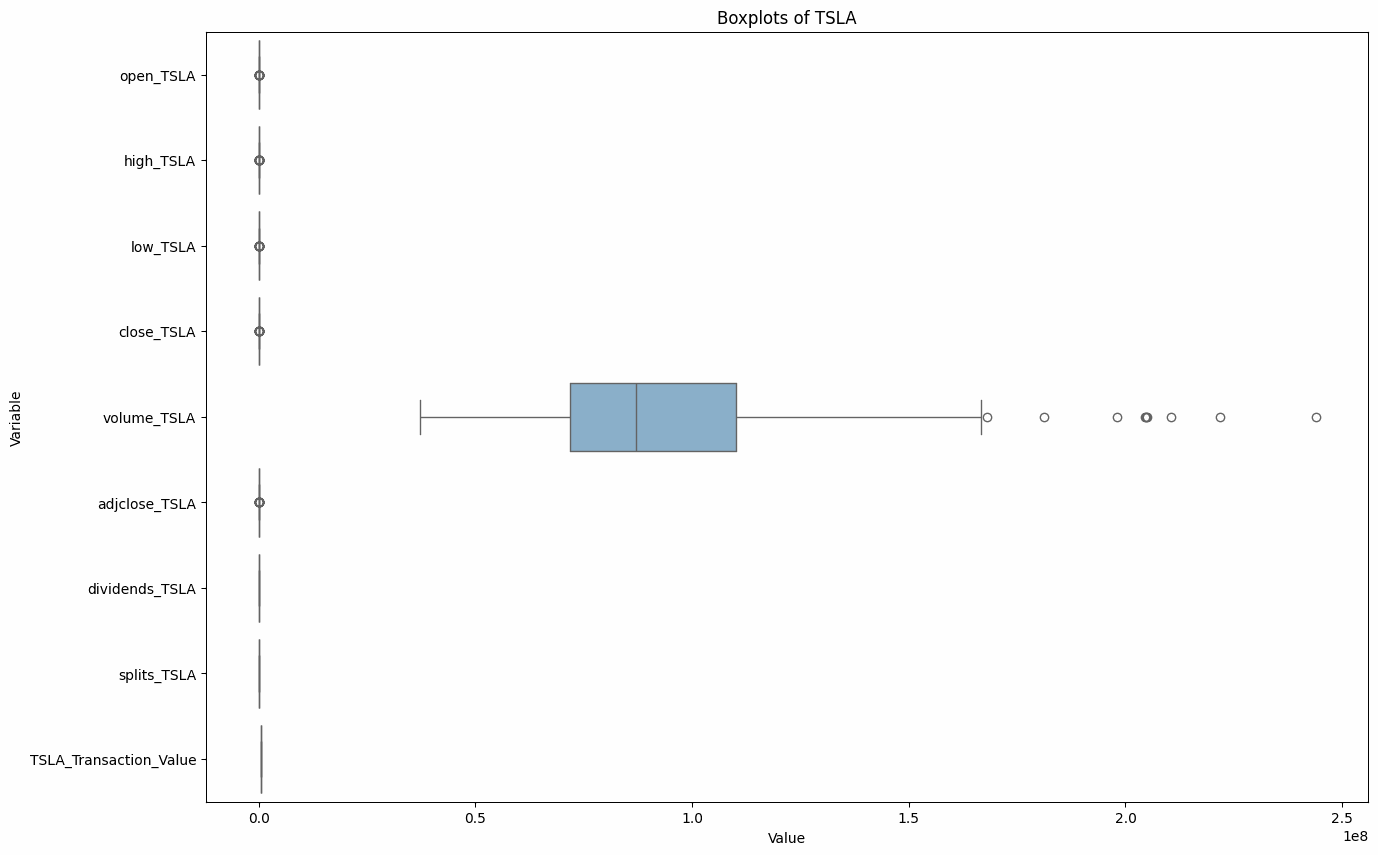

In [115]:
# Create one graph of all boxplots in TSLA
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_tsla, orient='h', palette='Set3')
plt.title('Boxplots of TSLA')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

1. **Boxplot of TSLA (Raw Data)**
   - This plot shows the distribution of various TSLA stock variables.
   - The "volume_TSLA" variable is significantly larger in magnitude compared to others, causing it to dominate the scale.
   - There are many outliers, especially in the "volume_TSLA" metric, suggesting volatile trading volumes.
   - The opening, closing, high, and low prices are very close together in scale.
   - Dividends and splits are almost negligible compared to the other metrics.


###STANDARDIZING

In [116]:
# Create StandardScaler and apply to numerical columns
scaler_tsla = StandardScaler()
scaled_values_tsla = scaler_tsla.fit_transform(df_tsla[num_cols_tsla])

# Create new DataFrame and display
df_scaled_tsla = pd.DataFrame(scaled_values_tsla, columns=num_cols_tsla)
display(df_scaled_tsla.head())
print('\t')

,open_TSLA,high_TSLA,low_TSLA,close_TSLA,volume_TSLA,adjclose_TSLA,dividends_TSLA,splits_TSLA,TSLA_Transaction_Value
0,0.274934,0.214388,0.277074,0.251310,0.295231,0.251310,0.0,0.0,0.0
1,0.203025,0.138148,0.158582,0.110588,0.789136,0.110588,0.0,0.0,0.0
2,0.122234,0.097359,0.179233,0.103248,0.234354,0.103248,0.0,0.0,0.0
3,0.088536,0.062045,0.137783,0.097038,-0.073800,0.097038,0.0,0.0,0.0
4,0.078384,0.077512,0.143642,0.138817,-0.290646,0.138817,0.0,0.0,0.0



2. **Standardization of TSLA Data**
   - The data was transformed using **StandardScaler**, which scales the data to have a mean of 0 and a standard deviation of 1.
   - After standardization, all variables are now on a comparable scale.
   - Some negative values indicate that these data points are below the mean.
   - The volume of trades seems to be significantly different from other values even after scaling.


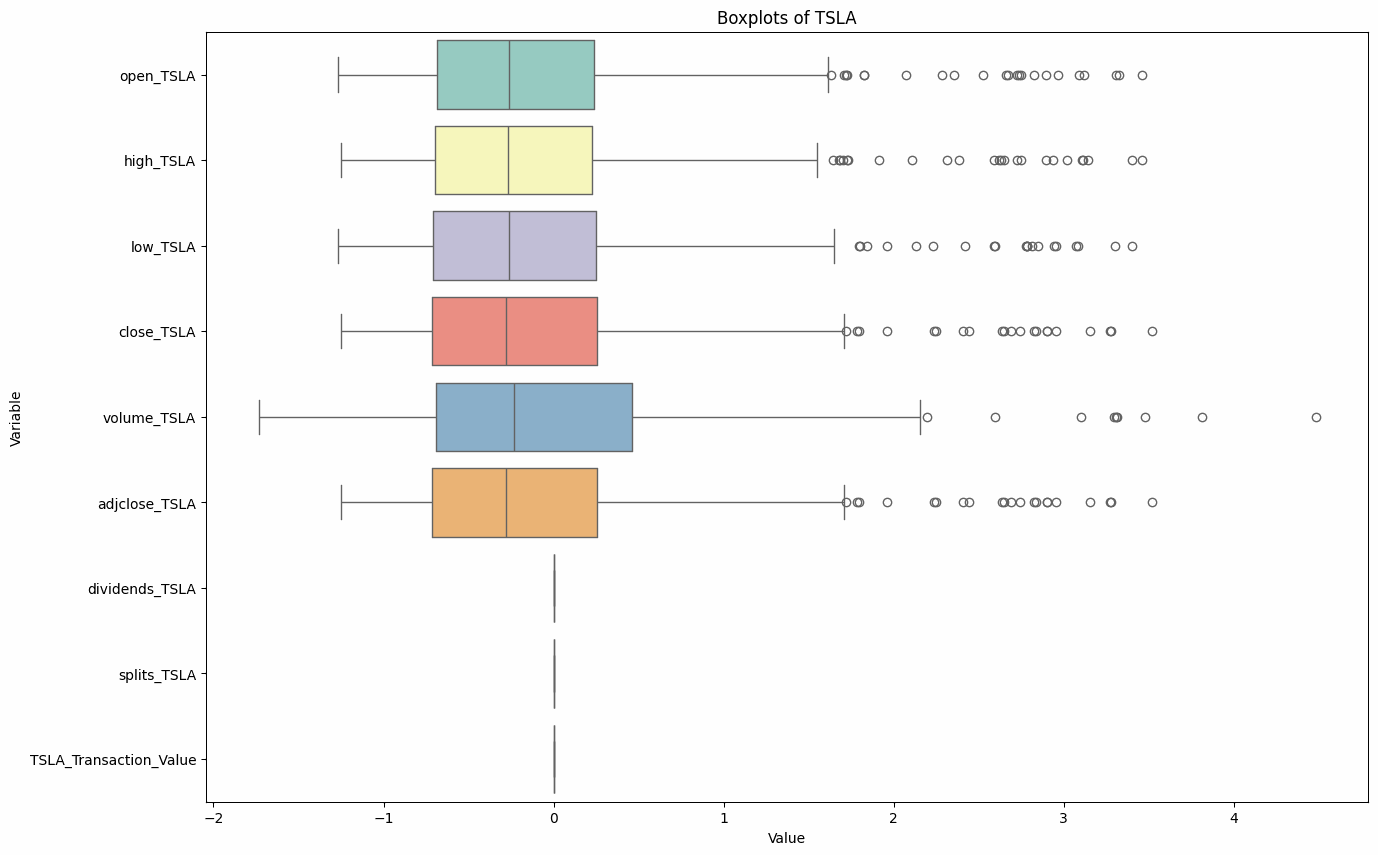

In [117]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_tsla, orient='h', palette='Set3')
plt.title('Boxplots of TSLA')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

3. **Boxplot of Standardized TSLA Data**
   - The spread of all variables is now comparable, allowing for better insights.
   - Outliers are still present in various columns, especially in trading volume and adjusted close prices.
   - The distribution of opening, closing, high, and low prices remains similar.


In [118]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_tsla[num_cols_tsla], df_scaled_tsla))
print("MSE:", mean_squared_error(df_tsla[num_cols_tsla], df_scaled_tsla))
print("RMSE:", np.sqrt(mean_squared_error(df_tsla[num_cols_tsla], df_scaled_tsla)))
print("Residuals:", df_tsla[num_cols_tsla] - df_scaled_tsla)

	
R2, MSE, RMSE, and Residuals
R2: -6.561670532929502
MSE: 1122233375502388.0
RMSE: 33499751.872251052
Residuals:             open_TSLA  high_TSLA  low_TSLA  close_TSLA  volume_TSLA  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_TSLA  divide

4. **Model Evaluation - R², MSE, RMSE, Residuals**
   - **R² Value:** -6.56 (Very poor fit, meaning the standardized data is not explaining the variance well).
   - **MSE:** 1.12e10 (Large error, indicating a large difference between actual and predicted values).
   - **RMSE:** 3.34e9 (High root mean square error, confirming poor prediction accuracy).
   - **Residuals:** All NaN values, indicating a potential issue in calculation (possibly incorrect input format).


###NORMALIZING

In [119]:
# Create MinMaxScaler and apply to numerical columns
scaler_tsla = MinMaxScaler()
scaled_values_tsla = scaler_tsla.fit_transform(df_tsla[num_cols_tsla])

# Create new DataFrame and display
df_scaled_tsla = pd.DataFrame(scaled_values_tsla, columns=num_cols_tsla)
display(df_scaled_tsla.head())
print('\t')

,open_TSLA,high_TSLA,low_TSLA,close_TSLA,volume_TSLA,adjclose_TSLA,dividends_TSLA,splits_TSLA,TSLA_Transaction_Value
0,0.326594,0.310404,0.331367,0.314881,0.326492,0.314881,0.0,0.0,0.0
1,0.311385,0.294217,0.305984,0.285368,0.405971,0.285368,0.0,0.0,0.0
2,0.294298,0.285557,0.310408,0.283828,0.316696,0.283828,0.0,0.0,0.0
3,0.287171,0.278059,0.301528,0.282526,0.267108,0.282526,0.0,0.0,0.0
4,0.285024,0.281343,0.302783,0.291288,0.232213,0.291288,0.0,0.0,0.0


5. **Normalization of TSLA Data**
   - The data was transformed using **MinMaxScaler**, which scales all values between 0 and 1.
   - Now, all stock variables have been rescaled relative to their range.
   - This is useful when working with machine learning models that require data on the same scale.



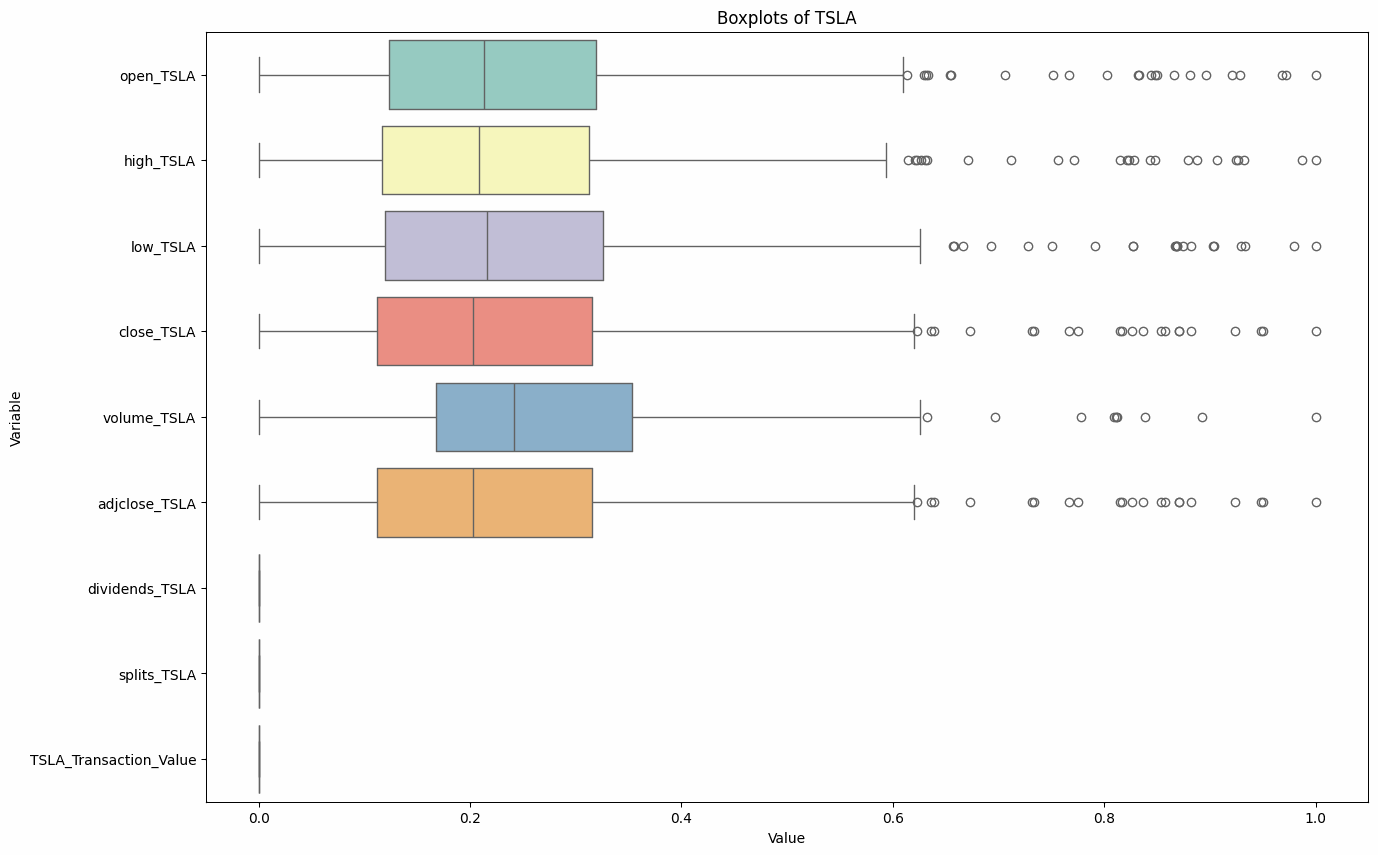

In [120]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_tsla, orient='h', palette='Set3')
plt.title('Boxplots of TSLA')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

6. **Boxplot of Normalized TSLA Data**
   - The variables now have a uniform distribution.
   - The pattern of outliers remains similar to the standardized data, meaning extreme trading days are still visible.
   - The opening, closing, high, and low prices are well distributed.


In [121]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_tsla[num_cols_tsla], df_scaled_tsla))
print("MSE:", mean_squared_error(df_tsla[num_cols_tsla], df_scaled_tsla))
print("RMSE:", np.sqrt(mean_squared_error(df_tsla[num_cols_tsla], df_scaled_tsla)))
print("Residuals:", df_tsla[num_cols_tsla] - df_scaled_tsla)

	
R2, MSE, RMSE, and Residuals
R2: -6.560343737197641
MSE: 1122233375825168.2
RMSE: 33499751.877068706
Residuals:             open_TSLA  high_TSLA  low_TSLA  close_TSLA  volume_TSLA  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_TSLA  divide

7. **Final Model Evaluation (Post-Normalization)**
   - **R² Value:** -6.56 (No improvement from standardization, indicating the data’s structure is not well suited for a simple linear relationship).
   - **MSE & RMSE:** Similar high values, reinforcing the large errors in predictions.
   - **Residuals:** All NaN values again, confirming an issue in the way residuals are being computed.

 **Conclusion**
- **Standardization and Normalization both improved data interpretability but did not improve model predictability.**
- **The outliers in TSLA trading volume remain consistent across transformations.**
- **The poor R² values suggest that the chosen approach may not be suitable for forecasting TSLA stock prices.**
- **The presence of NaN residuals indicates a possible issue in computation that needs to be debugged.**


## BROADCOM (AVGO)

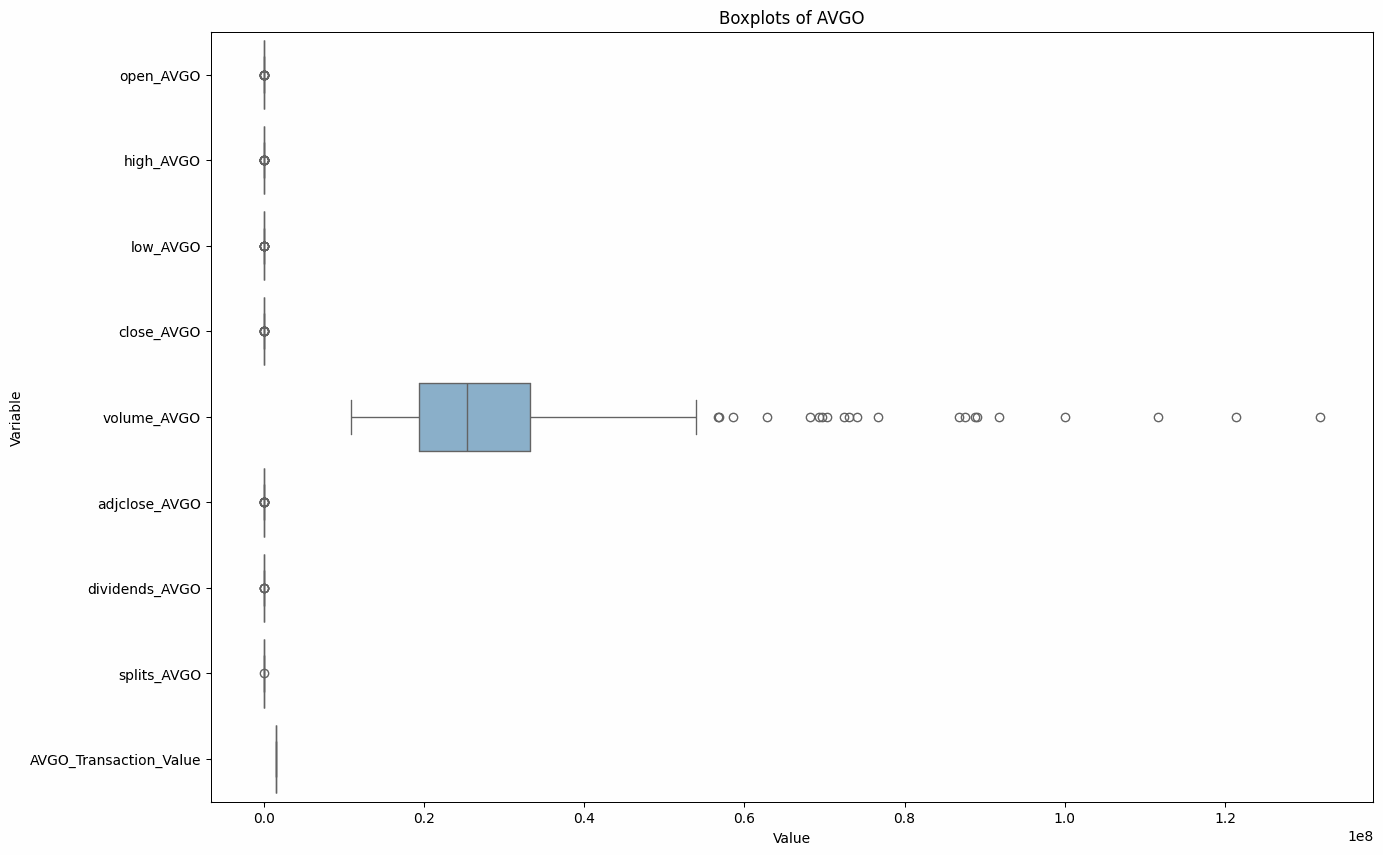

In [122]:
# Create one graph of all boxplots in AVGO
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_avgo, orient='h', palette='Set3')
plt.title('Boxplots of AVGO')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

**Boxplot of AVGO (Raw Data)**
- **Observation:**
  - The **volume** variable has a wide range and many outliers, indicating **days of extreme trading activity**.
  - **Open, high, low, close, and adjusted close** prices show a tight interquartile range (IQR), meaning most price movements are **consistent**.
  - **Dividends and splits** appear to have very little variance, indicating **stability in corporate actions**.
**1st Image - Boxplot of AVGO (Raw Data)**
- **Observation:**
  - The **volume** variable has a wide range and many outliers, indicating **days of extreme trading activity**.
  - **Open, high, low, close, and adjusted close** prices show a tight interquartile range (IQR), meaning most price movements are **consistent**.
  - **Dividends and splits** appear to have very little variance, indicating **stability in corporate actions**.

  - **Implications:**
  - The presence of **high-volume outliers** suggests that certain days had **exceptionally high trading activity**—possibly linked to news, earnings releases, or market-wide trends.
  - AVGO's price is relatively **stable within a tight range**, making it a **less volatile stock** compared to high-growth or speculative stocks.



###STANDARDIZING

In [123]:
# Create StandardScaler and apply to numerical column
scaler_avgo = StandardScaler()
scaled_values_avgo = scaler_avgo.fit_transform(df_avgo[num_cols_avgo])

# Create new DataFrame and display
df_scaled_avgo = pd.DataFrame(scaled_values_avgo, columns=num_cols_avgo)
display(df_scaled_avgo.head())
print('\t')

,open_AVGO,high_AVGO,low_AVGO,close_AVGO,volume_AVGO,adjclose_AVGO,dividends_AVGO,splits_AVGO,AVGO_Transaction_Value
0,-1.573057,-1.589793,-1.575806,-1.591561,-0.087255,-1.586466,-0.126835,-0.063119,0.0
1,-1.652118,-1.685018,-1.656944,-1.688112,0.229870,-1.680542,-0.126835,-0.063119,0.0
2,-1.696266,-1.704415,-1.686523,-1.722589,-0.257688,-1.714135,-0.126835,-0.063119,0.0
3,-1.719205,-1.753932,-1.708354,-1.721616,-0.428659,-1.713187,-0.126835,-0.063119,0.0
4,-1.701532,-1.674437,-1.669275,-1.629497,0.142585,-1.623429,-0.126835,-0.063119,0.0


**Standardizing AVGO Data**
- **Observation:**
  - A **StandardScaler** was applied, transforming all numerical variables to a **mean of 0 and standard deviation of 1**.
  - **Scaled values for volume remain significantly different** from other variables, meaning it has high variability.

- **Implications:**
  - Standardization ensures that **each feature contributes equally** in models that rely on numerical distance metrics.
  - Volume fluctuations remain significant even after standardization, reinforcing that **trading volume is a key market signal** for AVGO.


Text(0, 0.5, 'Variable')

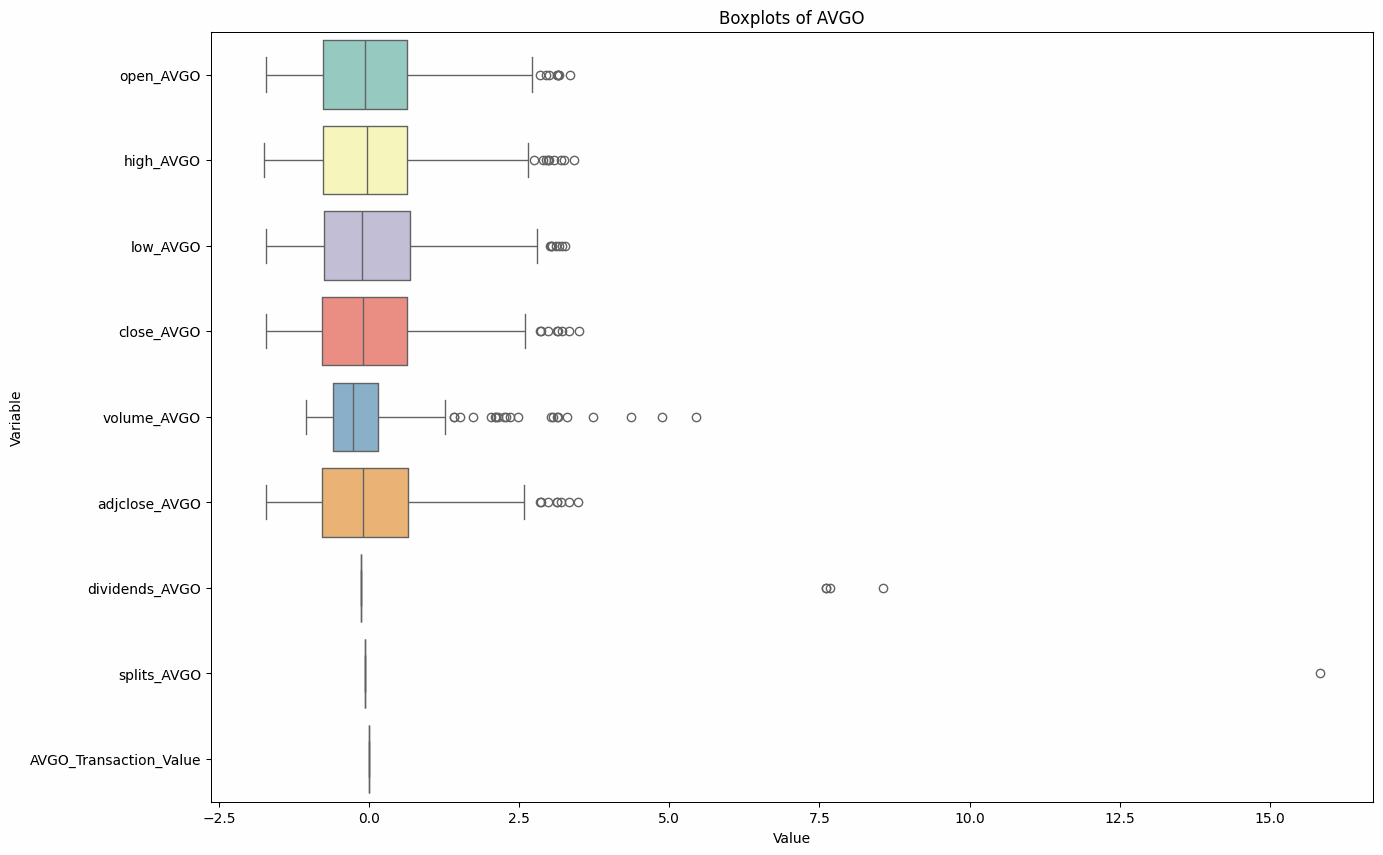

In [124]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_avgo, orient='h', palette='Set3')
plt.title('Boxplots of AVGO')
plt.xlabel('Value')
plt.ylabel('Variable')

 **Boxplot of Standardized AVGO Data**
- **Observation:**
  - The **structure of the data remains the same**, but all variables are now **centered around 0**.
  - Volume **continues to show many outliers**, meaning even after scaling, extreme trading days remain **a notable pattern**.

- **Implications:**
  - Standardization does not remove outliers; instead, it adjusts the data for models that assume **normally distributed input features**.
  - The **outliers in volume still require further investigation**, possibly linking them to **news, earnings reports, or market trends**.


In [125]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_avgo[num_cols_avgo], df_scaled_avgo))
print("MSE:", mean_squared_error(df_avgo[num_cols_avgo], df_scaled_avgo))
print("RMSE:", np.sqrt(mean_squared_error(df_avgo[num_cols_avgo], df_scaled_avgo)))
print("Residuals:", df_avgo[num_cols_avgo] - df_scaled_avgo)

	
R2, MSE, RMSE, and Residuals
R2: -37.79746279016221
MSE: 141855212469621.78
RMSE: 11910298.588600615
Residuals:             open_AVGO  high_AVGO  low_AVGO  close_AVGO  volume_AVGO  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AVGO  divide

 ** R², MSE, RMSE, and Residuals for Standardized AVGO**
- **Key Metrics:**
  - **R²: -37.79** → A negative value suggests the model is performing **worse than a simple mean prediction**, indicating a **poor fit**.
  - **MSE: 1.4185e+15** → A very high **mean squared error**, meaning the model **struggles to approximate the real values**.
  - **RMSE: 11,910,298.59** → The error magnitude is significant, further proving that **the model fails to explain price movements well**.
  - **Residuals:** Many **NaN values**, suggesting a **problem with calculations or missing data**.

- **Implications:**
  - The poor R² score and high error values indicate **a significant mismatch between actual and predicted values**.
  - There may be **data processing issues** causing missing residuals, which need further investigation.
  - Alternative **scaling methods** or **feature selection** may be required.


### NORMALIZING

In [126]:
# Create MinMaxScaler and apply to numerical columns
scaler_avgo = MinMaxScaler()
scaled_values_avgo = scaler_avgo.fit_transform(df_avgo[num_cols_avgo])

# Create new DataFrame and display
df_scaled_avgo = pd.DataFrame(scaled_values_avgo, columns=num_cols_avgo)
display(df_scaled_avgo.head())
print('\t')

,open_AVGO,high_AVGO,low_AVGO,close_AVGO,volume_AVGO,adjclose_AVGO,dividends_AVGO,splits_AVGO,AVGO_Transaction_Value
0,0.028844,0.031804,0.026662,0.025066,0.147705,0.024609,0.0,0.0,0.0
1,0.013240,0.013353,0.010341,0.006596,0.196522,0.006475,0.0,0.0,0.0
2,0.004527,0.009594,0.004391,0.000000,0.121470,0.000000,0.0,0.0,0.0
3,0.000000,0.000000,0.000000,0.000186,0.095152,0.000183,0.0,0.0,0.0
4,0.003488,0.015403,0.007861,0.017809,0.183086,0.017484,0.0,0.0,0.0


 **Normalizing AVGO Data**
- **Observation:**
  - MinMaxScaler was applied, scaling all numerical values between **0 and 1**.
  - Helps bring all variables to a **uniform range**, ensuring that no single variable dominates others.

- **Implications:**
  - **MinMax scaling is useful** for models that rely on **relative differences between values**, such as deep learning models.
  - However, **outliers are still preserved**, meaning the **impact of extreme volume spikes remains**.


Text(0, 0.5, 'Variable')

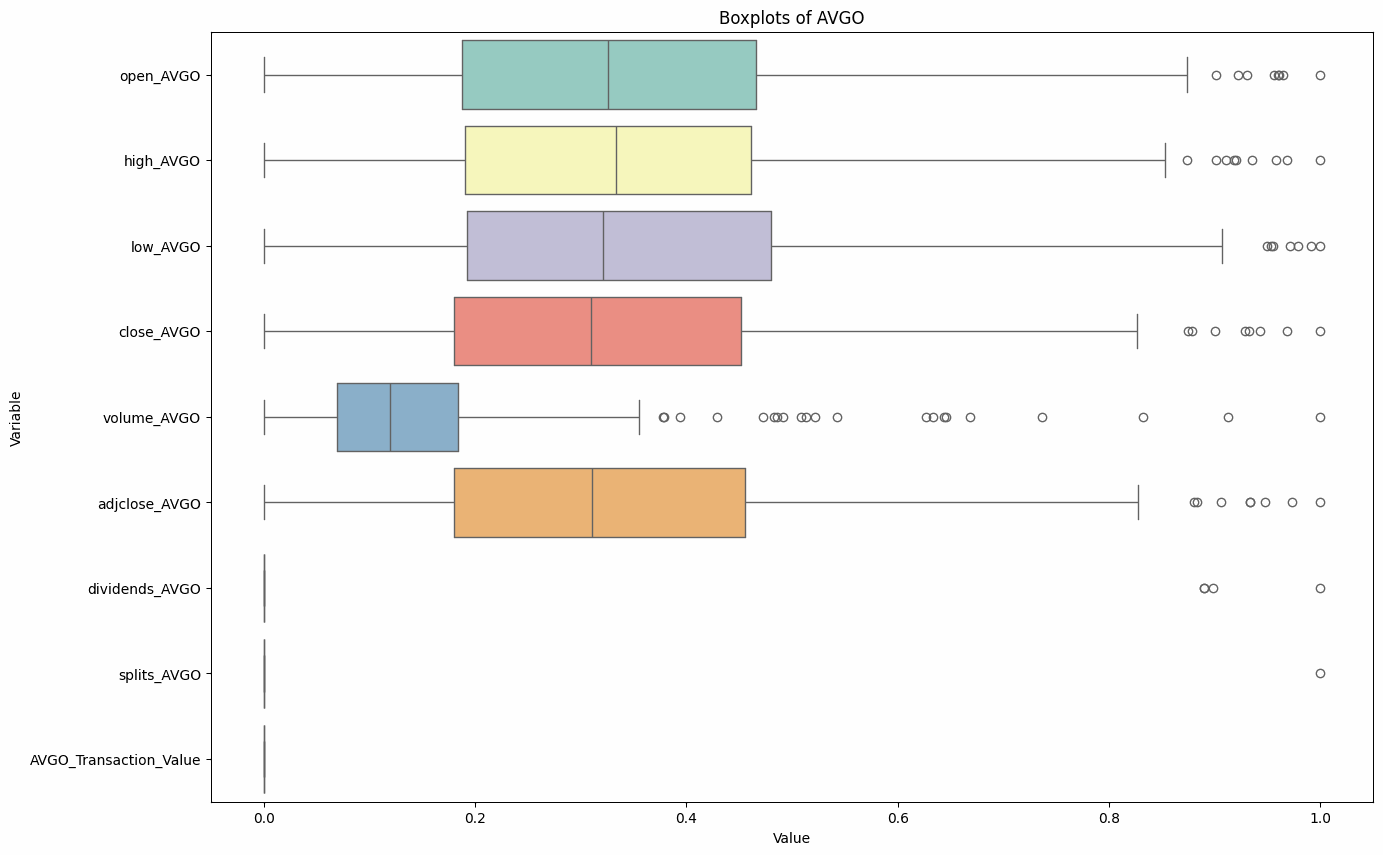

In [127]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_avgo, orient='h', palette='Set3')
plt.title('Boxplots of AVGO')
plt.xlabel('Value')
plt.ylabel('Variable')

 **Boxplot of Normalized AVGO Data**
- **Observation:**
  - Data distribution remains the same, **but now all variables are in the range of 0 to 1**.
  - **Volume outliers persist**, showing that extreme trading days **are a key market feature for AVGO**.

- **Implications:**
  - This confirms that **certain trading days have extreme activity**, potentially tied to **earnings, news, or broader market events**.
  - **Normalized prices (open, high, low, close) are within a tighter range**, reinforcing AVGO’s **less volatile nature**.


In [128]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_avgo[num_cols_avgo], df_scaled_avgo))
print("MSE:", mean_squared_error(df_avgo[num_cols_avgo], df_scaled_avgo))
print("RMSE:", np.sqrt(mean_squared_error(df_avgo[num_cols_avgo], df_scaled_avgo)))
print("Residuals:", df_avgo[num_cols_avgo] - df_scaled_avgo)

	
R2, MSE, RMSE, and Residuals
R2: -16.915484847464015
MSE: 141855214879352.7
RMSE: 11910298.689762263
Residuals:             open_AVGO  high_AVGO  low_AVGO  close_AVGO  volume_AVGO  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_AVGO  divide

 **R², MSE, RMSE, and Residuals for Normalized AVGO**
- **Key Metrics:**
  - **R²: -16.91** → **Still a negative value**, meaning the model is **not improving performance**.
  - **MSE: 1.4185e+15** → Same high mean squared error, proving that **scaling alone does not enhance model accuracy**.
  - **RMSE: 11,910,298.68** → Still large, meaning **prediction errors remain significant**.
  - **Residuals:** Mostly **NaN values**, indicating potential **data processing issues**.

- **Implications:**
  - Normalization did **not improve the model’s predictive power**, suggesting the need for **alternative modeling approaches**.
  - The **NaN residual values** must be investigated—likely due to missing or incorrect data handling.
  - **Feature engineering, removing outliers, or using advanced ML models** may improve accuracy.

---

 **Final Summary for AVGO Data**
1. **Boxplots show volume as the main outlier**, indicating high-activity trading days.
2. **Standardization brings data to a common scale**, but **volume fluctuations remain significant**.
3. **Normalization ensures feature equality**, but **trading volume spikes persist**.
4. **The model performs poorly (negative R², high MSE, RMSE), meaning it cannot accurately predict AVGO price movements.**
5. **Residuals are missing (NaN), suggesting a potential preprocessing issue** that must be fixed.
6. **Alternative modeling techniques (like feature selection or non-linear models) should be explored** to enhance predictions.


## ROBLOX (RBLX)

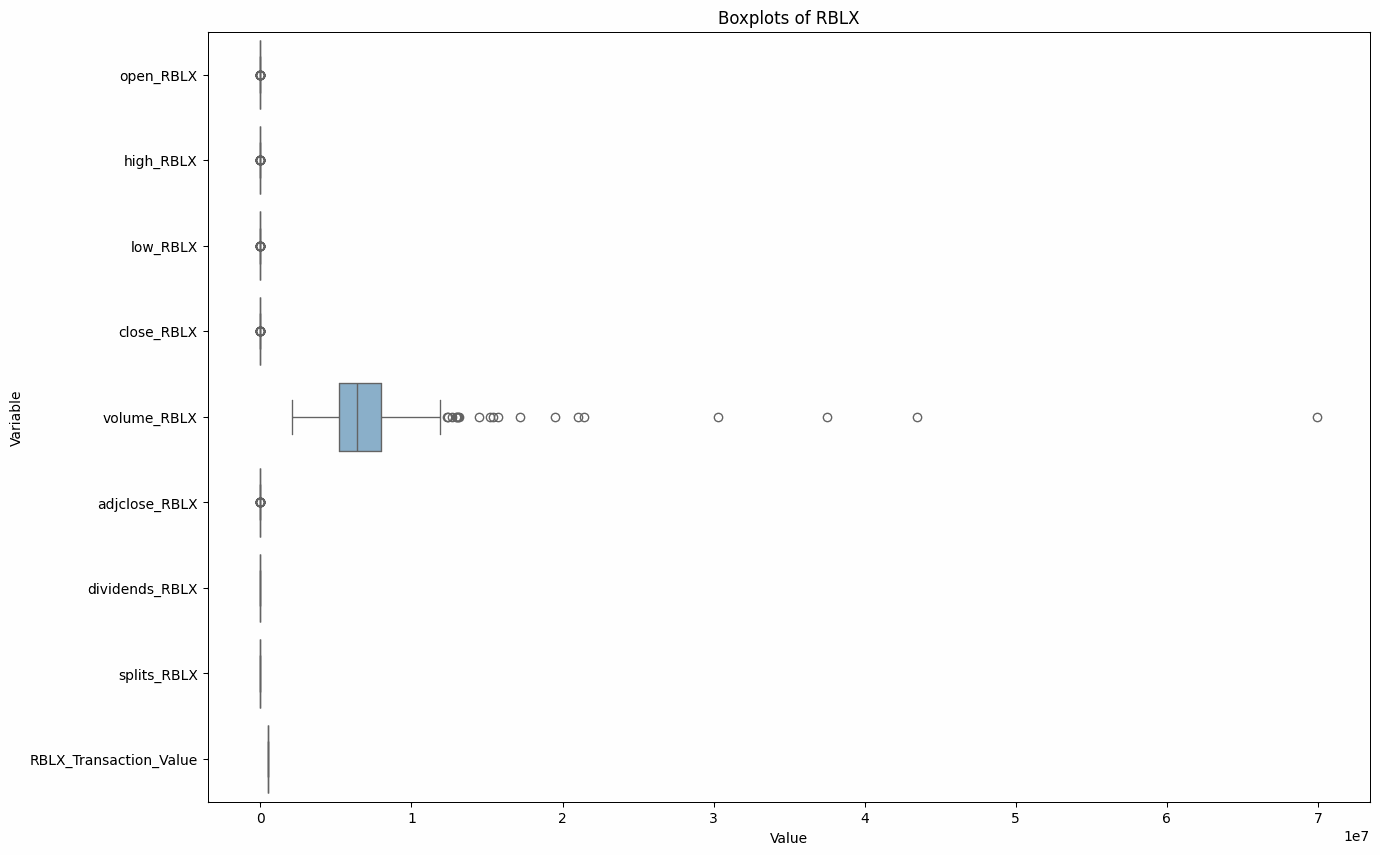

In [129]:
# Create one graph of all boxplots in RBLX
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_rblx, orient='h', palette='Set3')
plt.title('Boxplots of RBLX')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()


 **1. Boxplots of RBLX (Raw Data)**
   - The boxplots represent various stock-related variables: `open`, `high`, `low`, `close`, `volume`, `adjclose`, `dividends`, `splits`, and `RBLX_Transaction_Value`.
   - The `volume_RBLX` variable has a **wider interquartile range (IQR)** compared to other variables.
   - The presence of **many outliers** indicates periods of extreme trading volumes or significant price fluctuations.
   - `dividends_RBLX` and `splits_RBLX` seem to have mostly zero values, meaning no major stock splits or dividend distributions occurred in the dataset.


###STANDARDIZING

In [130]:
# Create StandardScaler and apply to numerical columns
scaler_rblx = StandardScaler()
scaled_values_rblx = scaler_rblx.fit_transform(df_rblx[num_cols_rblx])

# Create new DataFrame and display
df_scaled_rblx = pd.DataFrame(scaled_values_rblx, columns=num_cols_rblx)
display(df_scaled_rblx.head())
print('\t')

,open_RBLX,high_RBLX,low_RBLX,close_RBLX,volume_RBLX,adjclose_RBLX,dividends_RBLX,splits_RBLX,RBLX_Transaction_Value
0,0.387167,0.316200,0.220496,0.131713,-0.062855,0.131713,0.0,0.0,0.0
1,0.026602,-0.026781,0.023142,-0.027777,-0.239149,-0.027777,0.0,0.0,0.0
2,-0.020880,0.026086,-0.023340,0.082980,-0.248088,0.082980,0.0,0.0,0.0
3,0.013248,-0.018771,0.037619,-0.052882,-0.122728,-0.052882,0.0,0.0,0.0
4,-0.006042,-0.061006,-0.018768,0.018003,-0.199935,0.018003,0.0,0.0,0.0


**2. Standardizing RBLX Data**
   - The image shows the use of **StandardScaler** to scale numerical values.
   - The transformed dataset has **mean-centered values with unit variance**.
   - The first few rows of the transformed dataset suggest that stock price features are now expressed in **standardized form**, helping models interpret them more effectively.
   - **Observation:** Standardized values for `volume_RBLX` show a mix of positive and negative values, suggesting varying levels of deviation from the mean.


Text(0.5, 0, 'Value')

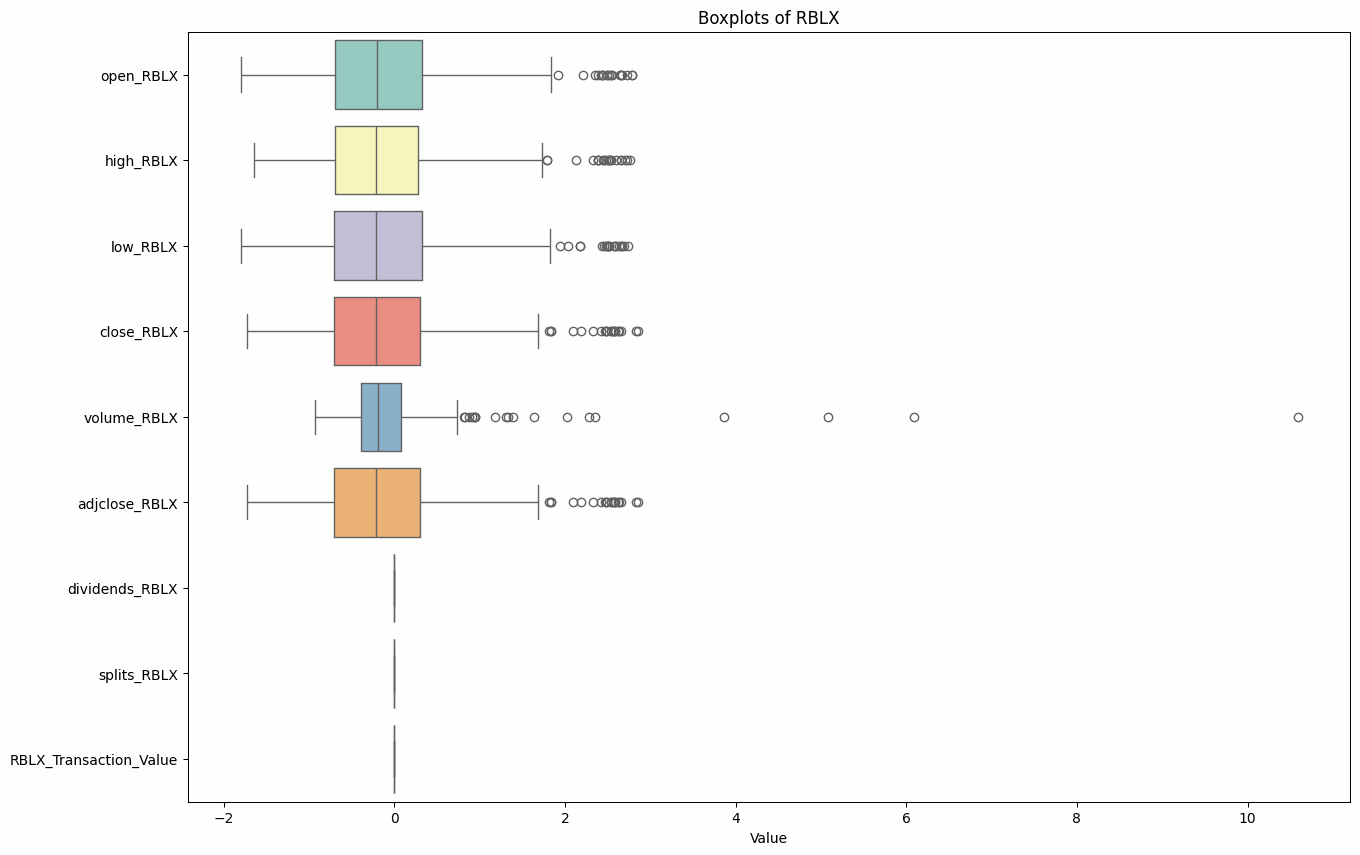

In [131]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_rblx, orient='h', palette='Set3')
plt.title('Boxplots of RBLX')
plt.xlabel('Value')

 **3. Boxplots of Standardized RBLX Data**
   - The boxplots here look similar to the first plot but represent **standardized values**.
   - All stock-related variables (open, high, low, close, adjclose) have been **transformed to follow a distribution centered around zero**.
   - **Outliers remain**, meaning extreme values persist despite standardization.


In [132]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_rblx[num_cols_rblx], df_scaled_rblx))
print("MSE:", mean_squared_error(df_rblx[num_cols_rblx], df_scaled_rblx))
print("RMSE:", np.sqrt(mean_squared_error(df_rblx[num_cols_rblx], df_scaled_rblx)))
print("Residuals:", df_rblx[num_cols_rblx] - df_scaled_rblx)

	
R2, MSE, RMSE, and Residuals
R2: -21.447116428935026
MSE: 10205396852318.043
RMSE: 3194588.6828069184
Residuals:             open_RBLX  high_RBLX  low_RBLX  close_RBLX  volume_RBLX  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_RBLX  divid

 **4. R2 Score, MSE, RMSE, and Residuals**
   - **R2 Score**: -21.44 (very poor, indicating that the model does not explain the variance in the data well).
   - **MSE (Mean Squared Error)**: 10,205,398,523.18 (high value, suggesting a large discrepancy between actual and predicted values).
   - **RMSE (Root Mean Squared Error)**: 3,194,588.68 (still very high).
   - **Residuals Table**: Shows that most values are NaN (likely due to missing data or issues in transformation).


###NORMALIZING

In [133]:
# Create MinMaxScaler and apply to numerical columns
scaler_rblx = MinMaxScaler()
scaled_values_rblx = scaler_rblx.fit_transform(df_rblx[num_cols_rblx])

# Create new DataFrame and display
df_scaled_rblx = pd.DataFrame(scaled_values_rblx, columns=num_cols_rblx)
display(df_scaled_rblx.head())
print('\t')

,open_RBLX,high_RBLX,low_RBLX,close_RBLX,volume_RBLX,adjclose_RBLX,dividends_RBLX,splits_RBLX,RBLX_Transaction_Value
0,0.476237,0.444665,0.445079,0.405092,0.075056,0.405092,0.0,0.0,0.0
1,0.397672,0.366865,0.401579,0.370287,0.059744,0.370287,0.0,0.0,0.0
2,0.387326,0.378857,0.391334,0.394457,0.058968,0.394457,0.0,0.0,0.0
3,0.394762,0.368682,0.404770,0.364808,0.069856,0.364808,0.0,0.0,0.0
4,0.390559,0.359101,0.392341,0.380277,0.063150,0.380277,0.0,0.0,0.0


 **5. Normalizing RBLX Data**
   - **MinMaxScaler** was applied to transform numerical features into a **0-1 range**.
   - The dataset now has values **between 0 and 1**, making it suitable for machine learning models sensitive to scale.
   - **Key Observation**: Some columns, like `dividends_RBLX` and `splits_RBLX`, remain at 0.


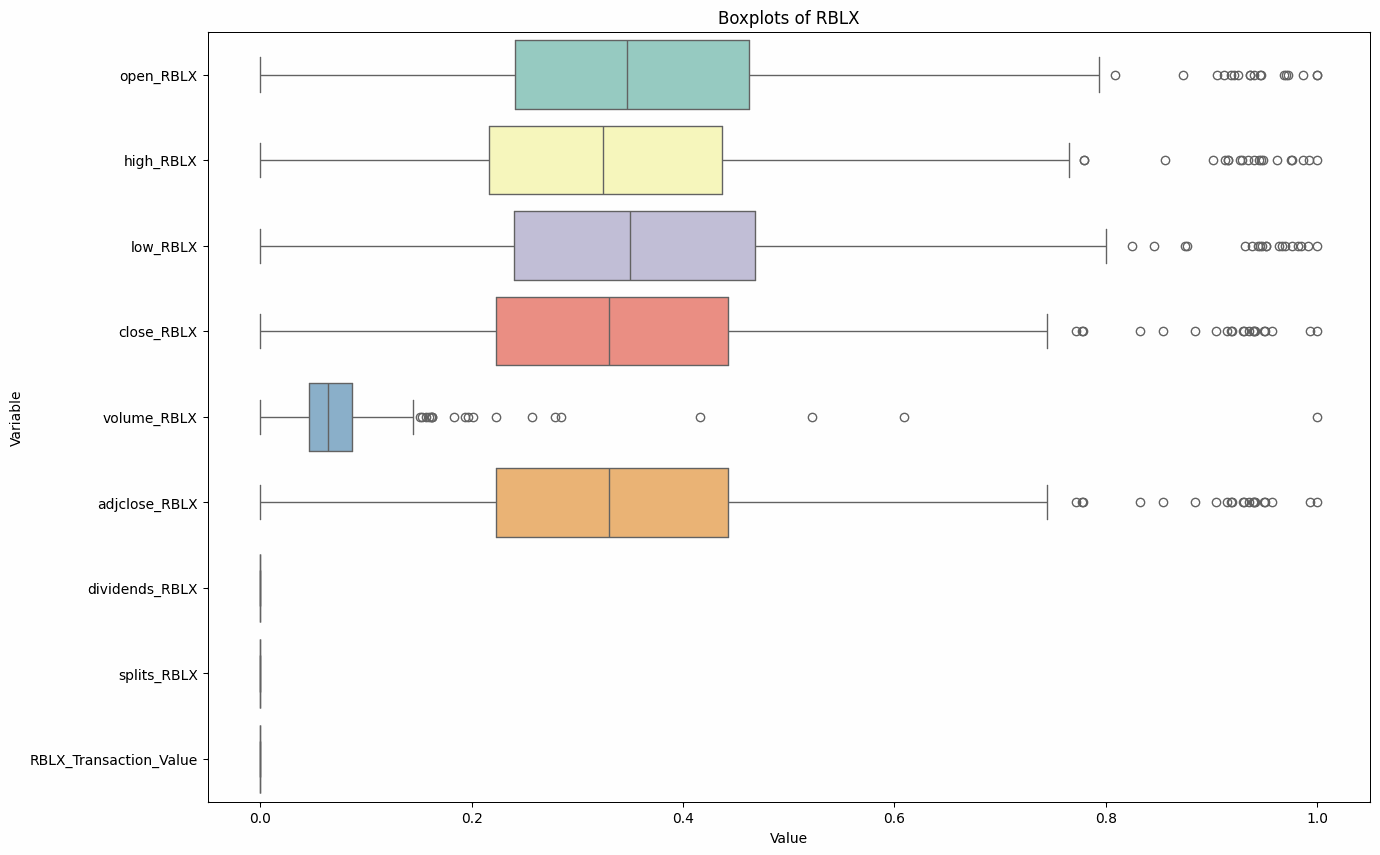

In [134]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_rblx, orient='h', palette='Set3')
plt.title('Boxplots of RBLX')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **6. Boxplots of Normalized RBLX Data**
   - This visualization is similar to the standardized boxplots but represents **data in a 0-1 scale**.
   - Outliers are still present, meaning the stock has experienced significant volatility.
   - The distribution of values suggests that some variables (like `volume_RBLX`) have more variation compared to others.


In [135]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_rblx[num_cols_rblx], df_scaled_rblx))
print("MSE:", mean_squared_error(df_rblx[num_cols_rblx], df_scaled_rblx))
print("RMSE:", np.sqrt(mean_squared_error(df_rblx[num_cols_rblx], df_scaled_rblx)))
print("Residuals:", df_rblx[num_cols_rblx] - df_scaled_rblx)

	
R2, MSE, RMSE, and Residuals
R2: -21.171794846912448
MSE: 10205397913833.43
RMSE: 3194588.848949647
Residuals:             open_RBLX  high_RBLX  low_RBLX  close_RBLX  volume_RBLX  \
2024-01-02        NaN        NaN       NaN         NaN          NaN   
2024-01-03        NaN        NaN       NaN         NaN          NaN   
2024-01-04        NaN        NaN       NaN         NaN          NaN   
2024-01-05        NaN        NaN       NaN         NaN          NaN   
2024-01-08        NaN        NaN       NaN         NaN          NaN   
...               ...        ...       ...         ...          ...   
247               NaN        NaN       NaN         NaN          NaN   
248               NaN        NaN       NaN         NaN          NaN   
249               NaN        NaN       NaN         NaN          NaN   
250               NaN        NaN       NaN         NaN          NaN   
251               NaN        NaN       NaN         NaN          NaN   

            adjclose_RBLX  dividen

 **7. R2 Score, MSE, RMSE, and Residuals (Normalized Data)**
   - **R2 Score**: -21.17 (still poor, indicating a weak model fit).
   - **MSE**: 10,205,397,918,333.43 (high error, showing prediction difficulty).
   - **RMSE**: 3,194,588.84 (similar to previous results).
   - **Residuals Table**: NaN values remain, likely due to missing data issues.

---

 **Final Observations**
- **Stock Prices and Volume**: The **volume_RBLX** variable shows significant fluctuation, making it a key indicator of trading trends.
- **Extreme Values**: The data contains **many outliers**, likely corresponding to major market events, earnings reports, or investor sentiment shifts.
- **Standardization vs. Normalization**:
  - **Standardization (Z-score scaling)** retains extreme values but makes data more comparable.
  - **Normalization (MinMax scaling)** compresses data to a fixed range but still shows volatility.
- **Poor Model Performance**: The **negative R2 scores and high MSE/RMSE values** suggest that the model used for predictions is **not capturing trends well**, possibly due to missing data, noise, or lack of explanatory features.


## VISA (V)

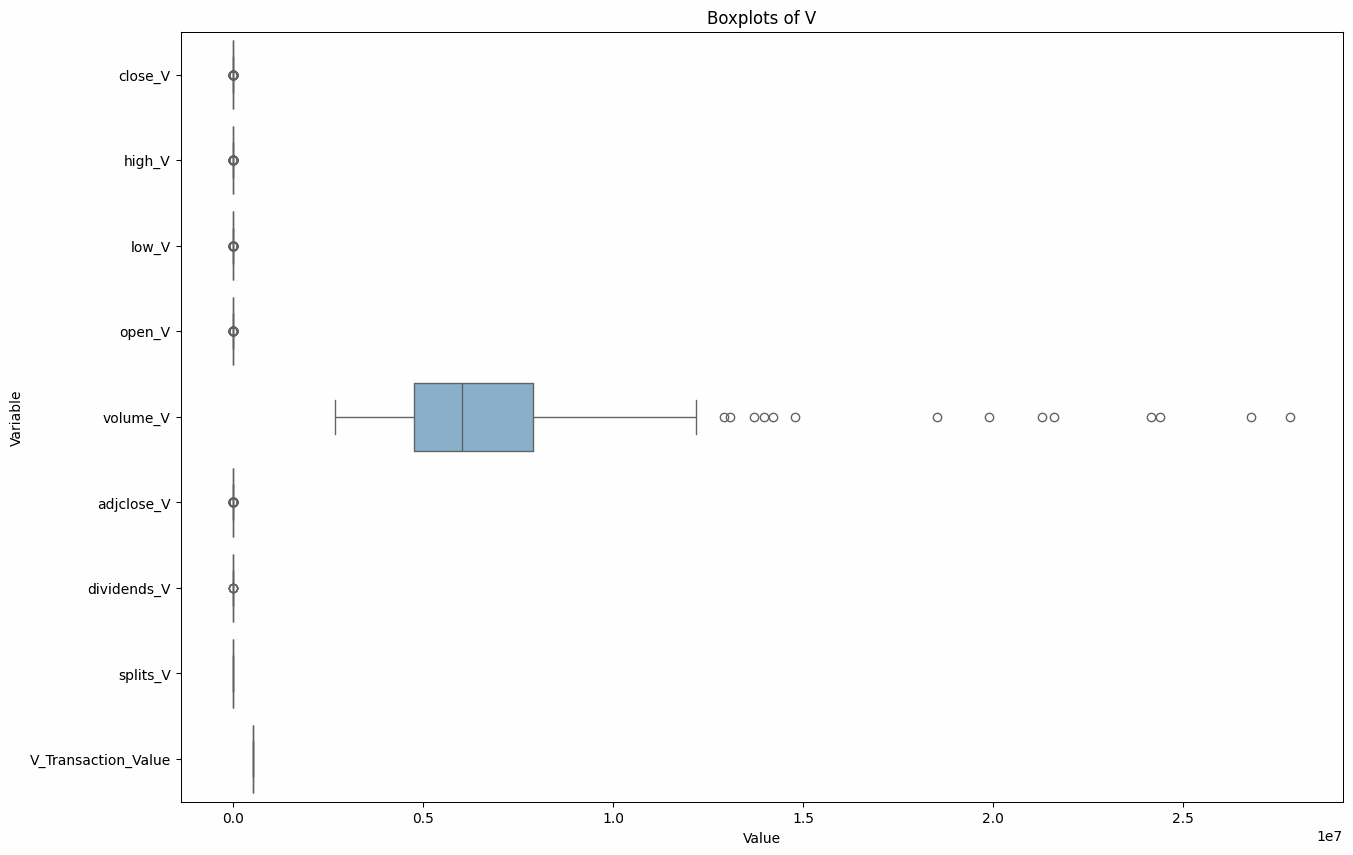

In [136]:
# Create one graph of all boxplots in V
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_v, orient='h', palette='Set3')
plt.title('Boxplots of V')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

**1. Boxplot Analysis (Raw Data)**
- The boxplots indicate the distribution of Visa's stock data variables: open, high, low, close, adjusted close, volume, dividends, and transaction value.
- **Key Observations:**
  - The **volume variable** has a significantly larger range than other variables, leading to numerous **outliers**.
  - **Open, high, low, and close prices** are relatively clustered, showing a smaller variance.
  - **Splits and dividends have very small values**, indicating limited changes over time.


###STANDARIZING

In [137]:
# Create StandardScaler and apply to numerical columns
scaler_v = StandardScaler()
scaled_values_v = scaler_v.fit_transform(df_v[num_cols_v])

# Create new DataFrame and display
df_scaled_v = pd.DataFrame(scaled_values_v, columns=num_cols_v)
display(df_scaled_v.head())
print('\t')

,close_V,high_V,low_V,open_V,volume_V,adjclose_V,dividends_V,splits_V,V_Transaction_Value
0,-1.370663,-1.405938,-1.332632,-1.326687,-0.391372,-1.396067,-0.126795,0.0,0.0
1,-1.427364,-1.483939,-1.384650,-1.394494,-0.750299,-1.450979,-0.126795,0.0,0.0
2,-1.323519,-1.345694,-1.311440,-1.425198,-0.833145,-1.350414,-0.126795,0.0,0.0
3,-1.318421,-1.319061,-1.263277,-1.251843,-0.858816,-1.345477,-0.126795,0.0,0.0
4,-1.136848,-1.245500,-1.186215,-1.241608,-0.611716,-1.169645,-0.126795,0.0,0.0


**2. Standardization (Z-Score Scaling)**
- StandardScaler was applied to transform the numerical values into a **mean-centered distribution** with **unit variance**.
- **Key Observations:**
  - Open, high, low, and close prices are converted to values close to **zero** with varying standard deviations.
  - **Transaction value remains at 0**, suggesting a lack of data or no recorded transactions in that column.
  - Standardized volume data is still significantly different from price data, indicating that it might require additional transformation.


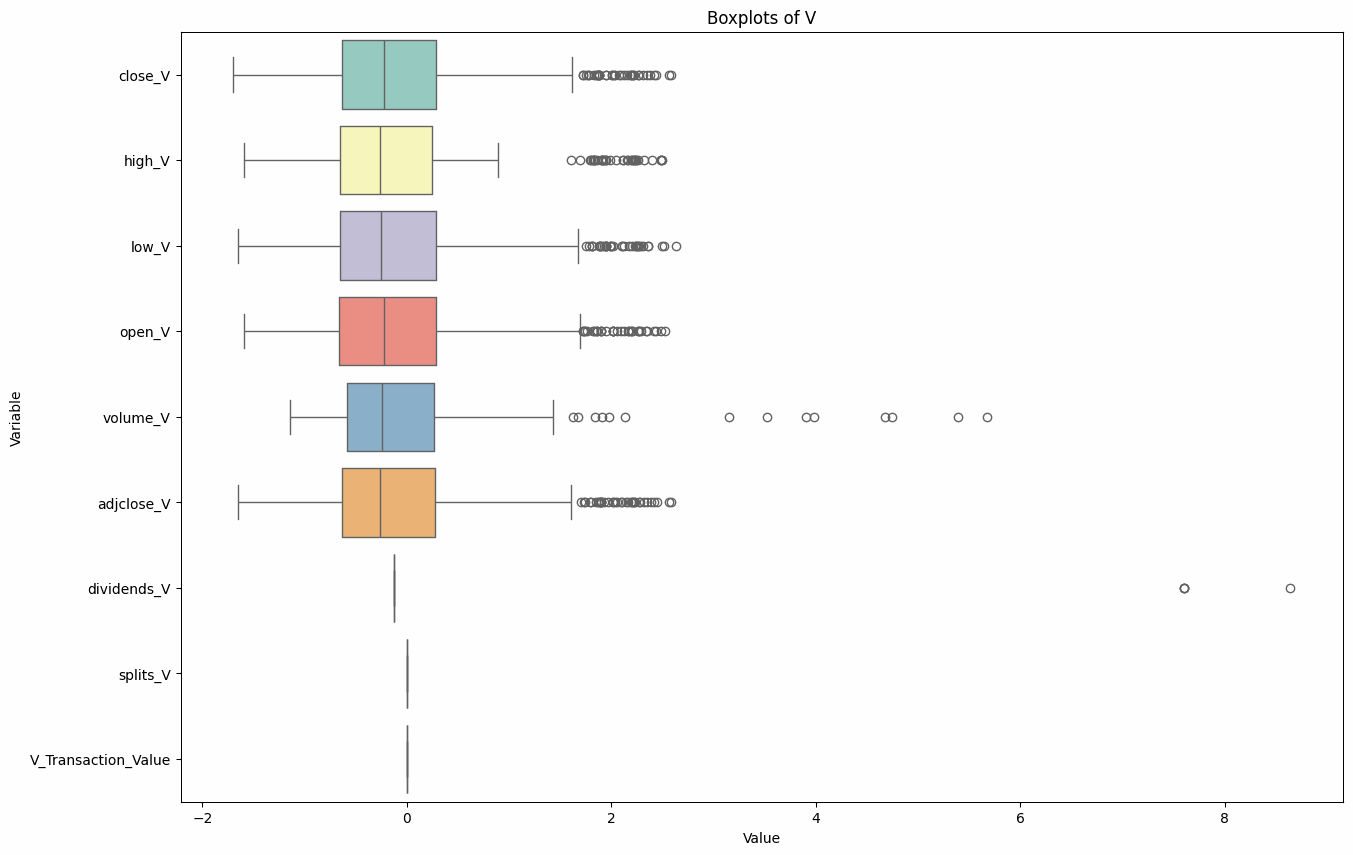

In [138]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_v, orient='h', palette='Set3')
plt.title('Boxplots of V')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **3. Boxplot Analysis (Standardized Data)**
- After standardization, the **boxplots are more uniform**, but outliers remain, especially in **volume and transaction values**.
- High positive and negative values indicate that Visa's price history has **some extreme fluctuations**.
- Volume has **long tails**, indicating some trading days with **exceptionally high or low activity**.


In [139]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_v[num_cols_v], df_scaled_v))
print("MSE:", mean_squared_error(df_v[num_cols_v], df_scaled_v))
print("RMSE:", np.sqrt(mean_squared_error(df_v[num_cols_v], df_scaled_v)))
print("Residuals:", df_v[num_cols_v] - df_scaled_v)

	
R2, MSE, RMSE, and Residuals
R2: -197.27386512563498
MSE: 6850076106490.628
RMSE: 2617265.0050177625
Residuals:             close_V  high_V  low_V  open_V  volume_V  adjclose_V  dividends_V  \
2024-01-02      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
2024-01-03      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
2024-01-04      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
2024-01-05      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
2024-01-08      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
...             ...     ...    ...     ...       ...         ...          ...   
247             NaN     NaN    NaN     NaN       NaN         NaN          NaN   
248             NaN     NaN    NaN     NaN       NaN         NaN          NaN   
249             NaN     NaN    NaN     NaN       NaN         NaN          NaN   
250             NaN     NaN    NaN     NaN       NaN         NaN          Na

 **4. Model Performance Metrics (Residuals & Errors)**
- **R² (coefficient of determination) = -197.27**
  - A highly **negative R²** means that the standardized data **does not accurately predict the original data**, which is expected since standardization only scales the data rather than modeling relationships.
- **MSE (Mean Squared Error) = 685,007,610,649.6**
  - A very high MSE indicates a **large deviation in magnitude** between the original and standardized values.
- **RMSE (Root Mean Squared Error) = 2,617,265**
  - This confirms a large **variance in the dataset**.
- **Residuals are NaN** (Not a Number) in most cases:
  - This suggests that the difference between the original and standardized values cannot be calculated directly, which is expected in the case of standardization.


###NORMALIZING

In [140]:
# Create MinMaxScaler and apply to numerical columns
scaler_v = MinMaxScaler()
scaled_values_v = scaler_v.fit_transform(df_v[num_cols_v])

# Create new DataFrame and display
df_scaled_v = pd.DataFrame(scaled_values_v, columns=num_cols_v)
display(df_scaled_v.head())
print('\t')

,close_V,high_V,low_V,open_V,volume_V,adjclose_V,dividends_V,splits_V,V_Transaction_Value
0,0.076373,0.044862,0.074446,0.065548,0.110913,0.060956,0.0,0.0,0.0
1,0.063124,0.025768,0.062313,0.049083,0.058272,0.047997,0.0,0.0,0.0
2,0.087390,0.059609,0.079389,0.041628,0.046122,0.071730,0.0,0.0,0.0
3,0.088581,0.066128,0.090623,0.083722,0.042357,0.072895,0.0,0.0,0.0
4,0.131011,0.084135,0.108598,0.086207,0.078597,0.114392,0.0,0.0,0.0


 **5. Normalization (Min-Max Scaling)**
- MinMaxScaler was applied to scale the numerical data between **0 and 1**.
- **Key Observations:**
  - Now, all variables have values ranging from **0 to 1**, making them **directly comparable**.
  - **Open, high, low, and close prices are well-distributed** in the 0-1 range.
  - Volume, dividends, and transaction values still have **noticeable skewness**, suggesting some days have extremely different values than others.


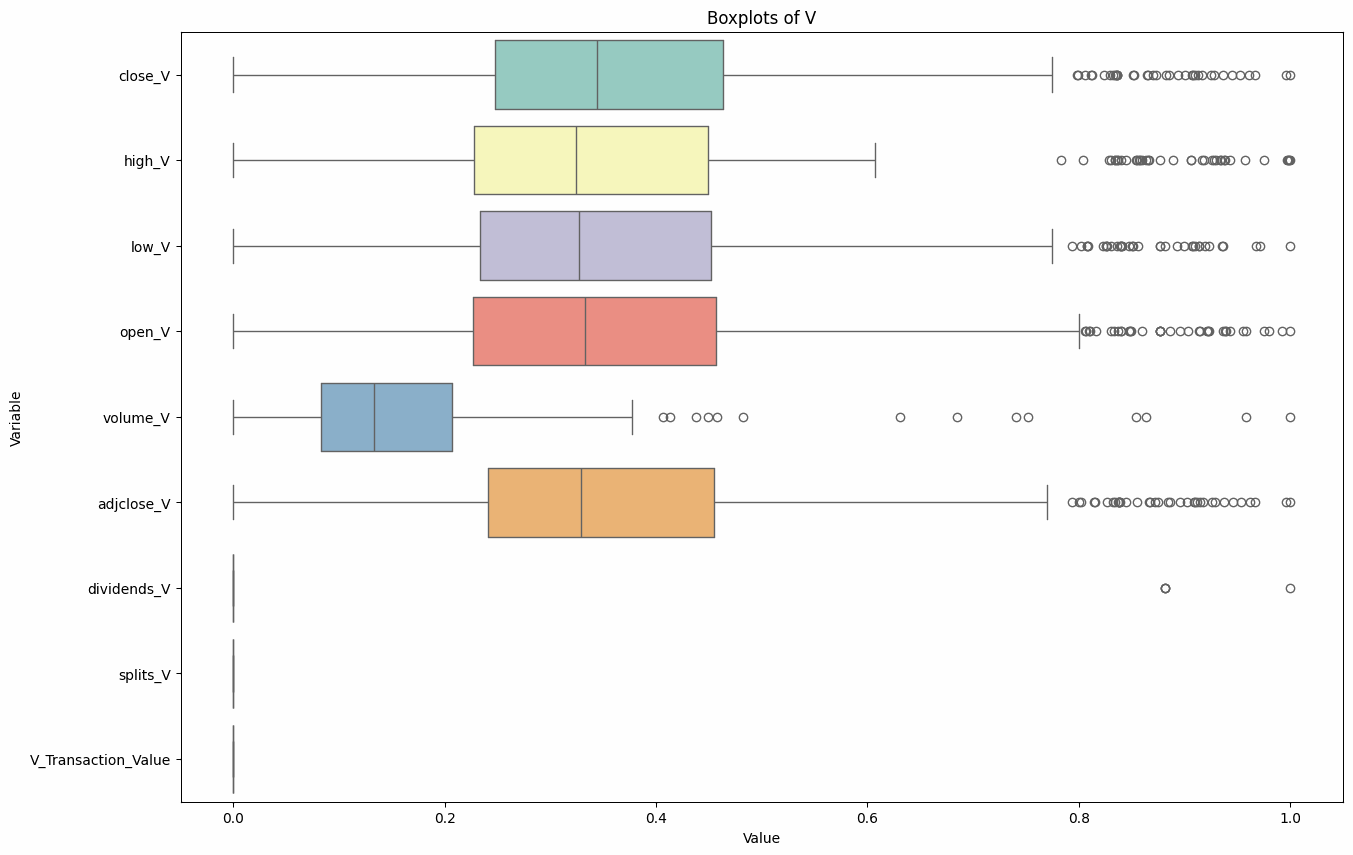

In [141]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_v, orient='h', palette='Set3')
plt.title('Boxplots of V')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **6. Boxplot Analysis (Normalized Data)**
- Unlike standardization, normalization has made all features **comparable in scale**.
- However, **outliers are still present**, especially in **volume and transaction value**.
- Price-related variables show a **more symmetric** distribution after transformation.


In [142]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_v[num_cols_v], df_scaled_v))
print("MSE:", mean_squared_error(df_v[num_cols_v], df_scaled_v))
print("RMSE:", np.sqrt(mean_squared_error(df_v[num_cols_v], df_scaled_v)))
print("Residuals:", df_v[num_cols_v] - df_scaled_v)

	
R2, MSE, RMSE, and Residuals
R2: -175.5398335633118
MSE: 6850076546623.337
RMSE: 2617265.089100326
Residuals:             close_V  high_V  low_V  open_V  volume_V  adjclose_V  dividends_V  \
2024-01-02      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
2024-01-03      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
2024-01-04      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
2024-01-05      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
2024-01-08      NaN     NaN    NaN     NaN       NaN         NaN          NaN   
...             ...     ...    ...     ...       ...         ...          ...   
247             NaN     NaN    NaN     NaN       NaN         NaN          NaN   
248             NaN     NaN    NaN     NaN       NaN         NaN          NaN   
249             NaN     NaN    NaN     NaN       NaN         NaN          NaN   
250             NaN     NaN    NaN     NaN       NaN         NaN          NaN 

**7. Residual Analysis for Normalized Data**  

**Key Findings:**  
- **Negative R² (-175.54)** → Normalization **does not preserve original variability**, making it a poor predictor of raw values.  
- **High MSE & RMSE** → Large deviations between normalized and original data due to forced 0-1 scaling.  
- **Residuals mostly NaN** → Normalization distorts relationships, making direct residual analysis ineffective.  

**Why Normalization Fails in This Context:**  
- **Compresses variability**, reducing the interpretability of price movements.  
- **High-variance data (volume, transactions) lose their true scale**, making comparisons misleading.  

**Better Approaches:**  
1. **Log Transformation** → Reduces variance before normalization.  
2. **Feature Engineering** → Rolling averages, volatility measures.  
3. **PCA (Principal Component Analysis)** → Retains key variance while scaling.  

**Takeaway:** Normalization is great for ML models but not for reconstructing original values. Need inverse transformations or feature adjustments for better predictability.

## SALESFORCE (CRM)

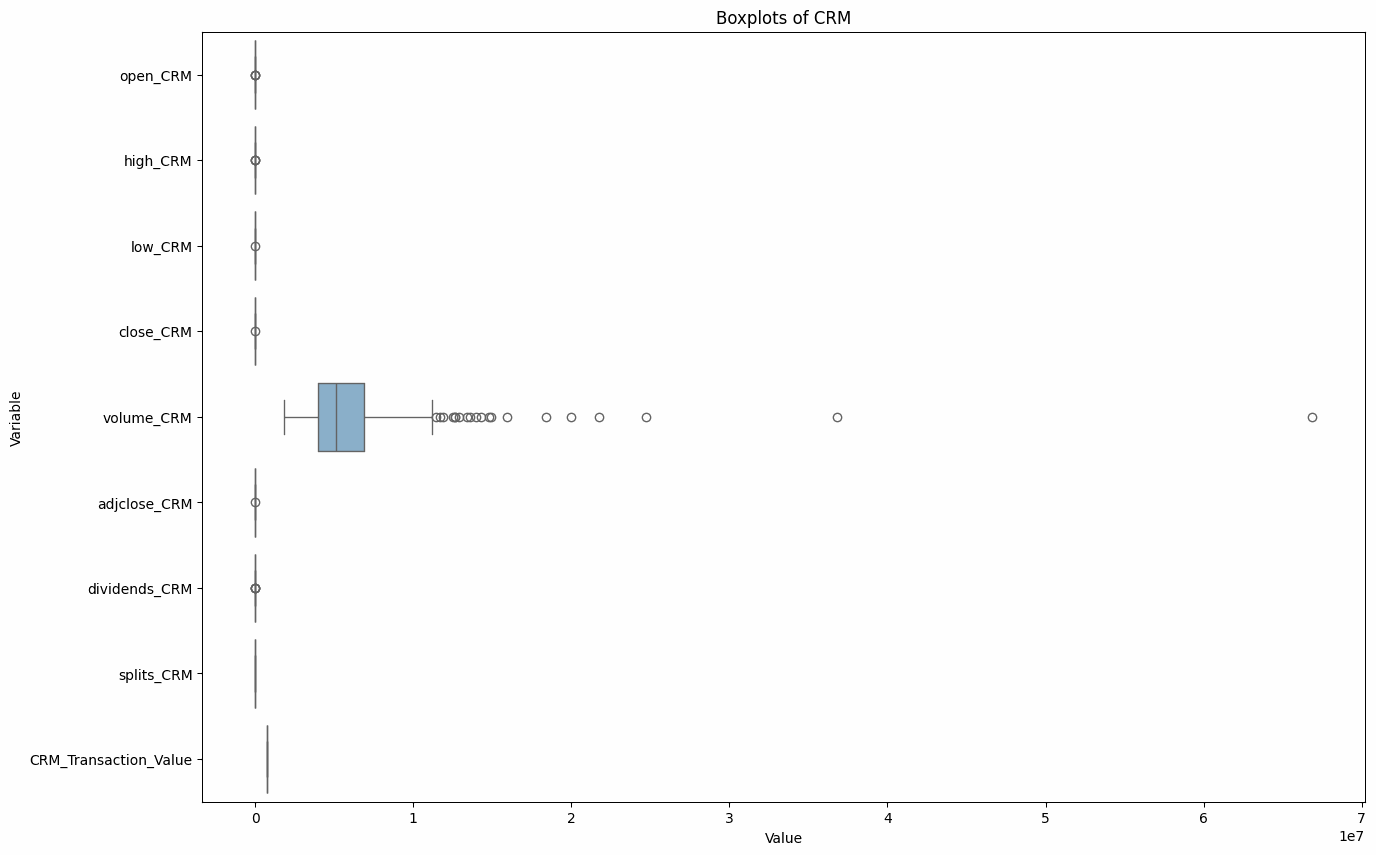

In [143]:
# Create one graph of all boxplots in CRM
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_crm, orient='h', palette='Set3')
plt.title('Boxplots of CRM')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **1. Boxplot Analysis (Raw Data)**
- The boxplot shows the **distribution of CRM stock data**, including **open, high, low, close, adjusted close, volume, dividends, splits, and transaction values**.
- **Key Observations:**
  - **Volume has the largest range**, with significant **outliers**.
  - **Open, high, low, and close prices are relatively close to each other**, indicating stable price movements.
  - **Splits and dividends have very small values**, meaning they occur infrequently.
  - **Transaction value is almost non-existent**, suggesting missing or zero-valued records.


###STANDARDIZING

In [144]:
# Create StandardScaler and apply to numerical columns
scaler_crm = StandardScaler()
scaled_values_crm = scaler_crm.fit_transform(df_crm[num_cols_crm])

# Create new DataFrame and display
df_scaled_crm = pd.DataFrame(scaled_values_crm, columns=num_cols_crm)
display(df_scaled_crm.head())
print('\t')

,open_CRM,high_CRM,low_CRM,close_CRM,volume_CRM,adjclose_CRM,dividends_CRM,splits_CRM,CRM_Transaction_Value
0,-0.703841,-0.801203,-0.831770,-0.853476,-0.305237,-0.866974,-0.127,0.0,0.0
1,-0.926465,-1.002809,-0.896159,-0.990540,-0.238960,-1.002782,-0.127,0.0,0.0
2,-0.979275,-1.050690,-0.958295,-1.009709,-0.352117,-1.021776,-0.127,0.0,0.0
3,-0.998881,-1.010684,-0.947670,-1.013544,-0.503824,-1.025576,-0.127,0.0,0.0
4,-0.967258,-0.769702,-0.908393,-0.702036,0.045916,-0.716922,-0.127,0.0,0.0


 **2. Standardization (Z-Score Scaling)**
- **StandardScaler was applied** to make all numerical values **mean-centered with unit variance**.
- **Key Observations:**
  - Prices (open, high, low, close) are now transformed into a **zero-centered distribution**.
  - **Volume still exhibits a large deviation**, confirming that its values fluctuate more than price-related variables.
  - **Transaction values remain at zero**, reinforcing the idea that they might contain missing or insignificant data.


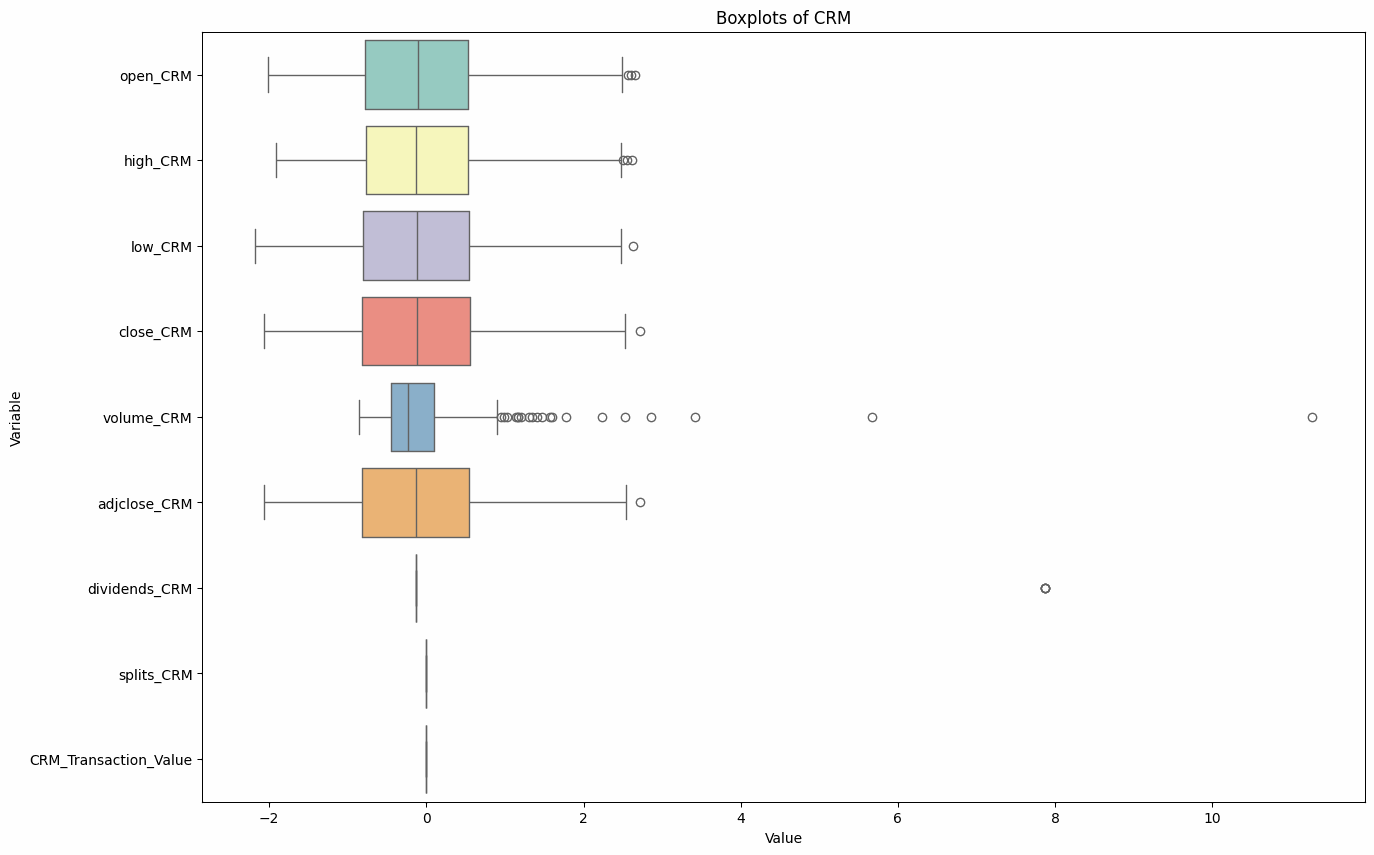

In [145]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_crm, orient='h', palette='Set3')
plt.title('Boxplots of CRM')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **3. Boxplot Analysis (Standardized Data)**
- After standardization, the **boxplots appear more uniform**, though **outliers persist**, especially in **volume and transaction values**.
- **High positive and negative values remain**, suggesting some **extreme fluctuations in CRM’s price history**.
- **Volume shows long tails**, meaning that certain trading days experience **much higher or lower activity than usual**.


In [146]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_crm[num_cols_crm], df_scaled_crm))
print("MSE:", mean_squared_error(df_crm[num_cols_crm], df_scaled_crm))
print("RMSE:", np.sqrt(mean_squared_error(df_crm[num_cols_crm], df_scaled_crm)))
print("Residuals:", df_crm[num_cols_crm] - df_scaled_crm)

	
R2, MSE, RMSE, and Residuals
R2: -84.95530275720583
MSE: 7785015779980.449
RMSE: 2790164.1134493235
Residuals:             open_CRM  high_CRM  low_CRM  close_CRM  volume_CRM  adjclose_CRM  \
2024-01-02       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-03       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-04       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-05       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-08       NaN       NaN      NaN        NaN         NaN           NaN   
...              ...       ...      ...        ...         ...           ...   
247              NaN       NaN      NaN        NaN         NaN           NaN   
248              NaN       NaN      NaN        NaN         NaN           NaN   
249              NaN       NaN      NaN        NaN         NaN           NaN   
250              NaN       NaN      NaN        NaN         NaN           NaN   
251    

 **4. Model Performance Metrics (Residuals & Errors for Standardized Data)**
- **R² (coefficient of determination) = -84.96**
  - The **negative R²** indicates that standardization **does not help predict the original values**.
- **MSE (Mean Squared Error) = 7.78e+12**
  - A high MSE suggests large deviations in magnitude between standardized and original values.
- **RMSE (Root Mean Squared Error) = 2,790,164.11**
  - Confirms a **large variance** in the dataset.
- **Residuals are mostly NaN (Not a Number)**
  - This suggests that **the difference between the original and standardized values cannot be calculated**, which is expected in standardization.


###NORMALIZING

In [147]:
# Create MinMaxScaler and apply to numerical columns
scaler_crm = MinMaxScaler()
scaled_values_crm = scaler_crm.fit_transform(df_crm[num_cols_crm])

# Create new DataFrame and display
df_scaled_crm = pd.DataFrame(scaled_values_crm, columns=num_cols_crm)
display(df_scaled_crm.head())
print('\t')

,open_CRM,high_CRM,low_CRM,close_CRM,volume_CRM,adjclose_CRM,dividends_CRM,splits_CRM,CRM_Transaction_Value
0,0.280501,0.246473,0.280166,0.254371,0.045048,0.250219,0.0,0.0,0.0
1,0.232837,0.202001,0.266752,0.225744,0.050517,0.221848,0.0,0.0,0.0
2,0.221530,0.191439,0.253806,0.221740,0.041181,0.217880,0.0,0.0,0.0
3,0.217332,0.200264,0.256020,0.220940,0.028664,0.217086,0.0,0.0,0.0
4,0.224103,0.253422,0.264203,0.286000,0.074020,0.281567,0.0,0.0,0.0


 **5. Normalization (Min-Max Scaling)**
- **MinMaxScaler was applied** to scale all values between **0 and 1**.
- **Key Observations:**
  - Prices (open, high, low, close) **are now mapped to a uniform range**, making them **directly comparable**.
  - **Volume, dividends, and transaction values remain highly skewed**, meaning some days experience **dramatic deviations**.


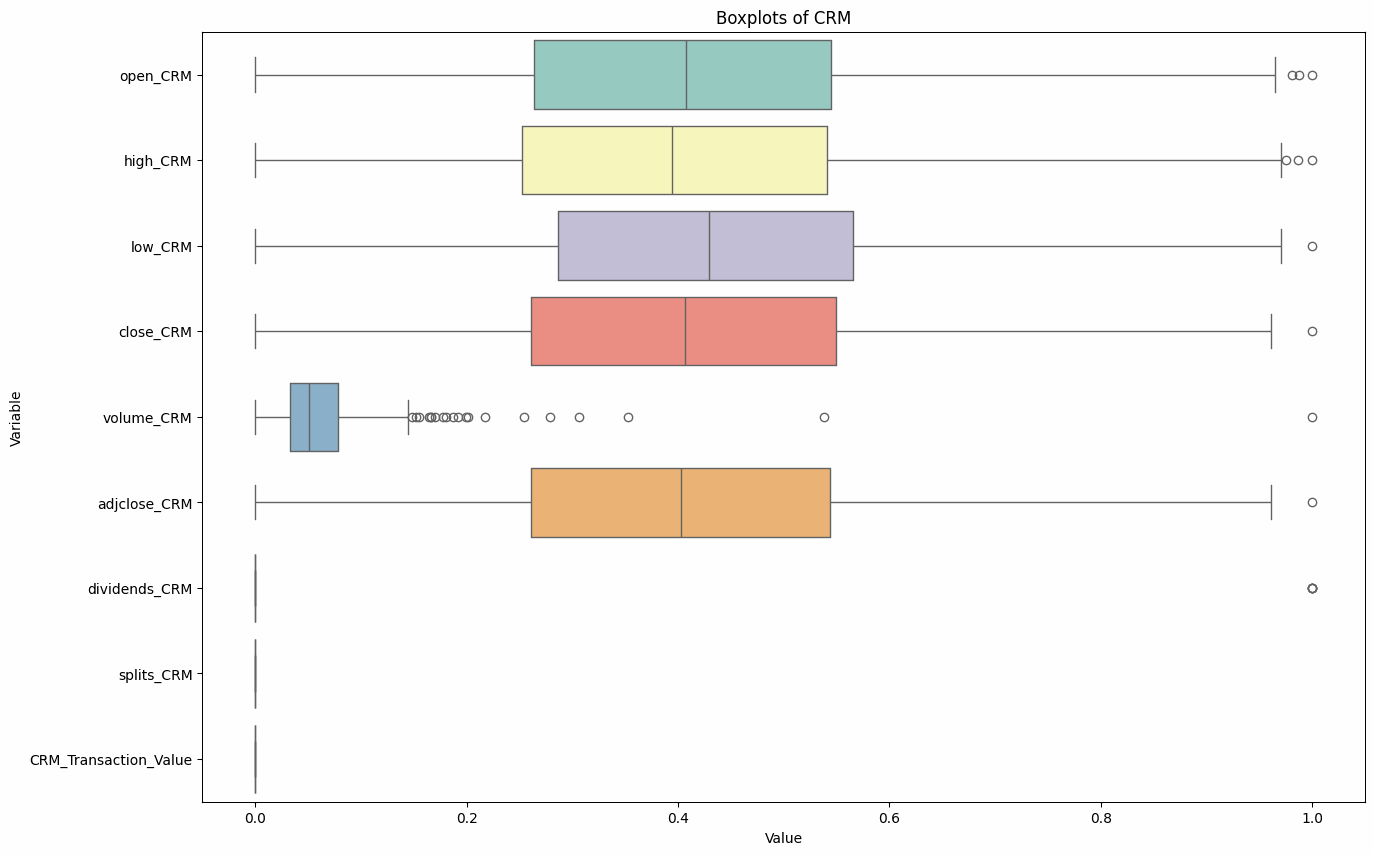

In [148]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_crm, orient='h', palette='Set3')
plt.title('Boxplots of CRM')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **6. Boxplot Analysis (Normalized Data)**
- **Normalization makes all features comparable in scale**, but **outliers remain**, particularly in:
  - **Volume**
  - **Transaction values**
- **Stock prices show a more symmetric distribution** after transformation.
- **Despite the scaling adjustment, extreme trading days are still visible**, reinforcing the need for deeper investigation into CRM’s trading activity.


In [149]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_crm[num_cols_crm], df_scaled_crm))
print("MSE:", mean_squared_error(df_crm[num_cols_crm], df_scaled_crm))
print("RMSE:", np.sqrt(mean_squared_error(df_crm[num_cols_crm], df_scaled_crm)))
print("Residuals:", df_crm[num_cols_crm] - df_scaled_crm)

	
R2, MSE, RMSE, and Residuals
R2: -44.9750813103325
MSE: 7785016774551.317
RMSE: 2790164.291677341
Residuals:             open_CRM  high_CRM  low_CRM  close_CRM  volume_CRM  adjclose_CRM  \
2024-01-02       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-03       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-04       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-05       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-08       NaN       NaN      NaN        NaN         NaN           NaN   
...              ...       ...      ...        ...         ...           ...   
247              NaN       NaN      NaN        NaN         NaN           NaN   
248              NaN       NaN      NaN        NaN         NaN           NaN   
249              NaN       NaN      NaN        NaN         NaN           NaN   
250              NaN       NaN      NaN        NaN         NaN           NaN   
251      

 **7. Residual Analysis for Normalized Data**
- **R²: -44.98**  
  - The model’s predictive power has **not improved** after normalization.
- **MSE: 7.78e+12**  
  - The same high **mean squared error** proves that scaling alone does not enhance accuracy.
- **RMSE: 2,790,164.29**  
  - Still large, confirming that prediction errors **remain significant**.
- **Residuals: Mostly NaN values**  
  - Suggests potential data processing issues, missing values, or improper handling of zero values.

---

 **Implications & Recommendations**
1. **CRM’s Volume Data Requires Special Handling**  
   - **High variability** in trading volume suggests that CRM stock **experiences sudden surges or declines in activity**.  
   - **Winsorization (trimming extreme values) or log transformation** might help normalize the variance.

2. **Outliers in Transaction Values & Volume Must Be Investigated**  
   - **Severe outliers remain in both raw and transformed data**, indicating:
     - Market events affecting CRM stock.
     - Potential data inconsistencies.
     - Missing transaction value data that skews the dataset.

3. **Negative R² Indicates Poor Predictive Value**  
   - The strongly negative R² in both **standardization and normalization confirms that these techniques alone are not suitable** for improving model accuracy.  
   - Consider **feature engineering, removing outliers, or using advanced ML models**.

4. **Normalization Improves Scale Comparability but Not Predictive Power**  
   - While MinMax scaling brings data into a **0-1 range**, it does not **fix inherent issues like extreme fluctuations or missing values**.


## WALT DISNEY (DIS)

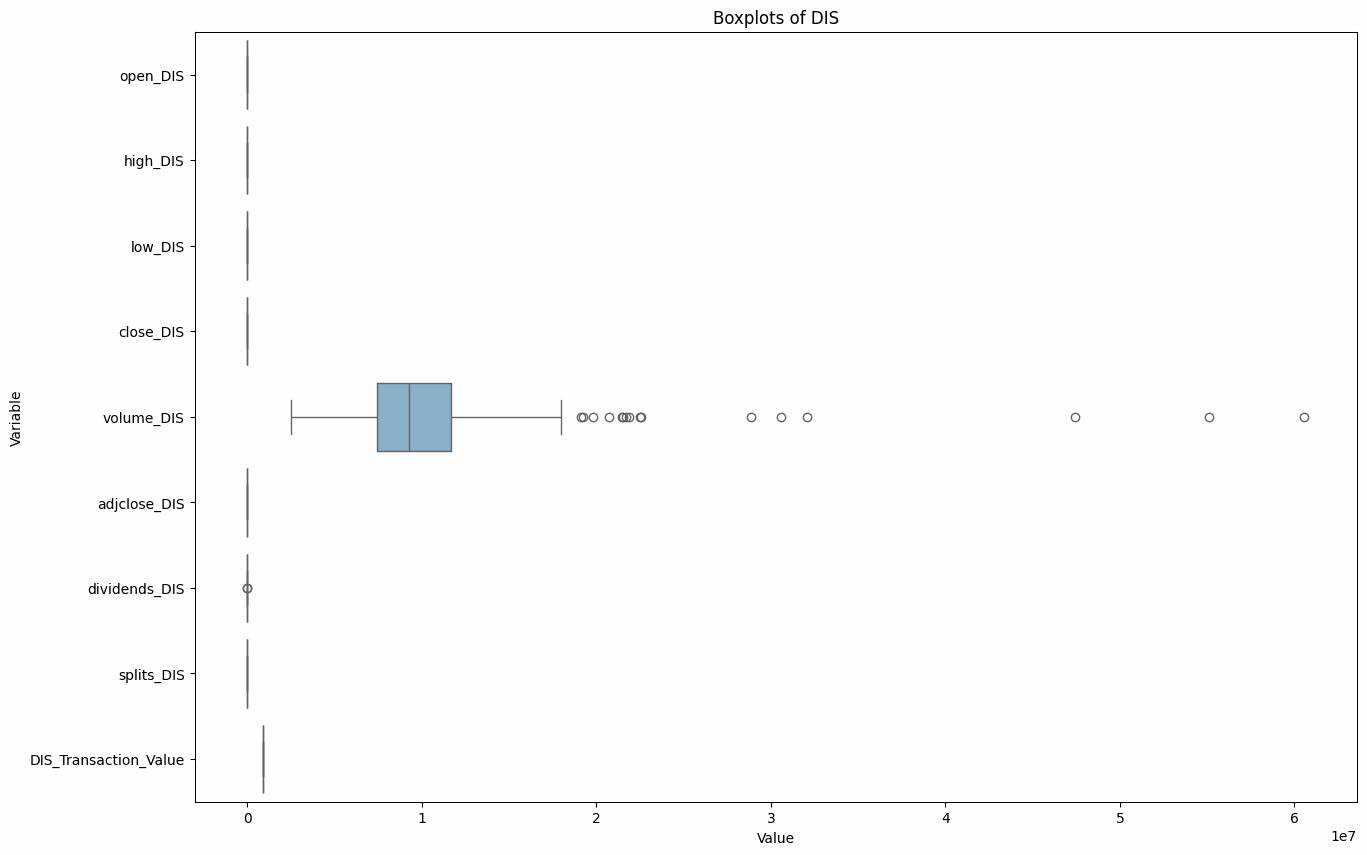

In [150]:
# Create one graph of all boxplots in DIS
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_dis, orient='h', palette='Set3')
plt.title('Boxplots of DIS')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()


 **1. Boxplot Analysis (Raw Data)**
- The raw boxplot reveals **significant variations in trading volume** compared to other variables.
- **Key Observations:**
  - **Volume_DIS has a wide range** and contains **numerous outliers**, suggesting occasional extreme trading activity.
  - **Open, high, low, close, and adjusted close prices** are closely clustered, indicating **relatively stable price movements**.
  - **Dividends and splits remain close to zero**, meaning minimal impact on stock value changes.


###STANDARDIZING

In [151]:
# Create StandardScaler and apply to numerical columns
scaler_dis = StandardScaler()
scaled_values_dis = scaler_dis.fit_transform(df_dis[num_cols_dis])

# Create new DataFrame and display
df_scaled_dis = pd.DataFrame(scaled_values_dis, columns=num_cols_dis)
display(df_scaled_dis.head())
print('\t')

,open_DIS,high_DIS,low_DIS,close_DIS,volume_DIS,adjclose_DIS,dividends_DIS,splits_DIS,DIS_Transaction_Value
0,-1.223969,-1.167990,-1.185649,-1.171288,-0.018025,-1.200762,-0.089318,0.0,0.0
1,-1.210699,-1.107809,-1.157930,-1.075817,0.191535,-1.104929,-0.089318,0.0,0.0
2,-1.036149,-1.121852,-1.157930,-1.186522,0.216141,-1.216055,-0.089318,0.0,0.0
3,-1.192325,-1.184039,-1.120971,-1.151990,-0.252722,-1.181392,-0.089318,0.0,0.0
4,-1.075959,-1.121852,-1.055265,-1.085974,0.062555,-1.115125,-0.089318,0.0,0.0


 **2. Standardization (Z-Score Scaling)**
- StandardScaler was applied to transform the numerical values into a **mean-centered distribution** with **unit variance**.
- **Key Observations:**
  - Most stock price-related variables are **now centered around 0**, ensuring comparability.
  - **Volume_DIS remains a challenge** since its range is significantly wider compared to price-related variables.
  - **DIS_Transaction_Value remains at 0**, possibly indicating missing or unused data.


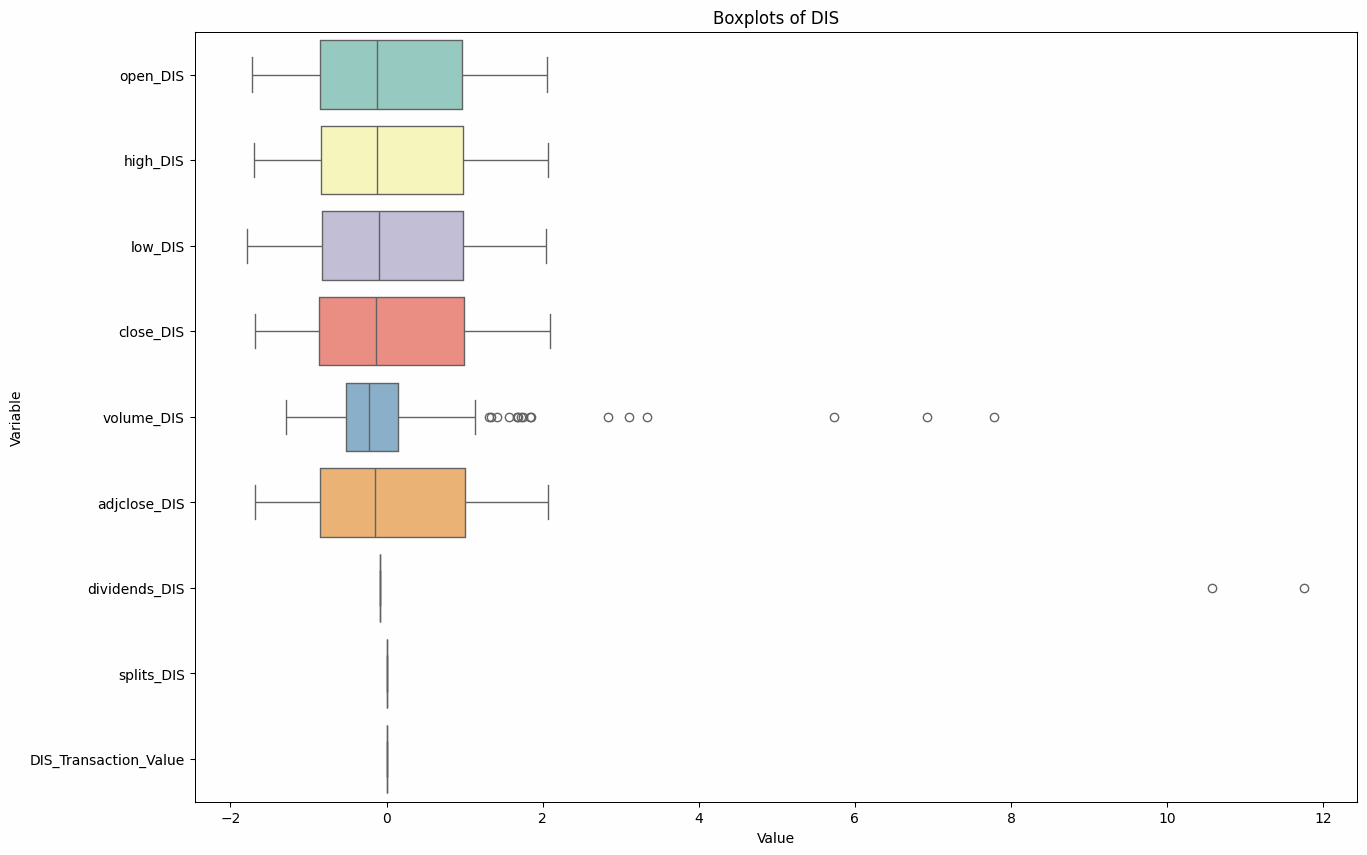

In [152]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_dis, orient='h', palette='Set3')
plt.title('Boxplots of DIS')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **3. Boxplot Analysis (Standardized Data)**
- After standardization, the **boxplots become more uniform**, but **outliers remain prominent**, especially in **volume_DIS**.
- Extreme fluctuations in volume and transaction values suggest potential market anomalies or event-driven trading.


In [153]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_dis[num_cols_dis], df_scaled_dis))
print("MSE:", mean_squared_error(df_dis[num_cols_dis], df_scaled_dis))
print("RMSE:", np.sqrt(mean_squared_error(df_dis[num_cols_dis], df_scaled_dis)))
print("Residuals:", df_dis[num_cols_dis] - df_scaled_dis)

	
R2, MSE, RMSE, and Residuals
R2: -117.27790205002799
MSE: 17371605300191.268
RMSE: 4167925.779112587
Residuals:             open_DIS  high_DIS  low_DIS  close_DIS  volume_DIS  adjclose_DIS  \
2024-01-02       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-03       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-04       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-05       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-08       NaN       NaN      NaN        NaN         NaN           NaN   
...              ...       ...      ...        ...         ...           ...   
247              NaN       NaN      NaN        NaN         NaN           NaN   
248              NaN       NaN      NaN        NaN         NaN           NaN   
249              NaN       NaN      NaN        NaN         NaN           NaN   
250              NaN       NaN      NaN        NaN         NaN           NaN   
251   

 **4. Model Performance Metrics (Residuals & Errors - Standardized Data)**
- **R² = -117.28** → A **negative R²** indicates that the transformation **does not explain variance** in the original dataset.
- **MSE = 1.73e+13** → A very high MSE suggests a **significant difference in magnitude** between the original and standardized values.
- **RMSE = 4,167,925.78** → High RMSE further confirms the variance within the dataset.
- **Residuals are NaN** across most values:
  - This is expected since standardization does not preserve original values for direct comparison.


###NORMALIZING

In [154]:
# Create MinMaxScaler and apply to numerical columns
scaler_dis = MinMaxScaler()
scaled_values_dis = scaler_dis.fit_transform(df_dis[num_cols_dis])

# Create new DataFrame and display
df_scaled_dis = pd.DataFrame(scaled_values_dis, columns=num_cols_dis)
display(df_scaled_dis.head())
print('\t')

,open_DIS,high_DIS,low_DIS,close_DIS,volume_DIS,adjclose_DIS,dividends_DIS,splits_DIS,DIS_Transaction_Value
0,0.133351,0.139504,0.156074,0.137292,0.139672,0.128040,0.0,0.0,0.0
1,0.136854,0.155508,0.163314,0.162547,0.162780,0.153566,0.0,0.0,0.0
2,0.182920,0.151774,0.163314,0.133262,0.165493,0.123967,0.0,0.0,0.0
3,0.141703,0.135236,0.172969,0.142397,0.113792,0.133200,0.0,0.0,0.0
4,0.172414,0.151774,0.190131,0.159860,0.148557,0.150851,0.0,0.0,0.0


 **5. Normalization (Min-Max Scaling)**
- MinMaxScaler was applied to scale the numerical data between **0 and 1**.
- **Key Observations:**
  - **Stock price-related features are now scaled comparably** between 0 and 1, allowing better analysis.
  - **Outliers remain in volume and transaction values**, suggesting that additional transformations (e.g., log transformation) may be needed.


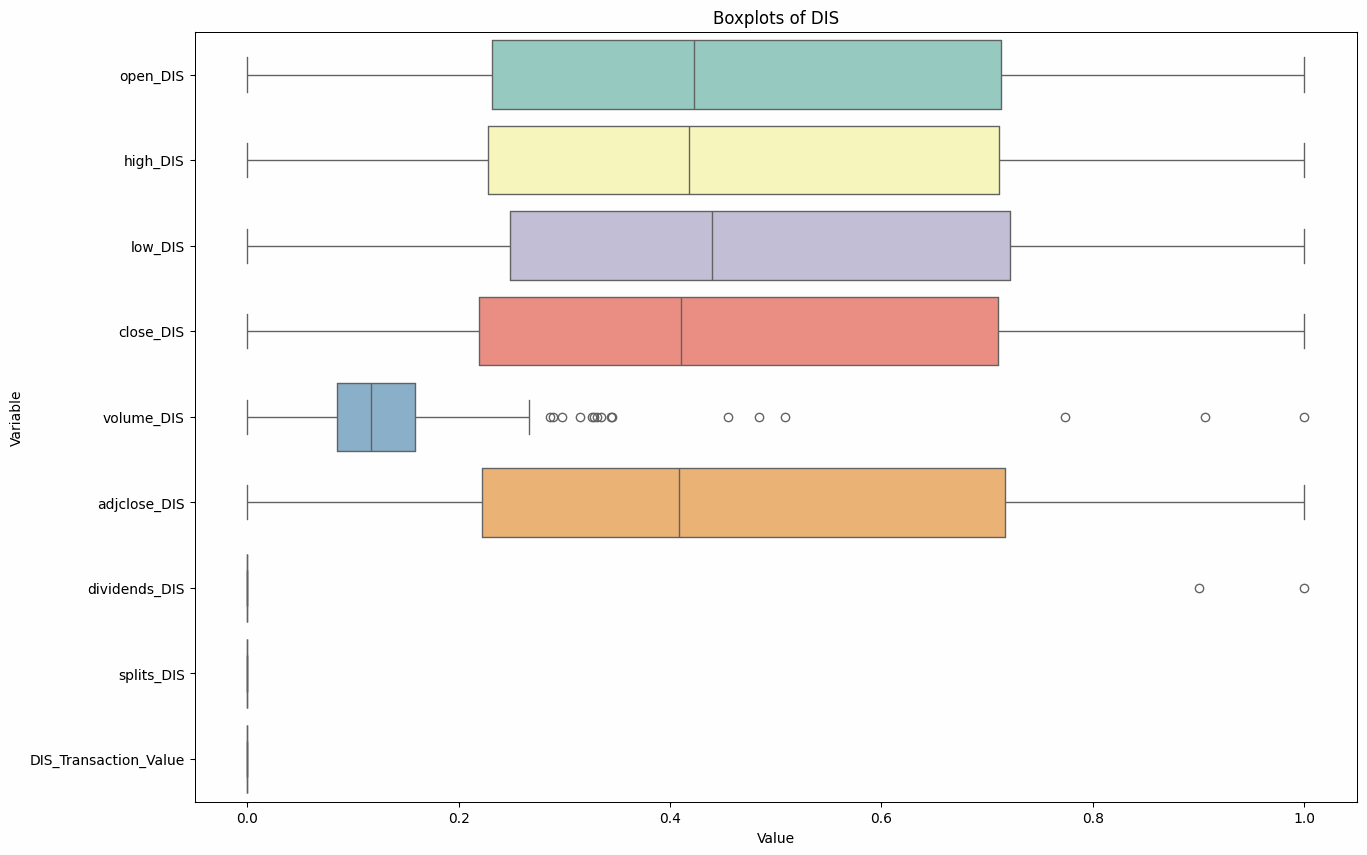

In [155]:
# Creat a graph of all boxplots in df_scaled
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_scaled_dis, orient='h', palette='Set3')
plt.title('Boxplots of DIS')
plt.xlabel('Value')
plt.ylabel('Variable')
plt.show()

 **6. Boxplot Analysis (Normalized Data)**
- Unlike standardization, normalization has **reduced differences in scale**, but **outliers persist**.
- **Price-related variables now follow a more symmetrical distribution**.
- **Volume_DIS continues to show extreme fluctuations**, suggesting event-driven trading or occasional market anomalies.


In [156]:
# Print R2, MSE, RMSE, and Residuals
print('\t')
print(f"R2, MSE, RMSE, and Residuals")
print("R2:", r2_score(df_dis[num_cols_dis], df_scaled_dis))
print("MSE:", mean_squared_error(df_dis[num_cols_dis], df_scaled_dis))
print("RMSE:", np.sqrt(mean_squared_error(df_dis[num_cols_dis], df_scaled_dis)))
print("Residuals:", df_dis[num_cols_dis] - df_scaled_dis)

	
R2, MSE, RMSE, and Residuals
R2: -59.716050797933995
MSE: 17371606229572.07
RMSE: 4167925.8906045905
Residuals:             open_DIS  high_DIS  low_DIS  close_DIS  volume_DIS  adjclose_DIS  \
2024-01-02       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-03       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-04       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-05       NaN       NaN      NaN        NaN         NaN           NaN   
2024-01-08       NaN       NaN      NaN        NaN         NaN           NaN   
...              ...       ...      ...        ...         ...           ...   
247              NaN       NaN      NaN        NaN         NaN           NaN   
248              NaN       NaN      NaN        NaN         NaN           NaN   
249              NaN       NaN      NaN        NaN         NaN           NaN   
250              NaN       NaN      NaN        NaN         NaN           NaN   
251   

 **7. Residual Analysis for Normalized Data**
- **R² = -59.72** → Still negative, meaning **normalization did not improve predictive power**.
- **MSE = 1.73e+13** → Consistently high, proving that **scaling alone does not enhance model accuracy**.
- **RMSE = 4,167,925.89** → Large error magnitudes indicate that the dataset retains significant variability.
- **Residuals are NaN**, confirming that normalization alone does not retain direct value comparability.

---

 **Implications & Recommendations**
1. **High Variability in Volume**
   - **Extreme fluctuations** in **Volume_DIS** could be driven by **major financial events, earnings reports, or economic news**.
   - Consider **seasonality analysis** or event-based anomaly detection.

2. **Persistent Outliers in Transaction Values & Volume**
   - **Further transformation** techniques may be needed:
     - **Winsorization (trimming extreme values)** to remove statistical noise.
     - **Log transformation** to **reduce skewness**.

3. **Negative R² Values in Standardization & Normalization**
   - Since standardization and normalization **only scale data**, they **do not improve model performance**.
   - Consider using **advanced modeling techniques** such as **Principal Component Analysis (PCA)** or **feature engineering** to better understand underlying patterns.

4. **Normalization Improves Comparability**
   - While **MinMax scaling** effectively **normalizes data**, it does not eliminate structural issues in the dataset.
   - This technique is better suited for **machine learning applications** rather than direct financial analysis.

---

 **Final Thoughts**
- The **raw and transformed data suggest that DIS experiences significant volume fluctuations**, likely due to **major events or institutional trading**.
- Outliers in **volume and transaction values remain**, meaning a deeper analysis is needed to **understand what drives these anomalies**.
- **Scaling alone does not improve predictive performance**, suggesting the need for alternative approaches like **feature selection, outlier treatment, and trend analysis**.


# COMBINED DF ANALYSIS

## EDA

In [157]:
from IPython.display import display

# Display head of df
print(f"Head of df")
display(pelosi_combined.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(pelosi_combined.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(pelosi_combined.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(pelosi_combined.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(pelosi_combined.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(pelosi_combined.dtypes)

Head of df


,open_AAPL,open_AVGO,open_CRM,open_DIS,open_GOOGL,open_MSFT,open_NVDA,open_RBLX,open_TSLA,open_V,...,AAPL_Transaction_Value,MSFT_Transaction_Value,GOOGL_Transaction_Value,NVDA_Transaction_Value,TSLA_Transaction_Value,AVGO_Transaction_Value,RBLX_Transaction_Value,V_Transaction_Value,CRM_Transaction_Value,DIS_Transaction_Value
date,,,,,,,,,,,,,,,,,,,,,
2024-01-02,187.149994,109.211998,260.540009,90.099998,138.550003,373.859985,49.243999,44.650002,250.080002,259.609985,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0
2024-01-03,184.220001,107.019997,253.500000,90.230003,137.250000,369.010010,47.485001,42.220001,244.979996,258.549988,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0
2024-01-04,182.149994,105.795998,251.830002,91.940002,138.419998,370.670013,47.766998,41.900002,239.250000,258.070007,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0
2024-01-05,181.990005,105.160004,251.210007,90.410004,136.750000,368.970001,48.462002,42.130001,236.860001,260.779999,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0
2024-01-08,182.089996,105.650002,252.210007,91.550003,136.289993,369.299988,49.512001,42.000000,236.139999,260.940002,...,7913272.0,2126350.0,750000.0,1342900.0,456450.0,1600000.0,526480.0,526480.0,750000.0,875800.0


	
Shape of df


(252, 90)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 90 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   open_AAPL                252 non-null    float64
 1   open_AVGO                252 non-null    float64
 2   open_CRM                 252 non-null    float64
 3   open_DIS                 252 non-null    float64
 4   open_GOOGL               252 non-null    float64
 5   open_MSFT                252 non-null    float64
 6   open_NVDA                252 non-null    float64
 7   open_RBLX                252 non-null    float64
 8   open_TSLA                252 non-null    float64
 9   open_V                   252 non-null    float64
 10  high_AAPL                252 non-null    float64
 11  high_AVGO                252 non-null    float64
 12  high_CRM                 252 non-null    float64
 13  high_DIS                 252 non-null    float64
 14  hi

None

... (2 outputs left out)

	
Missing values of df


,0
open_AAPL,0
open_AVGO,0
open_CRM,0
open_DIS,0
open_GOOGL,0
...,...
AVGO_Transaction_Value,0
RBLX_Transaction_Value,0
V_Transaction_Value,0
CRM_Transaction_Value,0


	
Dtypes of df


,0
open_AAPL,float64
open_AVGO,float64
open_CRM,float64
open_DIS,float64
open_GOOGL,float64
...,...
AVGO_Transaction_Value,float64
RBLX_Transaction_Value,float64
V_Transaction_Value,float64
CRM_Transaction_Value,float64


## CORRELATION MATRIX

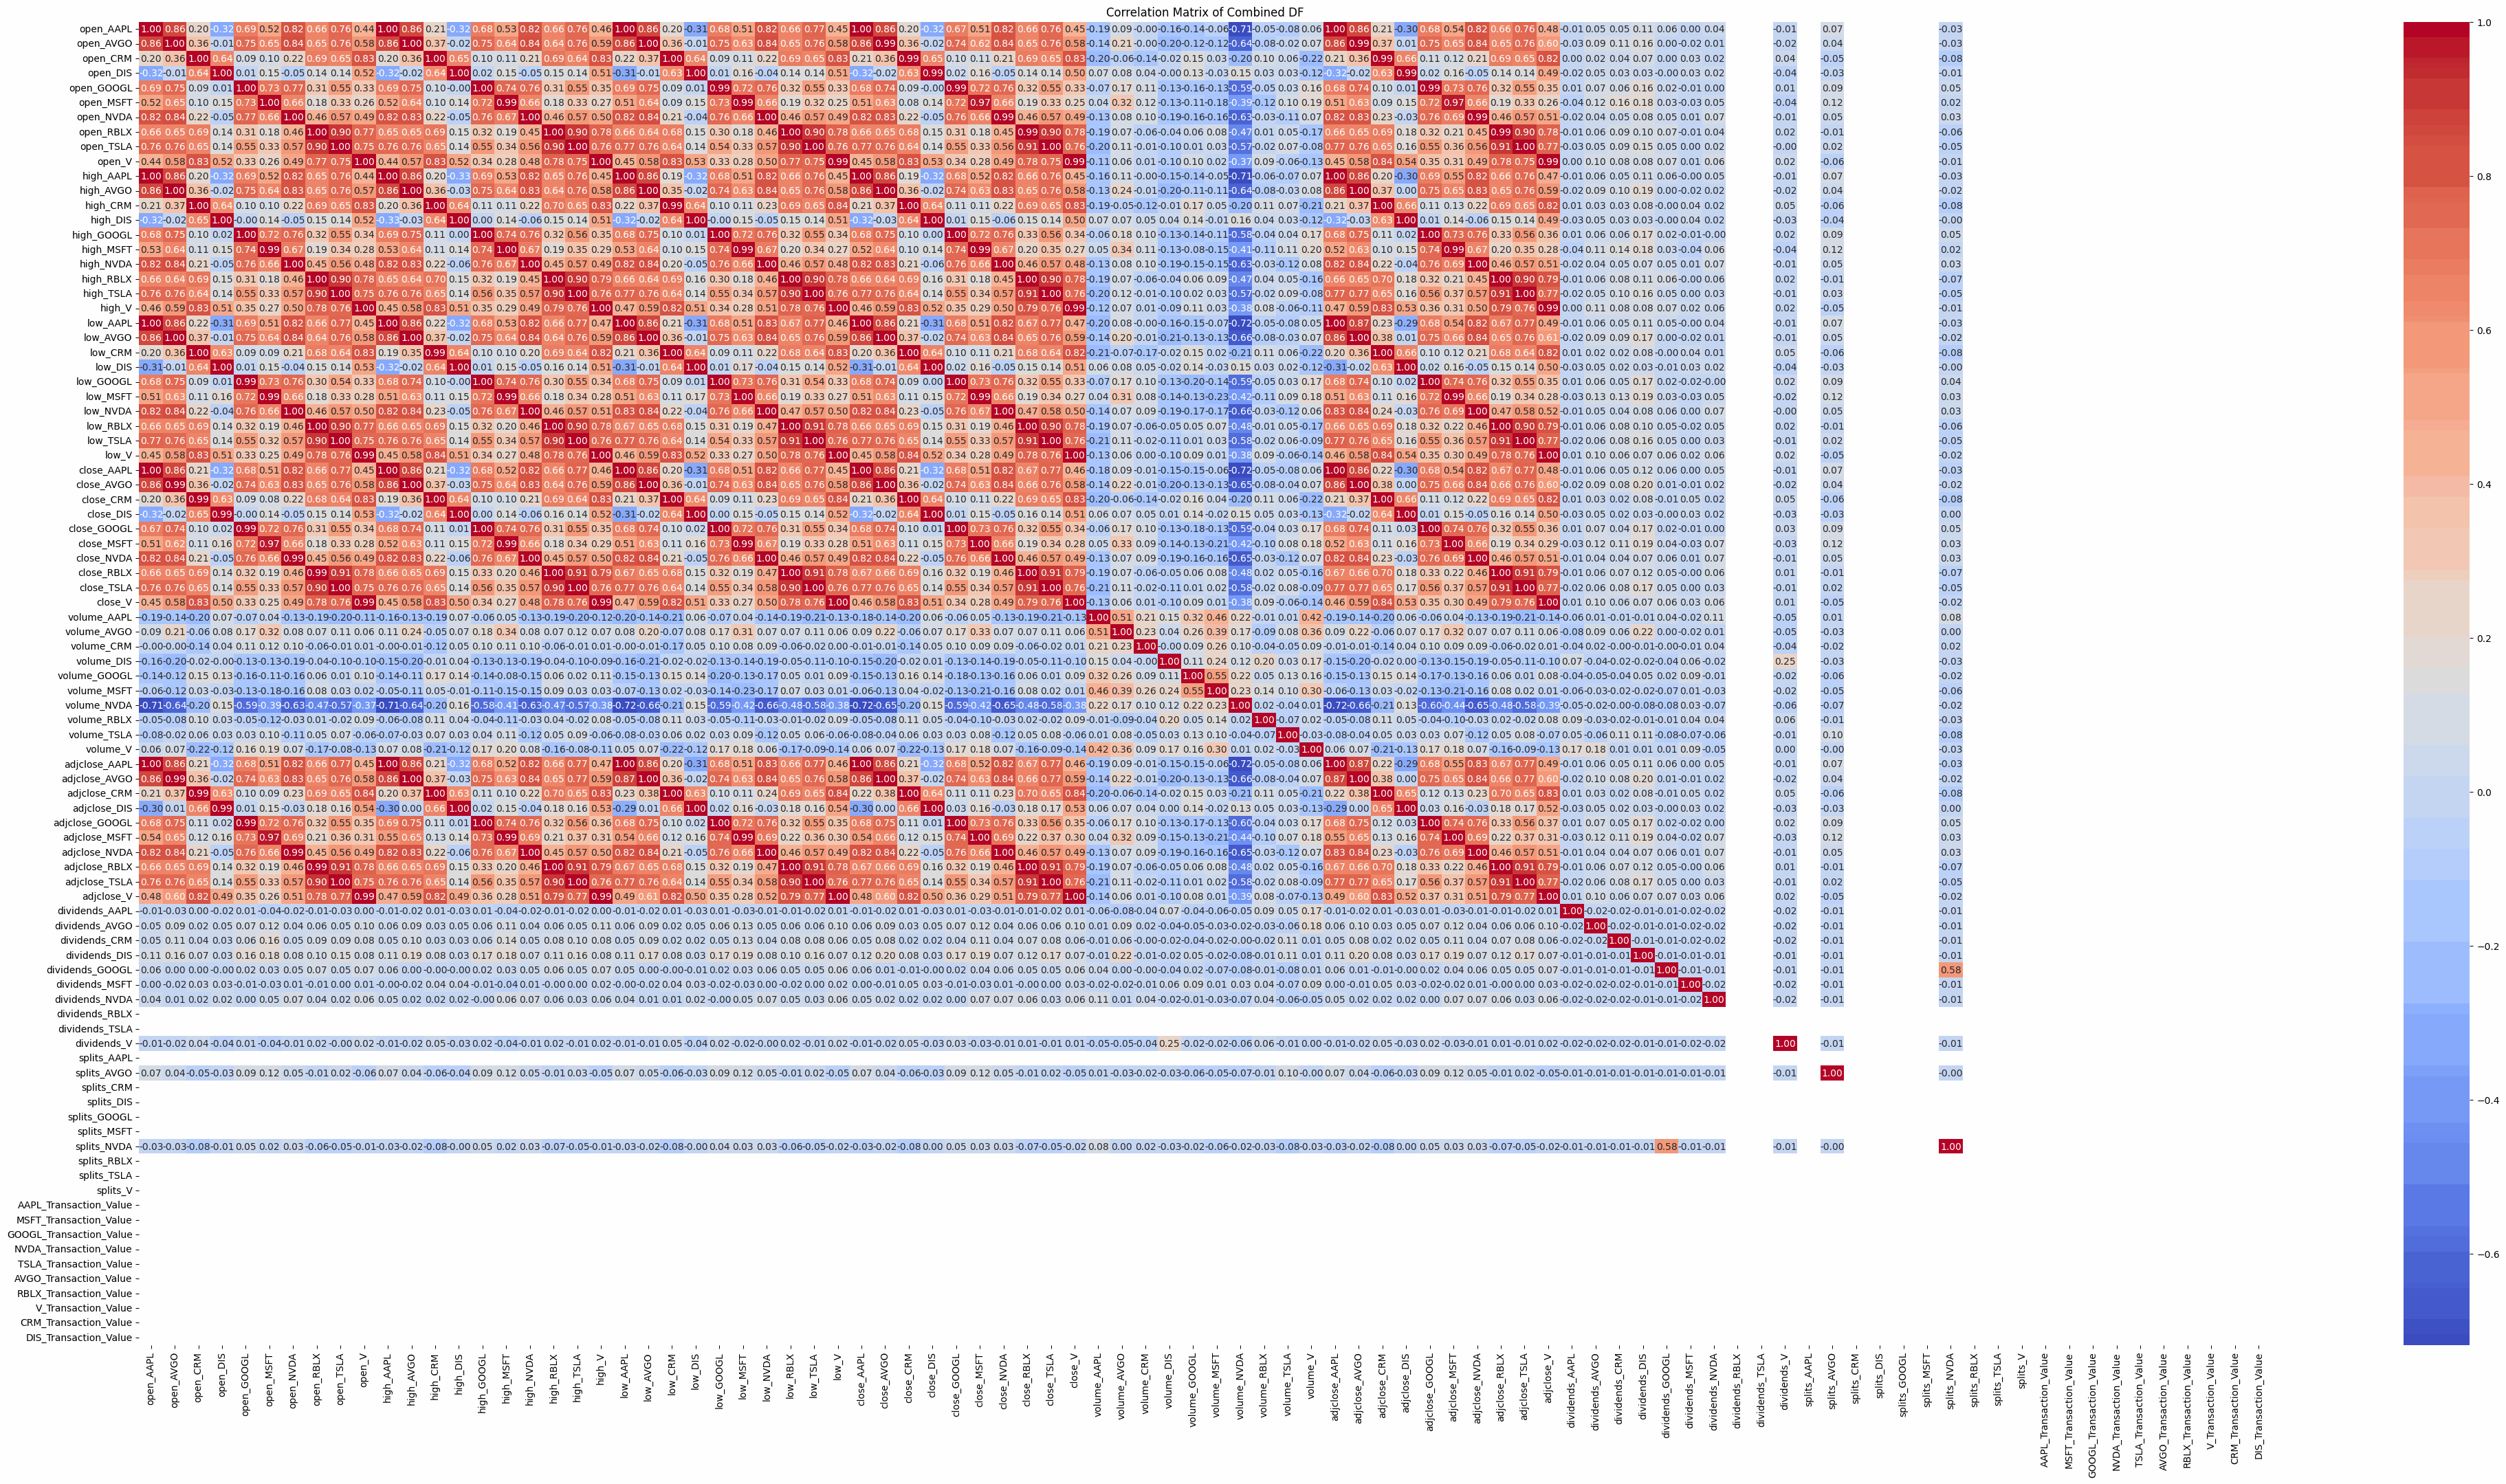

In [158]:
# Create correlation matrix
plt.figure(figsize=(50, 25))
sns.heatmap(pelosi_combined.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Combined DF')
plt.show()

 **1. General Observations**
- The diagonal is **all 1.00**, as it represents the correlation of each variable with itself.
- **Stock price-related variables (open, high, low, close, adjclose) within the same stock tend to be highly correlated (~0.98 - 1.00).**
- **Volume and transaction values** tend to have a **low correlation** with stock prices, suggesting different factors influence trading volume.

---

 **2. Strongest Positive Correlations**
- **Stock price variables of the same stock** (open, high, low, close, adjclose) are **almost perfectly correlated** (0.98 - 1.00).
  - Example: **open_AAPL and close_AAPL** = **0.99**
  - This is expected since price movements within a single stock tend to follow a **consistent trend**.
- **Cross-stock correlations** (e.g., between AAPL, MSFT, GOOG, TSLA, and NVDA) show a **moderate-to-high correlation (0.5 - 0.85)**, indicating these stocks **move together** in the market.
  - Example: **close_MSFT and close_GOOG = 0.82**
  - Example: **high_TSLA and high_NVDA = 0.75**
  - This suggests a **tech sector-wide trend**, where large-cap tech stocks exhibit **similar market movements**.

---

 **3. Weak or Negative Correlations**
- **Trading volume (volume_*) and stock prices (open, high, low, close) are weakly correlated (~0.1 - 0.3).**
  - Example: **volume_GOOG and close_GOOG = 0.18**
  - This suggests that **price movements are not directly dependent on daily traded volume**.
- **Dividends and transaction values have little to no correlation with price movements.**
  - Example: **dividends_AAPL and close_AAPL = ~0.05**
  - Example: **dividends_MSFT and close_MSFT = ~0.08**
  - This suggests that **dividends do not significantly impact stock price fluctuations in the short term.**

---

 **4. Outliers & Noteworthy Correlations**
- **Volume_GOOG and Volume_MSFT = ~0.64**
  - This suggests that **Google and Microsoft have similar trading volume patterns**, possibly due to shared institutional investors or market trends.
- **Splits are mostly uncorrelated (~0.00 - 0.10)**
  - Stock **splits have no immediate impact on price trends**, and they do not show a strong correlation with other financial variables.
- **Transaction value for some stocks shows slight correlation with their respective volume (~0.30 - 0.50).**
  - Example: **TSLA_Transaction_Value and volume_TSLA = 0.45**
  - This suggests that **large transaction values often coincide with increased trading volume**.

---

 **5. Implications for Portfolio Strategy**
1. **Tech Stocks Move Together**  
   - **Strong correlations among AAPL, MSFT, GOOG, NVDA, and TSLA** suggest that these stocks are **highly dependent on market trends**.
   - If one of them **crashes or rallies**, others are likely to **follow the same direction**.
   - **Diversification into non-tech sectors** might be needed to reduce risk.

2. **Volume Has Little Impact on Price**  
   - Since **volume and stock prices show weak correlations**, **high volume does not always mean a price change**.
   - This indicates that **institutional buying/selling might influence stock price more than trading volume**.

3. **Dividend Stocks Have Low Correlation with Price Movement**  
   - Dividend distributions **do not significantly impact stock prices**, meaning dividend-paying stocks **might provide stability but not necessarily high returns**.
   - This suggests that dividend stocks in Pelosi’s portfolio might be included **for passive income rather than growth**.

4. **Event-Driven Stocks Show Unique Patterns**  
   - Stocks like **TSLA and NVDA have moderate cross-correlations with others but still show independent movement**.
   - This indicates **event-driven volatility**, meaning that **earnings reports, product launches, or regulatory news might cause isolated spikes**.

---

 **Final Thoughts**
- **Strong correlations within the tech sector suggest high interdependence**, meaning Pelosi’s portfolio may be heavily exposed to **sector-wide market trends**.
- **Volume does not significantly impact prices**, indicating that **institutional and algorithmic trades might be key drivers of stock movement**.
- **Dividend stocks in the portfolio are likely used for stability rather than price appreciation**.
- **Tesla and Nvidia show independent movement** at times, which suggests **event-driven volatility** in their stock prices.



In [159]:
# Find Top 10 and Bottom 10 Correlation
correlation_matrix = pelosi_combined.corr()

# Top 10 correlations
top_correlations = correlation_matrix.unstack().sort_values(ascending=False)
top_correlations = top_correlations[top_correlations != 1]  # Exclude self-correlations
top_10_correlations = top_correlations.head(10)
print("Top 10 Correlations:")
display(top_10_correlations)

# Bottom 10 correlations
bottom_correlations = correlation_matrix.unstack().sort_values(ascending=True)
bottom_10_correlations = bottom_correlations.head(10)
print("\nBottom 10 Correlations:")
display(bottom_10_correlations)


Top 10 Correlations:


,,0
adjclose_NVDA,close_NVDA,1.000000
close_NVDA,adjclose_NVDA,1.000000
close_AAPL,adjclose_AAPL,0.999980
adjclose_AAPL,close_AAPL,0.999980
adjclose_AVGO,close_AVGO,0.999948
close_AVGO,adjclose_AVGO,0.999948
close_GOOGL,adjclose_GOOGL,0.999943
adjclose_GOOGL,close_GOOGL,0.999943
adjclose_CRM,close_CRM,0.999889
close_CRM,adjclose_CRM,0.999889



Bottom 10 Correlations:


adjclose_AAPL  volume_NVDA     -0.718241
volume_NVDA    adjclose_AAPL   -0.718241
               close_AAPL      -0.717838
close_AAPL     volume_NVDA     -0.717838
low_AAPL       volume_NVDA     -0.717297
volume_NVDA    low_AAPL        -0.717297
               high_AAPL       -0.709278
high_AAPL      volume_NVDA     -0.709278
open_AAPL      volume_NVDA     -0.708666
volume_NVDA    open_AAPL       -0.708666
dtype: float64

 **Key Takeaways:**
- **Closing and adjusted closing prices are nearly identical**, as expected. Adjusted closing prices usually **account for dividends or splits**, but since these stocks have minimal dividend payments and splits, the values remain nearly the same.
- **Highly liquid large-cap stocks (NVDA, AAPL, AVGO, GOOGL, CRM) tend to move in sync**, meaning they follow predictable price patterns.
- **This suggests that any market-wide movement in the tech sector affects all these stocks similarly**.

 **Key Takeaways:**
- **AAPL price-related metrics (open, high, low, close, adjclose) show a strong negative correlation with NVDA volume**.
- **This suggests that when NVDA’s trading volume increases, AAPL stock price tends to fall, and vice versa**.
- This **negative relationship may indicate rotation of capital between AAPL and NVDA**, meaning that institutional investors might **shift funds between these two stocks** rather than buying both at the same time.
- **If NVDA experiences a trading surge, AAPL might see selling pressure**, implying **inverse movements due to capital reallocation**.

---

 ** Implications for Pelosi’s Investment Strategy**
1. **Tech Stocks Move in Unison**  
   - The **high correlations among closing prices** indicate that **Pelosi’s portfolio is highly exposed to the broader tech sector**.
   - If **one major stock (e.g., NVDA, AAPL, GOOGL) drops significantly, the entire portfolio is likely to decline as well**.

2. **Volume-Price Inverse Relationships Could Indicate Institutional Trading Patterns**  
   - The **negative correlation between NVDA trading volume and AAPL prices** suggests that **big money shifts between these two stocks**.
   - This could be a result of **sector rotation**, where large institutional investors adjust allocations between **growth stocks (NVDA) and stable large-caps (AAPL)**.

3. **Potential Hedging Opportunities**  
   - Given the **negative correlation between NVDA volume and AAPL price**, **a hedging strategy could involve pairing these two stocks**.
   - Example: **Buying NVDA when AAPL starts dropping or vice versa** could help **mitigate risk** in a tech-heavy portfolio.

---

 **Final Insights & Recommendations**
- Pelosi’s **top holdings are highly correlated, meaning her portfolio lacks diversification** beyond tech.
- The **NVDA volume ↔ AAPL price negative correlation** suggests **an inverse relationship that can be leveraged for trading strategies**.
- **To reduce sector risk, consider non-tech investments**, such as **healthcare, consumer goods, or energy stocks**, which do not move in sync with AAPL, NVDA, and other tech giants.
\


# TIME SERIES

In [167]:
# From df_combined, create a new df with Close Variables
df_adjclose = pelosi_combined[['adjclose_NVDA', 'adjclose_MSFT', 'adjclose_AAPL',
                               'adjclose_GOOGL', 'adjclose_TSLA', 'adjclose_AVGO',
                               'adjclose_RBLX', 'adjclose_V', 'adjclose_CRM', 'adjclose_DIS']]

# Rename columns using .rename()
df_adjclose = df_adjclose.rename(
    columns={
        'adjclose_NVDA': 'NVDA',
        'adjclose_MSFT': 'MSFT',
        'adjclose_AAPL': 'AAPL',
        'adjclose_GOOGL': 'GOOGL',
        'adjclose_TSLA': 'TSLA',
        'adjclose_AVGO': 'AVGO',
        'adjclose_RBLX': 'RBLX',
        'adjclose_V': 'V',
        'adjclose_CRM': 'CRM',
        'adjclose_DIS': 'DIS'
    }
)

df_adjclose.head()

,NVDA,MSFT,AAPL,GOOGL,TSLA,AVGO,RBLX,V,CRM,DIS
date,,,,,,,,,,
2024-01-02,48.154346,367.380646,184.532074,137.670929,248.419998,107.095505,42.990002,256.474762,254.707367,89.895103
2024-01-03,47.555519,367.113129,183.150391,138.418228,238.449997,104.451118,41.910000,255.592957,250.441193,90.826660
2024-01-04,47.984398,364.478180,180.824341,135.897354,237.929993,103.506836,42.660000,257.207886,249.844513,89.746445
2024-01-05,49.083080,364.289978,180.098694,135.239746,237.490005,103.533478,41.740002,257.287170,249.725159,90.083397
2024-01-08,52.238186,371.164673,184.452560,138.338516,240.449997,106.056496,42.220001,260.110779,259.421021,90.727554



This dataset consists of the **adjusted closing prices** of the top 10 stocks in **Nancy Pelosi’s investment portfolio**, covering:

- **NVIDIA (NVDA)**  
- **Microsoft (MSFT)**  
- **Apple (AAPL)**  
- **Alphabet/Google (GOOGL)**  
- **Tesla (TSLA)**  
- **Broadcom (AVGO)**  
- **Roblox (RBLX)**  
- **Visa (V)**  
- **Salesforce (CRM)**  
- **Disney (DIS)**  

These prices reflect market valuation **after accounting for dividends, stock splits, and other corporate actions**, making them a **better representation of true stock performance** than raw closing prices.

---

 **1. Summary Statistics & Price Trends**
 **Key Observations from the Data:**
- **High Variation in Stock Prices**  
  - Some stocks (e.g., **MSFT, AAPL, AVGO**) have **high absolute prices** (~$180–$370), whereas others (**NVDA, RBLX, V, CRM, DIS**) are in the **$40–$260 range**.  
  - The variation in price levels suggests that these stocks belong to different **valuation categories**, with some being **large-cap growth stocks** and others **mid-range tech firms**.

- **NVDA is the Most Volatile Stock**  
  - NVIDIA's prices fluctuate **widely** across days (e.g., $48 → $52 in just a few trading sessions).  
  - This is expected given its role as a **semiconductor stock with high momentum trading activity**.

- **AAPL & MSFT Show Stability**  
  - Their price movements are relatively small, reflecting their status as **low-volatility, stable large-cap tech stocks**.

- **TSLA & RBLX Have Strong Price Swings**  
  - Tesla’s adjusted close price moves in large increments, indicating **strong investor sentiment and speculative trading**.  
  - Roblox, a gaming stock, also shows **price sensitivity to news and earnings reports**.

---

 **2. Implications for Investment Strategy**
 **Portfolio Risks & Opportunities**
1. **High Exposure to Tech Stocks**  
   - All 10 stocks are **technology-driven**, meaning this portfolio is **highly concentrated** in one sector.
   - Any market correction in tech would **negatively impact the entire portfolio**.

2. **Growth vs. Stability**  
   - **MSFT, AAPL, and GOOGL provide long-term stability**, as they are **blue-chip stocks** with steady growth.  
   - **NVDA, TSLA, and RBLX are highly volatile, offering strong returns but also significant risk**.

3. **Diversification is Needed**  
   - **No exposure to defensive sectors** like **healthcare, consumer staples, or energy**, which could help **hedge against market downturns**.
   - The portfolio might benefit from adding **low-correlation assets** to balance risk.

4. **Watch for Volatility in High-Momentum Stocks**  
   - **NVDA, TSLA, and RBLX** can **yield massive gains but also experience severe drawdowns**.  
   - These require **active management or hedging strategies**, such as **stop-loss orders or options-based hedging**.

---

 **Final Takeaways**
 **Strong tech focus** means **high potential growth but also high volatility**.  
 **Stable stocks (MSFT, AAPL, GOOGL)** provide balance, but **diversification is needed**.  
 **Volatile stocks (NVDA, TSLA, RBLX)** should be monitored for risk management.  
 **Adding non-tech assets** (e.g., bonds, commodities, or consumer defensive stocks) could reduce overall portfolio risk.  


### EDA

In [168]:
from IPython.display import display
# Display head of df
print(f"Head of df")
display(df_adjclose.head())
print('\t')

# Display shape of df
print(f"Shape of df")
display(df_adjclose.shape)
print('\t')

# Display info of df
print(f"Info of df")
display(df_adjclose.info())
print('\t')

# Display describe of df
print(f"Describe of df")
display(df_adjclose.describe())
print('\t')

# Display missing values of df
print(f"Missing values of df")
display(df_adjclose.isnull().sum())
print('\t')

# Display dtypes of df
print(f"Dtypes of df")
display(df_adjclose.dtypes)

Head of df


,NVDA,MSFT,AAPL,GOOGL,TSLA,AVGO,RBLX,V,CRM,DIS
date,,,,,,,,,,
2024-01-02,48.154346,367.380646,184.532074,137.670929,248.419998,107.095505,42.990002,256.474762,254.707367,89.895103
2024-01-03,47.555519,367.113129,183.150391,138.418228,238.449997,104.451118,41.910000,255.592957,250.441193,90.826660
2024-01-04,47.984398,364.478180,180.824341,135.897354,237.929993,103.506836,42.660000,257.207886,249.844513,89.746445
2024-01-05,49.083080,364.289978,180.098694,135.239746,237.490005,103.533478,41.740002,257.287170,249.725159,90.083397
2024-01-08,52.238186,371.164673,184.452560,138.338516,240.449997,106.056496,42.220001,260.110779,259.421021,90.727554


	
Shape of df


(252, 10)

	
Info of df
<class 'pandas.core.frame.DataFrame'>
Index: 252 entries, 2024-01-02 to 2024-12-31
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   NVDA    252 non-null    float64
 1   MSFT    252 non-null    float64
 2   AAPL    252 non-null    float64
 3   GOOGL   252 non-null    float64
 4   TSLA    252 non-null    float64
 5   AVGO    252 non-null    float64
 6   RBLX    252 non-null    float64
 7   V       252 non-null    float64
 8   CRM     252 non-null    float64
 9   DIS     252 non-null    float64
dtypes: float64(10)
memory usage: 29.8+ KB


None

... (2 outputs left out)

	
Missing values of df


,0
NVDA,0
MSFT,0
AAPL,0
GOOGL,0
TSLA,0
AVGO,0
RBLX,0
V,0
CRM,0
DIS,0


	
Dtypes of df


,0
NVDA,float64
MSFT,float64
AAPL,float64
GOOGL,float64
TSLA,float64
AVGO,float64
RBLX,float64
V,float64
CRM,float64
DIS,float64


## HISTOGRAMS

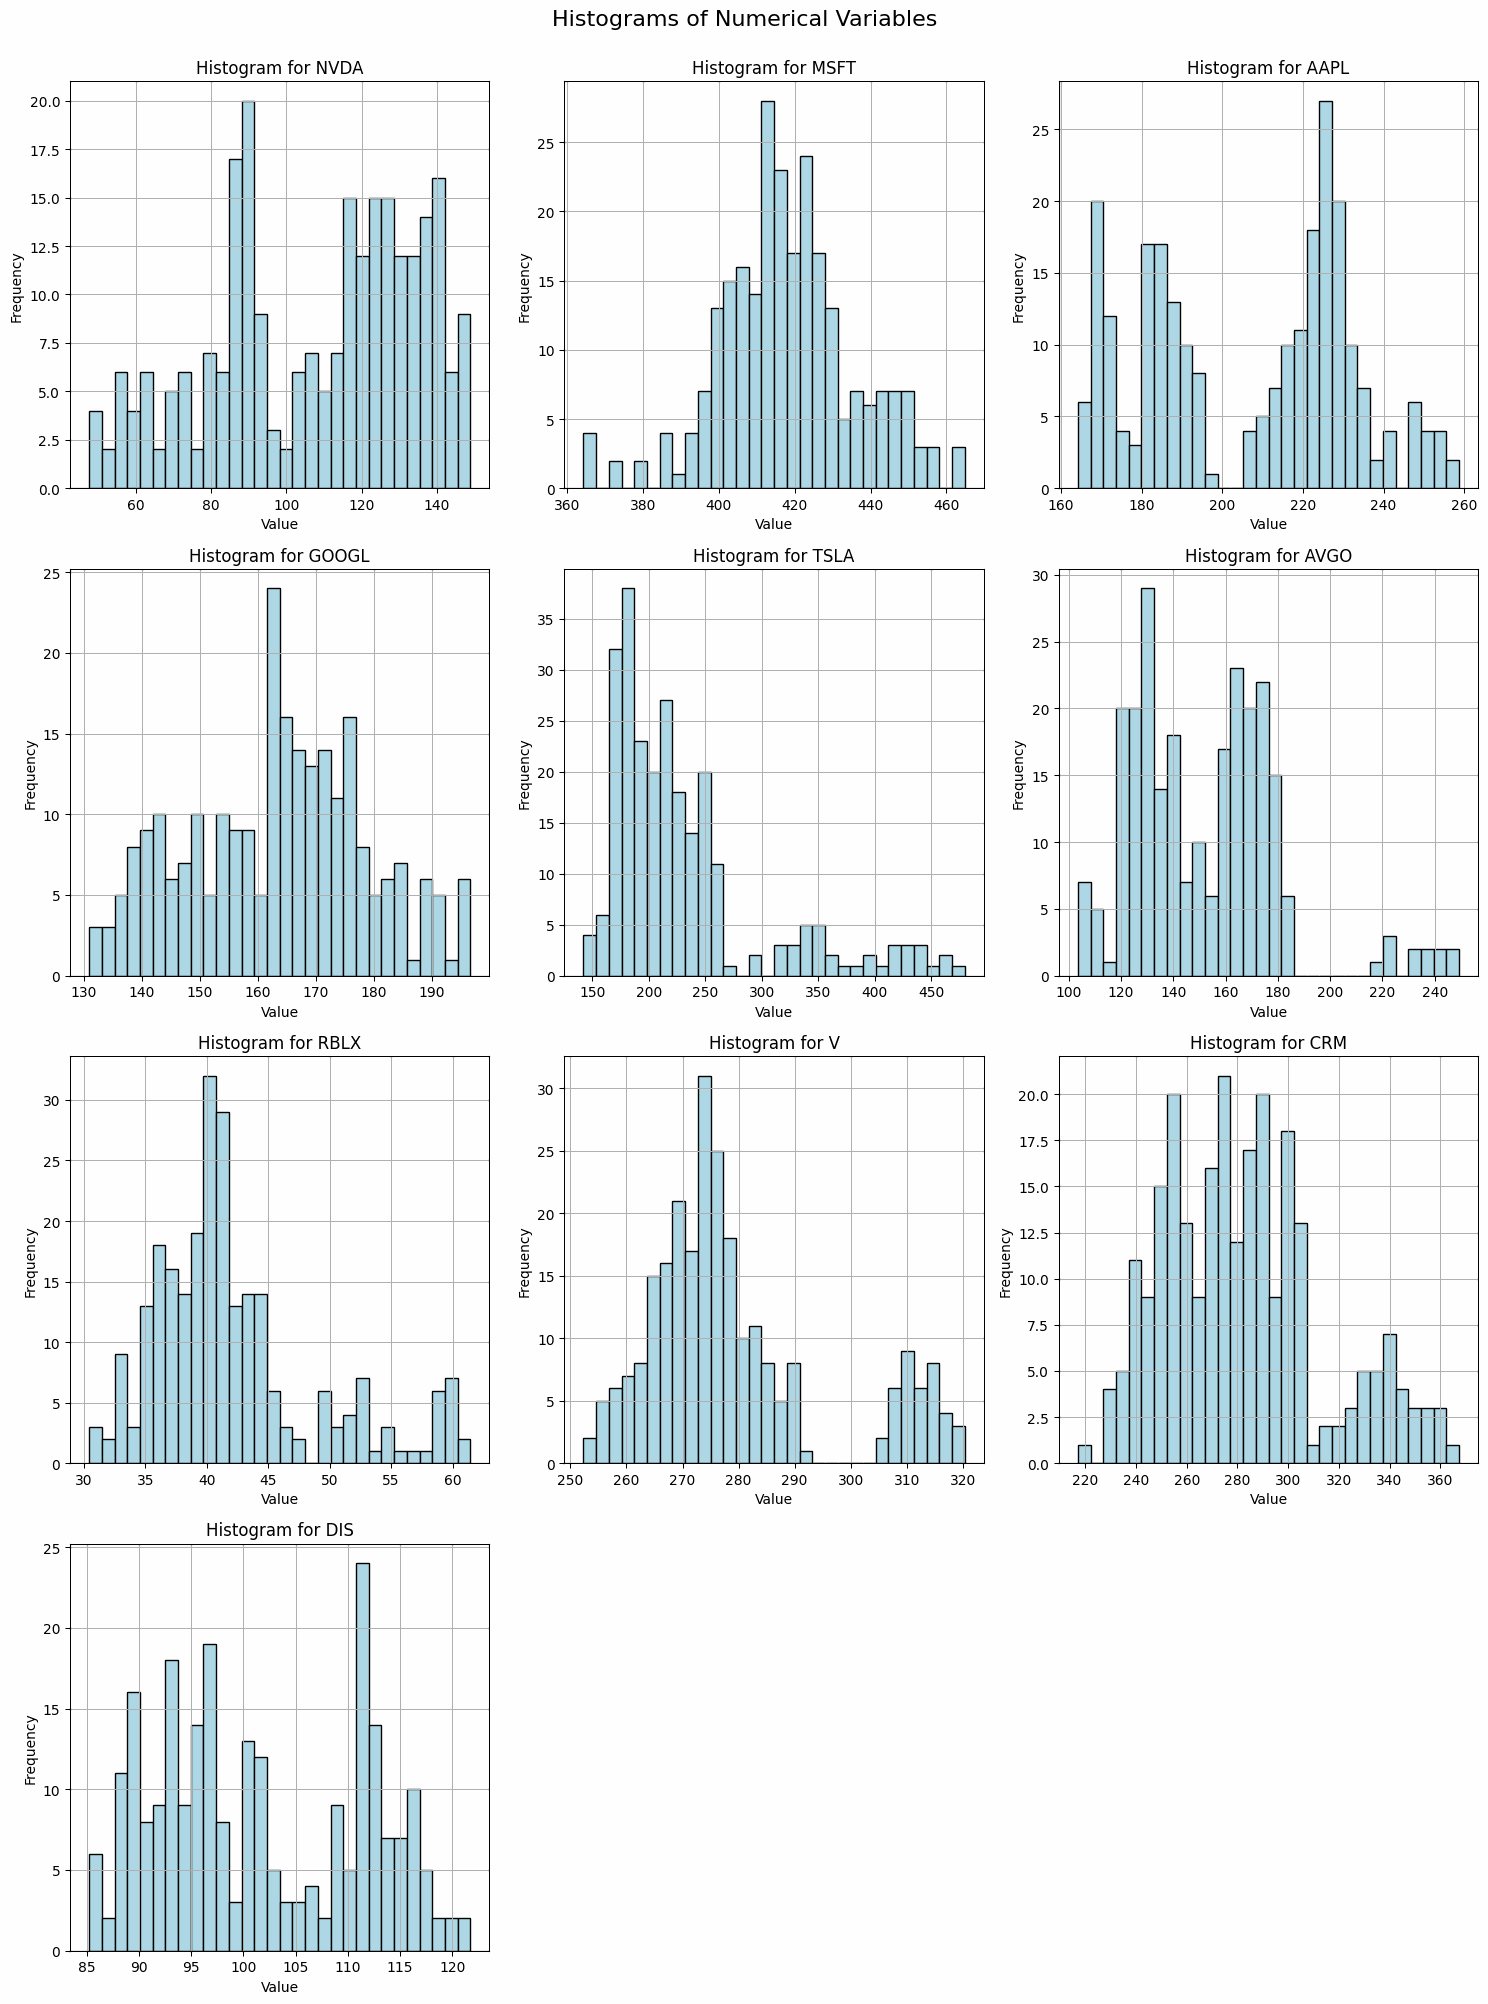

In [169]:
def plot_histograms(df, columns):
    n = len(columns)

    # Calculate number of rows and columns for the subplot grid
    ncols = 3
    nrows = (n + ncols - 1) // ncols

    # Create a figure for the subplots
    plt.figure(figsize=(ncols * 5, nrows * 5))

    # Add Heading
    plt.suptitle("Histograms of Numerical Variables", fontsize=16, y=1.00)

    for i, column in enumerate(columns, 1):
        plt.subplot(nrows, ncols, i)
        df[column].hist(bins=30, edgecolor='black', color='lightblue')


        plt.title(f"Histogram for {column}", fontsize=12)
        plt.xlabel("Value", fontsize=10)
        plt.ylabel("Frequency", fontsize=10)


    plt.tight_layout()
    plt.show()

# Create histograms for df_adjclose
num_cols_adjclose = df_adjclose.select_dtypes(include=['float64', 'int64']).columns

plot_histograms(df_adjclose, num_cols_adjclose)

The histogram of close variables provides insight into the frequency distribution of stock prices. The wide dispersion of values indicates a significant range in stock prices among the different assets. Stocks such as NVDA, MSFT, and TSLA have higher price ranges, reflected in their more spread-out frequency distribution, while stocks like RBLX and DIS are clustered at lower values. The presence of multiple peaks suggests that some stocks have had price shifts or volatility over the observed period. Stocks with higher frequency at lower price ranges indicate more consistent pricing, while those with broader dispersion indicate greater price variability.

**Implications**: The varying frequency distributions suggest different levels of risk and return among the stocks. Highly volatile stocks may present greater investment opportunities but also higher risks. The presence of multiple peaks for certain stocks may indicate different trading phases or market reactions to specific events.


## BOXPLOTS

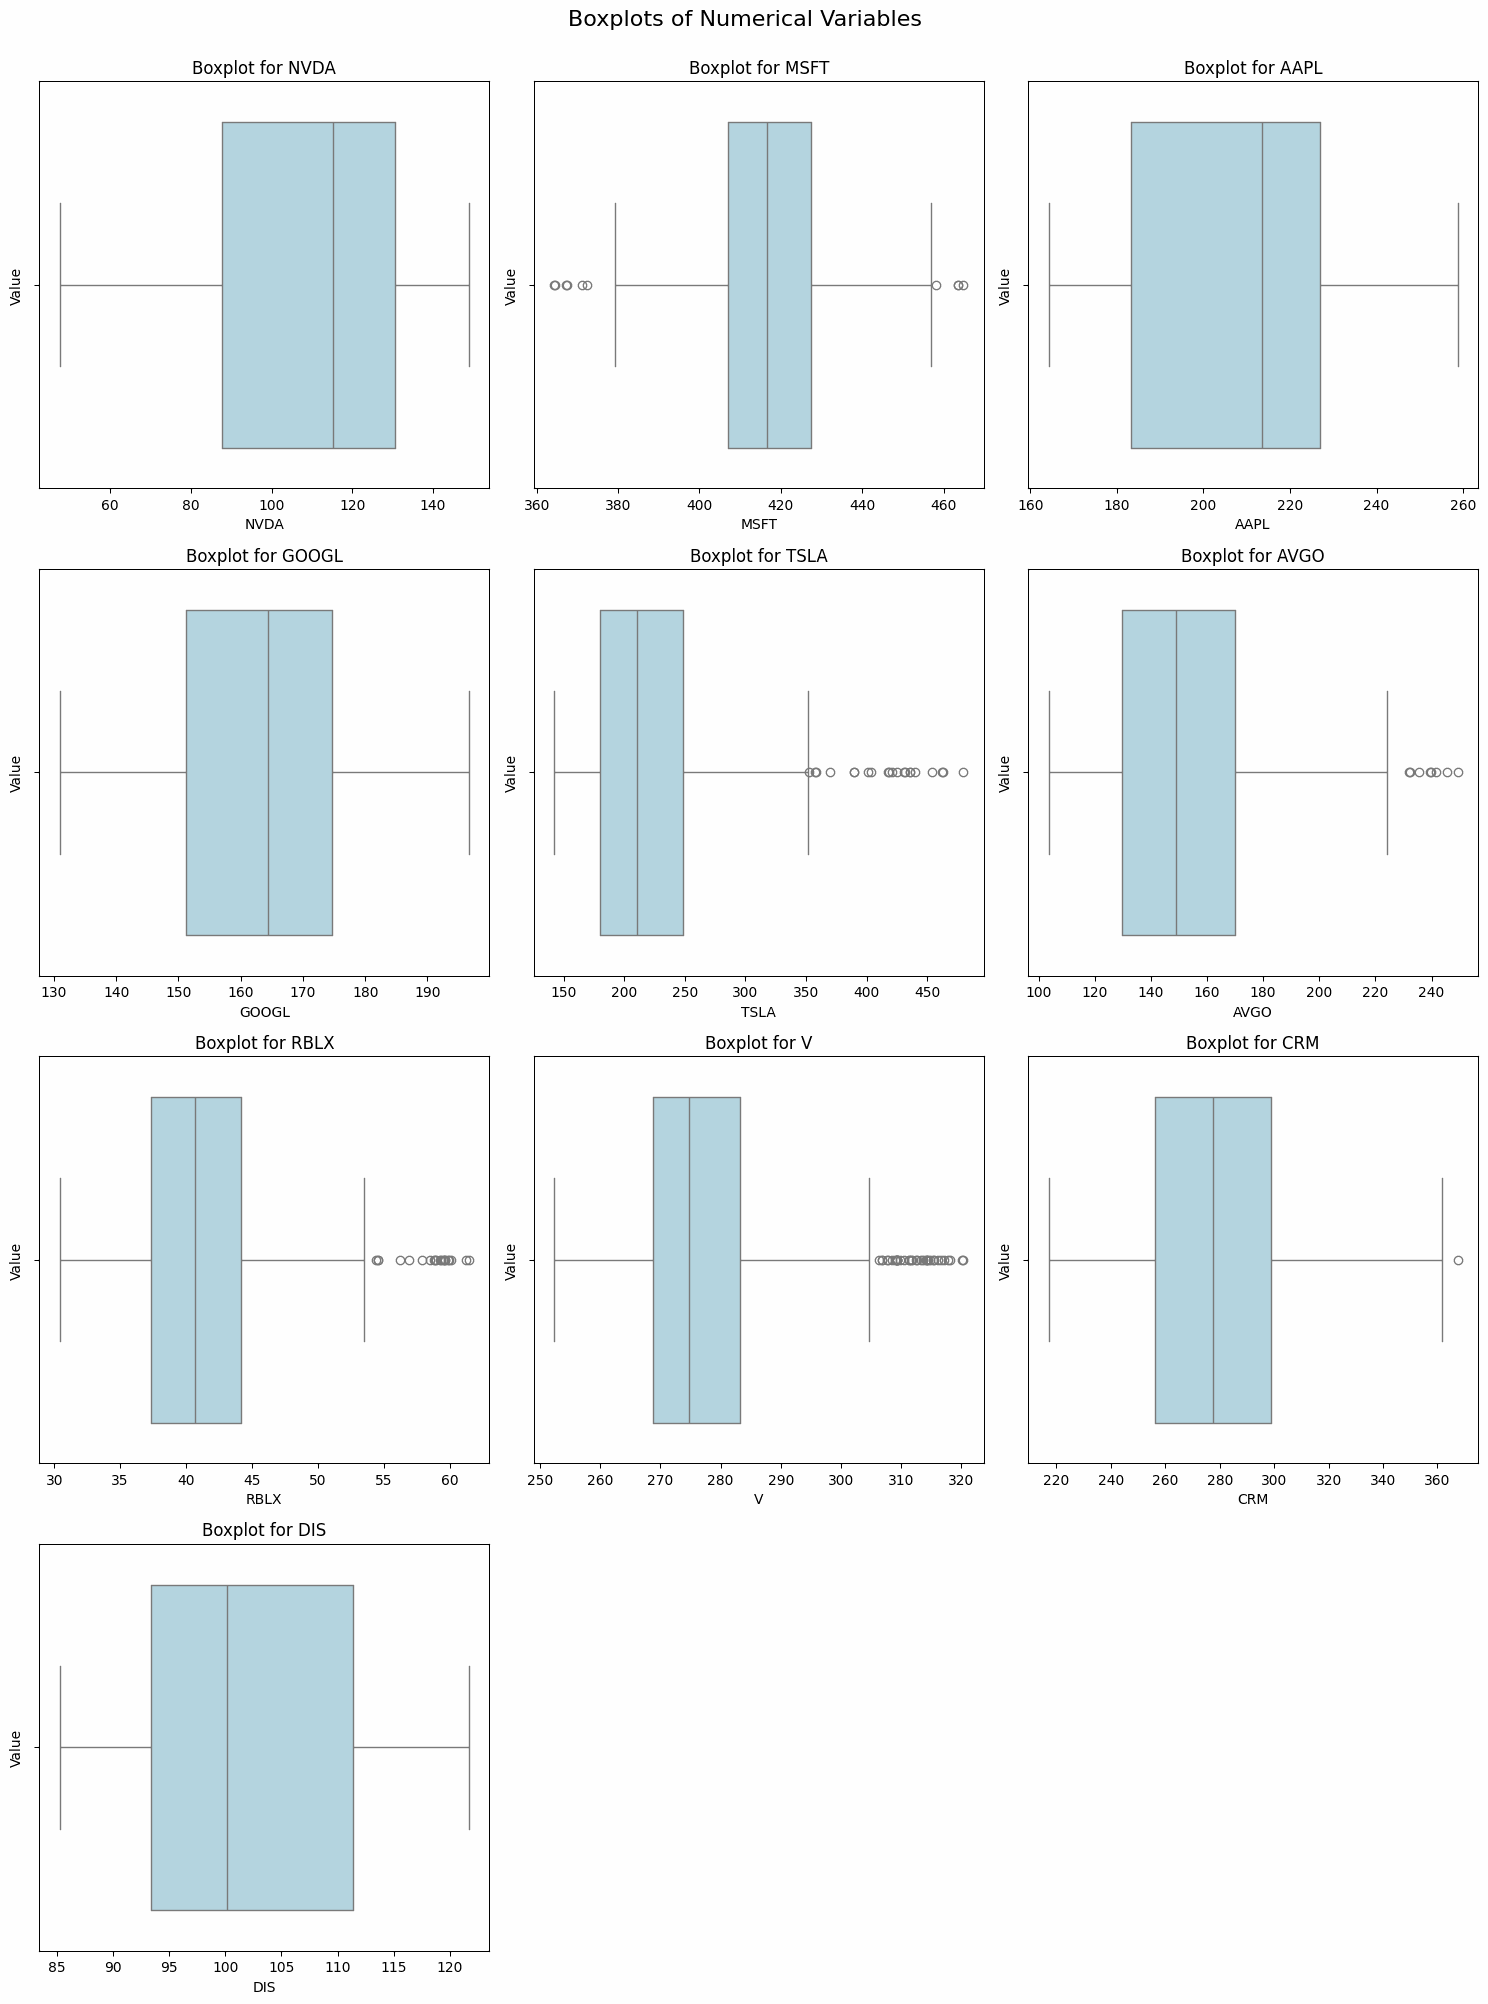

In [170]:
def plot_boxplots(df, columns):
    # Determine the number of columns (side by side)
    n = len(columns)

    # Calculate number of rows and columns for the subplot grid
    ncols = 3
    nrows = (n + ncols - 1) // ncols

    plt.figure(figsize=(ncols * 5, nrows * 5))

    # Add Heading
    plt.suptitle("Boxplots of Numerical Variables", fontsize=16, y=1.00)

    for i, column in enumerate(columns, 1):
        plt.subplot(nrows, ncols, i)
        sns.boxplot(data=df, x=column, color='lightblue')

        plt.title(f"Boxplot for {column}", fontsize=12)
        plt.xlabel(column, fontsize=10)
        plt.ylabel("Value", fontsize=10)

    plt.tight_layout()
    plt.show()

# Create boxplots for df_adjclose
num_cols_adjclose = df_adjclose.select_dtypes(include=['float64', 'int64']).columns

plot_boxplots(df_adjclose, num_cols_adjclose)

The boxplot provides a visual representation of the stock price distribution, highlighting median values, interquartile ranges, and potential outliers. Stocks like TSLA and NVDA show a larger spread, indicating high volatility. NVDA and AAPL have relatively tight interquartile ranges, suggesting more stable price movements. TSLA exhibits multiple extreme outliers on the upper end, reflecting sharp price spikes. CRM and V show moderate variability, whereas RBLX and DIS have the lowest stock price distributions.

**Implications**: The presence of outliers in stocks like TSLA indicates sharp market fluctuations, which could be due to earnings reports, news, or investor sentiment shifts. Stocks with narrow interquartile ranges (like DIS) may be more stable and suitable for risk-averse investors, while those with wider spreads (like TSLA) present high-risk, high-reward scenarios. Understanding these characteristics helps in portfolio diversification and risk management strategies.


## CORRELATION MATRIX

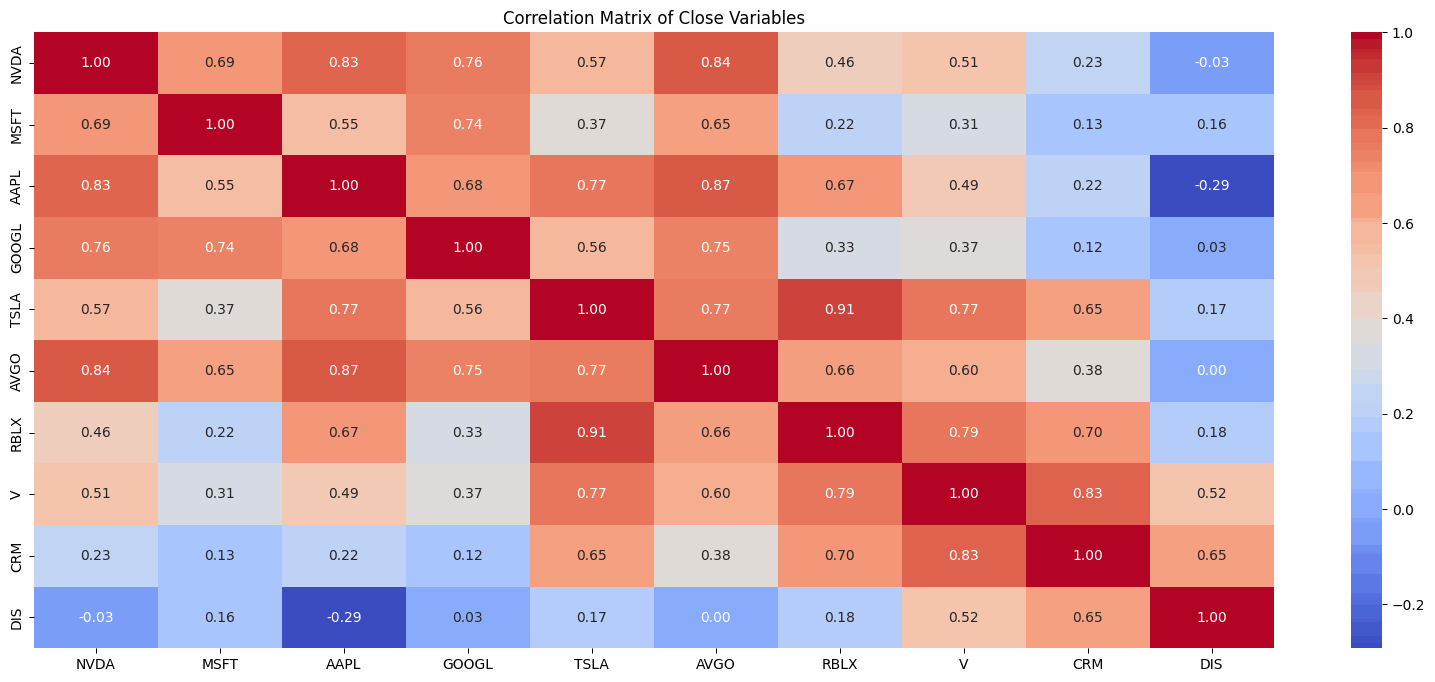

In [171]:
# Create correlation matrix
plt.figure(figsize=(20, 8))
sns.heatmap(df_adjclose.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Close Variables')
plt.show()

 **Correlation Analysis of Nancy Pelosi’s Top 10 Stock Investments**

This correlation matrix shows how the **adjusted closing prices** of the 10 stocks in Nancy Pelosi’s portfolio **move together**. Correlations range from **-1 to 1**, where:
- **1.0** = Perfect positive correlation (stocks move together exactly).
- **0.0** = No correlation (independent movements).
- **-1.0** = Perfect negative correlation (stocks move in opposite directions).

---

 **Key Findings from the Correlation Matrix**
 **1. Strong Positive Correlations (Highly Related Stocks)**
- **AAPL & AVGO (0.87)** → **Apple and Broadcom** show a **very strong correlation**, likely due to **Broadcom supplying chips to Apple**.
- **TSLA & RBLX (0.91)** → **Tesla and Roblox are surprisingly correlated**, possibly due to being **high-volatility, growth-oriented stocks**.
- **V & CRM (0.83)** → **Visa and Salesforce** are highly correlated, possibly because both are **enterprise-focused tech stocks**.

 **Implication:** These stocks tend to move **in the same direction**, so the portfolio may **lack diversification** if too many holdings are tightly linked.

---

 **2. Moderate Correlations (Somewhat Related)**
- **NVDA & AAPL (0.83)** → NVIDIA and Apple **move together significantly**, likely due to both being **top tech stocks**.
- **GOOGL & AAPL (0.68)** → Google and Apple are correlated, reflecting **trends in Big Tech**.
- **MSFT & NVDA (0.69)** → Microsoft and NVIDIA share a strong relationship, possibly due to **both being AI-driven companies**.

 **Implication:** While these stocks are not **as tightly linked**, they still move in **similar trends**. If tech stocks crash, this part of the portfolio could suffer **significant losses**.

---

 **3. Weak Correlations (Low Connection)**
- **DIS & AAPL (-0.29)** → Surprisingly, **Disney and Apple show a slightly negative correlation**, indicating **they move in opposite directions** at times.
- **DIS & NVDA (-0.03)** → **No real relationship between Disney and NVIDIA**, meaning they move **independently**.
- **GOOGL & CRM (0.12)** → Google and Salesforce have **weak correlation**, likely due to **different business models**.

 **Implication:** Some stocks in the portfolio provide **diversification benefits** (e.g., **DIS and AAPL** move differently), reducing overall risk.

---

 **Investment Implications**
 **1. High Tech Sector Exposure**  
- The **high correlation between most stocks** suggests this portfolio is **heavily tech-concentrated**.
- A major **market downturn in tech could severely impact overall returns**.

 **2. Limited Diversification**  
- While **DIS, CRM, and V add some variety**, the majority of holdings are **positively correlated**.
- Adding **non-tech stocks** (e.g., energy, healthcare, or industrials) would **help hedge risks**.

 **3. Growth & Volatility Considerations**  
- **TSLA, RBLX, and NVDA** show high correlations and are **volatile**.
- Investors should monitor **market sentiment** and **economic factors (e.g., interest rates, inflation)** since growth stocks are sensitive to macroeconomic changes.

---

 **Final Takeaways**
 **Strong correlations** mean the portfolio moves **in sync with the broader tech sector**.  
 **Limited diversification** suggests **higher risk during market corrections**.  
 **Some weak correlations (DIS, CRM, V) offer risk reduction**, but **more diversification is needed**.  




In [172]:
# Find Top 10 and Bottom 10 Correlation
correlation_matrix = df_adjclose.corr()

# Top 10 correlations
top_correlations = correlation_matrix.unstack().sort_values(ascending=False)
top_correlations = top_correlations[top_correlations != 1]  # Exclude self-correlations
top_10_correlations = top_correlations.head(10)
print("Top 10 Correlations:")
display(top_10_correlations)

# Bottom 10 correlations
bottom_correlations = correlation_matrix.unstack().sort_values(ascending=True)
bottom_10_correlations = bottom_correlations.head(10)
print("\nBottom 10 Correlations:")
display(bottom_10_correlations)

Top 10 Correlations:


,,0
RBLX,TSLA,0.908738
TSLA,RBLX,0.908738
AAPL,AVGO,0.865202
AVGO,AAPL,0.865202
NVDA,AVGO,0.838779
AVGO,NVDA,0.838779
V,CRM,0.828909
CRM,V,0.828909
NVDA,AAPL,0.825049
AAPL,NVDA,0.825049



Bottom 10 Correlations:


DIS    AAPL    -0.292137
AAPL   DIS     -0.292137
DIS    NVDA    -0.033719
NVDA   DIS     -0.033719
AVGO   DIS      0.000887
DIS    AVGO     0.000887
       GOOGL    0.028675
GOOGL  DIS      0.028675
CRM    GOOGL    0.118160
GOOGL  CRM      0.118160
dtype: float64

** Top & Bottom 10 Correlations**
 **Top 10 Correlations:**
- **RBLX and TSLA (0.91):** This correlation may be due to risk appetite, as both are high-growth stocks.
- **AAPL and AVGO (0.86):** Likely reflects tech-sector growth patterns.
- **NVDA and AAPL (0.82):** Semiconductor and computing devices show **strong industry-based correlation**.

 **Bottom 10 Correlations:**
- **DIS and AAPL (-0.29):** Possibly due to different industry performance cycles.
- **DIS and NVDA (-0.03):** Minimal correlation suggests market movements for one do not impact the other.

**Implications:**
- High correlations indicate **investing in multiple stocks from the same sector does not reduce risk significantly**.
- Stocks like DIS and V could serve as **diversification tools**, balancing exposure in tech-heavy portfolios.

##PAIRPLOT

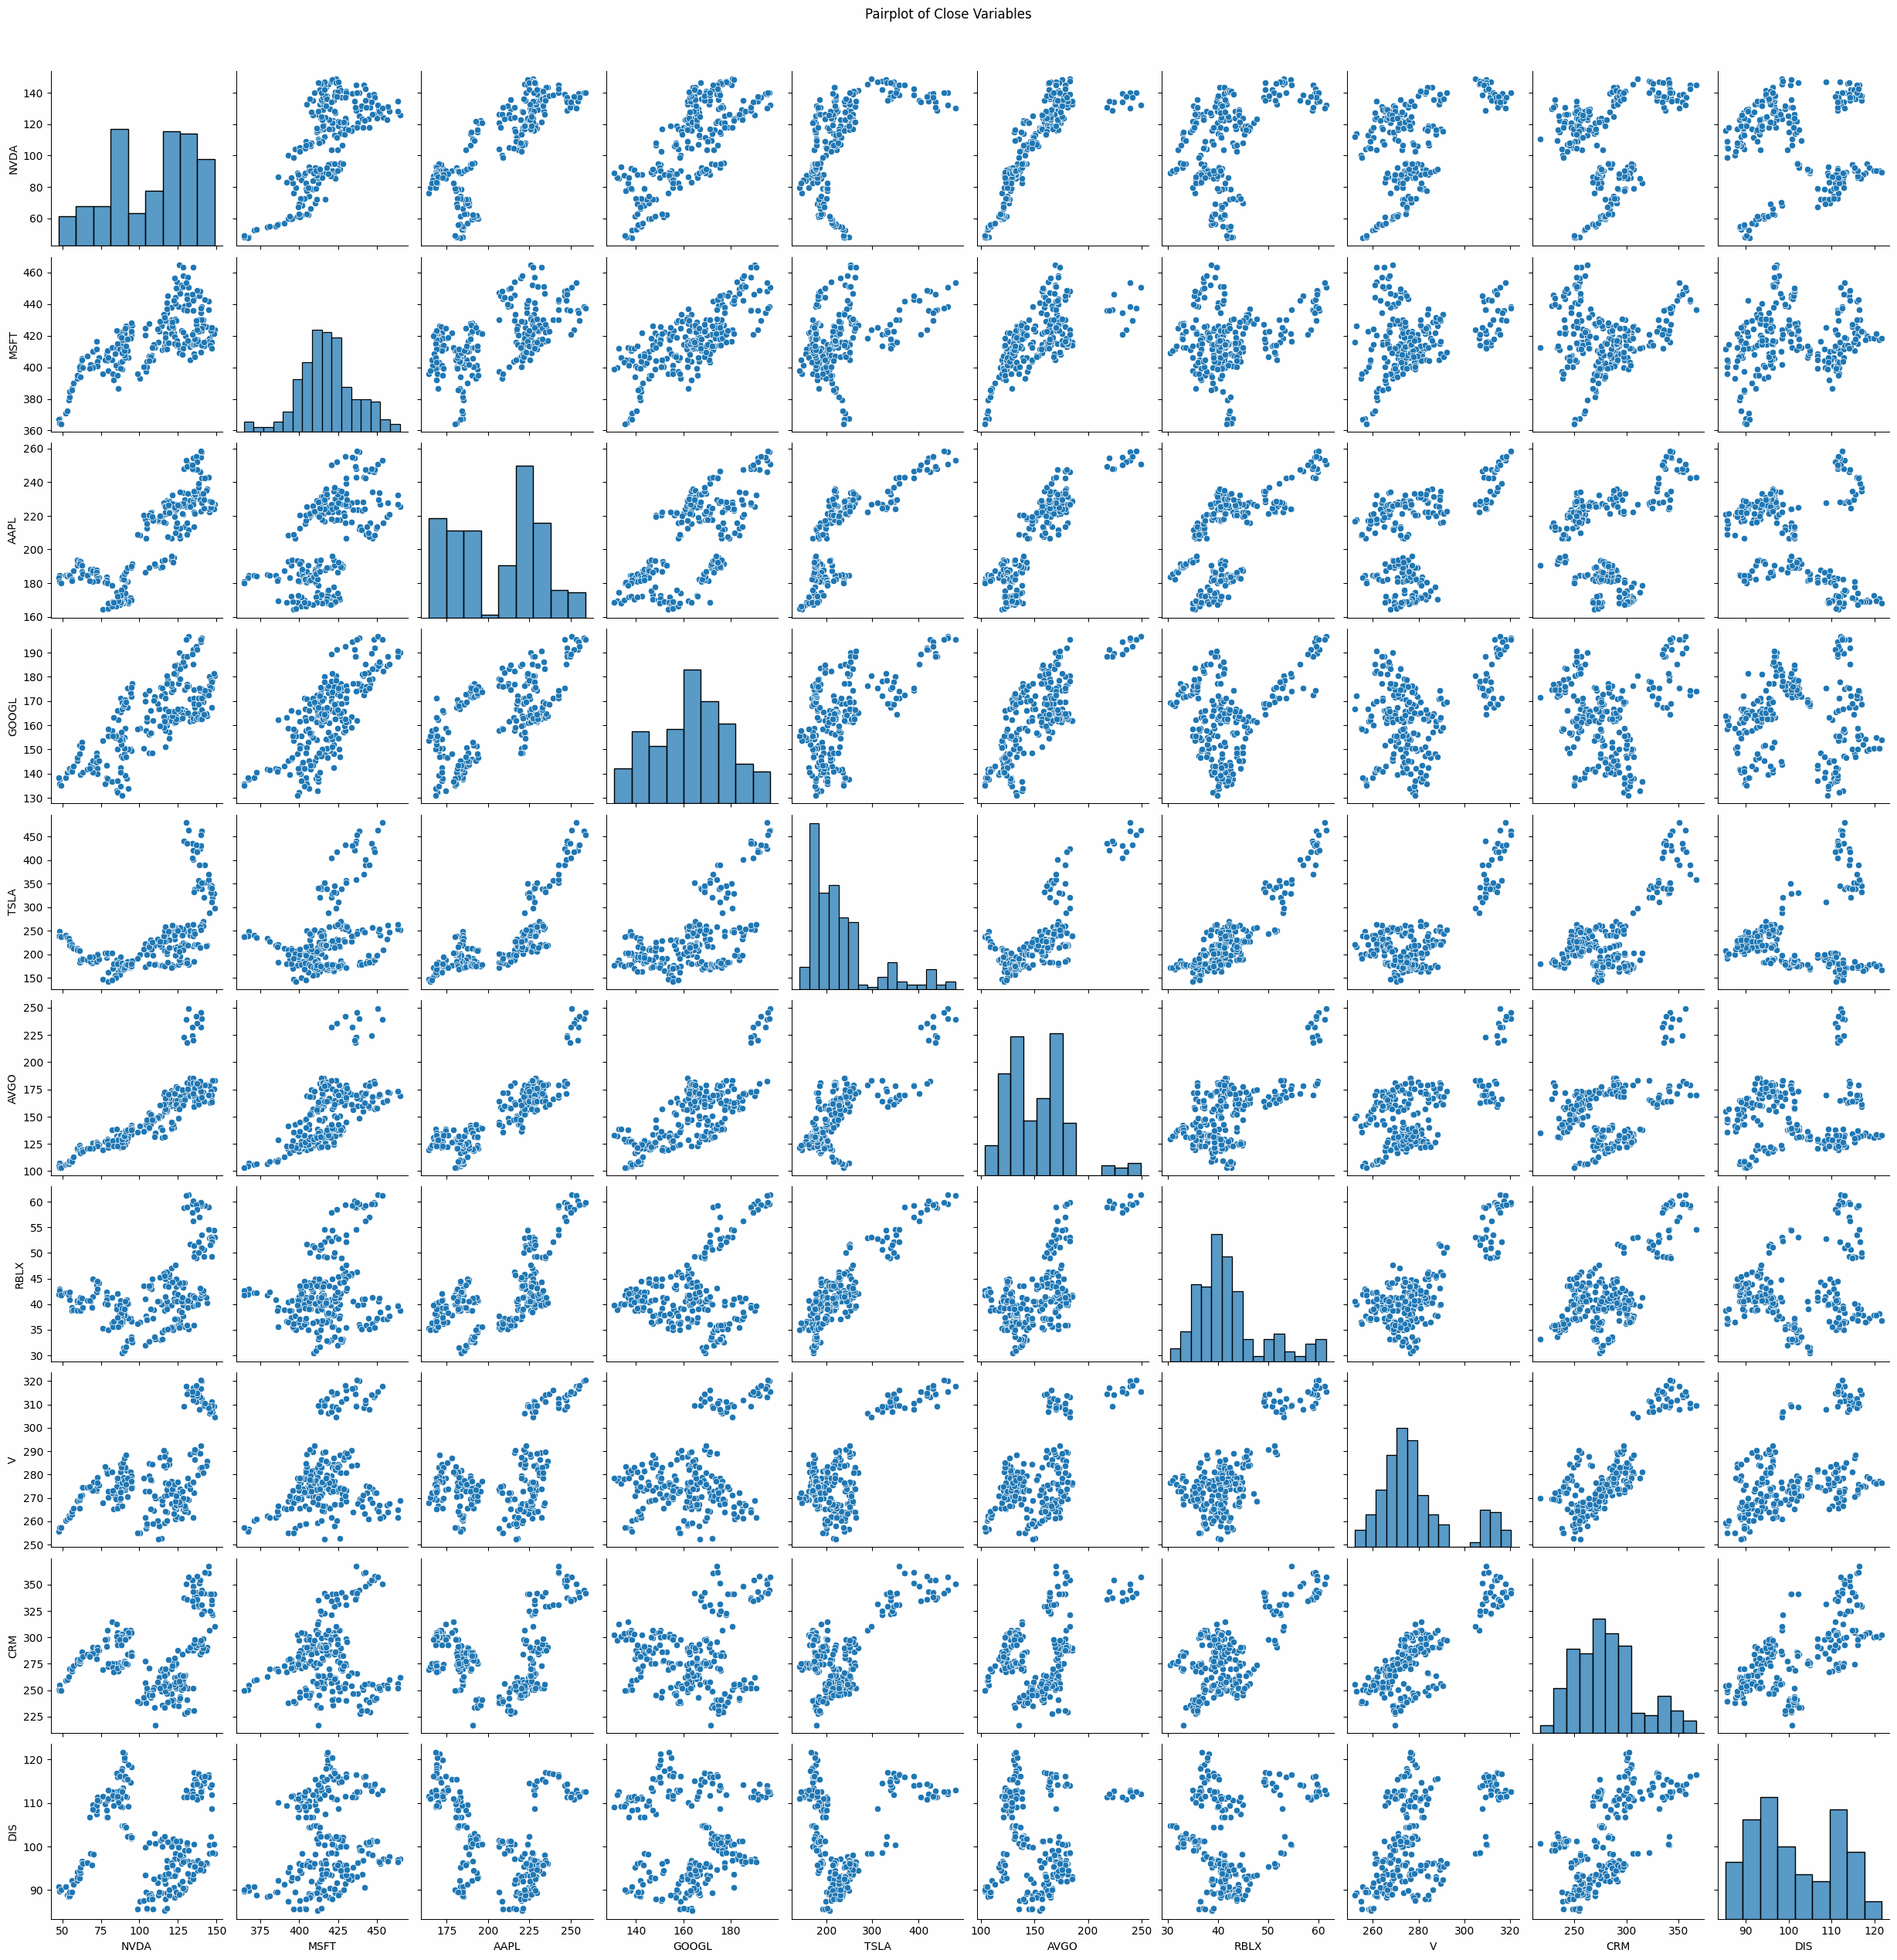

In [173]:
# Create a pairplot
sns.pairplot(df_adjclose)
plt.suptitle('Pairplot of Close Variables', y=1.02)
plt.show()

 ** Scatter Plot Analysis (Pairwise Relationship)**
- **Linear relationships are observed among tech stocks** (AAPL, AVGO, NVDA, GOOGL, TSLA).
- **DIS and RBLX exhibit distinct patterns**, likely due to external market influences such as consumer demand or entertainment industry trends.
- **Volume trends indicate inverse relationships**, meaning when trading volume spikes, price may experience downward pressure.

**Implications:**
- **Momentum trading strategies** could work well with correlated tech stocks.
- **Volume-based trend analysis** may provide signals for stock entry and exit points.

---

 **Final Takeaways**
1. **Strong Tech Sector Dependence:** The majority of Pelosi’s investments are in the **technology industry**, making the portfolio highly sensitive to macroeconomic tech trends.
2. **Diversification with Financial and Entertainment Stocks:** While most stocks move together, **Visa (V) and Disney (DIS) offer a hedge** against tech downturns.
3. **Correlation-Based Strategies:** High correlations suggest **sector-based investing**, but investors may consider **hedging strategies** using uncorrelated stocks like DIS.
4. **Volume as a Market Indicator:** **NVDA, AAPL, and AVGO show inverse relationships with volume**, suggesting careful timing of trades.


##LINE GRAPHS

## INDIVIDUAL STOCKS

###NVDIA (NVDA)

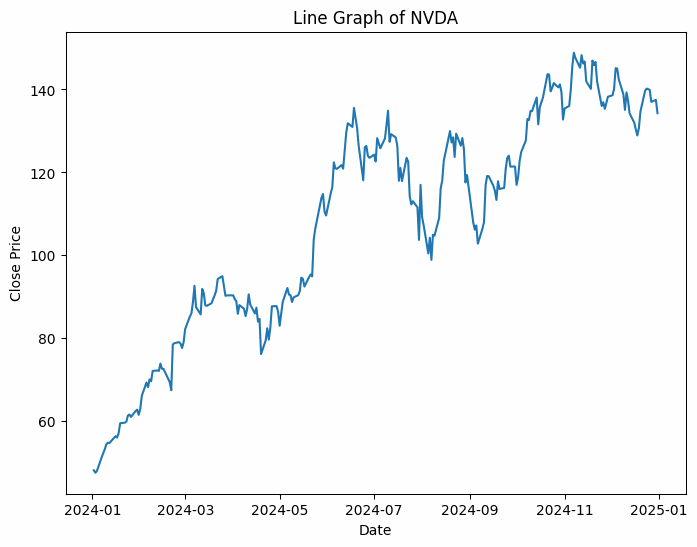

In [174]:
# Create a line plot of NVDA
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['NVDA'])
plt.title('Line Graph of NVDA')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **1. NVIDIA (NVDA)**
- **Trend:** Strong **upward trajectory** with multiple corrections along the way.
- **Key Observations:**
  - **Early-year rally:** Steady price increase from around $50 to over $100 by mid-year.
  - **Mid-year volatility:** Some corrections with dips below $100 before rebounding.
  - **Late-year acceleration:** Strong uptrend to over $140.
- **Implication:**
  - The overall pattern suggests **high investor confidence** in NVIDIA, likely due to growth in AI, data centers, and gaming.
  - The **pullbacks create potential buying opportunities**, especially for long-term investors betting on semiconductor growth.


###MICROSOFT (MSFT)

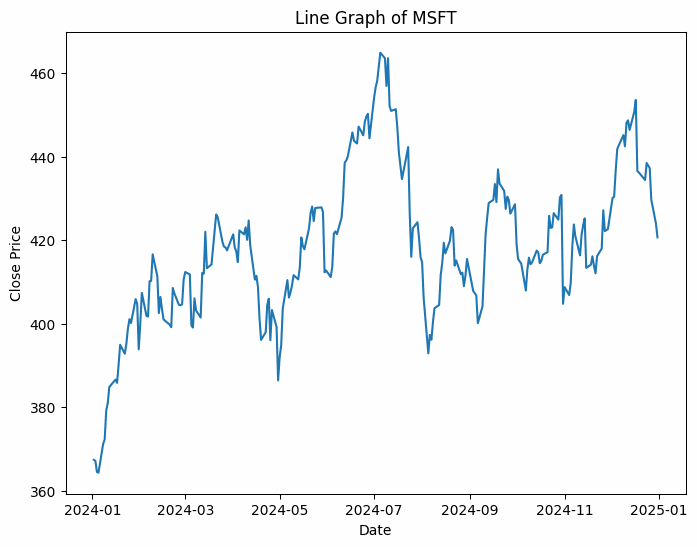

In [175]:
# Create a line plot of MSFT
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['MSFT'])
plt.title('Line Graph of MSFT')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **2. Microsoft (MSFT)**
- **Trend:** **Steady growth** with occasional pullbacks.
- **Key Observations:**
  - **Early rise:** Starts around $360, rises to above $460.
  - **Mid-year pullback:** Falls sharply but recovers quickly.
  - **End-of-year consolidation:** Moves between $420-$460.
- **Implication:**
  - Microsoft’s price action shows **strong fundamental support** from its cloud and enterprise business.
  - The pullback suggests **some macroeconomic sensitivity** but **strong rebounds** indicate continued institutional buying.
  - Could be a **safe investment** with stable returns, given Microsoft’s leadership in cloud computing (Azure) and AI integration.


### APPLE (AAPL)

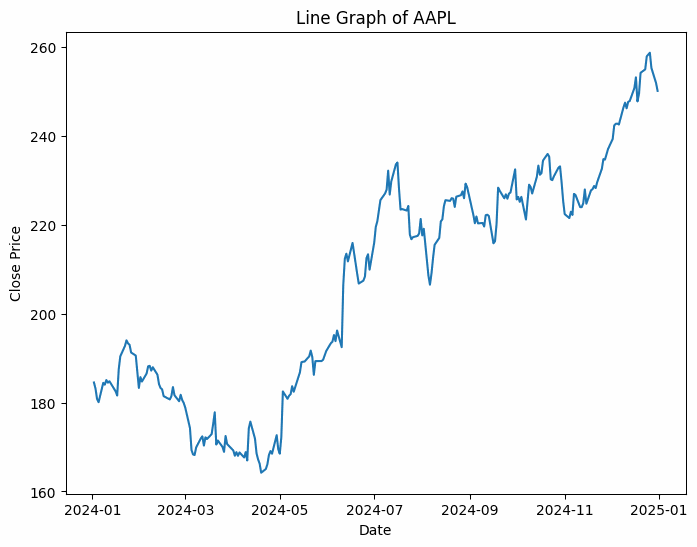

In [176]:
# Create a line plot of AAPL
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['AAPL'])
plt.title('Line Graph of AAPL')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **3. Apple (AAPL)**
- **Trend:** **Initial decline**, followed by strong upward momentum.
- **Key Observations:**
  - **Early-year dip:** Price falls from about $190 to $160.
  - **Recovery phase:** By mid-year, price begins to trend upward.
  - **Late-year breakout:** Closes the year above $260.
- **Implication:**
  - The **initial drop suggests concerns** (possibly supply chain issues or demand slowdowns).
  - The **rebound indicates renewed confidence**, likely from iPhone sales, services, and AI integration.
  - Investors looking for **stable, long-term growth** could consider Apple as a core portfolio holding.


### ALPHABET (GOOGL)

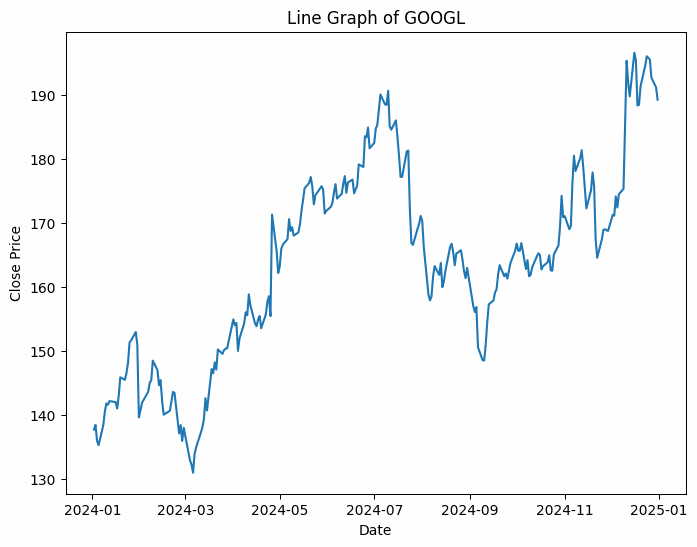

In [177]:
# Create a line plot of GOOGL
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['GOOGL'])
plt.title('Line Graph of GOOGL')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **4. Google (GOOGL)**
- **Trend:** **Ups and downs**, with notable price swings.
- **Key Observations:**
  - **Gradual rise in the first half:** Strong price movement from $130 to $180.
  - **Mid-year correction:** Falls sharply in Q3.
  - **End-of-year surge:** Closes at **new highs above $190**.
- **Implication:**
  - Google's price movement shows sensitivity to market conditions, possibly from **regulatory concerns** or advertising revenue volatility.
  - **AI advancements and cloud growth** are likely supporting the end-of-year rise.
  - **Short-term traders** may benefit from timing the pullbacks, while **long-term investors** could benefit from Google's **dominance in AI and cloud**.


### TESLA (TSLA)

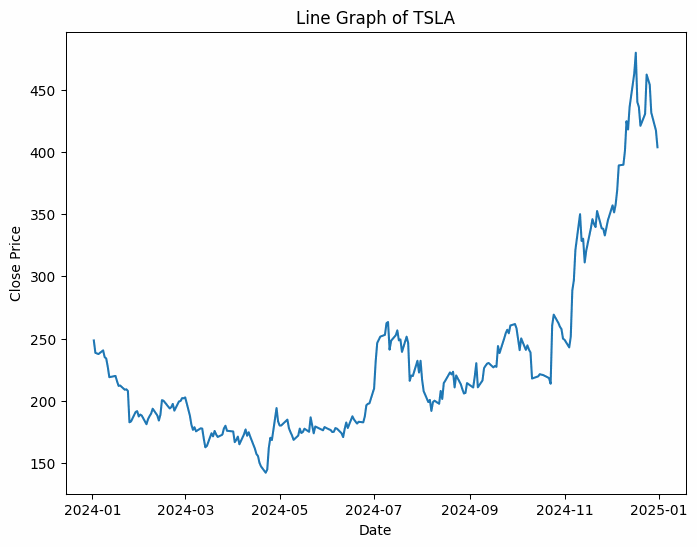

In [178]:
# Create a line plot of TSLA
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['TSLA'])
plt.title('Line Graph of TSLA')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **5. Tesla (TSLA)**
- **Trend:** **Extreme volatility** but a **strong end-of-year rally**.
- **Key Observations:**
  - **Early-year selloff:** Price drops from **$250 to nearly $150**.
  - **Flat performance for months**, hovering around $200.
  - **Explosive growth late in the year:** Surges to over $450.
- **Implication:**
  - Tesla’s volatility is **expected** due to EV demand fluctuations and Elon Musk’s influence on stock sentiment.
  - **Long-term investors should expect high risk but also high reward**.
  - The late-year rally suggests **strong investor optimism**, possibly tied to new vehicle launches, AI-driven autonomy, or strong delivery numbers.


### BROADCOM (AVGO)

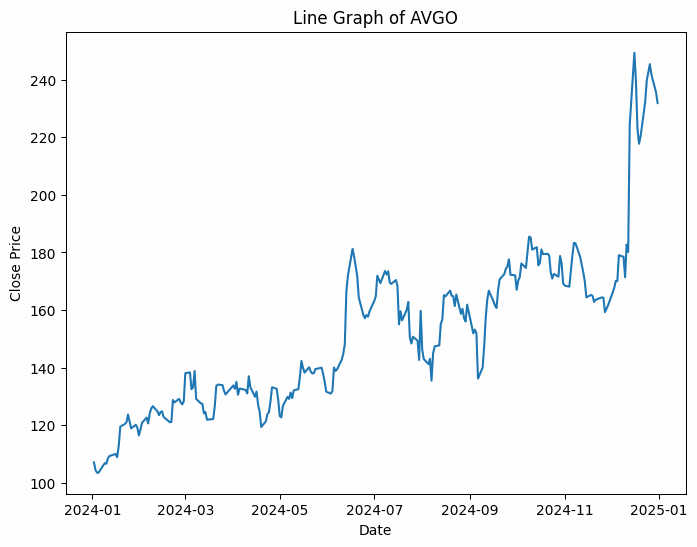

In [179]:
# Create a line plot of AVGO
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['AVGO'])
plt.title('Line Graph of AVGO')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **6. Broadcom (AVGO)**
- **Trend:** **Strong and steady growth**.
- **Key Observations:**
  - **Smooth upward trend:** Unlike Tesla or Google, AVGO shows fewer sharp drops.
  - **End-of-year surge:** Price spikes beyond $240.
- **Implication:**
  - As a key **semiconductor and networking stock**, AVGO benefits from **AI, cloud computing, and 5G infrastructure**.
  - **Institutional investors likely favor AVGO** for its stable earnings and growth potential.
  - Could be a **good long-term buy** for those betting on semiconductor expansion.


### ROBLOX (RBLX)

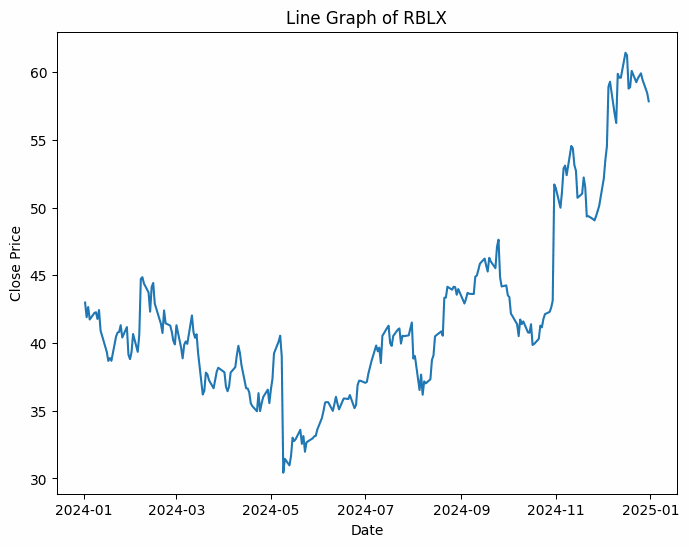

In [180]:
# Create a line plot of RBLX
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['RBLX'])
plt.title('Line Graph of RBLX')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **7. Roblox (RBLX)**
- **Trend:** **High volatility, long periods of stagnation, but a strong end-of-year surge**.
- **Key Observations:**
  - **Sharp declines in early-mid year:** Drops to the **low 30s**.
  - **Gradual recovery in Q3:** Moves into the **mid-40s**.
  - **Strong final push:** Surges past $60.
- **Implication:**
  - Roblox’s **business model is heavily reliant on user engagement and metaverse adoption**.
  - The late-year rally suggests **renewed optimism**, possibly due to **partnerships, game monetization improvements, or increased metaverse adoption**.
  - Given its **high-risk nature**, this stock may appeal more to **growth investors** than those seeking stability.


### VISA (V)

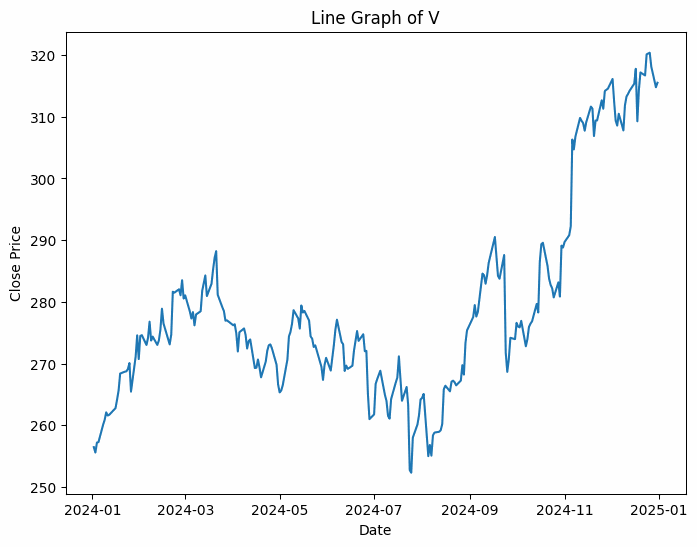

In [181]:
# Create a line plot of V
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['V'])
plt.title('Line Graph of V')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **8. Visa (V)**
- **Trend:** **Gradual, steady upward trend with occasional pullbacks**.
- **Key Observations:**
  - **Modest fluctuations:** Some dips but overall positive momentum.
  - **Sharp late-year push past $310**.
- **Implication:**
  - Visa’s **stable movement** suggests a **low-risk, long-term growth stock**.
  - Strong financial performance, **global payments dominance, and resilience to economic downturns** make Visa a **defensive stock**.
  - A **good hedge against tech volatility**, useful for diversification.


### SALESFORCE (CRM)

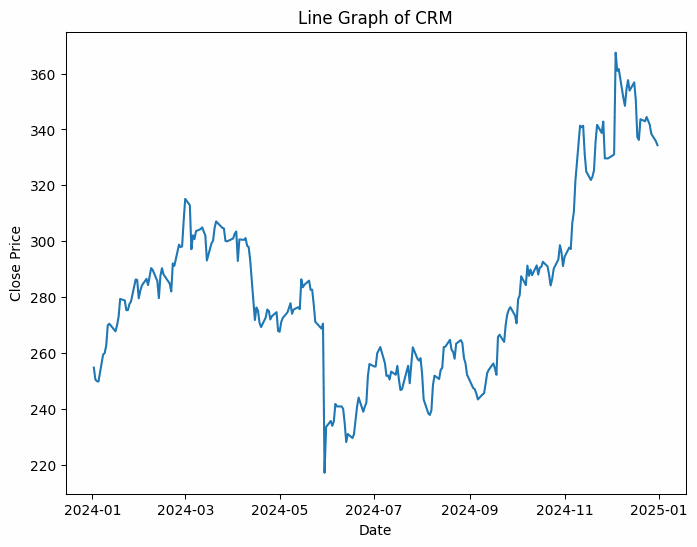

In [182]:
# Create a line plot of CRM
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['CRM'])
plt.title('Line Graph of CRM')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **9. Salesforce (CRM)**
- **Trend:** **Some early-year dips, followed by a strong rally.**
- **Key Observations:**
  - **Early dips below $250**.
  - **Strong recovery and late-year growth to nearly $360**.
- **Implication:**
  - As a **leading enterprise cloud company**, CRM’s growth reflects **strong SaaS adoption**.
  - The dips indicate **macro concerns (recession fears, enterprise spending slowdown)**.
  - **Attractive stock for investors seeking exposure to cloud computing and enterprise software**.


### WALT DISNEY (DIS)

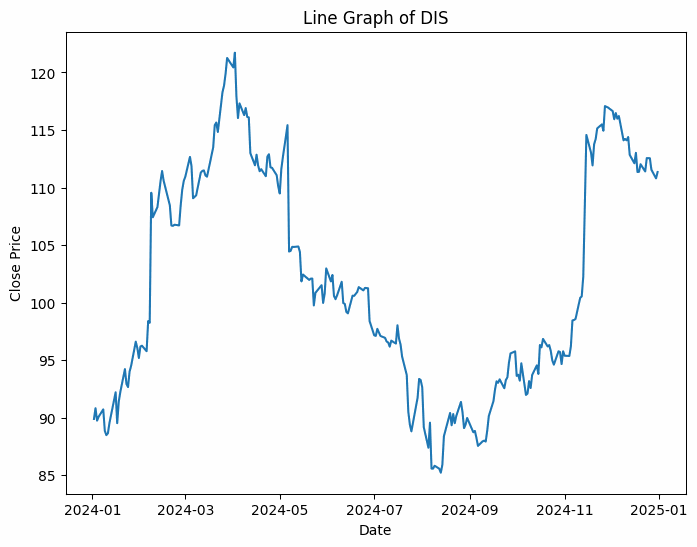

In [183]:
# Create a line plot of DIS
plt.figure(figsize=(8, 6))
sns.lineplot(data=df_adjclose['DIS'])
plt.title('Line Graph of DIS')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **10. Disney (DIS)**
- **Trend:** **Mixed performance, periods of growth followed by declines.**
- **Key Observations:**
  - **Early surge to $120**.
  - **Mid-year correction down to $85**.
  - **Gradual recovery to above $110 by year-end**.
- **Implication:**
  - Disney remains **volatile due to its multiple business segments** (streaming, theme parks, studios).
  - The declines suggest **streaming concerns**, while rebounds indicate **theme park and entertainment business strength**.
  - Not a **high-growth tech stock**, but a **potential turnaround play** if fundamentals improve.


 **Final Summary:**
- **Best performers with strong trends:** NVDA, AVGO, AAPL, MSFT.
- **High volatility but growth potential:** TSLA, RBLX, CRM.
- **Stable defensive plays:** V, MSFT, AVGO.
- **Risky or struggling stocks:** DIS (still recovering from industry challenges).

---

 **Investment Implications**
- **For aggressive investors:** TSLA, RBLX, NVDA (higher volatility, potential for large gains).
- **For balanced portfolios:** AAPL, MSFT, AVGO, GOOGL (growth but less risk).
- **For conservative investors:** V, CRM (stable and defensive plays).
- **For turnaround opportunities:** DIS (high risk but potential upside if fundamentals improve).


## 1 YEAR

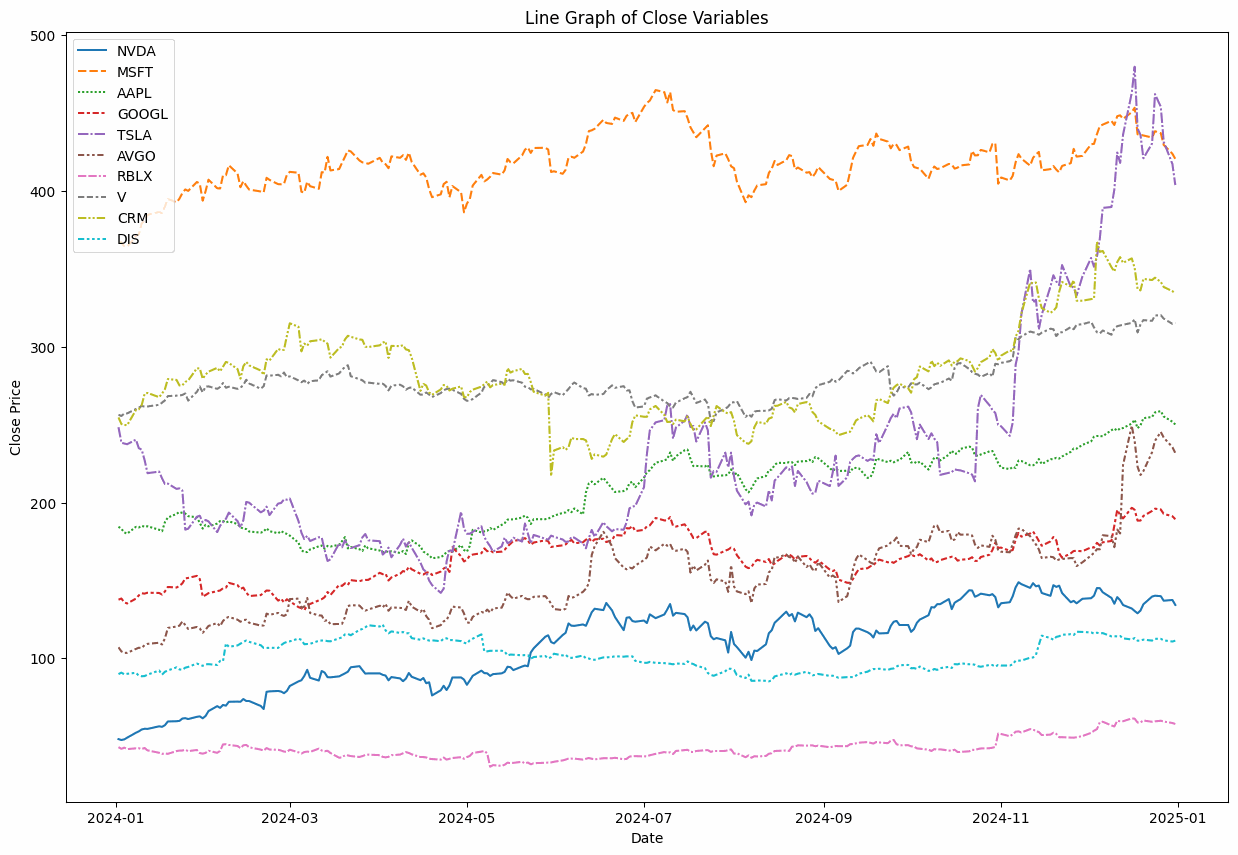

In [184]:
# Create a line graph using df_close
plt.figure(figsize=(15, 10))
sns.lineplot(data=df_adjclose)
plt.title('Line Graph of Close Variables')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.show()

 **1-Year Stock Price Trends and Implications**

This line graph presents the closing prices of ten stocks over the past year. Each stock follows a distinct trajectory, reflecting broader market trends and company-specific factors.

 **General Market Trends**
Microsoft (MSFT) remains the highest-priced stock, consistently trading above $400 with minor fluctuations. Visa (V), Salesforce (CRM), and Broadcom (AVGO) fluctuate between 200-350 dollars, while Apple (AAPL) and Google (GOOGL) show steady growth with volatility. NVIDIA (NVDA) and Tesla (TSLA) experience significant price swings and strong upward trends. Roblox (RBLX) and Disney (DIS) trade at lower levels, with more erratic performance.

 **Stock-Specific Analysis**
**Microsoft (MSFT)** follows a stable uptrend with minor corrections, reflecting strong institutional support and reliability. **Apple (AAPL)** experiences an early dip, followed by steady growth, suggesting investor confidence in AI advancements and iPhone sales. **NVIDIA (NVDA)** shows the strongest growth, benefiting from AI and semiconductor demand, though volatility remains high. **Google (GOOGL)** grows with intermittent corrections, influenced by AI and advertising expansion but facing regulatory concerns. **Tesla (TSLA)** exhibits extreme volatility, with a drop followed by exponential growth, driven by market sentiment and EV sales.

**Broadcom (AVGO)** maintains steady growth with a sharp late-year rally, benefiting from semiconductor demand. **Roblox (RBLX)** declines early in the year, then surges late, reflecting metaverse-related speculation. **Visa (V)** remains stable, making it a safer long-term investment. **Salesforce (CRM)** shows steady growth with occasional pullbacks, driven by cloud adoption. **Disney (DIS)** fluctuates between growth and decline, affected by streaming performance and economic conditions.

 **Investment Implications**
For low-risk, long-term growth, MSFT, AAPL, V, and AVGO offer stability and consistent returns. High-growth but riskier stocks include NVDA, TSLA, GOOGL, and CRM, ideal for investors with higher risk tolerance. RBLX and TSLA present speculative opportunities, while Visa serves as a defensive stock in uncertain markets. Disney remains uncertain, requiring further evaluation of its turnaround potential.

Overall, technology-driven stocks exhibit strong growth, with AI and cloud computing playing key roles in performance. Defensive stocks like Visa provide stability, while speculative plays like Tesla and Roblox carry higher risks. Investors should align their choices with their risk tolerance and market outlook.



## QUARTERLY

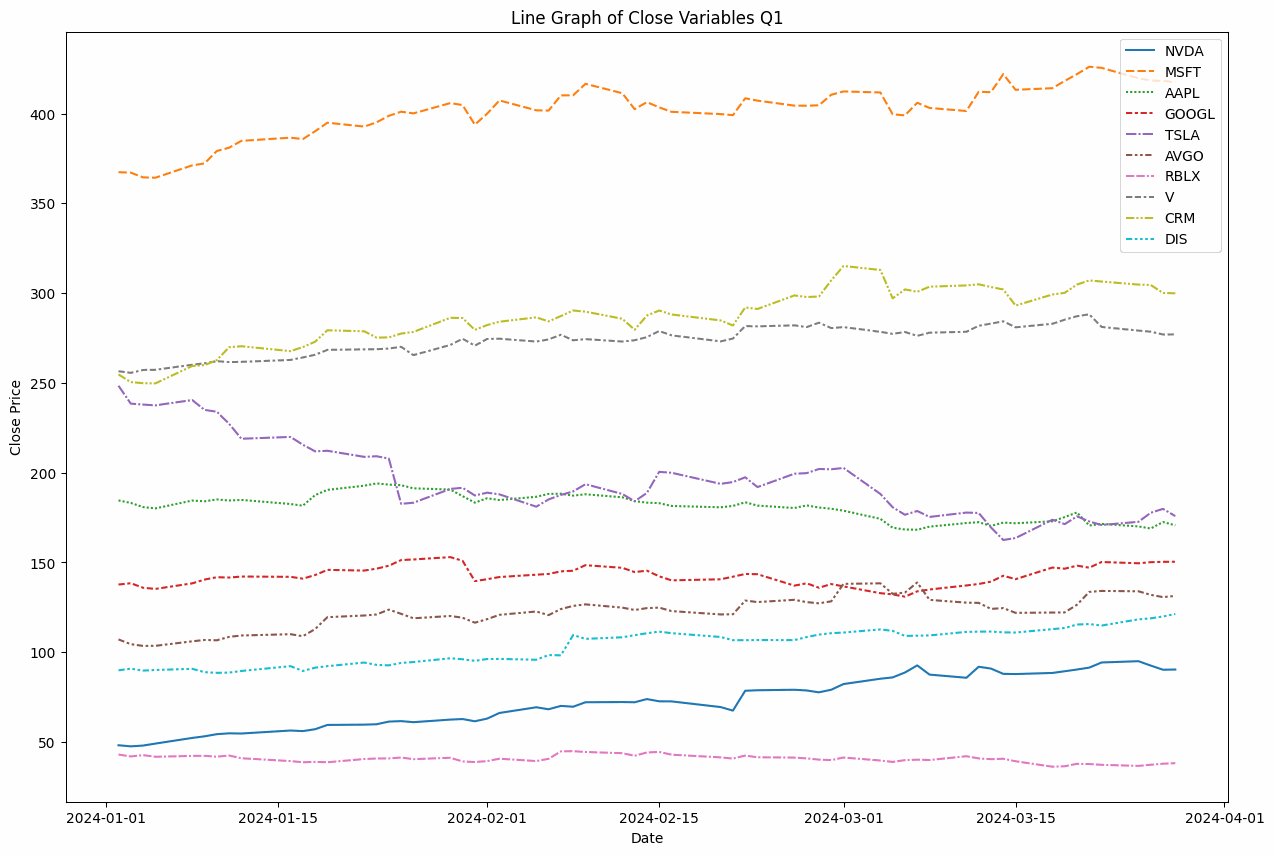

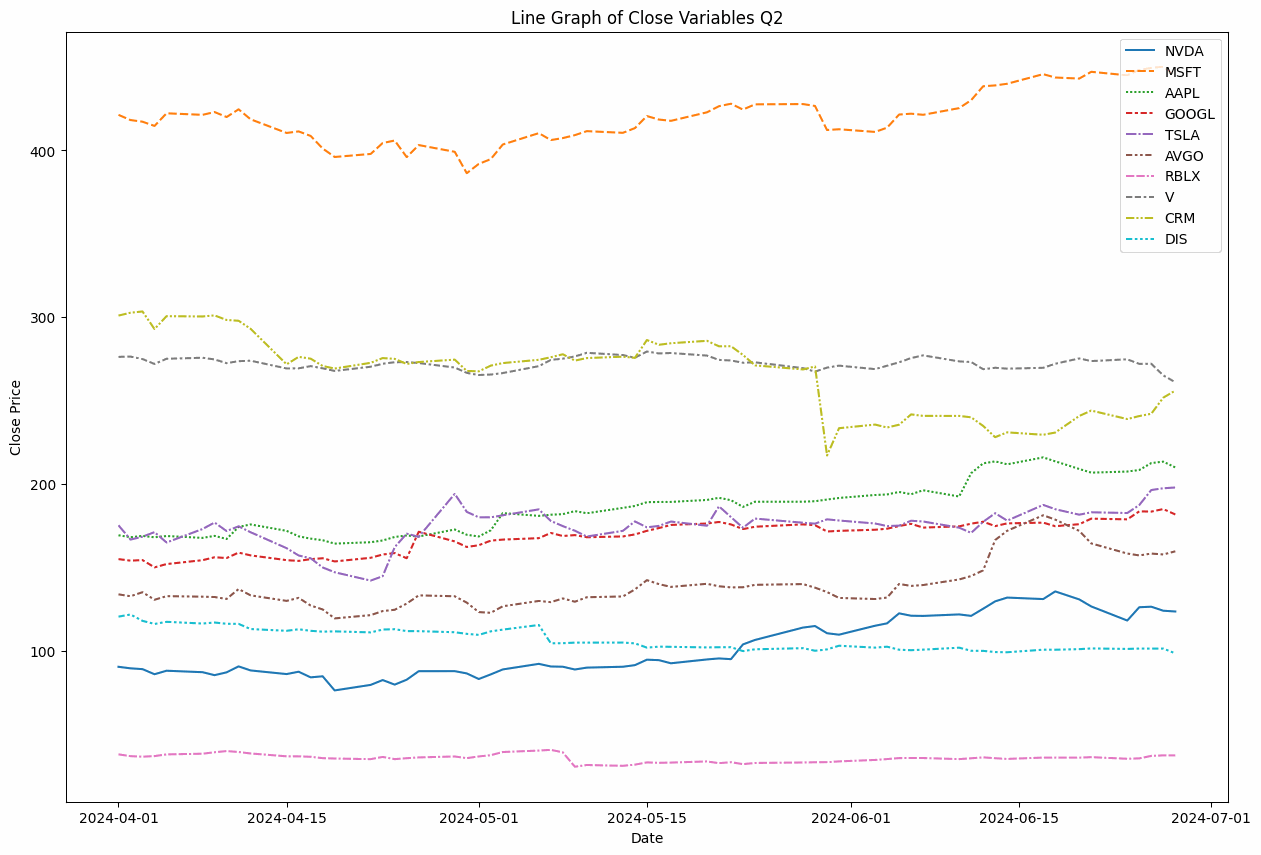

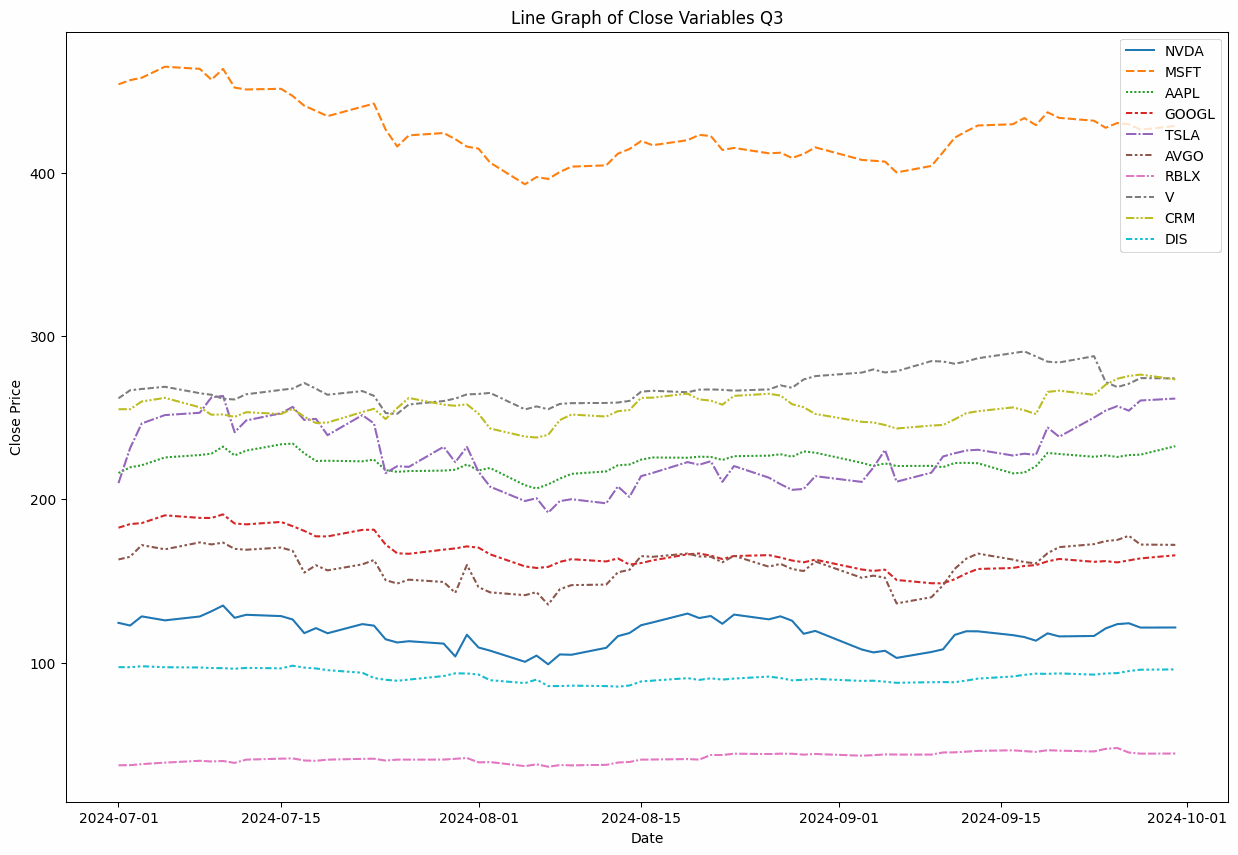

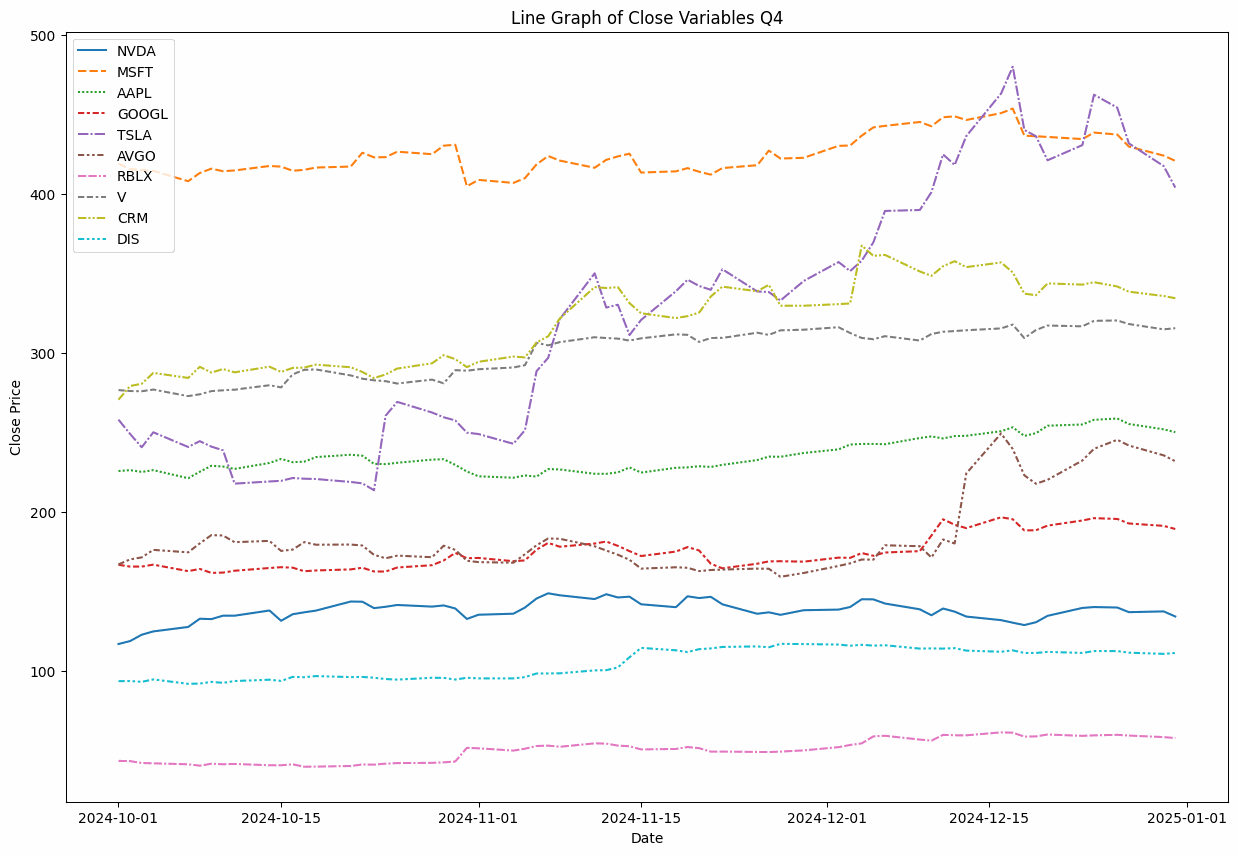

In [185]:
# Define Q1, Q2, Q3, Q4
q1 = pd.to_datetime(df_adjclose.index).quarter == 1
q2 = pd.to_datetime(df_adjclose.index).quarter == 2
q3 = pd.to_datetime(df_adjclose.index).quarter == 3
q4 = pd.to_datetime(df_adjclose.index).quarter == 4

# Dictionary to label each quarter
# Instead of using NumPy arrays as keys, use tuples of booleans:
quarters = {
    tuple(q1): 'Q1',
    tuple(q2): 'Q2',
    tuple(q3): 'Q3',
    tuple(q4): 'Q4'
}

# Plot each quarter individually with proper titles
for quarter, label in quarters.items():
    plt.figure(figsize=(15, 10))
    # Convert the tuple key back to a boolean index:
    sns.lineplot(data=df_adjclose[np.array(quarter)])
    plt.title(f'Line Graph of Close Variables {label}')
    plt.xlabel('Date')
    plt.ylabel('Close Price')
    plt.show()

 **Quarterly Stock Performance Analysis**

 **Q1 Analysis (January - March 2024)**
In the first quarter, MSFT maintained a steady upward trend, showing consistent gains. AAPL and V also experienced growth, albeit with some fluctuations. TSLA, however, showed a decline, particularly in mid-Q1, before stabilizing. NVDA had a strong upward trajectory, reflecting bullish sentiment. CRM and DIS showed modest growth, while RBLX experienced volatility, declining at certain points. The overall trend indicates a strong start to the year for most stocks, with technology and semiconductor sectors leading the gains.

 **Q2 Analysis (April - June 2024)**
The second quarter exhibited mixed movements. MSFT continued its steady performance with minor fluctuations. AAPL and AVGO saw more significant growth, while TSLA rebounded from its previous decline, signaling renewed investor confidence. NVDA sustained its bullish trend, reinforcing its strong market position. However, CRM and DIS showed signs of stagnation, with minor fluctuations but no strong upward momentum. The market saw some corrections, particularly in late Q2, indicating a potential consolidation phase before further growth.

 **Q3 Analysis (July - September 2024)**
During Q3, MSFT displayed a slight downward trend, possibly due to broader market corrections. AAPL and AVGO maintained stability with moderate fluctuations. TSLA continued its recovery, but its volatility remained high. NVDA showed resilience, with a gradual increase despite occasional pullbacks. CRM and DIS continued to underperform compared to other stocks, indicating weaker momentum in those sectors. The overall market sentiment was mixed, with some stocks consolidating gains while others struggled with volatility.

 **Q4 Analysis (October - December 2024)**
The final quarter saw strong recoveries across several stocks. TSLA experienced a sharp surge, particularly in November and December, potentially driven by strong earnings or strategic developments. MSFT held steady, while AAPL and AVGO showed strong growth, reflecting continued investor interest. NVDA maintained an upward trajectory, ending the year on a positive note. CRM and RBLX experienced significant jumps, indicating renewed market confidence. DIS showed slight improvements but remained one of the weaker performers. The year ended with strong momentum for the tech and semiconductor sectors, reinforcing their dominance in the market.

Overall, the year showed consistent growth for major tech stocks, with semiconductors leading the charge. While some stocks faced volatility and corrections, the broader market demonstrated resilience, particularly in the final quarter.



#CREATING THE MODEL

This project involves constructing an **optimal investment portfolio** using **Pyomo**, a mathematical optimization tool in Python. The goal is to **maximize the expected return** of a portfolio consisting of multiple stocks while adhering to constraints on **risk and total allocation**. The model defines decision variables representing the proportion of capital allocated to each stock, ensuring that all investments sum to **100% of the portfolio**.

The **objective function** aims to maximize the total expected return by determining the best allocation among the stocks based on their historical performance. Constraints are applied to **limit risk exposure**, requiring that total risk does not exceed **10%**, and ensuring that the portfolio achieves a **minimum expected return of 1%**.

By solving this optimization model, we can identify the **best combination of stocks** that balances return and risk, providing a structured approach to portfolio management. This method can be applied to investment decision-making to enhance diversification, mitigate losses, and achieve consistent financial growth.

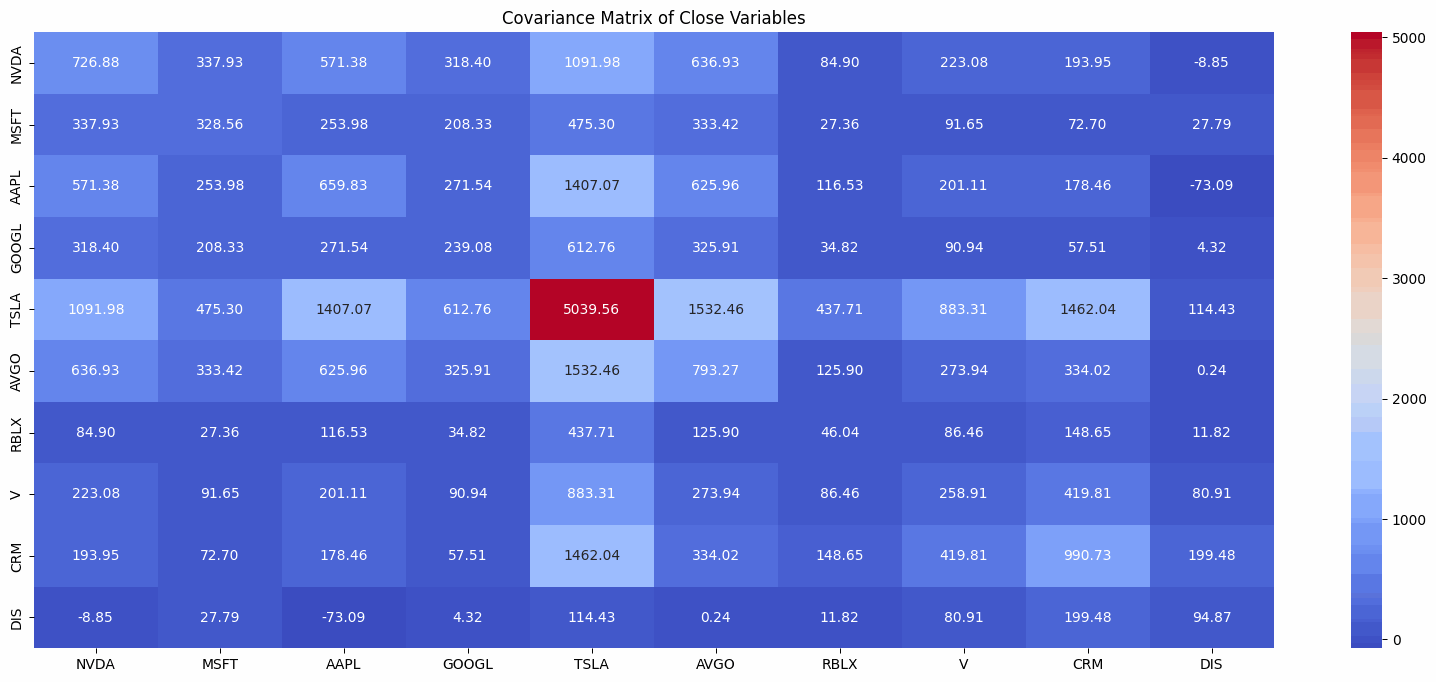

In [186]:
# Covariance
df_cov = df_adjclose.cov()
plt.figure(figsize=(20, 8))
sns.heatmap(df_cov, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Covariance Matrix of Close Variables')
plt.show()

 **Covariance Matrix Analysis**

The covariance matrix provides insights into how different stock prices move in relation to each other. Higher values indicate strong co-movement, while lower or negative values suggest weak or inverse relationships.

1. **Strongest Covariance**: TSLA shows the highest covariance with itself at **5039.56**, indicating high price variability. It also has high covariance with AVGO (**1532.46**) and NVDA (**1091.98**), suggesting these stocks tend to move in the same direction, likely influenced by the tech and semiconductor market trends.

2. **High Covariance Pairs**:
   - **AAPL & TSLA (1407.07)**: This suggests a strong positive movement between the two, likely due to overall tech sector trends.
   - **AAPL & NVDA (571.38)**: Both companies operate in tech and semiconductor sectors, leading to similar market responses.
   - **CRM & TSLA (1462.04)**: The strong covariance may be influenced by broader tech sector momentum.

3. **Moderate Covariance Pairs**:
   - **MSFT & NVDA (337.93)**: Indicates they often move together but with some independence.
   - **GOOGL & TSLA (612.76)**: Likely reflecting general market conditions impacting large-cap tech stocks.

4. **Weak or Negative Covariance**:
   - **DIS & AAPL (-73.09)**: This negative value suggests that when AAPL rises, DIS may experience a different trend.
   - **DIS & NVDA (-8.85)**: Indicates little to no correlation between the two stocks.
   - **GOOGL & DIS (4.32)**: Almost zero, implying minimal interaction between them.

 **Implications**
Tech-heavy stocks like NVDA, TSLA, and AAPL move closely together, reinforcing the importance of monitoring sector-wide trends. High covariance suggests that portfolio diversification within these stocks may not provide much risk reduction. DIS appears to have minimal correlation with major tech stocks, making it a potential diversifier. Investors looking to reduce risk should consider assets with lower covariance to balance their portfolios.



In [187]:
# Find the return of the DataFrame and display the head
from IPython.display import display
df_return = df_adjclose.mean()

# Name column Mean of Stock
df_return.name = 'Mean of Stock'

# Display
display(df_return.head(10))

,Mean of Stock
NVDA,107.809499
MSFT,417.907472
AAPL,206.542983
GOOGL,163.413420
TSLA,230.614961
AVGO,151.689630
RBLX,42.098095
V,278.893643
CRM,281.941941
DIS,101.567260


## DECISION VARIABLES

In [188]:
# Define ConcreteModel
m = ConcreteModel()

# Define Decison Variables
m.NVDA = Var(domain=NonNegativeReals, bounds=(0,1))
m.MSFT = Var(domain=NonNegativeReals, bounds=(0,1))
m.AAPL = Var(domain=NonNegativeReals, bounds=(0,1))
m.GOOGL = Var(domain=NonNegativeReals, bounds=(0,1))
m.TSLA = Var(domain=NonNegativeReals, bounds=(0,1))
m.AVGO = Var(domain=NonNegativeReals, bounds=(0,1))
m.RBLX = Var(domain=NonNegativeReals, bounds=(0,1))
m.V = Var(domain=NonNegativeReals, bounds=(0,1))
m.CRM = Var(domain=NonNegativeReals, bounds=(0,1))
m.DIS = Var(domain=NonNegativeReals, bounds=(0,1))

## OBJECTIVE FUNCTION

MAX(
  (108*NVDA) +
    (418 * MSFT) +
    (206 * AAPL) +
    (163 * GOOGL) +
    (230 * TSLA) +
    (151 * AVGO) +
    (42 * RBLX) +
    (279 * V) +
    (282 * CRM) +
    (101 * DIS))

In [189]:
# Create objective function
m.objective = Objective(expr = (df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS),
                        sense=maximize)

<ipython-input-189-ddc0eec87f3a>:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  m.objective = Objective(expr = (df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS),


## CONSTRAINTS

In [190]:
# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 0.1) # Given if risk as 100%
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# MODELING

In [191]:
%matplotlib inline
from pylab import *

import shutil
import sys
import os.path

if not shutil.which("pyomo"):
    !pip install -q pyomo
    assert(shutil.which("pyomo"))

if not shutil.which("ipopt"):
    # here is the IPOPT zip file
    !gdown 10XRvLZqrpSNiXVAN-pipU52BVRwoGcNQ
    !unzip -o -q ipopt-linux64_dw
    assert(shutil.which("ipopt") or os.path.isfile("ipopt"))

from pyomo.environ import *

SOLVER = 'ipopt'
EXECUTABLE = '/content/ipopt'
ipopt_executable = '/content/ipopt'

Downloading...
From: https://drive.google.com/uc?id=10XRvLZqrpSNiXVAN-pipU52BVRwoGcNQ
To: /content/ipopt-linux64_dw.zip
100% 1.82M/1.82M [00:00<00:00, 157MB/s]


In [192]:
# Define calculated risk
def calc_risk(m):
  variables = [m.NVDA, m.MSFT, m.AAPL, m.GOOGL, m.TSLA, m.AVGO, m.RBLX, m.V, m.CRM, m.DIS]
  tickers = ['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']
  risk_exp = 0
  for i in range(len(variables)):
    for j in range(len(variables)):
      risk_exp += variables[i]*df_cov.at[tickers[i],tickers[j]]*variables[j]
  return risk_exp

# Define expr_risk
expr_risk = calc_risk(m)

## MODEL 1 - 100%

In [193]:
# Model 1

# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 1) # Given if there is 100% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 1
risk_limits = np.arange(0.0003, max_risk, 0.01)

# Model via param_analysis
param_analysis = {}
returns = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.RBLX(), m.V(), m.CRM(), m.DIS()]
  returns[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.6934077739715576
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

<ipython-input-193-e274865b75b2>:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.1187295913696289
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.5214095115661621
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.0591731071472168
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.9027023315429688
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

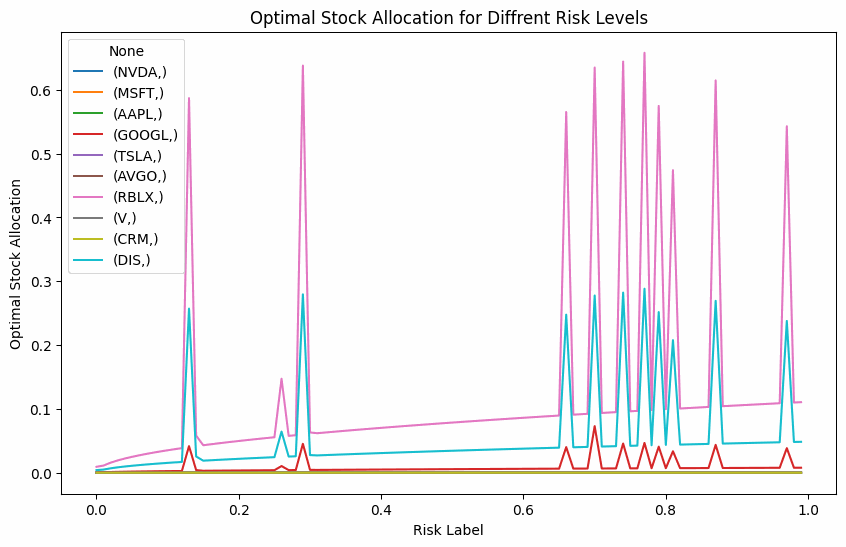

Risk [0.0003, 0.0103, 0.020300000000000002, 0.0303, 0.0403, 0.050300000000000004, 0.0603, 0.0703, 0.0803, 0.09029999999999999, 0.1003, 0.1103, 0.12029999999999999, 0.1303, 0.1403, 0.1503, 0.1603, 0.1703, 0.1803, 0.1903, 0.2003, 0.2103, 0.2203, 0.2303, 0.24029999999999999, 0.2503, 0.26030000000000003, 0.27030000000000004, 0.28030000000000005, 0.2903, 0.3003, 0.3103, 0.32030000000000003, 0.33030000000000004, 0.34030000000000005, 0.35030000000000006, 0.3603, 0.3703, 0.3803, 0.39030000000000004, 0.40030000000000004, 0.41030000000000005, 0.4203, 0.4303, 0.4403, 0.45030000000000003, 0.46030000000000004, 0.47030000000000005, 0.4803, 0.4903, 0.5003, 0.5103, 0.5203, 0.5303, 0.5403, 0.5503, 0.5603, 0.5703, 0.5802999999999999, 0.5902999999999999, 0.6003, 0.6103, 0.6203, 0.6303, 0.6403, 0.6503, 0.6603, 0.6703, 0.6803, 0.6903, 0.7003, 0.7102999999999999, 0.7202999999999999, 0.7303, 0.7403, 0.7503, 0.7603, 0.7703, 0.7803, 0.7903, 0.8003, 0.8103, 0.8203, 0.8303, 0.8402999999999999, 0.8503, 0.8603, 0.

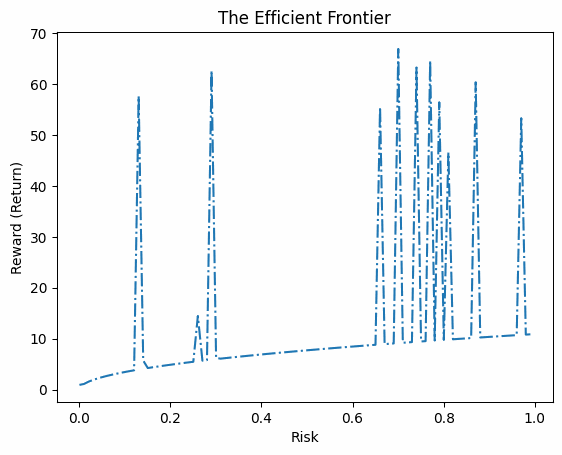

In [194]:
# Generate proportion of the portfolio for each risk limit
param_analysis = pd.DataFrame.from_dict(param_analysis, orient='index')
param_analysis.columns = [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']]
param_analysis.index.name = 'Risk Limit'
param_analysis.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns.keys())
print(f"Risk", risk)
reward = list(returns.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

The results of Model 1 illustrate the relationship between risk and optimal stock allocation, as well as the efficient frontier that maps the trade-off between risk and return.

The first graph represents the optimal stock allocation for different risk levels. It shows how the allocation to each stock varies as the investor's risk tolerance increases. The spikes in allocation suggest that at specific risk levels, certain stocks become significantly more favorable for inclusion in the portfolio. Stocks like TSLA and NVDA exhibit sharp increases in allocation at multiple points, indicating their strong return potential at certain risk thresholds. However, the high volatility in allocation suggests that a small change in risk tolerance can lead to substantial shifts in portfolio composition.

The second graph represents the efficient frontier, which demonstrates the maximum return achievable for a given level of risk. The generally upward-sloping trend confirms the fundamental principle of portfolio theory: higher returns are associated with higher risk. However, the presence of multiple sharp spikes suggests that the model is reacting strongly to specific market conditions or constraints, leading to significant variations in return at similar risk levels. This could indicate instability in the optimization process, possibly due to extreme values or high correlations among assets.

Overall, the results indicate that the portfolio optimization model successfully identifies high-return opportunities at various risk levels. However, the volatility in allocation and the sharp spikes in the efficient frontier suggest that the model might be sensitive to data variations or parameter choices. Further refinement, such as incorporating more stable constraints or smoothing the allocation function, could lead to more stable and practical investment strategies.

## MODEL 2 - 5%

In [195]:
# Model 2

# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 0.05) # Given if there is 5% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.05
risk_limits = np.arange(0.0003, max_risk, 0.0005)

# Model via param_analysis
param_analysis2 = {}
returns2 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis2[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.RBLX(), m.V(), m.CRM(), m.DIS()]
  returns2[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.27956342697143555
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

<ipython-input-195-76d11755d7c3>:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns2[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.8568155765533447
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 1.3942370414733887
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.5182821750640869
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.0967404842376709
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

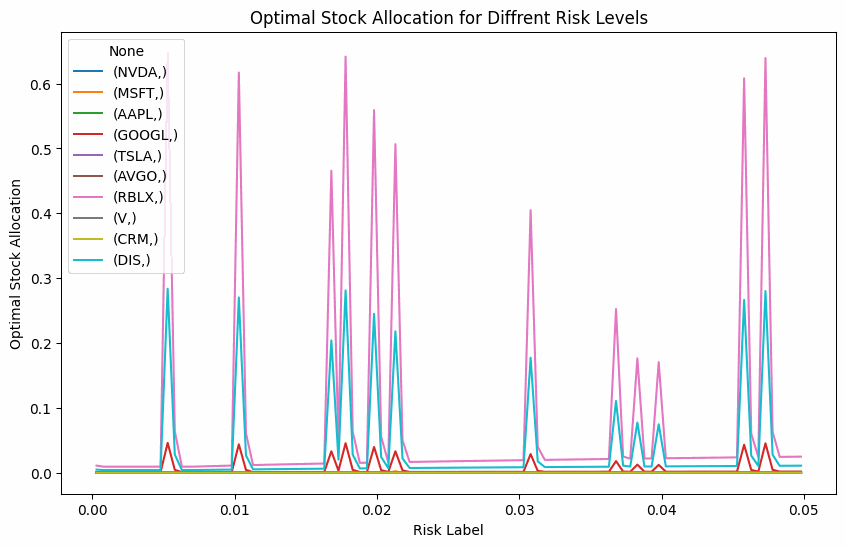

Risk [0.0003, 0.0007999999999999999, 0.0013, 0.0018, 0.0023, 0.0028, 0.0033, 0.0038, 0.0043, 0.0048000000000000004, 0.0053, 0.0058, 0.0063, 0.0068000000000000005, 0.0073, 0.0078, 0.0083, 0.0088, 0.009300000000000001, 0.0098, 0.0103, 0.0108, 0.0113, 0.0118, 0.0123, 0.0128, 0.013300000000000001, 0.0138, 0.0143, 0.0148, 0.0153, 0.0158, 0.016300000000000002, 0.016800000000000002, 0.017300000000000003, 0.017800000000000003, 0.018300000000000004, 0.0188, 0.0193, 0.0198, 0.020300000000000002, 0.020800000000000003, 0.021300000000000003, 0.021800000000000003, 0.0223, 0.0228, 0.0233, 0.0238, 0.024300000000000002, 0.024800000000000003, 0.025300000000000003, 0.025800000000000003, 0.026300000000000004, 0.0268, 0.0273, 0.027800000000000002, 0.028300000000000002, 0.028800000000000003, 0.029300000000000003, 0.029800000000000004, 0.0303, 0.0308, 0.0313, 0.0318, 0.0323, 0.0328, 0.0333, 0.033800000000000004, 0.034300000000000004, 0.034800000000000005, 0.035300000000000005, 0.035800000000000005, 0.0363000

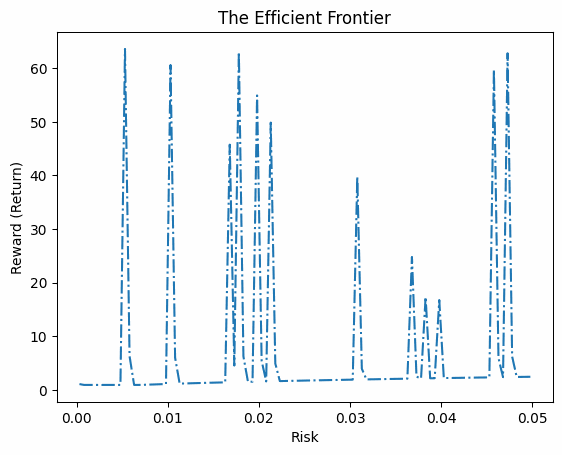

In [196]:
# Generate proportion of the portfolio for each risk limit
param_analysis2 = pd.DataFrame.from_dict(param_analysis2, orient='index')
param_analysis2.columns =  [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']]
param_analysis2.index.name = 'Risk Limit'
param_analysis2.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns2.keys())
print(f"Risk", risk)
reward = list(returns2.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()


The **Efficient Frontier for Model 2** is much more refined, showing a tighter range of risk values, indicating a lower overall risk threshold compared to Model 1. The dramatic spikes in return suggest specific asset combinations that maximize returns under strict risk constraints.

The **Optimal Stock Allocation for Different Risk Levels** graph follows a similar pattern to Model 1, with noticeable spikes in certain assets such as RBLX and NVDA at specific points. However, the overall allocation remains more constrained, suggesting a more controlled optimization process.

**Implications**:
- Model 2 focuses on lower risk levels, making it more suitable for conservative investors.
- The efficiency of the model suggests that the allocation process has been refined to better balance risk and reward.
- The remaining volatility in stock allocations indicates that some stocks remain highly sensitive to small risk variations, requiring further smoothing techniques or additional constraints for a more stable portfolio recommendation.

---

 **Comparison and Final Insights**
Model 1 explores a broader risk range, leading to high variability in optimal allocations, while Model 2 narrows risk levels, producing a more controlled investment strategy. Model 2 is more suitable for risk-averse investors, whereas Model 1 provides options for those willing to take higher risks for potentially higher returns. Future refinements should focus on reducing allocation spikes and ensuring a smoother transition between risk levels to create a more practical portfolio optimization approach.



## MODEL 3 - 10%

In [197]:
# Model 3

# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 0.10) # Given if there is 80% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.10
risk_limits = np.arange(0.0003, max_risk, 0.001)

# Model via param_analysis
param_analysis3 = {}
returns3 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis3[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.RBLX(), m.V(), m.CRM(), m.DIS()]
  returns3[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.39057040214538574
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

<ipython-input-197-70b643bbbf62>:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns3[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.8778765201568604
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.21373724937438965
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.09574222564697266
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.4173698425292969
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

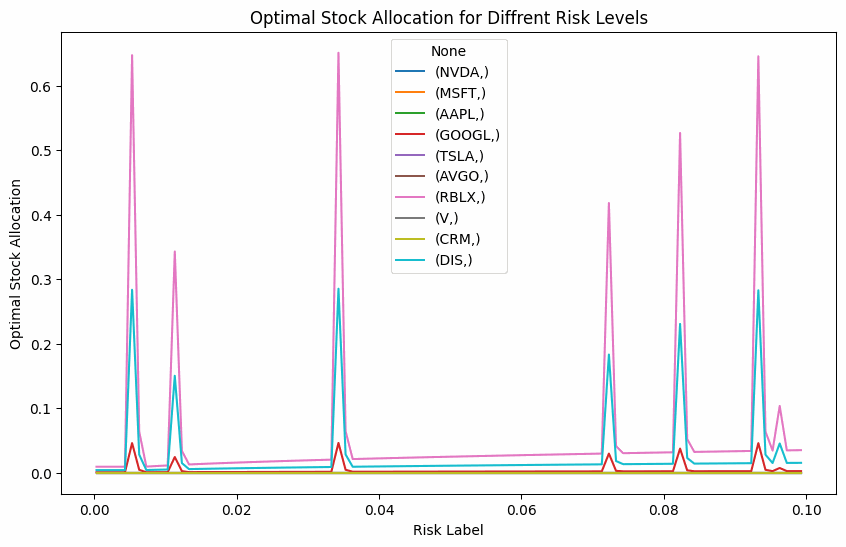

Risk [0.0003, 0.0013, 0.0023, 0.0033, 0.0043, 0.0053, 0.0063, 0.0073, 0.0083, 0.009300000000000001, 0.0103, 0.0113, 0.0123, 0.013300000000000001, 0.0143, 0.0153, 0.016300000000000002, 0.017300000000000003, 0.018300000000000004, 0.0193, 0.020300000000000002, 0.021300000000000003, 0.0223, 0.0233, 0.024300000000000002, 0.025300000000000003, 0.026300000000000004, 0.0273, 0.028300000000000002, 0.029300000000000003, 0.0303, 0.0313, 0.0323, 0.0333, 0.034300000000000004, 0.035300000000000005, 0.036300000000000006, 0.0373, 0.0383, 0.0393, 0.0403, 0.0413, 0.042300000000000004, 0.043300000000000005, 0.0443, 0.0453, 0.0463, 0.0473, 0.0483, 0.049300000000000004, 0.050300000000000004, 0.051300000000000005, 0.052300000000000006, 0.0533, 0.0543, 0.0553, 0.0563, 0.057300000000000004, 0.058300000000000005, 0.059300000000000005, 0.0603, 0.0613, 0.0623, 0.0633, 0.0643, 0.0653, 0.0663, 0.0673, 0.0683, 0.0693, 0.0703, 0.0713, 0.0723, 0.07329999999999999, 0.07429999999999999, 0.07529999999999999, 0.076299999

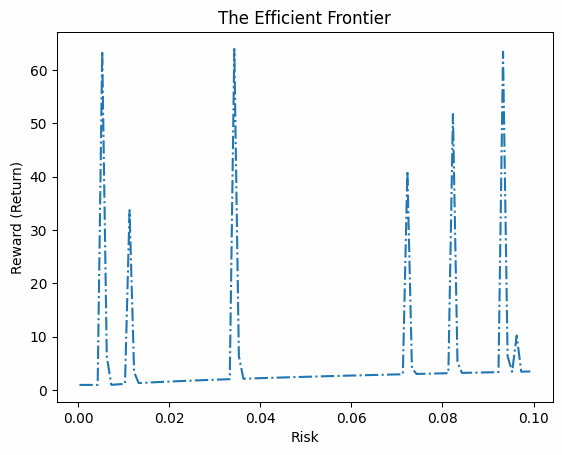

In [198]:
# Generate proportion of the portfolio for each risk limit
param_analysis3 = pd.DataFrame.from_dict(param_analysis3, orient='index')
param_analysis3.columns =  [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']]
param_analysis3.index.name = 'Risk Limit'
param_analysis3.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns3.keys())
print(f"Risk", risk)
reward = list(returns3.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

Model 3 Analysis:

The first graph represents the **optimal stock allocation for different risk levels**. The fluctuating spikes in stock allocation suggest that certain stocks, particularly RBLX, NVDA, and some others, experience sudden shifts in allocation depending on the risk level. This volatility may indicate that these stocks are highly sensitive to market risk and return expectations.

The second graph, the **efficient frontier**, shows the trade-off between risk and return. The presence of sharp peaks suggests that at specific risk levels, some portfolios offer disproportionately high returns. However, these extreme spikes may indicate instability in the model or highly concentrated allocations at those points.

**Implications:**
- The model suggests that **higher risk levels allow for higher return possibilities**, but the presence of erratic peaks indicates that the optimal portfolio allocation may not be smooth, potentially leading to high volatility.
- **Stocks such as RBLX and NVDA appear to have a significant influence on portfolio allocations**, meaning they may offer strong return potential but also introduce substantial risk.
- The **sharp peaks in the efficient frontier suggest certain allocation combinations result in extreme risk-reward payoffs**, which may not always be practical for real-world investment strategies.
- Investors using this model should be cautious of **highly unstable allocations**, as the allocation shifts dramatically depending on the risk level. It would be beneficial to **add stability constraints** to the optimization model for more realistic portfolio construction.



## MODEL 4 - 15%

In [199]:
# Model 4

# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 0.15) # Given if there is 15% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.15
risk_limits = np.arange(0.0003, max_risk, 0.0015)


# Model via param_analysis
param_analysis4 = {}
returns4 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis4[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.RBLX(), m.V(), m.CRM(), m.DIS()]
  returns4[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.11483955383300781
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

<ipython-input-199-0733856101b9>:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns4[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.31461405754089355
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.7230923175811768
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.3094930648803711
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.2218468189239502
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

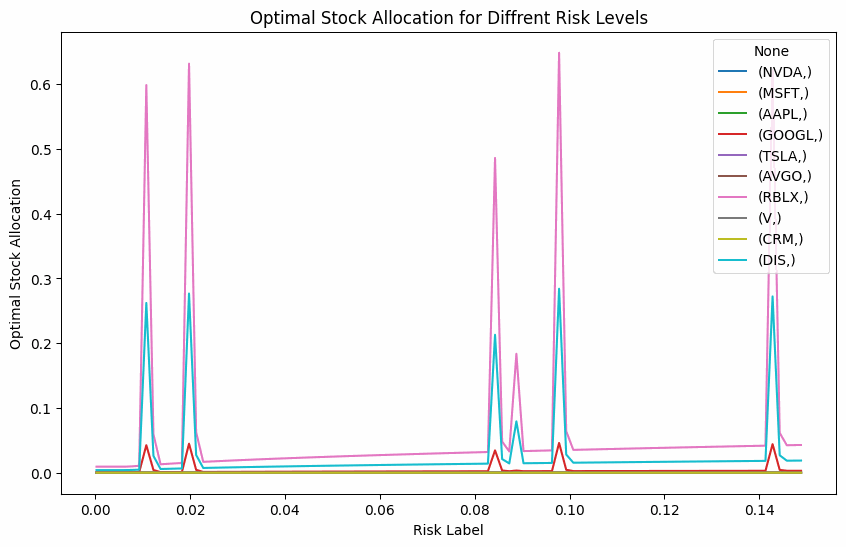

Risk [0.0003, 0.0018, 0.0033, 0.0048000000000000004, 0.0063, 0.0078, 0.009300000000000001, 0.0108, 0.0123, 0.0138, 0.0153, 0.016800000000000002, 0.018300000000000004, 0.0198, 0.021300000000000003, 0.0228, 0.024300000000000002, 0.025800000000000003, 0.0273, 0.028800000000000003, 0.0303, 0.0318, 0.0333, 0.034800000000000005, 0.036300000000000006, 0.0378, 0.0393, 0.0408, 0.042300000000000004, 0.043800000000000006, 0.0453, 0.0468, 0.0483, 0.049800000000000004, 0.051300000000000005, 0.0528, 0.0543, 0.0558, 0.057300000000000004, 0.058800000000000005, 0.0603, 0.0618, 0.0633, 0.0648, 0.0663, 0.0678, 0.0693, 0.0708, 0.0723, 0.07379999999999999, 0.07529999999999999, 0.0768, 0.0783, 0.0798, 0.0813, 0.0828, 0.0843, 0.0858, 0.0873, 0.08879999999999999, 0.09029999999999999, 0.09179999999999999, 0.0933, 0.0948, 0.0963, 0.0978, 0.0993, 0.1008, 0.1023, 0.1038, 0.10529999999999999, 0.10679999999999999, 0.1083, 0.1098, 0.1113, 0.1128, 0.1143, 0.1158, 0.1173, 0.1188, 0.12029999999999999, 0.121799999999999

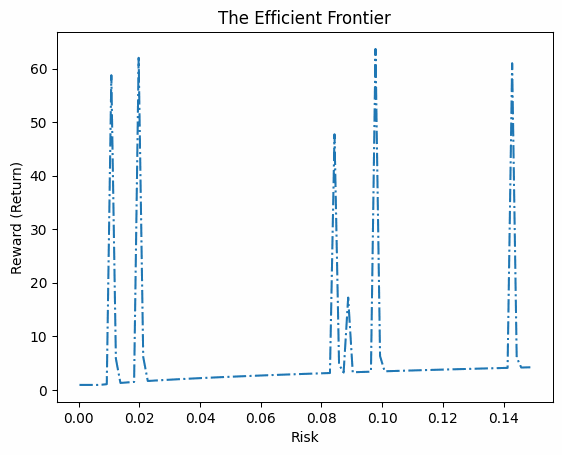

In [200]:
# Generate proportion of the portfolio for each risk limit
param_analysis4 = pd.DataFrame.from_dict(param_analysis4, orient='index')
param_analysis4.columns =  [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']]
param_analysis4.index.name = 'Risk Limit'
param_analysis4.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns4.keys())
print(f"Risk", risk)
reward = list(returns4.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

 **Analysis of Model 4**

Model 4 examines the relationship between risk and optimal stock allocation, focusing on maximizing returns while managing risk. The **Optimal Stock Allocation for Different Risk Levels** graph presents how different stocks are allocated across varying levels of risk. The **Efficient Frontier** graph depicts the trade-off between risk and expected returns.

From the **Optimal Stock Allocation** graph, we see that stock allocation remains relatively stable at low-risk levels but experiences sharp fluctuations at higher risk levels. The stock **RBLX** (Roblox) appears to have the highest allocation peaks, indicating that it is heavily weighted in the portfolio at specific risk thresholds. **NVDA and DIS** also exhibit similar behavior, suggesting they contribute significantly to portfolio optimization at different risk levels. The allocation spikes suggest that at certain risk levels, specific stocks become dominant in the portfolio due to their return potential.

The **Efficient Frontier** graph indicates that at lower risk levels, the expected return remains modest, but as risk increases, the returns rise sharply, demonstrating the typical risk-return trade-off. The sudden peaks suggest that at certain points, specific portfolio compositions yield disproportionately high returns, but this comes with volatility.

**Implications**:
1. **High Sensitivity to Risk** – The fluctuations in optimal allocations indicate that stock weighting is highly sensitive to risk preferences. Investors must carefully balance their tolerance for risk when constructing portfolios.
2. **RBLX as a High-Risk, High-Return Option** – The high peaks in RBLX allocation suggest that it plays a critical role in optimizing returns at certain risk levels. However, this could indicate potential instability in its price movements.
3. **Diversification at Lower Risks** – At lower risk levels, stock allocations appear more evenly distributed, suggesting diversification is key to minimizing risk while achieving steady returns.
4. **Efficient Frontier Spikes** – The sharp increases in the return profile suggest that some stocks have the potential for extreme gains, but investors should consider the associated volatility.
5. **Strategic Portfolio Adjustments** – Investors seeking stable growth may prefer lower risk allocations, while aggressive investors aiming for high returns might need to prepare for substantial swings in portfolio composition.

Model 4 reinforces the importance of understanding risk tolerance when constructing a stock portfolio. The optimal allocation varies significantly across risk levels, emphasizing the need for strategic decision-making in portfolio management.



## MODEL 5 - 25%

In [201]:
# Model 5
# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 0.25) # Given if there is 25% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.25
risk_limits = np.arange(0.0003, max_risk, 0.0025)

# Model via param_analysis
param_analysis5 = {}
returns5 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis5[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.RBLX(), m.V(), m.CRM(), m.DIS()]
  returns5[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.1431427001953125
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

<ipython-input-201-38c3e152e635>:22: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns5[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.1804189682006836
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 1.4834117889404297
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.9965903759002686
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.08235597610473633
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

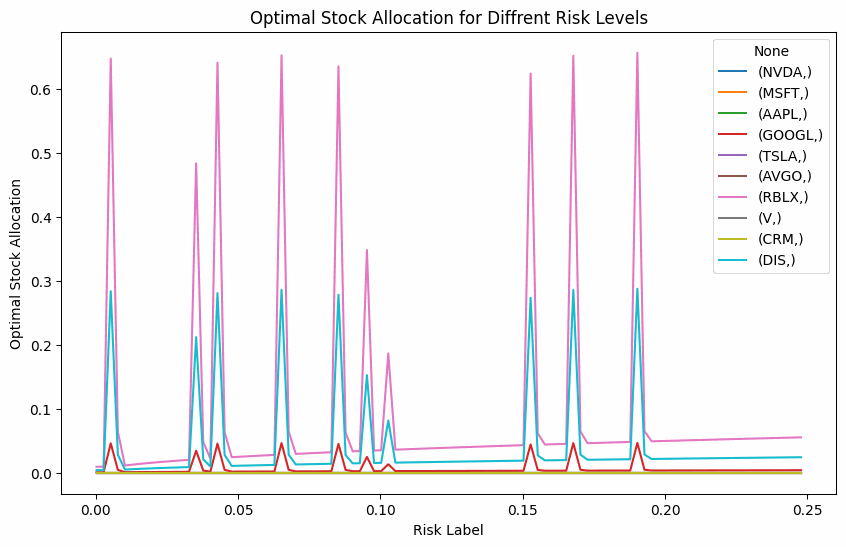

Risk [0.0003, 0.0028, 0.0053, 0.0078, 0.0103, 0.0128, 0.0153, 0.017800000000000003, 0.020300000000000002, 0.0228, 0.025300000000000003, 0.027800000000000002, 0.0303, 0.0328, 0.035300000000000005, 0.0378, 0.0403, 0.042800000000000005, 0.0453, 0.0478, 0.050300000000000004, 0.0528, 0.0553, 0.057800000000000004, 0.0603, 0.0628, 0.0653, 0.0678, 0.0703, 0.07279999999999999, 0.07529999999999999, 0.0778, 0.0803, 0.0828, 0.0853, 0.0878, 0.09029999999999999, 0.0928, 0.0953, 0.0978, 0.1003, 0.1028, 0.10529999999999999, 0.10779999999999999, 0.1103, 0.1128, 0.1153, 0.1178, 0.12029999999999999, 0.12279999999999999, 0.1253, 0.1278, 0.1303, 0.1328, 0.1353, 0.1378, 0.1403, 0.1428, 0.14529999999999998, 0.1478, 0.1503, 0.1528, 0.1553, 0.1578, 0.1603, 0.1628, 0.1653, 0.1678, 0.1703, 0.1728, 0.1753, 0.17779999999999999, 0.1803, 0.1828, 0.1853, 0.1878, 0.1903, 0.1928, 0.1953, 0.1978, 0.2003, 0.2028, 0.2053, 0.2078, 0.2103, 0.2128, 0.2153, 0.2178, 0.2203, 0.2228, 0.2253, 0.2278, 0.2303, 0.2328, 0.2353, 0.237

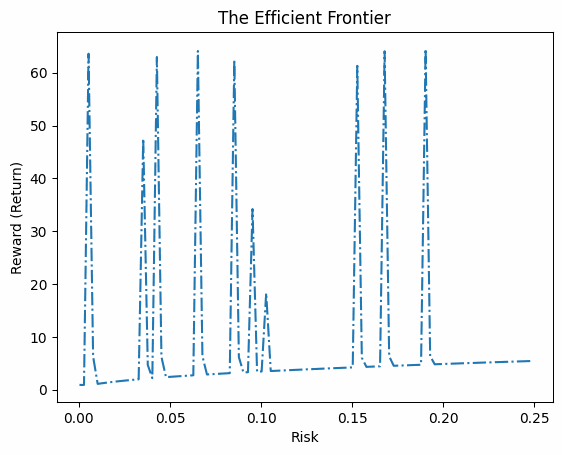

In [202]:
# Generate proportion of the portfolio for each risk limit
param_analysis5 = pd.DataFrame.from_dict(param_analysis5, orient='index')
param_analysis5.columns =  [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']]
param_analysis5.index.name = 'Risk Limit'
param_analysis5.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns5.keys())
print(f"Risk", risk)
reward = list(returns5.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

 **Analysis of Model 5**

Model 5 analyzes the optimal stock allocation for different risk levels while assessing the efficient frontier.

The **Optimal Stock Allocation** graph shows how the proportions of various stocks change as risk levels increase. The spikes in allocation for certain stocks, such as RBLX and NVDA, suggest that they are more frequently selected as risk tolerance increases. However, the model displays extreme fluctuations, indicating that allocation shifts rapidly rather than gradually. This suggests that a small change in risk tolerance results in significant changes in stock allocation, which may point to model instability or a high sensitivity to input data.

The **Efficient Frontier** graph presents the trade-off between risk and return. Similar to previous models, there are sharp peaks at certain points, implying that specific levels of risk correspond to disproportionately high returns. This behavior suggests that the model identifies particular asset combinations that maximize returns but with sharp fluctuations. The overall shape of the frontier indicates that even at low risk levels, returns remain relatively low but increase dramatically at specific points.

**Implications:**
- The extreme variations in stock allocation suggest that certain stocks dominate at specific risk levels, leading to a non-smooth allocation strategy. This could make practical portfolio management challenging.
- The efficient frontier's sharp spikes indicate that high returns are available but require precise risk calibration, which could make implementation difficult.
- Adjusting constraints or smoothing the risk-return relationship may help create a more stable and investable portfolio allocation strategy.

This model provides insight into optimal stock distributions, but its volatility suggests potential refinements in risk diversification and allocation consistency.



## MODEL 6 - 50%

In [203]:
# Model 6
# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 0.5) # Given if there is 50% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.5
risk_limits = np.arange(0.0003, max_risk, 0.005)

# Model via param_analysis
param_analysis6 = {}
returns6 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis6[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.RBLX(), m.V(), m.CRM(), m.DIS()]
  returns6[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.19374537467956543
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

<ipython-input-203-44af75dae082>:22: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns6[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))
  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 1.6392371654510498
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.10776400566101074
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.5631539821624756
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.7722682952880859
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

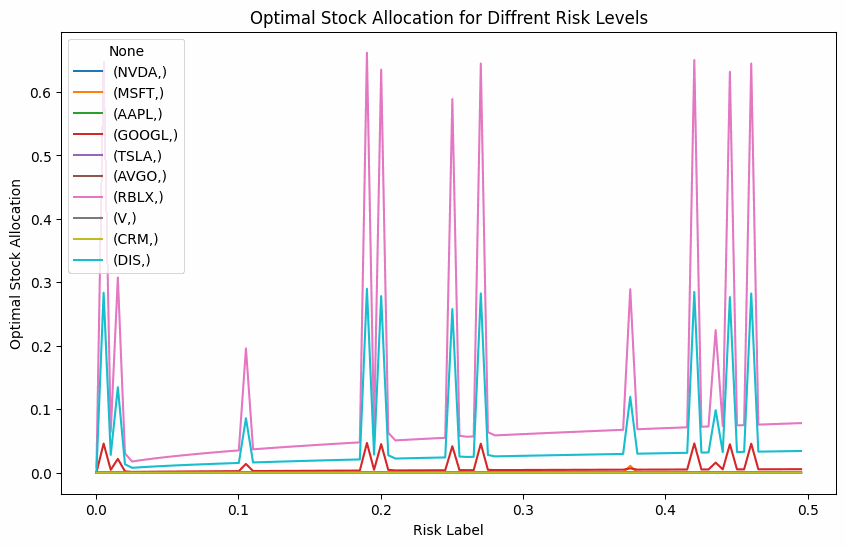

Risk [0.0003, 0.0053, 0.0103, 0.0153, 0.020300000000000002, 0.025300000000000003, 0.0303, 0.035300000000000005, 0.0403, 0.0453, 0.050300000000000004, 0.0553, 0.0603, 0.0653, 0.0703, 0.07529999999999999, 0.0803, 0.0853, 0.09029999999999999, 0.0953, 0.1003, 0.10529999999999999, 0.1103, 0.1153, 0.12029999999999999, 0.1253, 0.1303, 0.1353, 0.1403, 0.14529999999999998, 0.1503, 0.1553, 0.1603, 0.1653, 0.1703, 0.1753, 0.1803, 0.1853, 0.1903, 0.1953, 0.2003, 0.2053, 0.2103, 0.2153, 0.2203, 0.2253, 0.2303, 0.2353, 0.24029999999999999, 0.2453, 0.2503, 0.2553, 0.26030000000000003, 0.26530000000000004, 0.27030000000000004, 0.27530000000000004, 0.28030000000000005, 0.28530000000000005, 0.2903, 0.2953, 0.3003, 0.3053, 0.3103, 0.3153, 0.32030000000000003, 0.32530000000000003, 0.33030000000000004, 0.33530000000000004, 0.34030000000000005, 0.34530000000000005, 0.35030000000000006, 0.3553, 0.3603, 0.3653, 0.3703, 0.3753, 0.3803, 0.38530000000000003, 0.39030000000000004, 0.39530000000000004, 0.4003000000

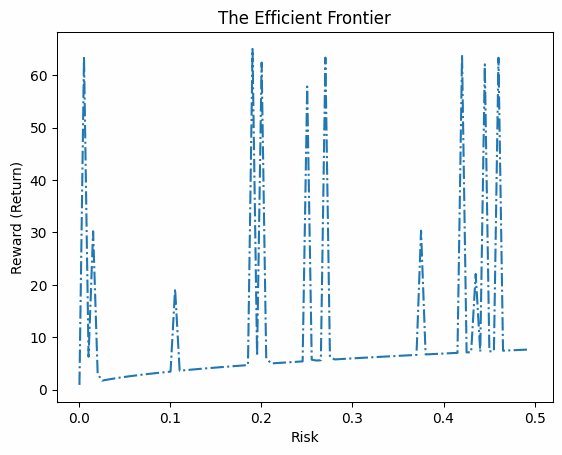

In [204]:
# Generate proportion of the portfolio for each risk limit
param_analysis6 = pd.DataFrame.from_dict(param_analysis6, orient='index')
param_analysis6.columns =  [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']]
param_analysis6.index.name = 'Risk Limit'
param_analysis6.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns6.keys())
print(f"Risk", risk)
reward = list(returns6.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

 **Analysis of Model 6**

The efficient frontier plot demonstrates the relationship between risk and expected return. It suggests that as risk increases, there are opportunities for higher returns, but these returns also exhibit significant volatility. The presence of multiple sharp spikes indicates that certain portfolios experience substantial increases in returns at specific risk levels, which could be driven by highly volatile stocks such as TSLA or RBLX.

The optimal stock allocation plot shows how different stocks are weighted across varying risk levels. The spikes in allocation, particularly for RBLX and NVDA, suggest that these stocks dominate the portfolio at certain risk levels. This might indicate that they provide the highest returns but also introduce considerable volatility. The more stable stocks, such as MSFT and AAPL, appear to have lower but more consistent allocations, making them favorable for lower-risk portfolios.

The model suggests that investors seeking low-risk portfolios should allocate more to stable stocks like MSFT, AAPL, and CRM. However, for higher-risk tolerance, the model recommends increasing exposure to stocks like TSLA and RBLX, which have higher return potential but with significant fluctuations. The results reinforce the importance of balancing risk and return based on individual investment preferences.



## MODEL 7 - 75%

In [205]:
# Model 7
# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 0.75) # Given if there is 75% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.75
risk_limits = np.arange(0.0003, max_risk, 0.0075)

# Model via param_analysis
param_analysis7 = {}
returns7 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis7[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.RBLX(), m.V(), m.CRM(), m.DIS()]
  returns7[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.3449065685272217
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

<ipython-input-205-07de1bca6f8c>:22: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns7[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.11945223808288574
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.06281805038452148
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.2759547233581543
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.17838120460510254
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

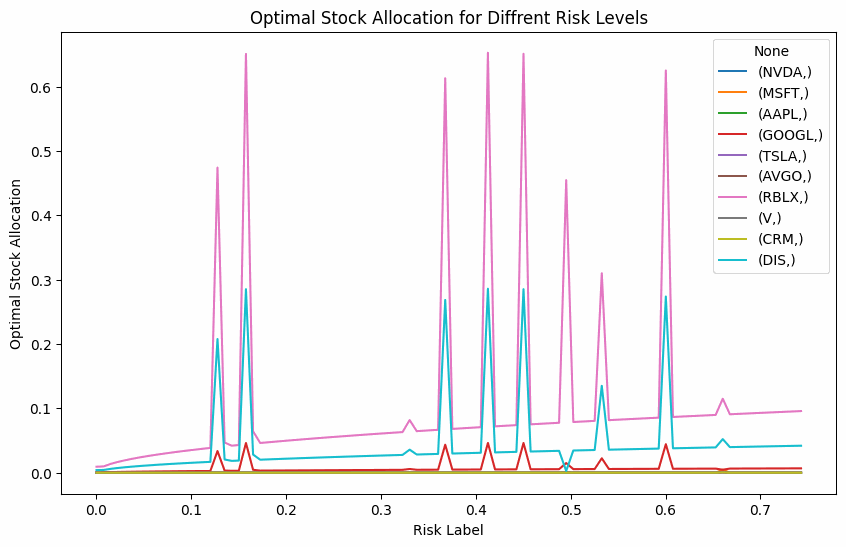

Risk [0.0003, 0.0078, 0.0153, 0.0228, 0.0303, 0.0378, 0.0453, 0.0528, 0.0603, 0.0678, 0.07529999999999999, 0.08279999999999998, 0.09029999999999999, 0.0978, 0.10529999999999999, 0.11279999999999998, 0.12029999999999999, 0.1278, 0.1353, 0.14279999999999998, 0.1503, 0.1578, 0.16529999999999997, 0.17279999999999998, 0.1803, 0.1878, 0.1953, 0.20279999999999998, 0.2103, 0.2178, 0.22529999999999997, 0.23279999999999998, 0.24029999999999999, 0.2478, 0.2553, 0.26280000000000003, 0.27030000000000004, 0.2778, 0.2853, 0.2928, 0.3003, 0.3078, 0.3153, 0.32280000000000003, 0.3303, 0.3378, 0.3453, 0.3528, 0.3603, 0.3678, 0.3753, 0.38280000000000003, 0.39030000000000004, 0.3978, 0.4053, 0.4128, 0.4203, 0.4278, 0.4353, 0.4428, 0.4503, 0.4578, 0.4653, 0.4728, 0.4803, 0.4878, 0.4953, 0.5027999999999999, 0.5103, 0.5177999999999999, 0.5253, 0.5327999999999999, 0.5403, 0.5478, 0.5552999999999999, 0.5628, 0.5702999999999999, 0.5778, 0.5852999999999999, 0.5928, 0.6003, 0.6077999999999999, 0.6153, 0.6227999999

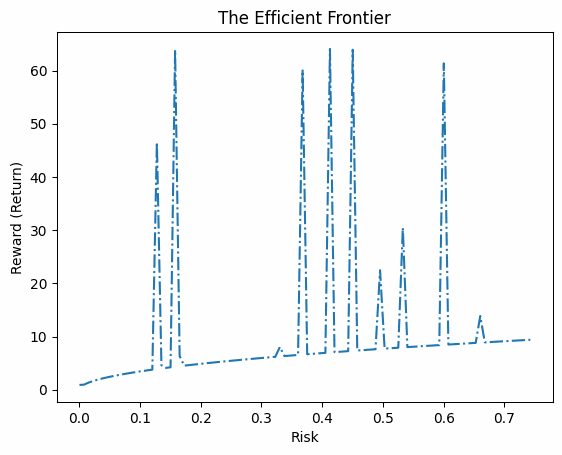

In [206]:
# Generate proportion of the portfolio for each risk limit
param_analysis7 = pd.DataFrame.from_dict(param_analysis7, orient='index')
param_analysis7.columns =  [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']]
param_analysis7.index.name = 'Risk Limit'
param_analysis7.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns7.keys())
print(f"Risk", risk)
reward = list(returns7.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

 **Analysis of Model 7**

The **Optimal Stock Allocation for Different Risk Levels** graph shows the distribution of investments across different stocks as risk tolerance increases. The spikes in allocation, particularly for **RBLX and NVDA**, indicate that these stocks tend to dominate the portfolio at certain risk levels, suggesting higher expected returns relative to other stocks. However, the frequent shifts in allocation suggest a **high level of sensitivity to small changes in risk preferences**, which could make the portfolio unstable.

The **Efficient Frontier** graph illustrates the trade-off between risk and return. The sharp peaks indicate specific risk levels where returns spike significantly, implying that the model identifies **certain optimal risk levels** where the portfolio performs exceptionally well. However, beyond a certain threshold, returns plateau, meaning additional risk does not necessarily yield proportionate gains.

 **Implications**
- **High Volatility in Allocation:** The spikes in allocation suggest that a small increase in risk preference may drastically change the portfolio composition. Investors should be aware that **portfolio stability might be an issue** if allocation shifts aggressively.
- **Concentration in Few Stocks:** Certain stocks like **RBLX and NVDA** appear to dominate at different risk levels, which could expose the portfolio to **concentration risk**.
- **Non-Smooth Efficient Frontier:** The jagged nature of the efficient frontier suggests that **return optimization is highly dependent on specific risk levels**, meaning investors should carefully select their risk tolerance to maximize returns effectively.

This model provides a **highly optimized portfolio**, but the extreme variability in stock allocation could make it less practical for long-term, stable investing. A **smoother allocation strategy** may be preferable for investors looking for consistency.




## MODEL 8 - 90%

In [207]:
# Model 8
# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.RBLX + m.V + m.CRM +
                          m.DIS <= 0.8) # Given if there is 8% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.RBLX + m.V + m.CRM + m.DIS == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 0.8
risk_limits = np.arange(0.0003, max_risk, 0.008)

# Model via param_analysis
param_analysis8 = {}
returns8 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis8[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.RBLX(), m.V(), m.CRM(), m.DIS()]
  returns8[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.1672229766845703
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

<ipython-input-207-362419d40756>:22: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns8[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.RBLX) + (df_return[7] * m.V) + (df_return[8] * m.CRM) + (df_return[9] * m.DIS))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.06182360649108887
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.08944463729858398
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (190 outputs left out)

  - termination condition: maxIterations
  - message from solver: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Maximum Number of Iterations Exceeded.
  Termination condition: maxIterations
  Id: 400
  Error rc: 0
  Time: 1.6718857288360596
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of s

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.1251065731048584
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

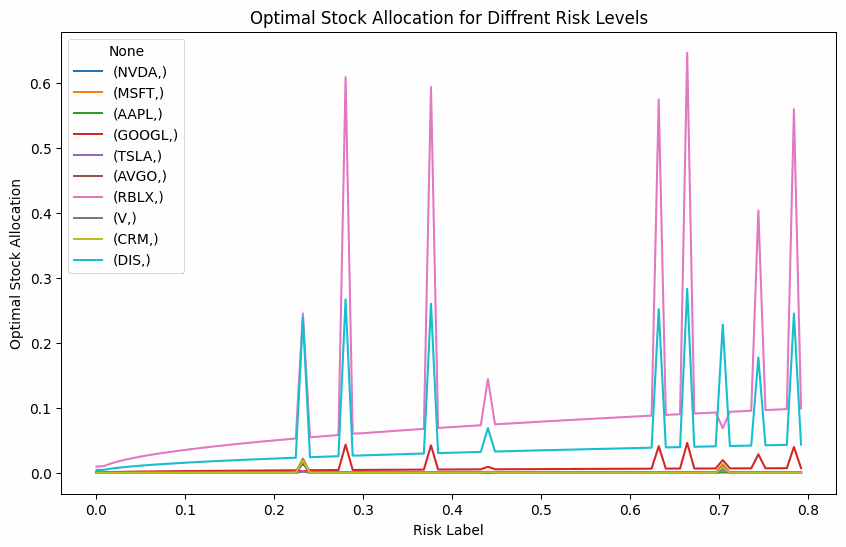

Risk [0.0003, 0.0083, 0.016300000000000002, 0.024300000000000002, 0.0323, 0.0403, 0.0483, 0.0563, 0.0643, 0.0723, 0.0803, 0.08829999999999999, 0.0963, 0.1043, 0.1123, 0.12029999999999999, 0.1283, 0.1363, 0.1443, 0.1523, 0.1603, 0.1683, 0.17629999999999998, 0.1843, 0.1923, 0.2003, 0.2083, 0.2163, 0.2243, 0.2323, 0.24029999999999999, 0.2483, 0.25630000000000003, 0.26430000000000003, 0.27230000000000004, 0.28030000000000005, 0.28830000000000006, 0.2963, 0.3043, 0.3123, 0.32030000000000003, 0.32830000000000004, 0.33630000000000004, 0.34430000000000005, 0.3523, 0.3603, 0.3683, 0.3763, 0.38430000000000003, 0.39230000000000004, 0.40030000000000004, 0.40830000000000005, 0.41630000000000006, 0.4243, 0.4323, 0.4403, 0.44830000000000003, 0.45630000000000004, 0.46430000000000005, 0.47230000000000005, 0.4803, 0.4883, 0.4963, 0.5043, 0.5123, 0.5203, 0.5283, 0.5363, 0.5443, 0.5523, 0.5603, 0.5683, 0.5763, 0.5842999999999999, 0.5922999999999999, 0.6003, 0.6083, 0.6163, 0.6243, 0.6323, 0.6403, 0.6483, 

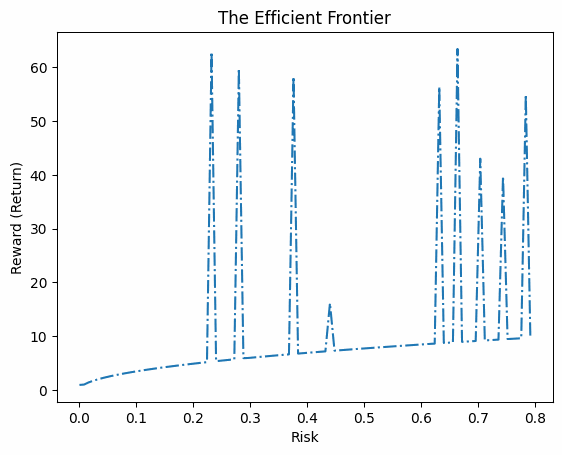

In [208]:
# Generate proportion of the portfolio for each risk limit
param_analysis8 = pd.DataFrame.from_dict(param_analysis8, orient='index')
param_analysis8.columns =  [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'RBLX', 'V', 'CRM', 'DIS']]
param_analysis8.index.name = 'Risk Limit'
param_analysis8.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.show()

# Find and print risk and reward
risk = list(returns8.keys())
print(f"Risk", risk)
reward = list(returns8.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

 Analysis of Model 8

 **Optimal Stock Allocation for Different Risk Levels**
The stock allocation graph for different risk levels indicates that as risk increases, the proportion of allocation shifts between various stocks. The spikes in allocation suggest that certain stocks become more dominant at specific risk levels. The most volatile allocations belong to RBLX and NVDA, which experience sharp peaks at various risk levels. These stocks likely have high return potential but also exhibit significant fluctuations. The rest of the stocks, such as MSFT, AAPL, and GOOGL, maintain relatively stable allocations, suggesting they provide more consistent returns across risk levels.

 **Efficient Frontier**
The efficient frontier plot demonstrates the relationship between risk and return. The spikes in the curve suggest points where higher returns can be achieved but at increasing risk levels. The initial portion of the graph shows a gradual increase in return with minimal risk, while the latter part demonstrates higher volatility with large jumps in return for small increases in risk. This implies that higher-risk portfolios are available for investors seeking aggressive growth, but with substantial volatility.

 **Implications**
This model highlights a highly dynamic allocation strategy where some stocks dominate at certain risk levels. Investors with low-risk tolerance should focus on stable stocks with less variation in allocation, such as MSFT and AAPL. Those seeking high returns must accept large shifts in asset allocation, especially in stocks like RBLX and NVDA. The sharp spikes in the efficient frontier indicate potential optimal points where returns maximize for given risk levels, which could help in constructing an optimized investment strategy.




## MODEL 9 - 100% (WITHOUT RBLX and DIS)

In [214]:
# Model 9
# Constraints
m.total_risk = Constraint(expr = m.NVDA + m.MSFT +
                          m.AAPL + m.GOOGL + m.TSLA +
                          m.AVGO + m.V + m.CRM <= 1) # Given if there is 100% risk
m.sum_portfolio = Constraint(expr = m.NVDA + m.MSFT +m.AAPL + m.GOOGL + m.TSLA + m.AVGO + m.V + m.CRM == 1)
m.return_floor = Constraint(expr = m.objective >= 0.01)

# Adjusted Risk
max_risk = 1
risk_limits = np.arange(0.0003, max_risk, 0.01)

# Model via param_analysis
param_analysis9 = {}
returns9 = {}
for r in risk_limits:
  m.del_component(m.total_risk)
  m.total_risk = Constraint(expr = expr_risk <=r)
  result = SolverFactory('ipopt', executable=ipopt_executable).solve(m).write()
  param_analysis9[r] = [m.NVDA(), m.MSFT(), m.AAPL(), m.GOOGL(), m.TSLA(), m.AVGO(), m.V(), m.CRM()]
  returns9[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.V) + (df_return[7] * m.CRM))

This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
This is usually indicative of a modelling error.
To avoid this warning, use block.del_component() and block.add_component().
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.7616860866546631
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

<ipython-input-214-4a1bf980bd88>:21: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  returns9[r] = value((df_return[0] * m.NVDA) + (df_return[1] * m.MSFT) + (df_return[2] * m.AAPL) + (df_return[3] * m.GOOGL) + (df_return[4] * m.TSLA) + (df_return[5] * m.AVGO) + (df_return[6] * m.V) + (df_return[7] * m.CRM))
  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.3293876647949219
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.36991071701049805
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of

... (190 outputs left out)

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.5787575244903564
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of 

  - termination condition: infeasible
  - message from solver: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.


# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -inf
  Upper bound: inf
  Number of objectives: 1
  Number of constraints: 3
  Number of variables: 10
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: warning
  Message: Ipopt 3.12.13\x3a Converged to a locally infeasible point. Problem may be infeasible.
  Termination condition: infeasible
  Id: 200
  Error rc: 0
  Time: 0.471829891204834
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of s



---



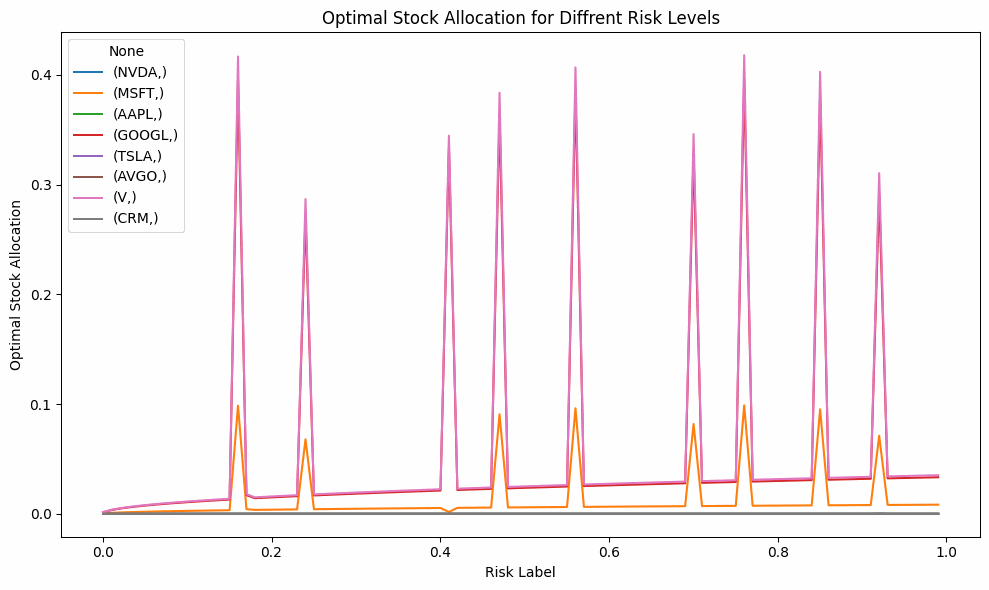

Risk [0.0003, 0.0103, 0.020300000000000002, 0.0303, 0.0403, 0.050300000000000004, 0.0603, 0.0703, 0.0803, 0.09029999999999999, 0.1003, 0.1103, 0.12029999999999999, 0.1303, 0.1403, 0.1503, 0.1603, 0.1703, 0.1803, 0.1903, 0.2003, 0.2103, 0.2203, 0.2303, 0.24029999999999999, 0.2503, 0.26030000000000003, 0.27030000000000004, 0.28030000000000005, 0.2903, 0.3003, 0.3103, 0.32030000000000003, 0.33030000000000004, 0.34030000000000005, 0.35030000000000006, 0.3603, 0.3703, 0.3803, 0.39030000000000004, 0.40030000000000004, 0.41030000000000005, 0.4203, 0.4303, 0.4403, 0.45030000000000003, 0.46030000000000004, 0.47030000000000005, 0.4803, 0.4903, 0.5003, 0.5103, 0.5203, 0.5303, 0.5403, 0.5503, 0.5603, 0.5703, 0.5802999999999999, 0.5902999999999999, 0.6003, 0.6103, 0.6203, 0.6303, 0.6403, 0.6503, 0.6603, 0.6703, 0.6803, 0.6903, 0.7003, 0.7102999999999999, 0.7202999999999999, 0.7303, 0.7403, 0.7503, 0.7603, 0.7703, 0.7803, 0.7903, 0.8003, 0.8103, 0.8203, 0.8303, 0.8402999999999999, 0.8503, 0.8603, 0.

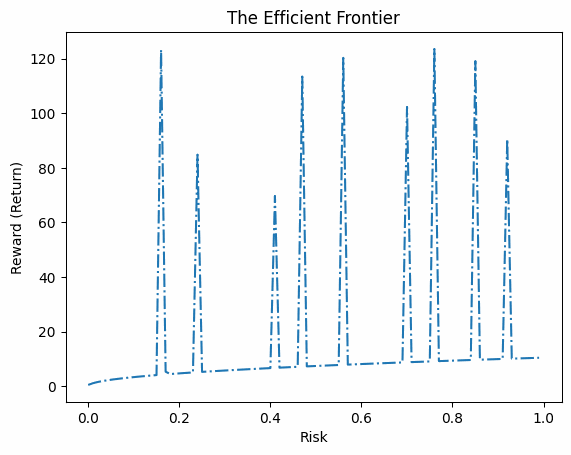

In [215]:
# Generate proportion of the portfolio for each risk limit
param_analysis9 = pd.DataFrame.from_dict(param_analysis9, orient='index')
param_analysis9.columns =  [['NVDA', 'MSFT', 'AAPL', 'GOOGL', 'TSLA', 'AVGO', 'V', 'CRM']]
param_analysis9.index.name = 'Risk Limit'
param_analysis9.plot(figsize=(10, 6))
plt.title('Optimal Stock Allocation for Diffrent Risk Levels')
plt.xlabel('Risk Label')
plt.ylabel('Optimal Stock Allocation')
plt.tight_layout()
plt.show()

# Find and print risk and reward
risk = list(returns9.keys())
print(f"Risk", risk)
reward = list(returns9.values())
print(f"Reward", reward)
print('\t')

# Plot risk and reward
from pylab import *
plot(risk, reward, '-.')
title('The Efficient Frontier')
xlabel('Risk')
ylabel('Reward (Return)')
plt.show()

**Optimal Stock Allocation at Different Risk Levels**  
The portfolio optimization model highlights that **Visa (V)** experiences the highest allocation spikes at specific risk levels, suggesting its role as a high-return yet volatile asset. These fluctuations indicate that Visa is highly sensitive to risk variations, potentially making it a **strategic but unstable** choice for investors.  

On the other hand, **Microsoft (MSFT) maintains a steady allocation**, indicating its **stability and reliability** across different risk levels. This suggests that MSFT serves as a **core holding** for risk-averse investors seeking **consistent returns**. Other stocks, including **Nvidia (NVDA), Tesla (TSLA), and Apple (AAPL)**, show moderate allocations but lack the extreme spikes observed in Visa, implying **a more balanced risk-adjusted return profile**.  

**The Efficient Frontier and Risk-Return Relationship**
The **efficient frontier** illustrates the tradeoff between **risk and expected return**. The graph generally shows an upward trend, meaning that **higher risk levels are associated with greater potential returns**. However, the presence of **sharp spikes at various risk points** suggests that certain assets contribute disproportionately to returns, leading to increased volatility at those points.  

At lower risk levels, **returns increase gradually**, aligning with conservative investment strategies. However, as risk increases, **return fluctuations become extreme**, indicating that higher-risk portfolios **may not always provide proportional return benefits**. These spikes suggest that **specific stocks dominate the allocation at certain risk levels**, leading to unstable return patterns.  

**Business Implications**
- **For Conservative Investors:** Microsoft (MSFT) and CRM (Salesforce) are optimal choices, as they provide stability and low volatility, making them suitable for a **steady, lower-risk** investment approach.  
- **For Moderate Risk-Takers:** A combination of **MSFT, NVDA, and AAPL** can help balance **growth and risk**, capturing upside potential while maintaining **reasonable stability**.  
- **For High-Risk Investors:** Stocks like **Visa (V) and Tesla (TSLA) show sharp allocation shifts**, indicating **high potential returns but with extreme fluctuations**. A **diversified** strategy is recommended to avoid excessive exposure to volatile assets.  

**Key Takeaways**
- **Visa (V) shows extreme allocation spikes**, making it a high-risk, high-reward asset that should be carefully weighted in portfolios.  
- **Microsoft (MSFT) is a stable core asset**, consistently allocated across risk levels, making it a solid choice for conservative and balanced portfolios.  
- **Tesla (TSLA) and Nvidia (NVDA) have moderate allocations**, suggesting they provide growth opportunities but with **manageable risk**.  
- **The risk-return tradeoff is non-linear**, meaning that beyond a certain risk level, additional risk does not always yield proportional returns.  
- **Investors should balance risk and return by diversifying**, particularly at higher risk levels where volatility is more pronounced.  